# Multimodal Fusion for Pig Behavior Recognition Using Accelerometer and Audio Data

This notebook documents the experimental workflow used to evaluate pig behavior classification from two complementary sensing modalities: triaxial accelerometry and audio. The accelerometer stream is processed as window-based time-series data, while the audio stream is converted into log-Mel spectrogram representations suitable for convolutional neural networks.

The workflow includes four main stages. First, the accelerometer and audio datasets are inspected, filtered, harmonized, and converted into the four target behavioral classes used in the final experiments. Second, modality-specific models are trained and evaluated: Random Forest variants are used for accelerometer-derived features, while Log-Mel Audio Attention Networks are used for acoustic classification. Third, reference baselines and alternative training strategies are evaluated, including MLP-based baselines, AD-BL-SMOTE balancing, Lasso-based feature selection, and attention-free audio networks. Finally, several multimodal fusion strategies are compared, including F1-weighted fusion, confidence-weighted fusion, meta-classifiers, and neural fusion baselines.

All Markdown explanations in this notebook are intended to make the computational pipeline reproducible and understandable. The code cells themselves were kept unchanged, including their execution counts and outputs, so that the original experimental evidence remains preserved.


## Accelerometer Dataset Loading, Label Harmonization, and Class Distribution

This cell loads the accelerometer training spreadsheet, standardizes the original behavioral labels, and maps them into the four behavioral classes used in the multimodal experiment. It removes labels outside the target scenario, aggregates lying-related states into a single `Lying` class, and generates publication-oriented class distribution outputs. This step is important because all subsequent accelerometer models depend on a consistent label space.


File loaded successfully! Total rows: 834100

Original classes found:
atividade
comendo       267700
dormindo      239600
deitadoac     157800
andando        78300
bebendo        45800
levantando     20900
deitando       16300
correndo        7700
Name: count, dtype: int64

Classes used in the experiment:
classe_en
Lying       413700
Eating      267700
Walking      78300
Drinking     45800
Name: count, dtype: int64


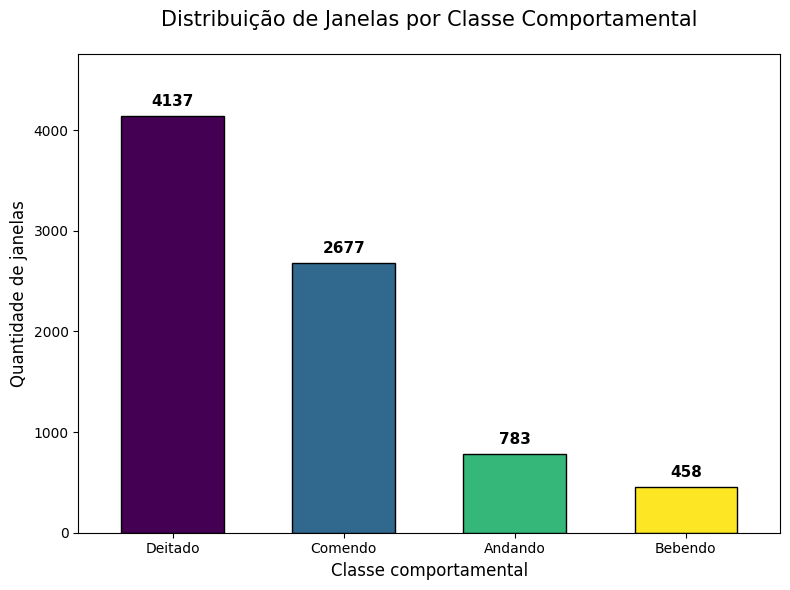

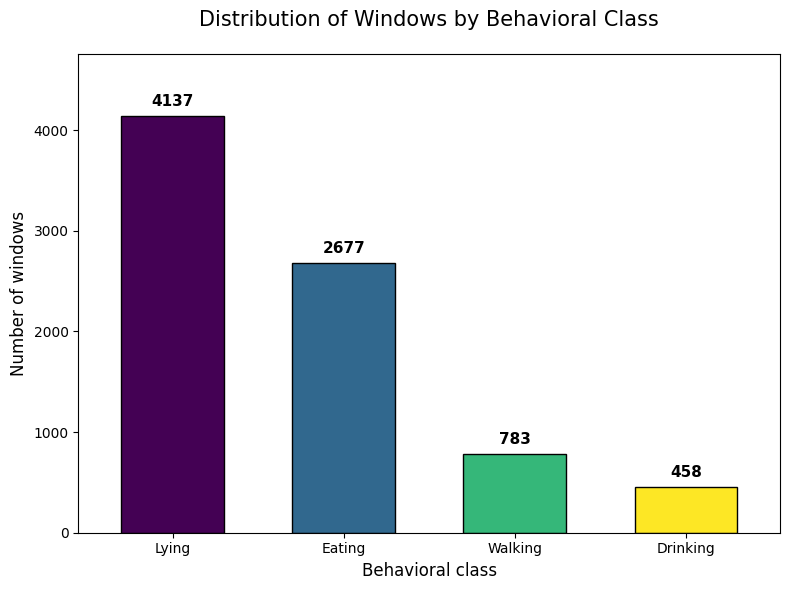


Summary in Portuguese:
classe_pt
Deitado    4137
Comendo    2677
Andando     783
Bebendo     458
Name: window, dtype: int64

Summary in English:
classe_en
Lying       4137
Eating      2677
Walking      783
Drinking     458
Name: window, dtype: int64


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# ============================================================
# 1. File path
# ============================================================
caminho_saida = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

if not os.path.exists(caminho_saida):
    print(f"ERROR: The file does not exist at: {caminho_saida}")

else:
    try:
        df_lido = pd.read_excel(caminho_saida, engine='openpyxl')

        print(f"File loaded successfully! Total rows: {len(df_lido)}")

        # ============================================================
        # 2. Class-name cleaning
        # ============================================================
        df_lido['atividade'] = (
            df_lido['atividade']
            .astype(str)
            .str.strip()
            .str.lower()
        )

        print("\nOriginal classes found:")
        print(df_lido['atividade'].value_counts())

        # ============================================================
        # 3. Mapping of the classes used in the experiment
        # ============================================================
        mapa_classes_en = {
            'comendo': 'Eating',
            'bebendo': 'Drinking',

            # merge sleeping + lying awake + lying down
            'dormindo': 'Lying',
            'deitadoac': 'Lying',
            'deitando': 'Lying',

            # walking
            'andando': 'Walking'
        }

        mapa_classes_pt = {
            'Eating': 'Comendo',
            'Drinking': 'Bebendo',
            'Lying': 'Deitado',
            'Walking': 'Andando'
        }

        df_lido['classe_en'] = df_lido['atividade'].map(mapa_classes_en)

        # Remove classes that will not be used
        df_filtrado = df_lido.dropna(subset=['classe_en']).copy()

        # Create a Portuguese-label column for local visualization only
        df_filtrado['classe_pt'] = df_filtrado['classe_en'].map(mapa_classes_pt)

        print("\nClasses used in the experiment:")
        print(df_filtrado['classe_en'].value_counts())

        # ============================================================
        # 4. Window count
        # ============================================================
        if 'window' in df_filtrado.columns:
            contagem_en = df_filtrado.groupby('classe_en')['window'].nunique()
            contagem_pt = df_filtrado.groupby('classe_pt')['window'].nunique()
        else:
            contagem_en = df_filtrado.groupby('classe_en').size() / 100
            contagem_pt = df_filtrado.groupby('classe_pt').size() / 100

        # Descending order
        contagem_en = contagem_en.sort_values(ascending=False).astype(int)
        contagem_pt = contagem_pt.sort_values(ascending=False).astype(int)

        # ============================================================
        # 5. Plotting function
        # ============================================================
        def plotar_distribuicao(contagem, titulo, xlabel, ylabel):
            plt.figure(figsize=(8, 6))

            cores = plt.cm.viridis(np.linspace(0, 1, len(contagem)))

            ax = contagem.plot(
                kind='bar',
                color=cores,
                edgecolor='black',
                width=0.6
            )

            for p in ax.patches:
                valor = int(p.get_height())
                ax.annotate(
                    f'{valor}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center',
                    va='bottom',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontsize=11,
                    fontweight='bold'
                )

            plt.title(titulo, fontsize=15, pad=20)
            plt.xlabel(xlabel, fontsize=12)
            plt.ylabel(ylabel, fontsize=12)
            plt.xticks(rotation=0)

            if contagem.max() > 0:
                plt.ylim(0, contagem.max() * 1.15)

            plt.tight_layout()
            plt.show()

        # ============================================================
        # 6. Plot with Portuguese labels
        # ============================================================
        plotar_distribuicao(
            contagem_pt,
            titulo='Window Distribution by Behavioral Class',
            xlabel='Classe comportamental',
            ylabel='Quantidade de windows'
        )

        # ============================================================
        # 7. Plot with English labels
        # ============================================================
        plotar_distribuicao(
            contagem_en,
            titulo='Distribution of Windows by Behavioral Class',
            xlabel='Behavioral class',
            ylabel='Number of windows'
        )

        # ============================================================
        # 8. Resumos
        # ============================================================
        print("\nSummary in Portuguese:")
        print(contagem_pt)

        print("\nSummary in English:")
        print(contagem_en)

    except Exception as e:
        print(f"\n--- ERRO AO LER O EXCEL ---")
        print(f"Detalhe do erro: {e}")

## Vector Magnitude Distribution Across Behavioral Classes

This cell computes the vector magnitude from the three accelerometer axes and visualizes its distribution for each final behavioral class. Vector magnitude is useful because it summarizes overall body movement intensity independently of the sign of each axis. The KDE plots help assess whether movement amplitude alone carries discriminative information for behaviors such as walking, eating, drinking, and lying.


Number of rows per final class:
behavioral_class
Lying       397400
Eating      267700
Walking      78300
Drinking     45800
Name: count, dtype: int64

Number of windows per final class:
behavioral_class
Lying       3974
Eating      2677
Walking      783
Drinking     458
Name: window, dtype: int64


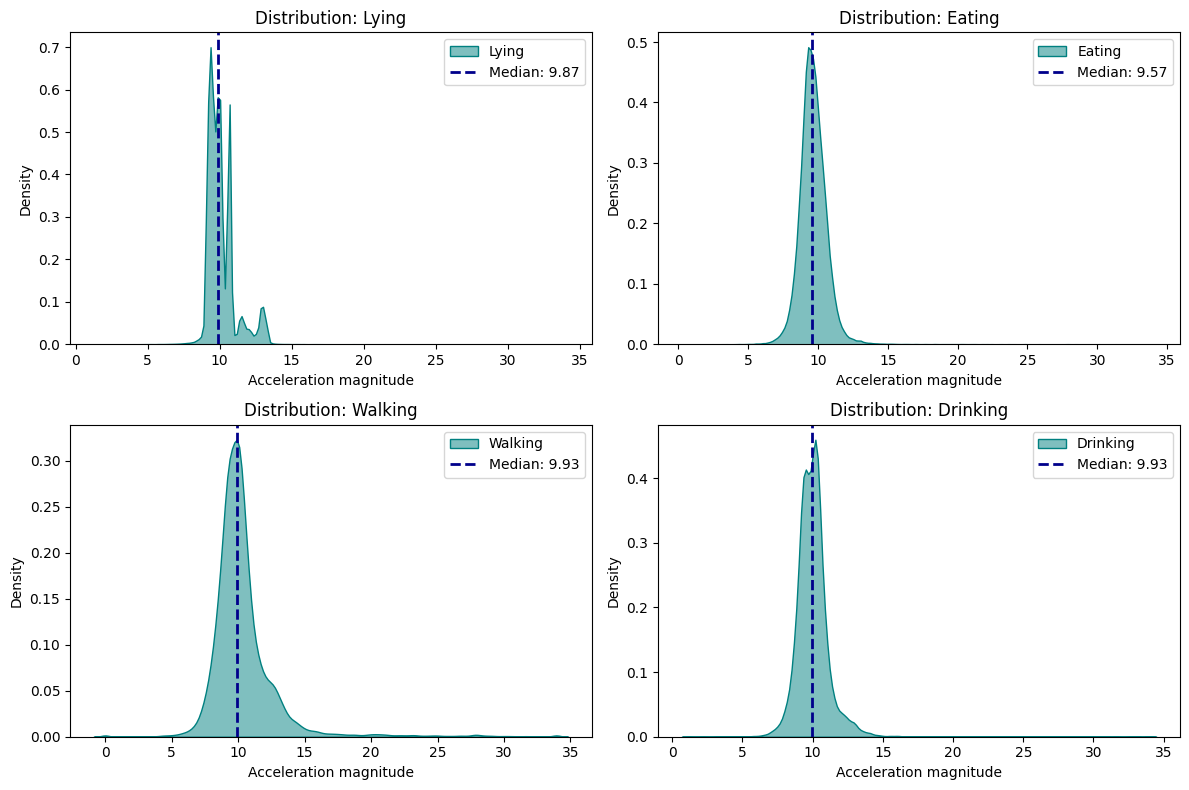

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# 1. DATASET LOADING
# ============================================================
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

# ============================================================
# 2. FILTERING AND CLASS MAPPING
# ============================================================

# Normalize text
df_final['atividade'] = (
    df_final['atividade']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Keep only the classes used in the experiment
class_mapping = {
    'andando': 'Walking',
    'comendo': 'Eating',
    'bebendo': 'Drinking',
    'dormindo': 'Lying',
    'deitadoac': 'Lying'
}

df_final['behavioral_class'] = df_final['atividade'].map(class_mapping)

# Remove unused classes: correndo, levantando, deitando, etc.
df_filtered = df_final.dropna(subset=['behavioral_class']).copy()

# Desired order
class_order = ['Lying', 'Eating', 'Walking', 'Drinking']

print("Number of rows per final class:")
print(df_filtered['behavioral_class'].value_counts().reindex(class_order))

if 'window' in df_filtered.columns:
    print("\nNumber of windows per final class:")
    print(df_filtered.groupby('behavioral_class')['window'].nunique().reindex(class_order))

# ============================================================
# 3. VECTOR MAGNITUDE
# ============================================================

df_filtered['VM'] = np.sqrt(
    df_filtered['AX']**2 +
    df_filtered['AY']**2 +
    df_filtered['AZ']**2
)

# ============================================================
# 4. PLOTTING KDE DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, activity in enumerate(class_order):

    subset = df_filtered[df_filtered['behavioral_class'] == activity]
    vm = subset['VM'].dropna()

    median_vm = np.median(vm)

    sns.kdeplot(
        vm,
        fill=True,
        label=activity,
        ax=axes[i],
        color='teal',
        alpha=0.5
    )

    axes[i].axvline(
        median_vm,
        color='darkblue',
        linestyle='dashed',
        linewidth=2,
        label=f'Median: {median_vm:.2f}'
    )

    axes[i].set_xlabel('Acceleration magnitude')
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Distribution: {activity}')
    axes[i].legend()

plt.tight_layout()
plt.show()

## Cross-Axis Correlation Feature Exploration

This cell explores the maximum cross-correlation between the `AX` and `AZ` accelerometer axes within each time window. The goal is to quantify temporal coupling between body movement directions, which may help distinguish loastion from postural or feeding-related behaviors. The function also allows normalized cross-correlation, reducing the influence of signal amplitude and focusing more directly on temporal co-variation.


Number of rows per final class:
behavioral_class
Lying       397400
Eating      267700
Walking      78300
Drinking     45800
Name: count, dtype: int64

Number of windows per final class:
behavioral_class
Lying       3974
Eating      2677
Walking      783
Drinking     458
Name: window, dtype: int64

Max Corr XZ dataset:
   window behavioral_class  max_corr_xz  max_corr_xz_norm
0       1          Walking   228.170101          0.269260
1       2          Walking   105.017762          0.387896
2       3          Walking   200.462569          0.335003
3       4          Walking    64.520274          0.232300
4       5          Walking   320.014066          0.284946

Number of windows per class:
behavioral_class
Lying       3974
Eating      2677
Walking      783
Drinking     458
Name: count, dtype: int64

Median max_corr_xz per class:
behavioral_class
Lying         0.223837
Eating       22.329248
Walking     111.538869
Drinking     29.855655
Name: max_corr_xz, dtype: float64

Median normaliz

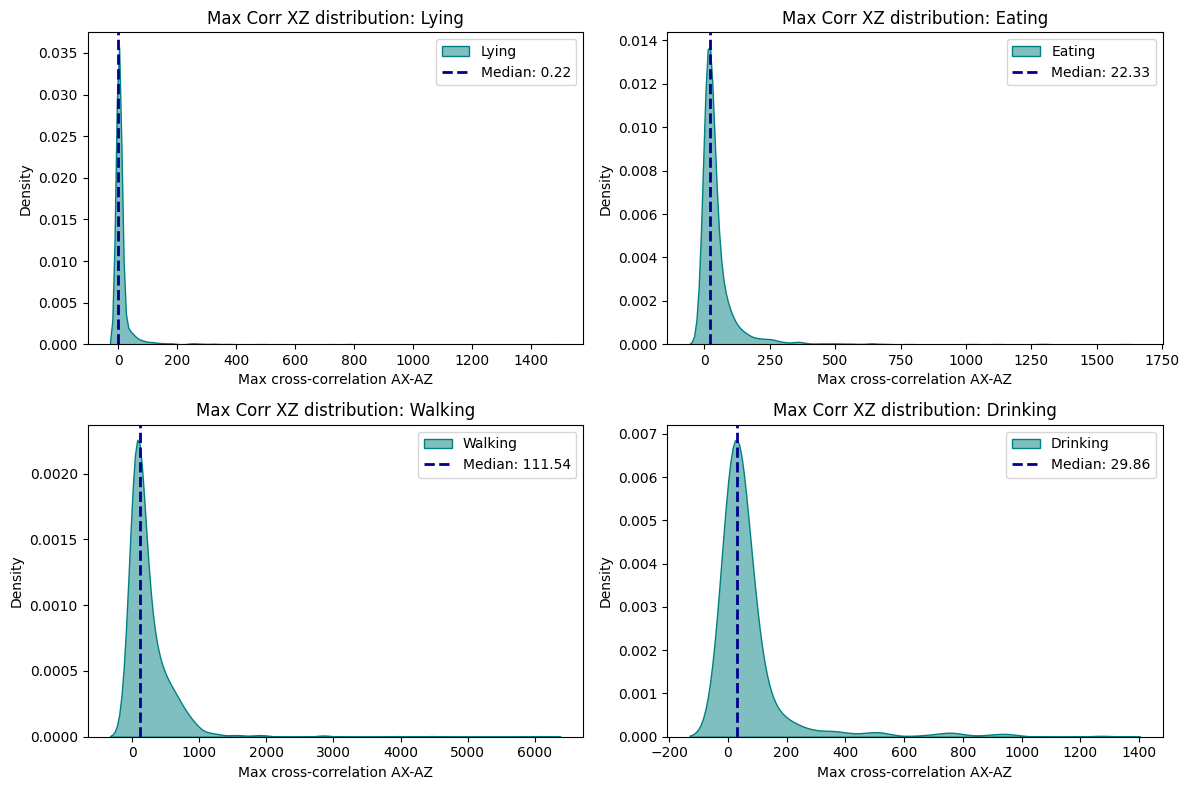

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# 1. DATASET LOADING
# ============================================================
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

# ============================================================
# 2. FILTERING AND CLASS MAPPING
# ============================================================

df_final['atividade'] = (
    df_final['atividade']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Final classes used in the experiment
class_mapping = {
    'andando': 'Walking',
    'comendo': 'Eating',
    'bebendo': 'Drinking',
    'dormindo': 'Lying',
    'deitadoac': 'Lying'
}

df_final['behavioral_class'] = df_final['atividade'].map(class_mapping)

# Remove unused classes: correndo, levantando, deitando, etc.
df_filtered = df_final.dropna(subset=['behavioral_class']).copy()

class_order = ['Lying', 'Eating', 'Walking', 'Drinking']

print("Number of rows per final class:")
print(df_filtered['behavioral_class'].value_counts().reindex(class_order))

print("\nNumber of windows per final class:")
print(df_filtered.groupby('behavioral_class')['window'].nunique().reindex(class_order))

# ============================================================
# 3. MAX CROSS-CORRELATION FUNCTION X-Z
# ============================================================

def max_corr_xz(group, normalize=False):
    """
    Computes the maximum cross-correlation between AX and AZ within one window.

    If normalize=False:
        returns the raw maximum cross-correlation:
        max_k sum_m AX[m] * AZ[m+k]

    If normalize=True:
        returns normalized cross-correlation, less dependent on signal amplitude.
    """

    x = group['AX'].values
    z = group['AZ'].values

    # Remove mean to focus on temporal co-variation
    x = x - np.mean(x)
    z = z - np.mean(z)

    corr = np.correlate(x, z, mode='full')

    if normalize:
        denom = np.sqrt(np.sum(x**2) * np.sum(z**2))
        if denom > 0:
            corr = corr / denom

    return np.max(corr)

# ============================================================
# 4. COMPUTE MAX_CORR_XZ PER WINDOW
# ============================================================

df_corr_xz = (
    df_filtered
    .groupby('window')
    .apply(lambda g: pd.Series({
        'behavioral_class': g['behavioral_class'].iloc[0],
        'max_corr_xz': max_corr_xz(g, normalize=False),
        'max_corr_xz_norm': max_corr_xz(g, normalize=True)
    }))
    .reset_index()
)

print("\nMax Corr XZ dataset:")
print(df_corr_xz.head())

print("\nNumber of windows per class:")
print(df_corr_xz['behavioral_class'].value_counts().reindex(class_order))

print("\nMedian max_corr_xz per class:")
print(df_corr_xz.groupby('behavioral_class')['max_corr_xz'].median().reindex(class_order))

print("\nMedian normalized max_corr_xz per class:")
print(df_corr_xz.groupby('behavioral_class')['max_corr_xz_norm'].median().reindex(class_order))

# ============================================================
# 5. PLOT RAW MAX_CORR_XZ DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, activity in enumerate(class_order):

    subset = df_corr_xz[df_corr_xz['behavioral_class'] == activity]
    values = subset['max_corr_xz'].dropna()

    median_value = np.median(values)

    sns.kdeplot(
        values,
        fill=True,
        label=activity,
        ax=axes[i],
        color='teal',
        alpha=0.5
    )

    axes[i].axvline(
        median_value,
        color='darkblue',
        linestyle='dashed',
        linewidth=2,
        label=f'Median: {median_value:.2f}'
    )

    axes[i].set_xlabel('Max cross-correlation AX-AZ')
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Max Corr XZ distribution: {activity}')
    axes[i].legend()

plt.tight_layout()

# ============================================================
# 6. SAVE FIGURE AS PDF
# ============================================================

output_folder = r'C:\Users\franc\OneDrive\Desktop'

pdf_path = os.path.join(
    output_folder,
    'max_corr_xz_distribution_4classes.pdf'
)

plt.savefig(
    pdf_path,
    bbox_inches='tight'
)

print(f"PDF saved at: {pdf_path}")

plt.show()


## Entropy-Based Accelerometer Feature Exploration

This cell computes histogram-based entropy from accelerometer-derived signals after filtering the dataset into the final class set. Entropy summarizes the irregularity or variability of the movement signal inside each window. This exploratory analysis helps determine whether dynamic complexity differs among behaviors and whether entropy should be considered as a candidate feature for the Random Forest models.


Number of rows per final class:
behavioral_class
Lying       397400
Eating      267700
Walking      78300
Drinking     45800
Name: count, dtype: int64

Number of windows per final class:
behavioral_class
Lying       3974
Eating      2677
Walking      783
Drinking     458
Name: window, dtype: int64

Entropy dataset:
   window behavioral_class   entropy
0       1          Walking  1.161732
1       2          Walking  1.434617
2       3          Walking  1.465862
3       4          Walking  1.722323
4       5          Walking  1.694627

Number of entropy values per class:
behavioral_class
Lying       3974
Eating      2677
Walking      783
Drinking     458
Name: count, dtype: int64

Median entropy per class:
behavioral_class
Lying       1.894145
Eating      1.917252
Walking     1.635346
Drinking    1.739347
Name: entropy, dtype: float64


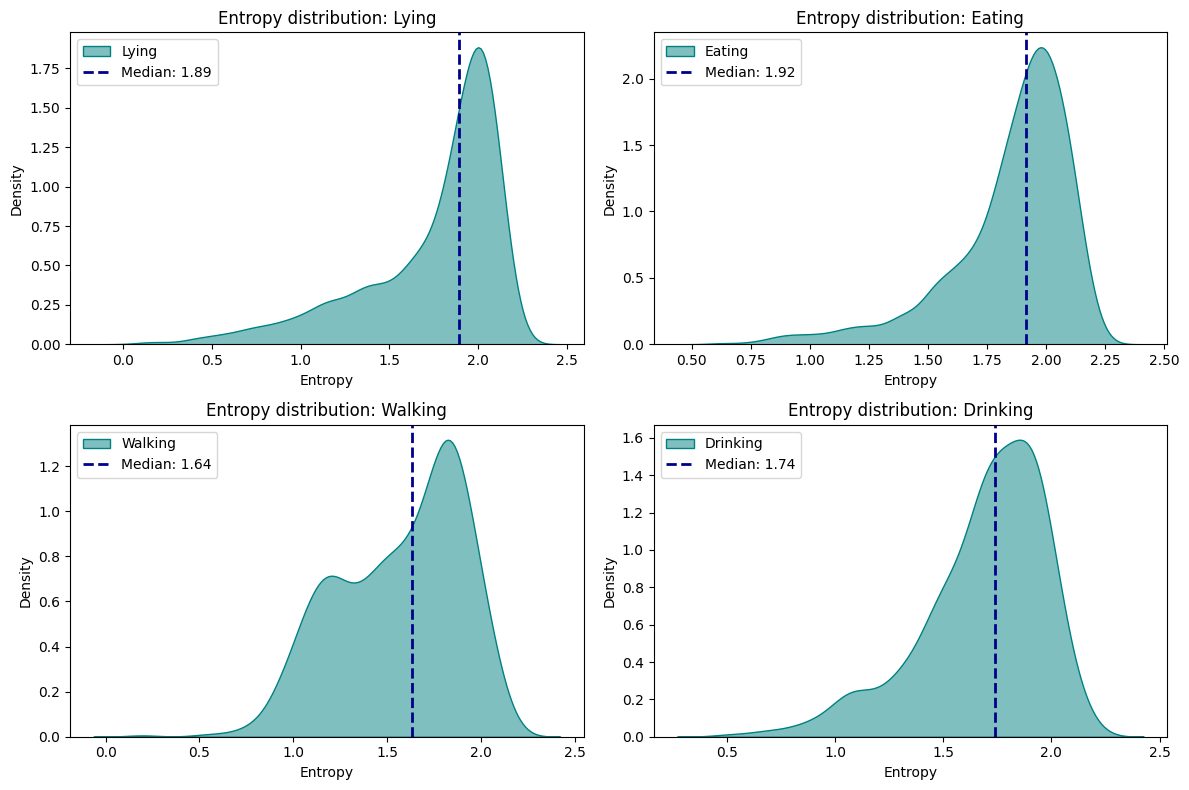

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# 1. DATASET LOADING
# ============================================================
caminho_arquivo = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'
df_final = pd.read_excel(caminho_arquivo)

# ============================================================
# 2. FILTERING AND CLASS MAPPING
# ============================================================

df_final['atividade'] = (
    df_final['atividade']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Final classes used in the experiment
class_mapping = {
    'andando': 'Walking',
    'comendo': 'Eating',
    'bebendo': 'Drinking',
    'dormindo': 'Lying',
    'deitadoac': 'Lying'
}

df_final['behavioral_class'] = df_final['atividade'].map(class_mapping)

# Remove unused classes: correndo, levantando, deitando, etc.
df_filtered = df_final.dropna(subset=['behavioral_class']).copy()

# Desired order
class_order = ['Lying', 'Eating', 'Walking', 'Drinking']

print("Number of rows per final class:")
print(df_filtered['behavioral_class'].value_counts().reindex(class_order))

if 'window' in df_filtered.columns:
    print("\nNumber of windows per final class:")
    print(df_filtered.groupby('behavioral_class')['window'].nunique().reindex(class_order))

# ============================================================
# 3. VECTOR MAGNITUDE
# ============================================================

df_filtered['VM'] = np.sqrt(
    df_filtered['AX']**2 +
    df_filtered['AY']**2 +
    df_filtered['AZ']**2
)

# ============================================================
# 4. ENTROPY FUNCTION
# ============================================================

def calcular_entropia_histograma(x, bins=10):
    """
    Histogram-based entropy.
    The signal values are discretized into bins, and entropy is computed
    from the probability distribution of the bins.
    """
    x = np.asarray(x)
    x = x[~np.isnan(x)]

    if len(x) == 0:
        return np.nan

    hist, _ = np.histogram(x, bins=bins, density=False)
    prob = hist / np.sum(hist)

    # Remove zero probabilities to avoid log(0)
    prob = prob[prob > 0]

    entropy = -np.sum(prob * np.log(prob))

    return entropy

# ============================================================
# 5. COMPUTE ENTROPY PER WINDOW
# ============================================================

df_entropy = (
    df_filtered
    .groupby('window')
    .apply(lambda g: pd.Series({
        'behavioral_class': g['behavioral_class'].iloc[0],
        'entropy': calcular_entropia_histograma(g['VM'], bins=10)
    }))
    .reset_index()
)

print("\nEntropy dataset:")
print(df_entropy.head())

print("\nNumber of entropy values per class:")
print(df_entropy['behavioral_class'].value_counts().reindex(class_order))

print("\nMedian entropy per class:")
print(df_entropy.groupby('behavioral_class')['entropy'].median().reindex(class_order))

# ============================================================
# 6. PLOTTING ENTROPY DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, activity in enumerate(class_order):

    subset = df_entropy[df_entropy['behavioral_class'] == activity]
    entropy_values = subset['entropy'].dropna()

    median_entropy = np.median(entropy_values)

    sns.kdeplot(
        entropy_values,
        fill=True,
        label=activity,
        ax=axes[i],
        color='teal',
        alpha=0.5
    )

    axes[i].axvline(
        median_entropy,
        color='darkblue',
        linestyle='dashed',
        linewidth=2,
        label=f'Median: {median_entropy:.2f}'
    )

    axes[i].set_xlabel('Entropy')
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Entropy distribution: {activity}')
    axes[i].legend()

plt.tight_layout()
plt.show()

## Comparison of Accelerometer and Audio Sample Counts

This cell builds a comparative bar chart showing the number of available windows for the accelerometer and audio modalities in the final four-class scenario. The purpose is to document class imbalance and modality coverage before model training and fusion. This comparison is especially relevant because the synchronized multimodal subset is constrained by the overlap between sensor and audio windows.


Accelerometer total: 7892
Audio total: 6285


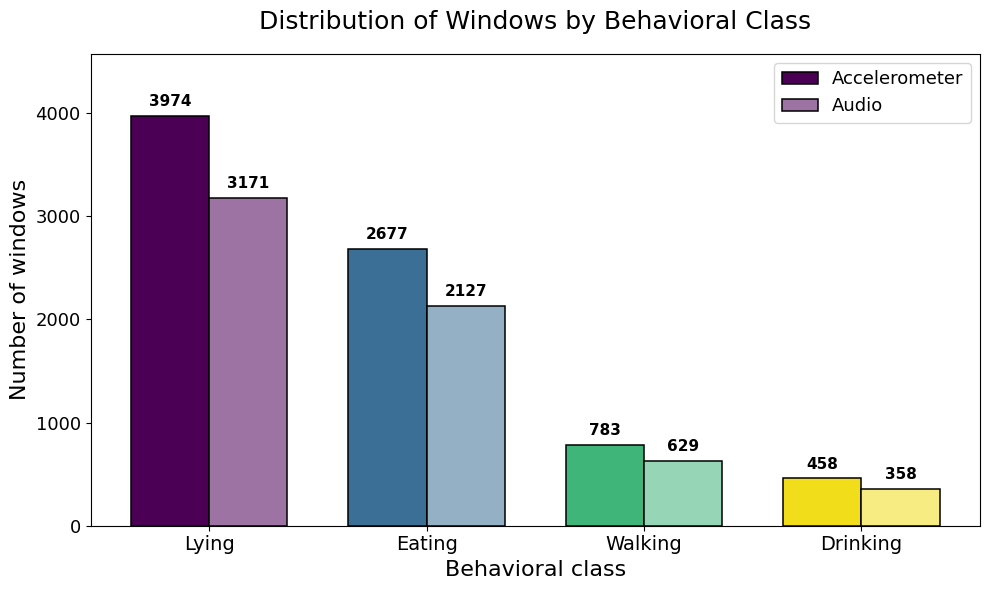


Files saved successfully:
PNG : C:\Users\franc\OneDrive\Desktop\behavioral_class_distribution_acc_vs_audio_corrected.png
TIFF: C:\Users\franc\OneDrive\Desktop\behavioral_class_distribution_acc_vs_audio_corrected.tiff
PDF : C:\Users\franc\OneDrive\Desktop\behavioral_class_distribution_acc_vs_audio_corrected.pdf


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
import os

# ============================================================
# 1. Correct real data used in the final experiment
# ============================================================
classes = ['Lying', 'Eating', 'Walking', 'Drinking']

# Accelerometer: deitando was excluded
# Lying = dormindo + deitadoac = 2396 + 1578 = 3974
accelerometer = [3974, 2677, 783, 458]

# Audio data
audio = [3171, 2127, 629, 358]

# Check totals
print("Accelerometer total:", sum(accelerometer))
print("Audio total:", sum(audio))

# ============================================================
# 2. Colors
# ============================================================
base_colors = ['#4B0055', '#3B6F95', '#40B57A', '#F1DD1A']

def lighten_color(color, amount=0.45):
    """
    Creates a lighter version of the same color.
    """
    c = np.array(mcolors.to_rgb(color))
    white = np.array([1, 1, 1])
    return mcolors.to_hex(c + (white - c) * amount)

soft_colors = [lighten_color(c, amount=0.45) for c in base_colors]

# ============================================================
# 3. Plot
# ============================================================
x = np.arange(len(classes))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

bars_acc = ax.bar(
    x - width / 2,
    accelerometer,
    width,
    label='Accelerometer',
    color=base_colors,
    edgecolor='black',
    linewidth=1.1
)

bars_audio = ax.bar(
    x + width / 2,
    audio,
    width,
    label='Audio',
    color=soft_colors,
    edgecolor='black',
    linewidth=1.1
)

# ============================================================
# 4. Add values above bars
# ============================================================
for bars in [bars_acc, bars_audio]:
    for bar in bars:
        height = int(bar.get_height())
        ax.annotate(
            f'{height}',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
        )

# ============================================================
# 5. Labels and style
# ============================================================
ax.set_title('Distribution of Windows by Behavioral Class', fontsize=18, pad=18)
ax.set_xlabel('Behavioral class', fontsize=16)
ax.set_ylabel('Number of windows', fontsize=16)

ax.set_xticks(x)
ax.set_xticklabels(classes, fontsize=14)
ax.tick_params(axis='y', labelsize=13)

ax.legend(fontsize=13, frameon=True, loc='upper right')

ax.set_ylim(0, max(max(accelerometer), max(audio)) * 1.15)

plt.tight_layout()

# ============================================================
# 6. Save high-resolution files
# ============================================================
output_folder = r'C:\Users\franc\OneDrive\Desktop'
os.makedirs(output_folder, exist_ok=True)

png_path = os.path.join(output_folder, 'behavioral_class_distribution_acc_vs_audio_corrected.png')
tiff_path = os.path.join(output_folder, 'behavioral_class_distribution_acc_vs_audio_corrected.tiff')
pdf_path = os.path.join(output_folder, 'behavioral_class_distribution_acc_vs_audio_corrected.pdf')

plt.savefig(png_path, dpi=600, bbox_inches='tight')
plt.savefig(tiff_path, dpi=600, bbox_inches='tight')
plt.savefig(pdf_path, bbox_inches='tight')

plt.show()

print("\nFiles saved successfully:")
print("PNG :", png_path)
print("TIFF:", tiff_path)
print("PDF :", pdf_path)

## Publication-Quality Behavioral Class Distribution Figure

This cell reloads the accelerometer spreadsheet, maps the original labels into the final behavioral classes, and generates high-resolution figures of the class distribution. The output files are saved in raster and vector formats, supporting use in manuscripts, reports, or presentations. This provides a reproducible way to document dataset composition.


File successfully loaded! Total rows: 834100

Original classes found:
atividade
comendo       267700
dormindo      239600
deitadoac     157800
andando        78300
bebendo        45800
levantando     20900
deitando       16300
correndo        7700
Name: count, dtype: int64

Classes used in the experiment:
behavioral_class
Lying       413700
Eating      267700
Walking      78300
Drinking     45800
Name: count, dtype: int64

Summary in English:
behavioral_class
Lying       4137
Eating      2677
Walking      783
Drinking     458
Name: window, dtype: int64


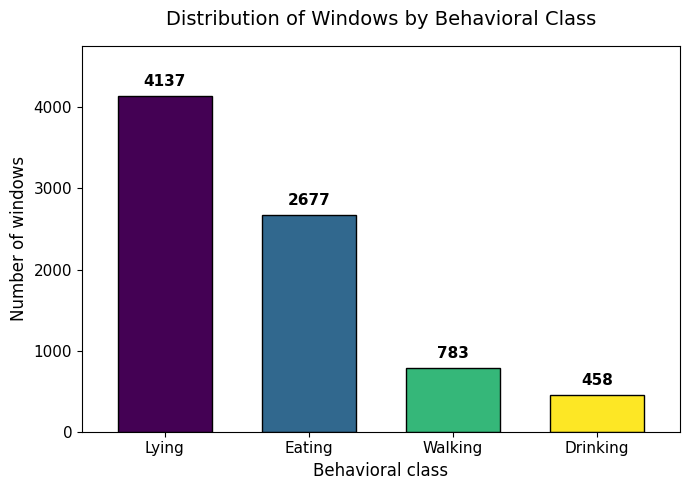


Figures saved successfully:
PNG  600 dpi: C:\Users\franc\OneDrive\Desktop\behavioral_class_distribution_600dpi.png
TIFF 600 dpi: C:\Users\franc\OneDrive\Desktop\behavioral_class_distribution_600dpi.tiff
PDF vector:   C:\Users\franc\OneDrive\Desktop\behavioral_class_distribution_vector.pdf


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# ============================================================
# 1. File path
# ============================================================
input_file = r'C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx'

# Folder where the figure will be saved
output_folder = r'C:\Users\franc\OneDrive\Desktop'
os.makedirs(output_folder, exist_ok=True)

# Output figure paths
png_path = os.path.join(output_folder, 'behavioral_class_distribution_600dpi.png')
tiff_path = os.path.join(output_folder, 'behavioral_class_distribution_600dpi.tiff')
pdf_path = os.path.join(output_folder, 'behavioral_class_distribution_vector.pdf')

if not os.path.exists(input_file):
    print(f"ERROR: File does not exist: {input_file}")

else:
    try:
        df = pd.read_excel(input_file, engine='openpyxl')

        print(f"File successfully loaded! Total rows: {len(df)}")

        # ============================================================
        # 2. Clean class names
        # ============================================================
        df['atividade'] = (
            df['atividade']
            .astype(str)
            .str.strip()
            .str.lower()
        )

        print("\nOriginal classes found:")
        print(df['atividade'].value_counts())

        # ============================================================
        # 3. Map only the classes used in the experiment
        # ============================================================
        class_mapping = {
            'comendo': 'Eating',
            'bebendo': 'Drinking',

            # sleeping + lying awake + lying down -> Lying
            'dormindo': 'Lying',
            'deitadoac': 'Lying',
            'deitando': 'Lying',

            # walking
            'andando': 'Walking'
        }

        df['behavioral_class'] = df['atividade'].map(class_mapping)

        # Remove classes not used in the experiment
        df_filtered = df.dropna(subset=['behavioral_class']).copy()

        print("\nClasses used in the experiment:")
        print(df_filtered['behavioral_class'].value_counts())

        # ============================================================
        # 4. Count windows per behavioral class
        # ============================================================
        if 'window' in df_filtered.columns:
            class_counts = df_filtered.groupby('behavioral_class')['window'].nunique()
        else:
            class_counts = df_filtered.groupby('behavioral_class').size() / 100

        # Sort in descending order
        class_counts = class_counts.sort_values(ascending=False).astype(int)

        print("\nSummary in English:")
        print(class_counts)

        # ============================================================
        # 5. Plot only in English
        # ============================================================
        plt.figure(figsize=(7, 5))

        colors = plt.cm.viridis(np.linspace(0, 1, len(class_counts)))

        ax = class_counts.plot(
            kind='bar',
            color=colors,
            edgecolor='black',
            width=0.65
        )

        # Add values above bars
        for p in ax.patches:
            value = int(p.get_height())
            ax.annotate(
                f'{value}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center',
                va='bottom',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=11,
                fontweight='bold'
            )

        plt.title('Distribution of Windows by Behavioral Class', fontsize=14, pad=15)
        plt.xlabel('Behavioral class', fontsize=12)
        plt.ylabel('Number of windows', fontsize=12)
        plt.xticks(rotation=0, fontsize=11)
        plt.yticks(fontsize=11)

        if class_counts.max() > 0:
            plt.ylim(0, class_counts.max() * 1.15)

        plt.tight_layout()

        # ============================================================
        # 6. Save high-resolution figures
        # ============================================================
        plt.savefig(png_path, dpi=600, bbox_inches='tight')
        plt.savefig(tiff_path, dpi=600, bbox_inches='tight')
        plt.savefig(pdf_path, bbox_inches='tight')

        plt.show()

        print("\nFigures saved successfully:")
        print(f"PNG  600 dpi: {png_path}")
        print(f"TIFF 600 dpi: {tiff_path}")
        print(f"PDF vector:   {pdf_path}")

    except Exception as e:
        print("\n--- ERROR READING THE EXCEL FILE ---")
        print(f"Error detail: {e}")

## Audio Segmentation into Five-Second Windows

This cell configures FFmpeg for `pydub` and segments WAV recordings into standardized five-second audio windows. The generated segments are named according to their temporal position so that they can later be aligned with accelerometer windows. This preprocessing step is essential for transforming continuous audio recordings into fixed-duration samples compatible with supervised classification.


In [4]:
import os
from datetime import datetime, timedelta
from pydub import AudioSegment

# --- MANUAL FFMPEG CONFIGURATION (path confirmed in the terminal) ---
ffmpeg_bin_path = r"C:\Users\franc\AppData\Local\ffmpegio\ffmpeg-downloader\ffmpeg\bin"
ffmpeg_exe = os.path.join(ffmpeg_bin_path, "ffmpeg.exe")
ffprobe_exe = os.path.join(ffmpeg_bin_path, "ffprobe.exe")

# Inform Pydub where the executables are located
AudioSegment.converter = ffmpeg_exe
AudioSegment.ffprobe = ffprobe_exe

# Also add the directory to the system PATH for this session
if ffmpeg_bin_path not in os.environ["PATH"]:
    os.environ["PATH"] += os.path.pathsep + ffmpeg_bin_path
# --------------------------------------------------------------------------

input_dir = r"C:\Users\franc\OneDrive\Desktop\audio2-am31"
output_dir = r"C:\Users\franc\OneDrive\Desktop\audio2-am31 -5s"

if not os.path.exists(output_dir):
    os.makedirs(output_dir)
    print(f"Output folder created: {output_dir}")

# List .wav files
files = [f for f in os.listdir(input_dir) if f.endswith('.wav')]

print(f"Iniciando processamento de {len(files)} files...\n")

for filename in files:
    try:
        # 1. Extrair data e hora do nome original
        base_name = os.path.splitext(filename)[0]
        start_time_obj = datetime.strptime(base_name, "%Y%m%d_%H%M%S")
        
        # 2. Carregar o audio
        path_full = os.path.join(input_dir, filename)
        audio = AudioSegment.from_wav(path_full)
        
        segment_duration = 5 * 1000 # 5 segundos
        total_duration = len(audio)
        
        print(f"Lendo: {filename} ({total_duration/1000}s)")

        # 3. Gerar cortes de 5s
        for i, start_ms in enumerate(range(0, total_duration, segment_duration)):
            end_ms = start_ms + segment_duration
            
            # Avoid creating empty files at the end if the audio length is not an exact multiple of 5 seconds
            if (total_duration - start_ms) < 500: # menos de meio segundo restante
                break
                
            segment = audio[start_ms:end_ms]
            
            # Compute the segment timestamp
            current_segment_time = start_time_obj + timedelta(seconds=i*5)
            new_timestamp = current_segment_time.strftime("%H%M%S")
            
            new_filename = f"m31-{new_timestamp}.wav"
            output_path = os.path.join(output_dir, new_filename)
            
            # Salva
            segment.export(output_path, format="wav")
            print(f"  -> Exportado: {new_filename}")
            
    except Exception as e:
        print(f"Erro ao processar {filename}: {e}")

print("\n--- All set! Check the destination folder. ---")

Iniciando processamento de 1056 files...

Lendo: 20260131_083241.wav (29.376s)
  -> Exportado: m31-083241.wav
  -> Exportado: m31-083246.wav
  -> Exportado: m31-083251.wav
  -> Exportado: m31-083256.wav
  -> Exportado: m31-083301.wav
  -> Exportado: m31-083306.wav
Lendo: 20260131_083313.wav (27.36s)
  -> Exportado: m31-083313.wav
  -> Exportado: m31-083318.wav
  -> Exportado: m31-083323.wav
  -> Exportado: m31-083328.wav
  -> Exportado: m31-083333.wav
  -> Exportado: m31-083338.wav
Lendo: 20260131_083345.wav (29.312s)
  -> Exportado: m31-083345.wav
  -> Exportado: m31-083350.wav
  -> Exportado: m31-083355.wav
  -> Exportado: m31-083400.wav
  -> Exportado: m31-083405.wav
  -> Exportado: m31-083410.wav
Lendo: 20260131_083417.wav (29.376s)
  -> Exportado: m31-083417.wav
  -> Exportado: m31-083422.wav
  -> Exportado: m31-083427.wav
  -> Exportado: m31-083432.wav
  -> Exportado: m31-083437.wav
  -> Exportado: m31-083442.wav
Lendo: 20260131_083449.wav (29.312s)
  -> Exportado: m31-083449.wav

## Extraction of Audio Windows Aligned with Accelerometer Metadata

This cell extracts audio segments using metadata from the accelerometer spreadsheet and writes the resulting WAV files into behavior-specific folders. The procedure links each audio segment to window identifiers and timestamps, making it possible to build a synchronized audio–accelerometer dataset. This step is central to later multimodal fusion because it establishes the correspondence between modalities.


In [13]:
import os
import pandas as pd
from datetime import datetime, timedelta
from pydub import AudioSegment

# --- PATH CONFIGURATION ---
caminho_excel = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx"
diretorio_audios_origem = r"C:\Users\franc\OneDrive\Desktop\audio7-p30"
diretorio_saida_base = r"C:\Users\franc\OneDrive\Desktop\p30"

# --- FFMPEG ENGINE CONFIGURATION ---
ffmpeg_bin = r"C:\Users\franc\AppData\Local\ffmpegio\ffmpeg-downloader\ffmpeg\bin"
AudioSegment.converter = os.path.join(ffmpeg_bin, "ffmpeg.exe")
AudioSegment.ffprobe = os.path.join(ffmpeg_bin, "ffprobe.exe")

# --- PROJECT PARAMETERS ---
ID_ALVO = 7 # 
classes_ignoradas = ['levantando', 'deitando']

# 1. Load and filter the dataset
print("Reading dataset...")
df = pd.read_excel(caminho_excel)

# Keep only the target animal ID
df = df[df['ID'] == ID_ALVO]

# Convert the time column to Python datetime format
# The format '%d/%m/%Y %H:%M:%S,%f' handles milliseconds after the comma
df['DataHora_ms'] = pd.to_datetime(df['DataHora_ms'], format='%d/%m/%Y %H:%M:%S,%f')

# 2. Group data by window and activity
# This gives the exact start and end time of each segment to be cut
windows = df.groupby(['window', 'atividade']).agg(
    inicio=('DataHora_ms', 'min'),
    fim=('DataHora_ms', 'max')
).reset_index()

print(f"Total windows encontradas para o ID {ID_ALVO}: {len(windows)}")

# 3. Audio processing
for _, row in windows.iterrows():
    num_window = row['window']
    atividade = row['atividade']
    t_inicio_window = row['inicio']
    t_fim_window = row['fim']
    
    # Ignore unwanted classes
    if atividade.lower() in [c.lower() for c in classes_ignoradas]:
        continue

    # Ensure that the class output folder exists
    pasta_classe = os.path.join(diretorio_saida_base, atividade)
    if not os.path.exists(pasta_classe):
        os.makedirs(pasta_classe)

    # Find which audio file contains this timestamp
    audio_encontrado = None
    start_audio_ref = None
    
    for arquivo in os.listdir(diretorio_audios_origem):
        if arquivo.endswith(".wav"):
            try:
                # Extrai timestamp do nome: 20260131_083241.wav
                t_arquivo = datetime.strptime(os.path.splitext(arquivo)[0], "%Y%m%d_%H%M%S")
                
                # If the window starts within the 30-second interval of this audio file
                if t_arquivo <= t_inicio_window < (t_arquivo + timedelta(seconds=30)):
                    audio_encontrado = arquivo
                    start_audio_ref = t_arquivo
                    break
            except:
                continue

    if audio_encontrado:
        try:
            # Load the original audio file
            audio_path = os.path.join(diretorio_audios_origem, audio_encontrado)
            audio_data = AudioSegment.from_wav(audio_path)
            
            # Calcula os pontos de corte em milissegundos
            ms_inicio = (t_inicio_window - start_audio_ref).total_seconds() * 1000
            ms_fim = (t_fim_window - start_audio_ref).total_seconds() * 1000
            
            # Realiza o corte
            segmento = audio_data[ms_inicio:ms_fim]
            
            # Formata nome: am31-horario-j(numero).wav
            str_horario = t_inicio_window.strftime("%H%M%S")
            nome_final = f"p30-{str_horario}-j{int(num_window)}.wav"
            
            # Exporta
            segmento.export(os.path.join(pasta_classe, nome_final), format="wav")
            print(f"Window {num_window} saved in '{atividade}' as {nome_final}")
            
        except Exception as e:
            print(f"Error cutting window {num_window} from file {audio_encontrado}: {e}")

print("\n--- Process completed successfully! ---")

Reading dataset...
Total windows encontradas para o ID 7: 573
Window 1773 saved in 'andando' as p30-092010-j1773.wav
Window 1774 saved in 'andando' as p30-092332-j1774.wav
Window 1775 saved in 'andando' as p30-092336-j1775.wav
Window 1776 saved in 'andando' as p30-092410-j1776.wav
Window 1777 saved in 'andando' as p30-092414-j1777.wav
Window 1778 saved in 'bebendo' as p30-092449-j1778.wav
Window 1779 saved in 'bebendo' as p30-092453-j1779.wav
Window 1780 saved in 'andando' as p30-092457-j1780.wav
Window 1781 saved in 'andando' as p30-092501-j1781.wav
Window 1782 saved in 'comendo' as p30-092504-j1782.wav
Window 1783 saved in 'comendo' as p30-092508-j1783.wav
Window 1784 saved in 'comendo' as p30-092513-j1784.wav
Window 1785 saved in 'comendo' as p30-092518-j1785.wav
Window 1786 saved in 'comendo' as p30-092523-j1786.wav
Window 1787 saved in 'comendo' as p30-092528-j1787.wav
Window 1788 saved in 'comendo' as p30-092533-j1788.wav
Window 1789 saved in 'comendo' as p30-092538-j1789.wav
Win

## Initial Log-Mel Spectrogram Inspection

This cell loads a representative audio window and computes its Mel spectrogram. The visualization is used to inspect the spectral structure of pig-related sounds and background noise before batch feature extraction. This diagnostic step helps verify whether the selected spectrogram parameters provide a useful time–frequency representation for the audio CNN.


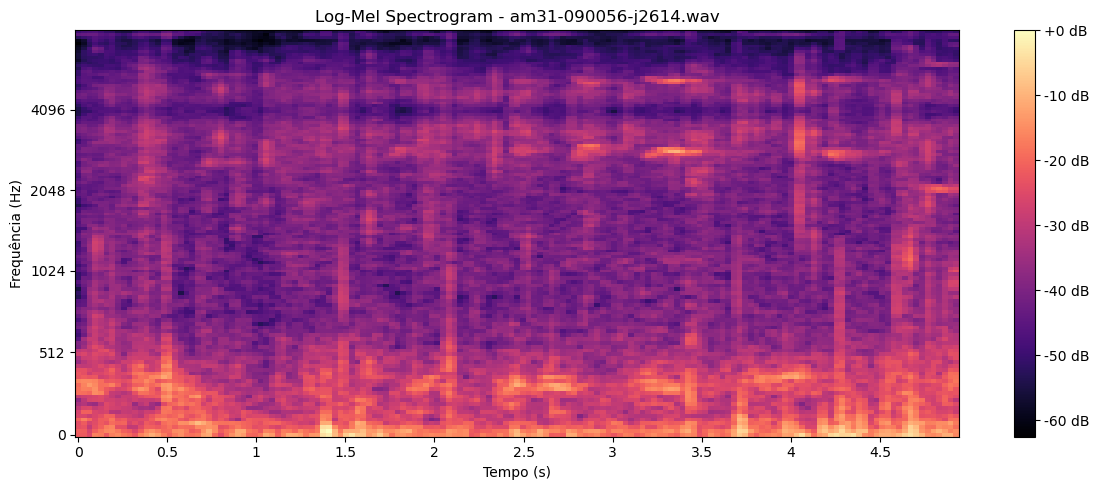

In [17]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

# 1. Choose a file known to contain background noise (birds)
# Change the file name below for a real test
caminho_teste = r"C:\Users\franc\OneDrive\Desktop\dataset audio\comendo\am31-090056-j2614.wav"

try:
    # Load the audio file
    y, sr = librosa.load(caminho_teste, sr=None)
    
    # 2. Compute the Mel spectrogram
    # n_mels=128: defines the vertical resolution
    # fmax=8000: focuses on the frequency range where pig sounds and common noises occur
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
    
    # 3. Convert to logarithmic scale (Log-Mel)
    # This converts amplitude to decibels (dB)
    S_db = librosa.power_to_db(S, ref=np.max)
    
    # 4. Plot the figure
    plt.figure(figsize=(12, 5))
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel', fmax=8000, cmap='magma')
    
    plt.colorbar(format='%+2.0f dB')
    plt.title(f'Log-Mel Spectrogram - {os.path.basename(caminho_teste)}')
    plt.xlabel('Tempo (s)')
    plt.ylabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error loading the file: {e}")

## Installation of Audio Processing Dependencies

This cell installs the audio processing and plotting dependencies required for spectrogram generation. It is included for reproducibility in environments where `librosa`, `matplotlib`, or `soundfile` are not already available. In a production setup, these dependencies should preferably be installed through `requirements.txt` or `environment.yml`.


In [15]:
!pip install librosa matplotlib soundfile

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 1.0/1.0 MB 15.0 MB/s  0:00:00

   --------------- ------------------------ 3/8 [soxr]
   ------------------------- -------------- 5/8 [pooch]
   ------------------------------ --------- 6/8 [audioread]
   ----------------------------------- ---- 7/8 [librosa]
   ----------------------------------- ---- 7/8 [librosa]
   ----------------------------------- ---- 7/8 [librosa]
   ---------------------------------------- 8/8 [librosa]



## Linear and Decibel-Scaled Mel Spectrogram Comparison

This cell computes and visualizes the same Mel spectrogram in different scaling formats. Comparing raw power and decibel-scaled representations helps decide which transformation better emphasizes relevant acoustic patterns. The log-scaled representation is typically more appropriate for CNN-based audio classification because it compresses large amplitude differences while preserving informative spectral structure.


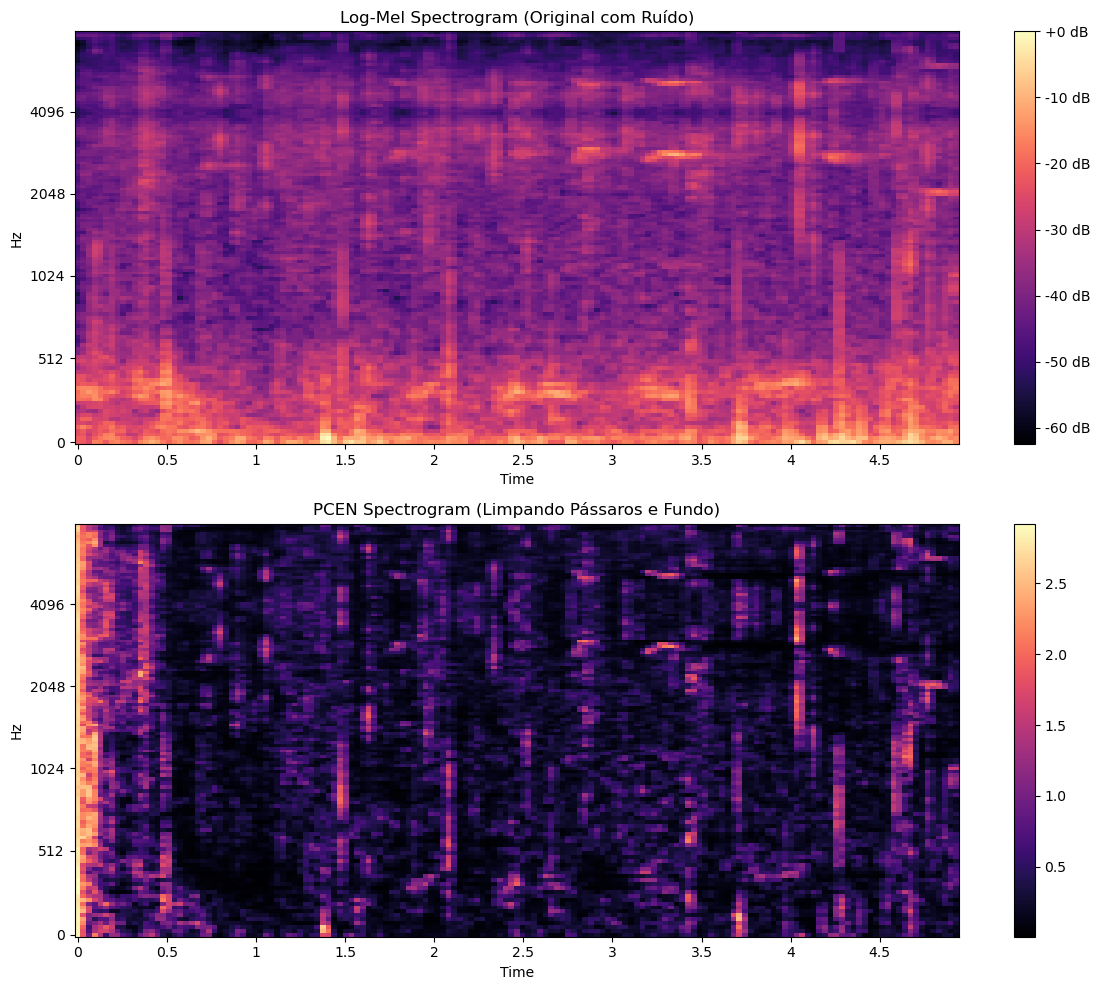

In [18]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Use the same file from the previous figure for comparison
caminho_teste = r"C:\Users\franc\OneDrive\Desktop\dataset audio\comendo\am31-090056-j2614.wav"

if os.path.exists(caminho_teste):
    # Load the audio file
    y, sr = librosa.load(caminho_teste, sr=None)
    
    # 2. Compute the base Mel spectrogram shared by both methods
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
    
    # 3. Generate Log-Mel (the representation already used)
    S_db = librosa.power_to_db(S, ref=np.max)
    
    # 4. Generate PCEN
    # Multiply by 2**31 to simulate 32-bit audio, which PCEN expects
    # The parameters (gain, bias, etc.) are the recommended defaults for robustness
    S_pcen = librosa.pcen(S * (2**31), sr=sr, hop_length=512)

    # --- SIDE-BY-SIDE PLOTTING ---
    fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(12, 10))

    # Plot 1: Log-Mel
    img1 = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel', 
                                    fmax=8000, ax=ax[0], cmap='magma')
    ax[0].set(title='Log-Mel Spectrogram (Original Audio)')
    fig.colorbar(img1, ax=ax[0], format='%+2.0f dB')

    # Plot 2: PCEN
    img2 = librosa.display.specshow(S_pcen, sr=sr, x_axis='time', y_axis='mel', 
                                    fmax=8000, ax=ax[1], cmap='magma')
    ax[1].set(title='PCEN Spectrogram (Suppressing Birds and Background Noise)')
    fig.colorbar(img2, ax=ax[1])

    plt.tight_layout()
    plt.show()
else:
    print("File not found!")

## Spectrogram File Manifest and Temporal Padding Setup

This cell scans the spectrogram dataset, maps class folders to numeric labels, and prepares a subset of files for downstream loading. It also defines a fixed temporal width so that spectrogram matrices with different durations or frame counts can be padded or standardized. This standardization is required because neural networks expect tensors with consistent dimensions within a batch.


In [24]:
import os
import random
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

# --- CONFIGURATION ---
base_path = r"C:\Users\franc\OneDrive\Desktop\dataset_sg"
MAX_SAMPLES = 500
TARGET_WIDTH = 154  # Standard width observed in the test

# Map classes to numeric labels
classes = sorted([d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))])
class_to_idx = {cls: i for i, cls in enumerate(classes)}

# Create a balanced list of paths and labels
balanced_files = []

print("Balancing dataset...")
for cls in classes:
    path = os.path.join(base_path, cls)
    files = [os.path.join(path, f) for f in os.listdir(path) if f.endswith('.npy')]
    
    # Se tiver mais que 500, seleciona aleatoriamente
    if len(files) > MAX_SAMPLES:
        selecionados = random.sample(files, MAX_SAMPLES)
    else:
        selecionados = files
        print(f"  (!) Warning: class [{cls}] has only {len(files)} samples.")
    
    for f in selecionados:
        balanced_files.append((f, class_to_idx[cls]))

random.shuffle(balanced_files) # Shuffle all files for training
print(f"\nTotal samples in the final dataset: {len(balanced_files)}")

Balancing dataset...
  (!) Warning: class [bebendo] has only 369 samples.
  (!) Warning: class [correndo] has only 60 samples.

Total samples in the final dataset: 2429


## Batch Conversion of WAV Files to High-Resolution Log-Mel Arrays

This cell converts the audio dataset into log-Mel spectrogram arrays and saves them as `.npy` files. The selected parameters define the sampling rate, duration, number of Mel bands, FFT size, and hop length. The resulting arrays become the input representation for the audio CNN and LMAAN models.


In [1]:
import os
import librosa
import numpy as np

# --- CONFIGURATION ---
data_path = r"C:\Users\franc\OneDrive\Desktop\dataset audio" 
save_path = r"C:\Users\franc\OneDrive\Desktop\logmel_512"
os.makedirs(save_path, exist_ok=True)

# High-resolution parameters
SR = 22050
DURATION = 5  
N_MELS = 128
N_FFT = 1024
HOP_LENGTH = 256 # <--- This ensures high temporal resolution

print(f"Starting extraction to: {save_path}...")

for root, dirs, files in os.walk(data_path):
    for file in files:
        if file.endswith('.wav'):
            try:
                # Load the audio file
                path = os.path.join(root, file)
                y, sr = librosa.load(path, sr=SR, duration=DURATION)
                
                # Ensure exactly 5 seconds
                if len(y) < SR * DURATION:
                    y = librosa.util.fix_length(y, size=SR * DURATION)
                
                # Generate Log-Mel spectrogram
                mel_spec = librosa.feature.melspectrogram(
                    y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS
                )
                log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
                
                # Save in the corresponding folder
                rel_path = os.path.relpath(root, data_path)
                dest_folder = os.path.join(save_path, rel_path)
                os.makedirs(dest_folder, exist_ok=True)
                
                save_name = file.replace('.wav', '.npy')
                np.save(os.path.join(dest_folder, save_name), log_mel_spec)
                
            except Exception as e:
                print(f"Error in file {file}: {e}")

print("✅ Extraction completed successfully!")

Starting extraction to: C:\Users\franc\OneDrive\Desktop\logmel_512...
✅ Extraction completed successfully!


## Reconstruction of the Train–Validation Split for Audio Data

This cell rebuilds the list of spectrogram files and reproduces the train–validation split using a fixed random seed. Keeping the split deterministic is necessary to align model outputs, validation windows, and later fusion files. The cell also saves or verifies validation identifiers used during probability extraction.


In [19]:
import os
import torch
from sklearn.model_selection import train_test_split

# 1. Path and mapping (must match the training setup)
base_path = r"C:\Users\franc\OneDrive\Desktop\logmel_512"
original_classes = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]

# Recreate the list of all files
all_files = [(os.path.join(base_path, cls, f), cls) 
             for cls in original_classes 
             for f in os.listdir(os.path.join(base_path, cls)) 
             if f.endswith('.npy')]

# 2. Deterministic split (random_state=42 ensures that the lists match)
train_f, val_f = train_test_split(all_files, test_size=0.2, random_state=42)

# 3. Generate file names for synchronization with the accelerometer data
train_filenames = [os.path.basename(f[0]) for f in train_f]
val_filenames = [os.path.basename(f[0]) for f in val_f]

# 4. Save the TXT files
with open("windows_treino.txt", "w") as f:
    for name in train_filenames: f.write(f"{name}\n")

with open("windows_validacao.txt", "w") as f:
    for name in val_filenames: f.write(f"{name}\n")

print(f"✅ Lists recovered successfully!")
print(f"📂 Training: {len(train_filenames)} files | Validation: {len(val_filenames)} files")

✅ Lists recovered successfully!
📂 Training: 5078 files | Validation: 1270 files


## Definition of the CNN with Squeeze-and-Excitation Attention

This cell defines the convolutional audio model architecture, including a Squeeze-and-Excitation attention block. The SE block adaptively recalibrates channel responses, allowing the network to emphasize more informative spectrogram patterns. This architecture is the basis for the Log-Mel Audio Attention Network evaluated in the audio modality experiments.


In [20]:
import torch
import torch.nn as nn

# --- 1. ATTENTION BLOCK DEFINITION ---
class SEBlock(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SEBlock, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )
    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y

# --- 2. ARCHITECTURE DEFINITION ---
class AttentionPigNet(nn.Module):
    def __init__(self, num_classes):
        super(AttentionPigNet, self).__init__()
        self.layer1 = nn.Sequential(nn.Conv2d(1, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), SEBlock(64), nn.MaxPool2d(2, 2))
        self.layer2 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), SEBlock(128), nn.MaxPool2d(2, 2))
        self.layer3 = nn.Sequential(nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), SEBlock(256), nn.MaxPool2d(2, 2))
        self.layer4 = nn.Sequential(nn.Conv2d(256, 512, 3, padding=1), nn.BatchNorm2d(512), nn.ReLU(), SEBlock(512), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, num_classes))

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.classifier(x)

print("✅ AttentionPigNet structure defined. The model can now be loaded.")

✅ AttentionPigNet structure defined. The model can now be loaded.


## Custom PyTorch Dataset for Log-Mel Spectrogram Files

This cell implements a dataset loader that reads `.npy` spectrogram files, maps class names to numeric labels, and applies size standardization. It optionally supports augmentation and tensor formatting for PyTorch. This class acts as the bridge between the stored log-Mel files and the neural network training pipeline.


In [21]:
import numpy as np
from torch.utils.data import Dataset

# --- 1. DATASET DEFINITION (file loader/translator) ---
class PigDataset(Dataset):
    def __init__(self, file_list, classes_map, target_width=431, augment=False):
        self.file_list = file_list
        self.classes_map = classes_map
        self.target_width = target_width
        self.augment = augment

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        path, cls = self.file_list[idx]
        label = self.classes_map[cls]
        
        # Load the spectrogram saved as .npy
        spec = np.load(path)
        
        # Basic normalization (0 to 1)
        spec = (spec - np.min(spec)) / (np.max(spec) - np.min(spec) + 1e-8)
        
        # Ensure that the width is exactly 431 (training standard)
        if spec.shape[1] < self.target_width:
            spec = np.pad(spec, ((0, 0), (0, self.target_width - spec.shape[1])), mode='constant')
        else:
            spec = spec[:, :self.target_width]
            
        return torch.from_numpy(spec).float().unsqueeze(0), label

# --- 2. CLASS MAPPING (required for label consistency) ---
# Precisamos garantir que 'inativo' seja 0 e as outras sigam a ordem alfabetica
base_path = r"C:\Users\franc\OneDrive\Desktop\logmel_512"
original_classes = sorted([d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))])

class_to_idx = {}
# Force the resting class to index 0
for cls in original_classes:
    if cls in ['deitadoac', 'dormindo', 'inativo']:
        class_to_idx[cls] = 0

# Assign the remaining class indices (1 to 4)
counter = 1
for cls in original_classes:
    if cls not in class_to_idx:
        class_to_idx[cls] = counter
        counter += 1

print("✅ PigDataset class and mapping defined!")
print(f"Mapeamento atual: {class_to_idx}")

✅ PigDataset class and mapping defined!
Mapeamento atual: {'deitadoac': 0, 'dormindo': 0, 'andando': 1, 'bebendo': 2, 'comendo': 3, 'correndo': 4}


## Device Selection for PyTorch Computation

This cell checks whether a CUDA-compatible GPU is available and selects the appropriate PyTorch device. Running the audio CNN on a GPU substantially accelerates training and inference, but the code remains compatible with CPU-only environments.


In [26]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando:", device)

Usando: cuda


## Extraction of Audio Class Probabilities from CNN Logits

This cell switches the trained audio model to evaluation mode and converts its raw logits into class probabilities. The resulting probability table is indexed by window identifiers and later used in multimodal fusion. Probability-level outputs are required because fusion strategies combine confidence scores rather than only hard class labels.


In [ ]:
import pandas as pd
import torch.nn.functional as F
import numpy as np
import os

# 1. Ensure that the model is in evaluation mode
model.eval()
dados_fusao = []

print("🚀 Extracting probabilities from the 1,270 audio windows...")

# Use `val_f`, which contains the full path and class label
with torch.no_grad():
    for path, cls_name in val_f:
        filename = os.path.basename(path)
        label_real = class_to_idx[cls_name]
        
        # Loading and preprocessing identical to training
        spec = np.load(path)
        spec = (spec - np.min(spec)) / (np.max(spec) - np.min(spec) + 1e-8)
        
        if spec.shape[1] < 431:
            spec = np.pad(spec, ((0, 0), (0, 431 - spec.shape[1])), mode='constant')
        else:
            spec = spec[:, :431]
            
        # Preparar tensor (Batch, Channel, Height, Width)
        input_tensor = torch.from_numpy(spec).float().unsqueeze(0).unsqueeze(0).to(device)
        
        # Obtain the network output
        output = model(input_tensor)
        
        # Aplicar Softmax para converter Logits em Probabilidades (soma = 1.0)
        probs = F.softmax(output, dim=1).cpu().numpy()[0]
        
        # Store information
        dados_fusao.append({
            'window': filename,
            'label_real': label_real,
            'prob_deitado': probs[0],
            'prob_andando': probs[1],
            'prob_bebendo': probs[2],
            'prob_comendo': probs[3],
            'prob_correndo': probs[4]
        })

# 2. Criar o DataFrame e exportar
df_audio = pd.DataFrame(dados_fusao)
df_audio.to_csv("logits_audio_validacao.csv", index=False)

print(f"✅ Arquivo 'logits_audio_validacao.csv' gerado com {len(df_audio)} linhas!")
print("\nPrimeiras linhas do arquivo:")
print(df_audio.head())

## Installation of Excel Reading Support

This cell installs `openpyxl`, which is required by pandas to read `.xlsx` accelerometer spreadsheets. It ensures that the notebook can load the Excel-based sensor dataset in environments where this dependency is missing.


In [13]:
import sys
!{sys.executable} -m pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]



## Diagnostic Check of Audio and Accelerometer Window Identifiers

This cell compares the window naming conventions used in the audio validation text file and in the accelerometer spreadsheet. The purpose is to detect formatting mismatches before attempting synchronization. Correct identifier alignment is essential for building the paired multimodal test set.


In [18]:
# 1. Inspect how names appear in the audio TXT file
with open("windows_validacao.txt", "r") as f:
    amostra_txt = [line.strip() for line in f.readlines()[:5]]

# 2. Inspect how names appear in the Excel file
amostra_excel = df_raw['window'].dropna().unique()[:5].tolist()

print("📄 Example in TXT (Audio):", amostra_txt)
print("📊 Example in Excel (Sensor):", amostra_excel)

📄 Example in TXT (Audio): ['am31-122713-j4313.npy', 'am31-152358-j5195.npy', 'vd26-072455-j8151.npy', 'p29-150340-j1621.npy', 'am31-145204-j5150.npy']
📊 Example in Excel (Sensor): [1, 2, 3, 4, 5]


## Random Forest Out-of-Fold Evaluation with 27 Accelerometer Features

This cell implements an accelerometer-based Random Forest experiment using a 27-feature representation and stratified out-of-fold validation. It extracts statistical and temporal features from each window, trains models across folds, and evaluates class-wise performance. The resulting OOF predictions provide a baseline for the accelerometer modality before augmentation and fusion.


Classes used in the experiment:
{'deitado': 0, 'andando': 1, 'bebendo': 2, 'comendo': 3}

Initial distribution after removing 'running':
atividade
deitado    397400
comendo    267700
andando     78300
bebendo     45800
Name: count, dtype: int64

Extracting features from accelerometer windows...

Features extracted.
Shape df_final: (7892, 30)

Final distribution by window:
atividade
deitado    3974
comendo    2677
andando     783
bebendo     458
Name: count, dtype: int64

Total windows in the audio validation TXT file: 1270

Synchronization completed.
Synchronized test windows: 1257
Remaining training windows: 6635

Training distribution:
atividade
deitado    3344
comendo    2260
andando     636
bebendo     395
Name: count, dtype: int64

Synchronized test distribution:
atividade
deitado    630
comendo    417
andando    147
bebendo     63
Name: count, dtype: int64

Numero de features: 28
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma', 

,Model,Accuracy,Macro_F1,Weighted_F1
0,Random Forest 4 classes sem correndo - OOF,0.892992,0.812923,0.894456
1,Random Forest 4 classes sem correndo - Test,0.893397,0.791788,0.894544



Salvo: logits_sensor_rf_validacao_4classes_sem_correndo.csv

Model saved:
RandomForest_sensor_4classes_sem_correndo.joblib


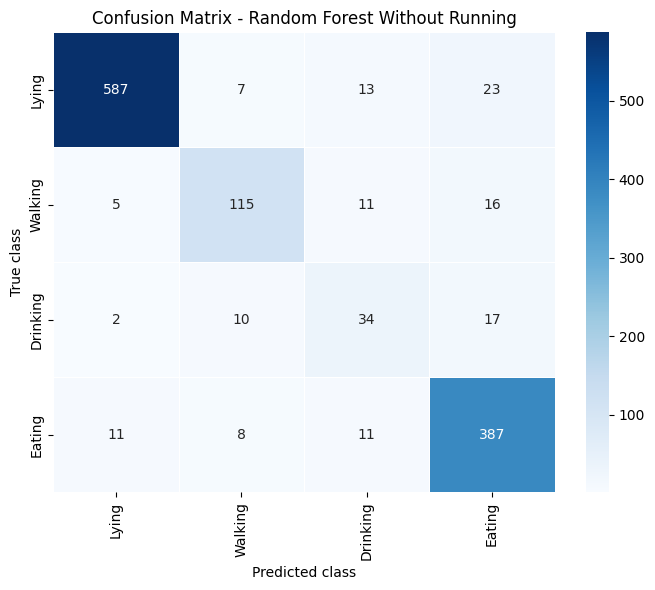

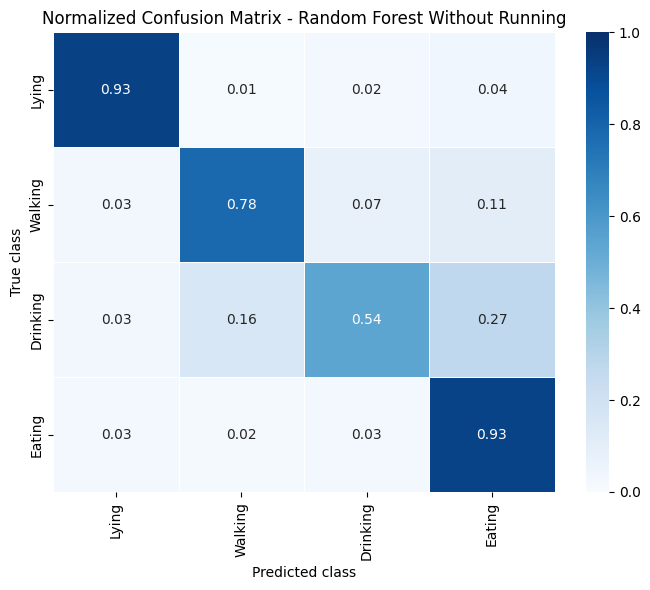


Arquivos gerados:
logits_sensor_rf_oof_treino_4classes_sem_correndo.csv
logits_sensor_rf_validacao_4classes_sem_correndo.csv
summary_rf_4classes_sem_correndo.csv
RandomForest_sensor_4classes_sem_correndo.joblib
confusion_matrix_rf_4classes_sem_correndo_absolute.png
confusion_matrix_rf_4classes_sem_correndo_normalized.png


In [34]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

# ============================================================
# RANDOM FOREST - 4 CLASSES WITHOUT RUNNING
# Training + OOF + synchronized test
# ============================================================

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

caminho_arquivo = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx"
arquivo_windows_validacao = "windows_validacao.txt"

# The running class will be removed
classes_modelo = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying", "Walking", "Drinking", "Eating"]

class_to_idx = {c: i for i, c in enumerate(classes_modelo)}
idx_to_class = {i: c for c, i in class_to_idx.items()}

print("Classes used in the experiment:")
print(class_to_idx)

# ------------------------------------------------------------
# 2. Carregar e padronizar dados
# ------------------------------------------------------------

df_raw = pd.read_excel(caminho_arquivo)

df_raw["atividade"] = df_raw["atividade"].astype(str).str.lower().str.strip()

df_raw["atividade"] = df_raw["atividade"].replace({
    "dormindo": "deitado",
    "deitadoac": "deitado",
    "inativo": "deitado"
})

# Remove running and keep only the four target classes
df_filtrado = df_raw[df_raw["atividade"].isin(classes_modelo)].copy()

print("\nInitial distribution after removing 'running':")
print(df_filtrado["atividade"].value_counts())

# ------------------------------------------------------------
# 3. Accelerometer feature extraction
# ------------------------------------------------------------

def extrair_features_expandido(grupo):
    ax = grupo["AX"].values.astype(float)
    ay = grupo["AY"].values.astype(float)
    az = grupo["AZ"].values.astype(float)

    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    if n == 0:
        return pd.Series(dtype=float)

    peaks, _ = find_peaks(vm, height=np.mean(vm))

    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    corr_xy = np.max(np.correlate(ax, ay, mode="full")) if n > 0 else 0
    corr_xz = np.max(np.correlate(ax, az, mode="full")) if n > 0 else 0
    corr_yz = np.max(np.correlate(ay, az, mode="full")) if n > 0 else 0

    if n >= 100:
        p3 = vm[70:]
    else:
        p3 = vm[int(0.7 * n):]

    diff_vm = np.diff(vm) if n > 1 else np.array([0.0])

    hist, _ = np.histogram(vm, bins=10, density=True)
    hist = hist + 1e-6
    entropy = -np.sum(hist * np.log(hist))

    zero_crossings = np.sum(np.diff(np.sign(diff_vm)) != 0)

    return pd.Series({
        "mean": np.mean(vm),
        "std": np.std(vm),
        "min": np.min(vm),
        "max": np.max(vm),
        "max_min_diff": np.max(vm) - np.min(vm),
        "median": np.median(vm),
        "peak_count": len(peaks),
        "skewness": skew(vm) if n > 2 else 0,
        "kurtosis": kurtosis(vm) if n > 3 else 0,
        "sma": np.sum(np.abs(vm)) / n,

        "AV": np.mean(fft_vals) if N_fft > 0 else 0,
        "DC": fft_vals[0] if N_fft > 0 else 0,
        "SD_f": np.std(fft_vals) if N_fft > 0 else 0,
        "MIN_f": np.min(fft_vals) if N_fft > 0 else 0,
        "MAX_f": np.max(fft_vals) if N_fft > 0 else 0,
        "RG_f": (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        "FQ": sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        "SQ": sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        "RMS_f": np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        "Median_f": np.median(fft_vals) if N_fft > 0 else 0,

        "max_corr_xy": corr_xy,
        "max_corr_xz": corr_xz,
        "max_corr_yz": corr_yz,

        "std_fim": np.std(p3) if len(p3) > 0 else 0,
        "rms_diff": np.sqrt(np.mean(diff_vm**2)),
        "tempo_pico": np.argmax(vm) / n,
        "entropy": entropy,
        "zero_crossings": zero_crossings
    })

print("\nExtracting features from accelerometer windows...")

df_features = (
    df_filtrado
    .groupby("window")
    .apply(extrair_features_expandido)
    .reset_index()
)

df_labels = (
    df_filtrado
    .groupby("window")["atividade"]
    .first()
    .reset_index()
)

df_final = pd.merge(df_features, df_labels, on="window")

df_final = df_final.replace([np.inf, -np.inf], np.nan).dropna()

print("\nFeatures extracted.")
print("Shape df_final:", df_final.shape)

print("\nFinal distribution by window:")
print(df_final["atividade"].value_counts())

# ------------------------------------------------------------
# 4. Synchronization with audio validation windows
# ------------------------------------------------------------

def extrair_id_da_window_audio(nome_arquivo):
    match = re.search(r"-j(\d+)", str(nome_arquivo))
    return int(match.group(1)) if match else None

with open(arquivo_windows_validacao, "r", encoding="utf-8") as f:
    nomes_audio = [line.strip() for line in f.readlines() if line.strip()]

ids_validacao = {
    extrair_id_da_window_audio(nome): nome
    for nome in nomes_audio
    if extrair_id_da_window_audio(nome) is not None
}

print("\nTotal windows in the audio validation TXT file:", len(ids_validacao))

df_final["id_numerico"] = df_final["window"].astype(int)

df_test = df_final[df_final["id_numerico"].isin(ids_validacao.keys())].copy()
df_train = df_final[~df_final["id_numerico"].isin(ids_validacao.keys())].copy()

df_test["nome_original_audio"] = df_test["id_numerico"].map(ids_validacao)

print("\nSynchronization completed.")
print("Synchronized test windows:", len(df_test))
print("Remaining training windows:", len(df_train))

print("\nTraining distribution:")
print(df_train["atividade"].value_counts())

print("\nSynchronized test distribution:")
print(df_test["atividade"].value_counts())

# ------------------------------------------------------------
# 5. Preparar X e y
# ------------------------------------------------------------

drop_train = ["window", "atividade", "id_numerico", "nome_original_audio"]
drop_train = [c for c in drop_train if c in df_train.columns]

drop_test = ["window", "atividade", "id_numerico", "nome_original_audio"]
drop_test = [c for c in drop_test if c in df_test.columns]

X_train = df_train.drop(columns=drop_train)
X_test = df_test.drop(columns=drop_test)

y_train = df_train["atividade"].map(class_to_idx).values.astype(int)
y_test = df_test["atividade"].map(class_to_idx).values.astype(int)

feature_cols = X_train.columns.tolist()

print("\nNumero de features:", len(feature_cols))
print(feature_cols)

# ------------------------------------------------------------
# 6. OOF do Random Forest no treino
# ------------------------------------------------------------

n_classes = len(classes_modelo)
oof_probs_rf = np.zeros((len(df_train), n_classes))

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("\nGerando predicoes OOF do Random Forest sem 'correndo'...")

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]

    y_tr = y_train[tr_idx]
    y_val = y_train[val_idx]

    rf_oof = RandomForestClassifier(
        n_estimators=500,
        max_depth=18,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42 + fold,
        n_jobs=-1,
        class_weight="balanced"
    )

    rf_oof.fit(X_tr, y_tr)

    probs_fold = rf_oof.predict_proba(X_val)

    probs_aligned = np.zeros((len(val_idx), n_classes))

    for j, cls_id in enumerate(rf_oof.classes_):
        probs_aligned[:, int(cls_id)] = probs_fold[:, j]

    oof_probs_rf[val_idx] = probs_aligned

    print(f"Fold {fold} concluido. Val size: {len(val_idx)}")

y_pred_rf_oof = oof_probs_rf.argmax(axis=1)

print("\n=== Random Forest OOF - 4 classes sem correndo ===")
print(classification_report(
    y_train,
    y_pred_rf_oof,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

df_rf_oof = pd.DataFrame(
    oof_probs_rf,
    columns=[f"prob_{classe}" for classe in classes_modelo]
)

df_rf_oof["window"] = df_train["window"].values
df_rf_oof["label_real"] = y_train

df_rf_oof = df_rf_oof[
    ["window", "label_real"] + [f"prob_{classe}" for classe in classes_modelo]
]

df_rf_oof.to_csv("logits_sensor_rf_oof_treino_4classes_sem_correndo.csv", index=False)

print("\nSalvo: logits_sensor_rf_oof_treino_4classes_sem_correndo.csv")

# ------------------------------------------------------------
# 7. Treinar RF final no treino e avaliar no teste sincronizado
# ------------------------------------------------------------

rf_final = RandomForestClassifier(
    n_estimators=500,
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

print("\nTreinando Random Forest final sem 'correndo'...")
rf_final.fit(X_train, y_train)

y_pred_test = rf_final.predict(X_test)
probs_test = rf_final.predict_proba(X_test)

# Alinhar probabilidades
probs_test_aligned = np.zeros((len(df_test), n_classes))
for j, cls_id in enumerate(rf_final.classes_):
    probs_test_aligned[:, int(cls_id)] = probs_test[:, j]

print("\n=== Random Forest synchronized test - 4 classes without running ===")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 8. Resumo
# ------------------------------------------------------------

df_summary_rf_4_no_running = pd.DataFrame([
    {
        "Model": "Random Forest 4 classes sem correndo - OOF",
        "Accuracy": accuracy_score(y_train, y_pred_rf_oof),
        "Macro_F1": f1_score(y_train, y_pred_rf_oof, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_train, y_pred_rf_oof, average="weighted", zero_division=0)
    },
    {
        "Model": "Random Forest 4 classes sem correndo - Test",
        "Accuracy": accuracy_score(y_test, y_pred_test),
        "Macro_F1": f1_score(y_test, y_pred_test, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_test, y_pred_test, average="weighted", zero_division=0)
    }
])

print("\n=== Summary ===")
display(df_summary_rf_4_no_running)

df_summary_rf_4_no_running.to_csv(
    "summary_rf_4classes_sem_correndo.csv",
    index=False
)

# ------------------------------------------------------------
# 9. Salvar probabilidades do teste para fusao
# ------------------------------------------------------------

df_probs_rf_test = pd.DataFrame(
    probs_test_aligned,
    columns=[f"prob_{classe}" for classe in classes_modelo]
)

df_probs_rf_test["window"] = df_test["nome_original_audio"].values
df_probs_rf_test["label_real"] = y_test

df_probs_rf_test = df_probs_rf_test[
    ["window", "label_real"] + [f"prob_{classe}" for classe in classes_modelo]
]

df_probs_rf_test.to_csv(
    "logits_sensor_rf_validacao_4classes_sem_correndo.csv",
    index=False
)

print("\nSalvo: logits_sensor_rf_validacao_4classes_sem_correndo.csv")

# ------------------------------------------------------------
# 10. Salvar modelo final
# ------------------------------------------------------------

joblib.dump(rf_final, "RandomForest_sensor_4classes_sem_correndo.joblib")

print("\nModel saved:")
print("RandomForest_sensor_4classes_sem_correndo.joblib")

# ------------------------------------------------------------
# 11. Matrizes de confusao
# ------------------------------------------------------------

# Absoluta
cm_abs = confusion_matrix(y_test, y_pred_test, labels=np.arange(n_classes))

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_abs,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    linewidths=0.5,
    linecolor="white"
)

plt.title("Confusion Matrix - Random Forest Without Running")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=90)
plt.yticks(rotation=90)
plt.tight_layout()
plt.savefig("confusion_matrix_rf_4classes_sem_correndo_absolute.png", dpi=300, bbox_inches="tight")
plt.show()

# Normalizada
cm_norm = cm_abs.astype(float) / cm_abs.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white"
)

plt.title("Normalized Confusion Matrix - Random Forest Without Running")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=90)
plt.yticks(rotation=90)
plt.tight_layout()
plt.savefig("confusion_matrix_rf_4classes_sem_correndo_normalized.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nArquivos gerados:")
print("logits_sensor_rf_oof_treino_4classes_sem_correndo.csv")
print("logits_sensor_rf_validacao_4classes_sem_correndo.csv")
print("summary_rf_4classes_sem_correndo.csv")
print("RandomForest_sensor_4classes_sem_correndo.joblib")
print("confusion_matrix_rf_4classes_sem_correndo_absolute.png")
print("confusion_matrix_rf_4classes_sem_correndo_normalized.png")

## Multi-Domain Random Forest with Circular Shift Augmentation

This cell implements the selected accelerometer model, referred to as MDRF-CS. It expands the accelerometer feature set, applies circular shift augmentation to improve minority-class representation, trains Random Forest models using stratified folds, and exports probabilities for later fusion. This model is the main accelerometer branch used in the final multimodal experiments.


Classes used:
{'deitado': 0, 'andando': 1, 'bebendo': 2, 'comendo': 3}

Classes with four-part circular shift:
['andando', 'bebendo']

Shifts used:
[1, 2, 3]

Initial distribution by rows:
atividade
deitado    397400
comendo    267700
andando     78300
bebendo     45800
Name: count, dtype: int64

Initial distribution by windows:
atividade
deitado    3974
comendo    2677
andando     783
bebendo     458
Name: count, dtype: int64

Windows in the original training set:
atividade
deitado    3344
comendo    2260
andando     636
bebendo     395
Name: count, dtype: int64

Windows in the original test set:
atividade
deitado    630
comendo    417
andando    147
bebendo     63
Name: count, dtype: int64

Final test set by windows:
atividade
deitado    630
comendo    417
andando    147
bebendo     63
Name: count, dtype: int64

Number of features used: 47
['mean', 'std', 'min', 'max', 'max_min_diff', 'median', 'peak_count', 'skewness', 'kurtosis', 'sma', 'AV', 'SD_f', 'MAX_f', 'RG_f', 'FQ', 'SQ', 'R

,Model,Accuracy,Macro_F1,Weighted_F1
0,RF + CShift4P + CombinedFeat - OOF,0.913941,0.841165,0.916196
1,RF + CShift4P + CombinedFeat - Test,0.917263,0.838628,0.919425
2,RF + CShift4P - Test,0.894988,0.797070,0.897477
3,RF baseline - Test,0.918059,0.834533,0.919357
4,RF balanced 700/class - Test,0.871122,0.771150,0.879017
5,RF + Moderate SMOTE - Test,0.892601,0.791527,0.893849
6,RF + SMOTE + Under - Test,0.885442,0.788005,0.890172



Files saved:
logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv
logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv
summary_rf_cshift4p_combfeat_4classes_sem_correndo.csv
RandomForest_CShift4P_CombinedFeat_4classes_sem_correndo.joblib


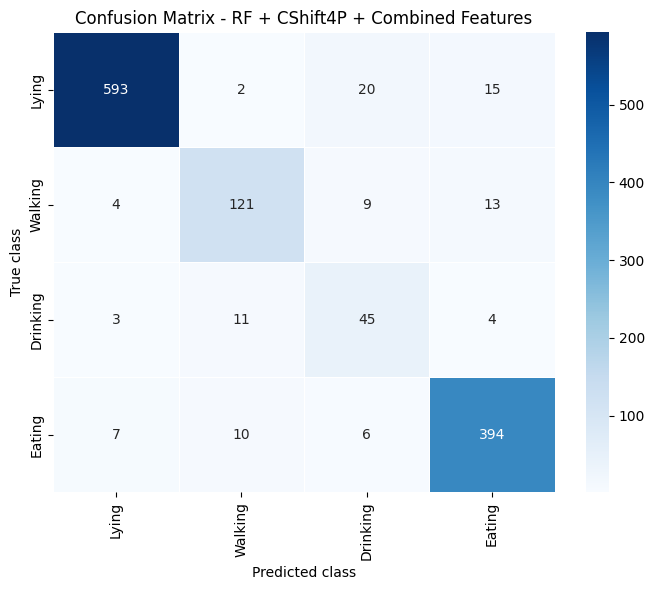

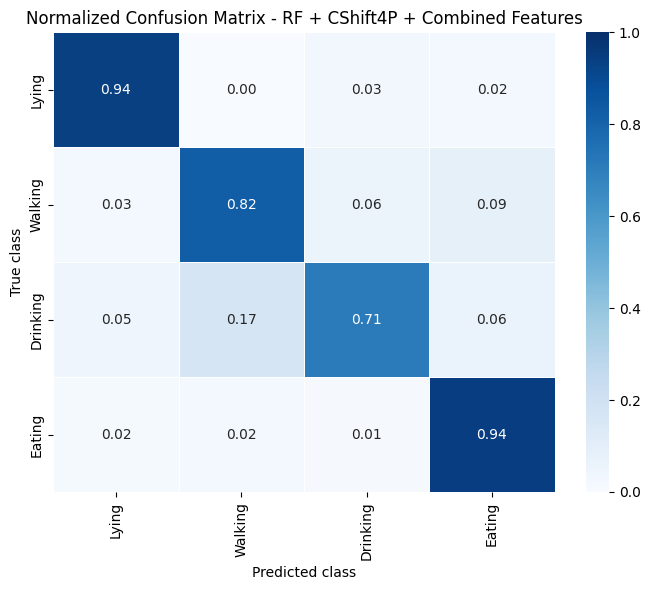

In [56]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# ============================================================
# RANDOM FOREST + COMBINED FEATURES + FOUR-PART CIRCULAR SHIFT
# 4 classes without running
# Without DC and without MIN_f
# Total: 47 features = 26 VM features + 21 axis-wise features
# ============================================================

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

caminho_arquivo = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx"
arquivo_windows_validacao = "windows_validacao.txt"

classes_modelo = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying", "Walking", "Drinking", "Eating"]

class_to_idx = {c: i for i, c in enumerate(classes_modelo)}
labels_order = [0, 1, 2, 3]

# Minority classes that will receive augmentation
classes_aug = ["andando", "bebendo"]

# Circular shift em 4 partes
# [A, B, C, D] -> [B, C, D, A]
# [A, B, C, D] -> [C, D, A, B]
# [A, B, C, D] -> [D, A, B, C]
SHIFT_PARTS_LIST = [1, 2, 3]

print("Classes used:")
print(class_to_idx)

print("\nClasses with four-part circular shift:")
print(classes_aug)

print("\nShifts used:")
print(SHIFT_PARTS_LIST)

# ------------------------------------------------------------
# 2. Carregar e padronizar dados crus
# ------------------------------------------------------------

df_raw = pd.read_excel(caminho_arquivo)

df_raw["atividade"] = df_raw["atividade"].astype(str).str.lower().str.strip()

df_raw["atividade"] = df_raw["atividade"].replace({
    "dormindo": "deitado",
    "deitadoac": "deitado",
    "inativo": "deitado"
})

# Remove the running class
df_raw = df_raw[df_raw["atividade"].isin(classes_modelo)].copy()

print("\nInitial distribution by rows:")
print(df_raw["atividade"].value_counts())

print("\nInitial distribution by windows:")
print(df_raw.groupby("window")["atividade"].first().value_counts())

# ------------------------------------------------------------
# 3. Split training data and synchronized test data
# ------------------------------------------------------------

def extrair_id_da_window_audio(nome_arquivo):
    match = re.search(r"-j(\d+)", str(nome_arquivo))
    return int(match.group(1)) if match else None

with open(arquivo_windows_validacao, "r", encoding="utf-8") as f:
    nomes_audio = [line.strip() for line in f.readlines() if line.strip()]

ids_validacao = {
    extrair_id_da_window_audio(nome): nome
    for nome in nomes_audio
    if extrair_id_da_window_audio(nome) is not None
}

df_raw["id_numerico"] = df_raw["window"].astype(int)

df_raw_test = df_raw[df_raw["id_numerico"].isin(ids_validacao.keys())].copy()
df_raw_train = df_raw[~df_raw["id_numerico"].isin(ids_validacao.keys())].copy()

print("\nWindows in the original training set:")
print(df_raw_train.groupby("window")["atividade"].first().value_counts())

print("\nWindows in the original test set:")
print(df_raw_test.groupby("window")["atividade"].first().value_counts())

# ------------------------------------------------------------
# 4. Data augmentation: circular shift em 4 partes
# ------------------------------------------------------------

def augment_circular_shift_4parts_group(grupo, shift_parts=1):
    """
    Divide a window em 4 partes e aplica deslocamento circular.

    Original:
        [A, B, C, D]

    shift_parts = 1:
        [B, C, D, A]

    shift_parts = 2:
        [C, D, A, B]

    shift_parts = 3:
        [D, A, B, C]
    """

    g = grupo.copy().reset_index(drop=True)
    n = len(g)

    if n < 8:
        return None

    if shift_parts not in [1, 2, 3]:
        return None

    cut1 = n // 4
    cut2 = n // 2
    cut3 = (3 * n) // 4

    part_A = g.iloc[:cut1].copy()
    part_B = g.iloc[cut1:cut2].copy()
    part_C = g.iloc[cut2:cut3].copy()
    part_D = g.iloc[cut3:].copy()

    parts = [part_A, part_B, part_C, part_D]

    shifted_parts = parts[shift_parts:] + parts[:shift_parts]

    g_aug = pd.concat(
        shifted_parts,
        axis=0,
        ignore_index=True
    )

    old_window = str(g["window"].iloc[0])
    classe = g["atividade"].iloc[0]

    g_aug["window"] = f"{old_window}_cshift4p_{shift_parts}"
    g_aug["id_numerico"] = -1
    g_aug["atividade"] = classe

    return g_aug


def aplicar_circular_shift_4parts_augmentation(
    df_train_raw,
    classes_aug,
    shift_parts_list=[1, 2, 3]
):
    """
    Apply four-part circular shift only to the training set
    and only to the specified classes.
    """

    aug_groups = []

    labels_by_window = df_train_raw.groupby("window")["atividade"].first()

    rare_windows = labels_by_window[
        labels_by_window.isin(classes_aug)
    ].index.tolist()

    print("\nTotal windows selected para circular shift em 4 partes:", len(rare_windows))

    for window in rare_windows:
        grupo = df_train_raw[df_train_raw["window"] == window].copy()

        for shift_parts in shift_parts_list:
            g_aug = augment_circular_shift_4parts_group(
                grupo,
                shift_parts=shift_parts
            )

            if g_aug is not None:
                aug_groups.append(g_aug)

    if len(aug_groups) == 0:
        return df_train_raw.copy()

    df_aug = pd.concat(aug_groups, ignore_index=True)

    df_train_aug = pd.concat(
        [df_train_raw.copy(), df_aug],
        ignore_index=True
    )

    return df_train_aug

# ------------------------------------------------------------
# 5. Extracao de features combinadas
# Without DC and without MIN_f
# ------------------------------------------------------------

def extrair_features_combinadas(grupo):
    """
    Combina:
      - Features sobre a magnitude vetorial VM.
      - Features por eixo AX, AY e AZ.

    Sem DC e sem MIN_f.
    Total: 47 features.
    """

    ax = grupo["AX"].values.astype(float)
    ay = grupo["AY"].values.astype(float)
    az = grupo["AZ"].values.astype(float)

    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    if n == 0:
        return pd.Series(dtype=float)

    # ----------------------------------------------------------
    # Bloco A — features sobre magnitude VM
    # ----------------------------------------------------------

    peaks, _ = find_peaks(vm, height=np.mean(vm))

    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    corr_xy = np.max(np.correlate(ax, ay, mode="full")) if n > 0 else 0
    corr_xz = np.max(np.correlate(ax, az, mode="full")) if n > 0 else 0
    corr_yz = np.max(np.correlate(ay, az, mode="full")) if n > 0 else 0

    p3 = vm[70:] if n >= 100 else vm[int(0.7 * n):]

    diff_vm = np.diff(vm) if n > 1 else np.array([0.0])

    hist, _ = np.histogram(vm, bins=10, density=True)
    hist = hist + 1e-6

    entropy = -np.sum(hist * np.log(hist))
    zero_crossings = np.sum(np.diff(np.sign(diff_vm)) != 0)

    features_estudo = {
        # Temporais sobre VM
        "mean": np.mean(vm),
        "std": np.std(vm),
        "min": np.min(vm),
        "max": np.max(vm),
        "max_min_diff": np.max(vm) - np.min(vm),
        "median": np.median(vm),
        "peak_count": len(peaks),
        "skewness": skew(vm) if n > 2 else 0,
        "kurtosis": kurtosis(vm) if n > 3 else 0,
        "sma": np.sum(np.abs(vm)) / n,

        # Frequency sobre VM
        "AV": np.mean(fft_vals) if N_fft > 0 else 0,
        "SD_f": np.std(fft_vals) if N_fft > 0 else 0,
        "MAX_f": np.max(fft_vals) if N_fft > 0 else 0,
        "RG_f": (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        "FQ": sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        "SQ": sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        "RMS_f": np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        "Median_f": np.median(fft_vals) if N_fft > 0 else 0,

        # Correlacao cruzada entre eixos
        "max_corr_xy": corr_xy,
        "max_corr_xz": corr_xz,
        "max_corr_yz": corr_yz,

        # Dinamicas
        "std_fim": np.std(p3) if len(p3) > 0 else 0,
        "rms_diff": np.sqrt(np.mean(diff_vm**2)),
        "tempo_pico": np.argmax(vm) / n,
        "entropy": entropy,
        "zero_crossings": zero_crossings,
    }

    # ----------------------------------------------------------
    # Bloco B — features por eixo
    # ----------------------------------------------------------

    features_jin = {}

    for nome_eixo, v in [("AX", ax), ("AY", ay), ("AZ", az)]:
        features_jin[f"j_mean_{nome_eixo}"] = np.mean(v)
        features_jin[f"j_std_{nome_eixo}"] = np.std(v)
        features_jin[f"j_min_{nome_eixo}"] = np.min(v)
        features_jin[f"j_max_{nome_eixo}"] = np.max(v)
        features_jin[f"j_range_{nome_eixo}"] = np.max(v) - np.min(v)
        features_jin[f"j_mean_abs_{nome_eixo}"] = np.mean(np.abs(v))
        features_jin[f"j_rms_{nome_eixo}"] = np.sqrt(np.mean(v**2))

    return pd.Series({**features_estudo, **features_jin})


def extrair_dataset_features(df_raw_in):
    df_features = (
        df_raw_in
        .groupby("window")
        .apply(extrair_features_combinadas)
        .reset_index()
    )

    df_labels = (
        df_raw_in
        .groupby("window")["atividade"]
        .first()
        .reset_index()
    )

    df_final = pd.merge(df_features, df_labels, on="window")
    df_final = df_final.replace([np.inf, -np.inf], np.nan).dropna()

    return df_final

# ------------------------------------------------------------
# 6. Create the original test set without augmentation
# ------------------------------------------------------------

df_test_feat = extrair_dataset_features(df_raw_test)

X_test = df_test_feat.drop(columns=["window", "atividade"])
y_test = df_test_feat["atividade"].map(class_to_idx).values.astype(int)

print("\nFinal test set by windows:")
print(df_test_feat["atividade"].value_counts())

feature_cols = X_test.columns.tolist()
print("\nNumber of features used:", len(feature_cols))
print(feature_cols)

# ------------------------------------------------------------
# 7. OOF com circular shift 4 partes within each fold
# ------------------------------------------------------------

df_train_windows = (
    df_raw_train
    .groupby("window")["atividade"]
    .first()
    .reset_index()
)

df_train_windows["label"] = df_train_windows["atividade"].map(class_to_idx).values.astype(int)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

n_classes = len(classes_modelo)

oof_probs_cshift4p_comb = np.zeros((len(df_train_windows), n_classes))
oof_y_true = df_train_windows["label"].values.copy()
oof_windows = df_train_windows["window"].values.copy()

print("\nGerando OOF com circular shift em 4 partes + features combinadas...")

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(df_train_windows["window"], df_train_windows["label"]),
    start=1
):
    train_windows = set(df_train_windows.iloc[tr_idx]["window"].values)
    val_windows = set(df_train_windows.iloc[val_idx]["window"].values)

    df_fold_train_raw = df_raw_train[df_raw_train["window"].isin(train_windows)].copy()
    df_fold_val_raw = df_raw_train[df_raw_train["window"].isin(val_windows)].copy()

    # Augmentation only in the fold training set
    df_fold_train_aug_raw = aplicar_circular_shift_4parts_augmentation(
        df_fold_train_raw,
        classes_aug=classes_aug,
        shift_parts_list=SHIFT_PARTS_LIST
    )

    print(f"\nFold {fold}")
    print("Original training set por windows:")
    print(df_fold_train_raw.groupby("window")["atividade"].first().value_counts())

    print("Training set after four-part circular shift by window:")
    print(df_fold_train_aug_raw.groupby("window")["atividade"].first().value_counts())

    # Extrair features
    df_fold_train_feat = extrair_dataset_features(df_fold_train_aug_raw)
    df_fold_val_feat = extrair_dataset_features(df_fold_val_raw)

    X_tr = df_fold_train_feat.drop(columns=["window", "atividade"])
    y_tr = df_fold_train_feat["atividade"].map(class_to_idx).values.astype(int)

    X_val = df_fold_val_feat.drop(columns=["window", "atividade"])
    y_val = df_fold_val_feat["atividade"].map(class_to_idx).values.astype(int)

    rf_fold = RandomForestClassifier(
        n_estimators=500,
        max_depth=18,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42 + fold,
        n_jobs=-1,
        class_weight="balanced"
    )

    rf_fold.fit(X_tr, y_tr)

    probs_val_raw = rf_fold.predict_proba(X_val)

    probs_val = np.zeros((len(df_fold_val_feat), n_classes))

    for j, cls_id in enumerate(rf_fold.classes_):
        probs_val[:, int(cls_id)] = probs_val_raw[:, j]

    # Colocar predicoes OOF na posicao correta
    val_pos_map = {
        window: pos
        for pos, window in zip(
            val_idx,
            df_train_windows.iloc[val_idx]["window"].values
        )
    }

    for local_i, window in enumerate(df_fold_val_feat["window"].values):
        global_pos = val_pos_map[window]
        oof_probs_cshift4p_comb[global_pos, :] = probs_val[local_i, :]

y_pred_oof_cshift4p_comb = oof_probs_cshift4p_comb.argmax(axis=1)

print("\n=== RF + Circular Shift 4 Parts + Combined Features - OOF ===")
print(classification_report(
    oof_y_true,
    y_pred_oof_cshift4p_comb,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 8. Train the final model with four-part circular shift
# ------------------------------------------------------------

df_train_cshift4p_raw = aplicar_circular_shift_4parts_augmentation(
    df_raw_train,
    classes_aug=classes_aug,
    shift_parts_list=SHIFT_PARTS_LIST
)

print("\nFull original training set by windows:")
print(df_raw_train.groupby("window")["atividade"].first().value_counts())

print("\nTreino completo after circular shift 4 partes por windows:")
print(df_train_cshift4p_raw.groupby("window")["atividade"].first().value_counts())

df_train_cshift4p_feat = extrair_dataset_features(df_train_cshift4p_raw)

X_train_cshift4p = df_train_cshift4p_feat.drop(columns=["window", "atividade"])
y_train_cshift4p = df_train_cshift4p_feat["atividade"].map(class_to_idx).values.astype(int)

rf_cshift4p_comb_final = RandomForestClassifier(
    n_estimators=500,
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

print("\nTreinando RF final com circular shift 4 partes + features combinadas...")

rf_cshift4p_comb_final.fit(X_train_cshift4p, y_train_cshift4p)

probs_test_raw = rf_cshift4p_comb_final.predict_proba(X_test)

probs_test_cshift4p_comb = np.zeros((len(df_test_feat), n_classes))

for j, cls_id in enumerate(rf_cshift4p_comb_final.classes_):
    probs_test_cshift4p_comb[:, int(cls_id)] = probs_test_raw[:, j]

y_pred_test_cshift4p_comb = probs_test_cshift4p_comb.argmax(axis=1)

print("\n=== RF + Circular Shift 4 Parts + Combined Features - synchronized test ===")
print(classification_report(
    y_test,
    y_pred_test_cshift4p_comb,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 9. Comparacao
# ------------------------------------------------------------

def summarize_model(name, y_true_eval, y_pred_eval):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true_eval, y_pred_eval),
        "Macro_F1": f1_score(y_true_eval, y_pred_eval, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_true_eval, y_pred_eval, average="weighted", zero_division=0)
    }

summary_rows = [
    summarize_model("RF + CShift4P + CombinedFeat - OOF", oof_y_true, y_pred_oof_cshift4p_comb),
    summarize_model("RF + CShift4P + CombinedFeat - Test", y_test, y_pred_test_cshift4p_comb)
]

if "y_pred_test_cshift4p" in globals():
    summary_rows.append(
        summarize_model("RF + CShift4P - Test", y_test, y_pred_test_cshift4p)
    )

if "y_pred_test" in globals():
    summary_rows.append(
        summarize_model("RF baseline - Test", y_test, y_pred_test)
    )

if "y_pred_test_bal700" in globals():
    summary_rows.append(
        summarize_model("RF balanced 700/class - Test", y_test, y_pred_test_bal700)
    )

if "y_pred_test_smote" in globals():
    summary_rows.append(
        summarize_model("RF + Moderate SMOTE - Test", y_test, y_pred_test_smote)
    )

if "y_pred_test_smote_under" in globals():
    summary_rows.append(
        summarize_model("RF + SMOTE + Under - Test", y_test, y_pred_test_smote_under)
    )

df_summary_rf_cshift4p_comb = pd.DataFrame(summary_rows)

print("\n=== Summary ===")
display(df_summary_rf_cshift4p_comb)

# ------------------------------------------------------------
# 10. Save probabilities and model
# ------------------------------------------------------------

df_oof_cshift4p_comb = pd.DataFrame(
    oof_probs_cshift4p_comb,
    columns=[f"prob_{c}" for c in classes_modelo]
)

df_oof_cshift4p_comb["window"] = oof_windows
df_oof_cshift4p_comb["label_real"] = oof_y_true

df_oof_cshift4p_comb = df_oof_cshift4p_comb[
    ["window", "label_real"] + [f"prob_{c}" for c in classes_modelo]
]

df_oof_cshift4p_comb.to_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv",
    index=False
)

df_test_cshift4p_comb = pd.DataFrame(
    probs_test_cshift4p_comb,
    columns=[f"prob_{c}" for c in classes_modelo]
)

window_to_audio_name = {
    k: v for k, v in ids_validacao.items()
}

df_test_feat["id_numerico"] = df_test_feat["window"].astype(int)
df_test_cshift4p_comb["window"] = df_test_feat["id_numerico"].map(window_to_audio_name).values

df_test_cshift4p_comb["label_real"] = y_test

df_test_cshift4p_comb = df_test_cshift4p_comb[
    ["window", "label_real"] + [f"prob_{c}" for c in classes_modelo]
]

df_test_cshift4p_comb.to_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv",
    index=False
)

df_summary_rf_cshift4p_comb.to_csv(
    "summary_rf_cshift4p_combfeat_4classes_sem_correndo.csv",
    index=False
)

joblib.dump(
    rf_cshift4p_comb_final,
    "RandomForest_CShift4P_CombinedFeat_4classes_sem_correndo.joblib"
)

print("\nFiles saved:")
print("logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv")
print("logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv")
print("summary_rf_cshift4p_combfeat_4classes_sem_correndo.csv")
print("RandomForest_CShift4P_CombinedFeat_4classes_sem_correndo.joblib")

# ------------------------------------------------------------
# 11. Test-set confusion matrices
# ------------------------------------------------------------

cm_abs = confusion_matrix(
    y_test,
    y_pred_test_cshift4p_comb,
    labels=np.arange(n_classes)
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_abs,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    linewidths=0.5,
    linecolor="white"
)

plt.title("Confusion Matrix - RF + CShift4P + Combined Features")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=90)
plt.yticks(rotation=90)
plt.tight_layout()

plt.savefig(
    "confusion_matrix_rf_cshift4p_combfeat_4classes_sem_correndo_absolute.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

cm_norm = cm_abs.astype(float) / cm_abs.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white"
)

plt.title("Normalized Confusion Matrix - RF + CShift4P + Combined Features")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=90)
plt.yticks(rotation=90)
plt.tight_layout()

plt.savefig(
    "confusion_matrix_rf_cshift4p_combfeat_4classes_sem_correndo_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Reference Baseline Based on Jin et al. (2023)

This cell reproduces a reference accelerometer baseline inspired by Jin et al. (2023), using a compact set of statistical features, an MLP classifier, and AD-BL-SMOTE-style balancing. The goal is to compare the proposed feature engineering and Random Forest strategy against a literature-based alternative under the same dataset conditions.


Features Jin et al.: 21
Features: ['mean_AX', 'std_AX', 'min_AX', 'max_AX', 'range_AX', 'mean_abs_AX', 'rms_AX', 'mean_AY', 'std_AY', 'min_AY', 'max_AY', 'range_AY', 'mean_abs_AY', 'rms_AY', 'mean_AZ', 'std_AZ', 'min_AZ', 'max_AZ', 'range_AZ', 'mean_abs_AZ', 'rms_AZ']

Test set by class:
atividade
deitado    630
comendo    417
andando    147
bebendo     63
Name: count, dtype: int64

Gerando OOF — MLP + AD-BL-SMOTE (Jin et al.)...


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


  Fold 1 — augmented training set: {np.int64(0): np.int64(2676), np.int64(1): np.int64(2676), np.int64(2): np.int64(2676), np.int64(3): np.int64(1808)}


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


  Fold 2 — augmented training set: {np.int64(0): np.int64(2675), np.int64(1): np.int64(2675), np.int64(2): np.int64(2675), np.int64(3): np.int64(1808)}


...

  Fold 4 — augmented training set: {np.int64(0): np.int64(2675), np.int64(1): np.int64(2675), np.int64(2): np.int64(2675), np.int64(3): np.int64(1808)}


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


  Fold 5 — augmented training set: {np.int64(0): np.int64(2675), np.int64(1): np.int64(2675), np.int64(2): np.int64(2675), np.int64(3): np.int64(1808)}

=== Jin et al. MLP + AD-BL-SMOTE — OOF ===
              precision    recall  f1-score   support

     deitado     0.9642    0.9261    0.9448      3344
     andando     0.6283    0.7972    0.7027       636
     bebendo     0.5307    0.7215    0.6116       395
     comendo     0.9341    0.8593    0.8951      2260

    accuracy                         0.8788      6635
   macro avg     0.7643    0.8260    0.7886      6635
weighted avg     0.8959    0.8788    0.8848      6635


Treinando MLP final (Jin et al.)...


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(



=== Jin et al. MLP + AD-BL-SMOTE — Test ===
              precision    recall  f1-score   support

     deitado     0.9800    0.9333    0.9561       630
     andando     0.7262    0.8299    0.7746       147
     bebendo     0.5000    0.8413    0.6272        63
     comendo     0.9556    0.8777    0.9150       417

    accuracy                         0.8982      1257
   macro avg     0.7905    0.8706    0.8182      1257
weighted avg     0.9182    0.8982    0.9048      1257


=== Comparison table ===
         Modelo  deitado  andando  bebendo  comendo  Accuracy  Macro_F1  Weighted_F1
  Jin MLP — OOF    94.48    70.27    61.16    89.51     87.88     78.86        88.48
Jin MLP — Test    95.61    77.46    62.72    91.50     89.82     81.82        90.48

Note: add the RF rows for the complete comparison.

Files saved:
  logits_jin_mlp_adblsmote_oof_4classes.csv
  logits_jin_mlp_adblsmote_validacao_4classes.csv
  summary_jin_mlp_adblsmote_4classes.csv


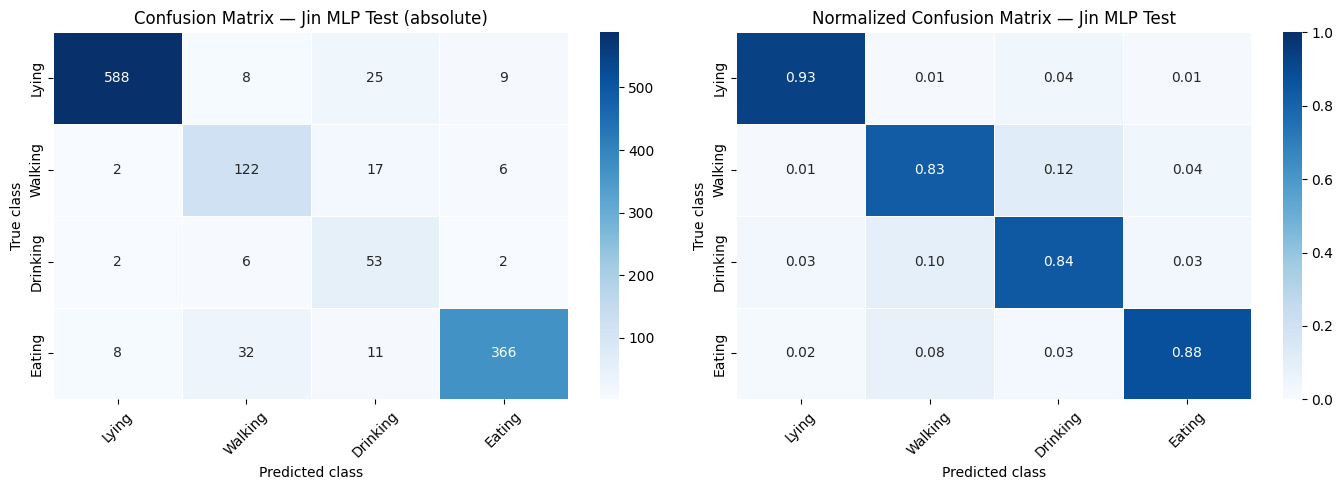

Figure saved: confusion_matrix_jin_mlp_test.png


In [44]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# ============================================================
# REPLICATION OF JIN ET AL. (2023)
# Features: 21 (mean, std, min, max, range, mean_abs, RMS
#           for each X, Y, and Z axis)
# Model  : MLP — 2 hidden layers (28, 28), ReLU, SGD
# Balancing: AD-BL-SMOTE (same as the RF version)
# Objective: fair comparison with the RF model of this study
# ============================================================

# ============================================================
# AD-BL-SMOTE  (identical to the RF version — do not change)
# ============================================================

class ADBLSMOTE:
    def __init__(self, k=5, oversampling_rate=None,
                 minority_classes=None, random_state=42):
        self.k = k
        self.oversampling_rate = oversampling_rate
        self.minority_classes  = minority_classes
        self.random_state      = random_state

    def fit_resample(self, X, y):
        rng = np.random.RandomState(self.random_state)
        X = np.array(X, dtype=float)
        y = np.array(y)

        classes, counts   = np.unique(y, return_counts=True)
        majority_count    = int(counts.max())
        majority_class    = classes[counts.argmax()]

        minority_classes = (
            [c for c in classes if c != majority_class]
            if self.minority_classes is None
            else list(self.minority_classes)
        )

        X_aug_list = [X.copy()]
        y_aug_list = [y.copy()]

        k_eff = min(self.k, len(X) - 1)
        knn_all = NearestNeighbors(n_neighbors=k_eff + 1, n_jobs=-1)
        knn_all.fit(X)
        dist_all, idx_all = knn_all.kneighbors(X)
        dist_all = dist_all[:, 1:]
        idx_all  = idx_all[:, 1:]

        for min_class in minority_classes:
            mask_min       = (y == min_class)
            X_min          = X[mask_min]
            idx_min_global = np.where(mask_min)[0]
            n = len(X_min)
            if n < 2:
                continue

            alpha = majority_count / n
            r = (alpha if self.oversampling_rate is None
                 else max(1.0, min(self.oversampling_rate, alpha)))
            S = int(n * (r - 1))
            if S <= 0:
                continue

            danger_local, weights = [], []
            for local_i, global_i in enumerate(idx_min_global):
                nb_labels = y[idx_all[global_i]]
                k2 = int(np.sum(nb_labels != min_class))
                k1 = k_eff
                if k2 == k1:
                    continue
                if k2 > k1 // 2:
                    min_nb_mask = (nb_labels == min_class)
                    d1 = dist_all[global_i][min_nb_mask].sum() or 1e-9
                    w  = k1 * (d1 / max(k1 - k2, 1))
                    danger_local.append(local_i)
                    weights.append(w)

            if not danger_local:
                danger_local = list(range(n))
                weights = [1.0] * n

            weights      = np.array(weights, dtype=float)
            if weights.sum() == 0:
                weights[:] = 1.0
            weights_norm = weights / weights.sum()

            n_per = np.round(weights_norm * S).astype(int)
            diff  = S - n_per.sum()
            order = np.argsort(-weights_norm)
            for i in range(abs(diff)):
                idx_adj = order[i % len(order)]
                n_per[idx_adj] += (1 if diff > 0 else -1)
                n_per[idx_adj]  = max(0, n_per[idx_adj])

            k_min = min(self.k, n - 1)
            knn_min = NearestNeighbors(n_neighbors=k_min + 1, n_jobs=-1)
            knn_min.fit(X_min)
            _, idx_min_nb = knn_min.kneighbors(X_min)
            idx_min_nb = idx_min_nb[:, 1:]

            X_new = []
            for pos, local_i in enumerate(danger_local):
                n_gen = n_per[pos]
                if n_gen == 0 or len(idx_min_nb[local_i]) == 0:
                    continue
                x_b = X_min[local_i]
                for _ in range(n_gen):
                    nn  = rng.choice(idx_min_nb[local_i])
                    lam = rng.uniform(0, 1)
                    X_new.append(x_b + lam * (X_min[nn] - x_b))

            if X_new:
                X_aug_list.append(np.array(X_new))
                y_aug_list.append(np.full(len(X_new), min_class))

        return np.vstack(X_aug_list), np.concatenate(y_aug_list)


# ============================================================
# Features — 21 atributos de Jin et al. (2023)
# "the values of the three axes (X, Y, Z) and the six moving
#  summary statistics calculated for each axis"
# Para cada eixo: mean, std, min, max, range, mean_abs, RMS
# 7 features × 3 eixos = 21 features
# ============================================================

def extrair_features_jin(grupo):
    """
    21 features conforme Jin et al. (2023):
    para cada eixo (AX, AY, AZ): mean, std, min, max,
    range (max-min), mean_abs, RMS  →  7 × 3 = 21
    """
    resultado = {}
    for eixo in ["AX", "AY", "AZ"]:
        v = grupo[eixo].values.astype(float)
        n = len(v)
        if n == 0:
            for stat in ["mean","std","min","max","range","mean_abs","rms"]:
                resultado[f"{stat}_{eixo}"] = 0.0
            continue
        resultado[f"mean_{eixo}"]     = np.mean(v)
        resultado[f"std_{eixo}"]      = np.std(v)
        resultado[f"min_{eixo}"]      = np.min(v)
        resultado[f"max_{eixo}"]      = np.max(v)
        resultado[f"range_{eixo}"]    = np.max(v) - np.min(v)
        resultado[f"mean_abs_{eixo}"] = np.mean(np.abs(v))
        resultado[f"rms_{eixo}"]      = np.sqrt(np.mean(v**2))
    return pd.Series(resultado)


def extrair_dataset_jin(df_raw_in):
    df_feat = (
        df_raw_in
        .groupby("window")
        .apply(extrair_features_jin)
        .reset_index()
    )
    df_lbl = (
        df_raw_in.groupby("window")["atividade"]
        .first().reset_index()
    )
    df_final = pd.merge(df_feat, df_lbl, on="window")
    df_final = df_final.replace([np.inf, -np.inf], np.nan).dropna()
    return df_final


# ============================================================
# Settings (same as in the RF script)
# ============================================================

caminho_arquivo           = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx"
arquivo_windows_validacao = "windows_validacao.txt"

classes_modelo         = ["deitado", "andando", "bebendo", "comendo"]
class_names_en         = ["Lying",   "Walking", "Drinking","Eating"]
class_to_idx           = {c: i for i, c in enumerate(classes_modelo)}
classes_minority_smote = ["andando", "bebendo"]

ADBL_K                 = 5
ADBL_OVERSAMPLING_RATE = None

# Arquitetura MLP — Jin et al. (2023) Tabela 3
# hidden layers: 28, 28  |  ReLU  |  SGD momentum  |  120 epochs
MLP_HIDDEN      = (28, 28)
MLP_LR          = 0.01
MLP_MOMENTUM    = 0.9
MLP_MAX_ITER    = 120
MLP_ACTIVATION  = "relu"

# ============================================================
# Carregar dados
# ============================================================

df_raw = pd.read_excel(caminho_arquivo)
df_raw["atividade"] = df_raw["atividade"].astype(str).str.lower().str.strip()
df_raw["atividade"] = df_raw["atividade"].replace({
    "dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"
})
df_raw = df_raw[df_raw["atividade"].isin(classes_modelo)].copy()

# ============================================================
# Split training/test data (same split as in the RF script)
# ============================================================

def extrair_id_window_audio(nome):
    m = re.search(r"-j(\d+)", str(nome))
    return int(m.group(1)) if m else None

with open(arquivo_windows_validacao, "r", encoding="utf-8") as f:
    nomes_audio = [l.strip() for l in f if l.strip()]

ids_validacao = {
    extrair_id_window_audio(n): n
    for n in nomes_audio if extrair_id_window_audio(n) is not None
}

df_raw["id_numerico"] = df_raw["window"].astype(int)
df_raw_test  = df_raw[df_raw["id_numerico"].isin(ids_validacao)].copy()
df_raw_train = df_raw[~df_raw["id_numerico"].isin(ids_validacao)].copy()

# ============================================================
# Features e sets
# ============================================================

df_test_feat = extrair_dataset_jin(df_raw_test)
feature_cols = [c for c in df_test_feat.columns
                if c not in ("window", "atividade")]

X_test = df_test_feat[feature_cols].values
y_test = df_test_feat["atividade"].map(class_to_idx).values.astype(int)

print(f"Features Jin et al.: {len(feature_cols)}")
print("Features:", feature_cols)
print("\nTest set by class:")
print(df_test_feat["atividade"].value_counts())

# ============================================================
# OOF com AD-BL-SMOTE + MLP
# ============================================================

df_train_windows = (
    df_raw_train.groupby("window")["atividade"]
    .first().reset_index()
)
df_train_windows["label"] = df_train_windows["atividade"].map(class_to_idx).astype(int)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
n_classes = len(classes_modelo)

oof_probs   = np.zeros((len(df_train_windows), n_classes))
oof_y_true  = df_train_windows["label"].values.copy()
oof_windows = df_train_windows["window"].values.copy()

print("\nGerando OOF — MLP + AD-BL-SMOTE (Jin et al.)...")

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(df_train_windows["window"], df_train_windows["label"]),
    start=1
):
    train_windows = set(df_train_windows.iloc[tr_idx]["window"].values)
    val_windows   = set(df_train_windows.iloc[val_idx]["window"].values)

    df_fold_tr  = extrair_dataset_jin(
        df_raw_train[df_raw_train["window"].isin(train_windows)])
    df_fold_val = extrair_dataset_jin(
        df_raw_train[df_raw_train["window"].isin(val_windows)])

    X_tr   = df_fold_tr[feature_cols].values
    y_tr   = df_fold_tr["atividade"].map(class_to_idx).values.astype(int)
    X_val  = df_fold_val[feature_cols].values
    y_val  = df_fold_val["atividade"].map(class_to_idx).values.astype(int)

    # AD-BL-SMOTE in feature space
    minority_idx = [class_to_idx[c] for c in classes_minority_smote]
    adbl = ADBLSMOTE(k=ADBL_K, oversampling_rate=ADBL_OVERSAMPLING_RATE,
                     minority_classes=minority_idx, random_state=42 + fold)
    X_tr_aug, y_tr_aug = adbl.fit_resample(X_tr, y_tr)

    # Fold-wise normalization (MLP is scale-sensitive)
    scaler = StandardScaler()
    X_tr_aug = scaler.fit_transform(X_tr_aug)
    X_val    = scaler.transform(X_val)

    mlp = MLPClassifier(
        hidden_layer_sizes=MLP_HIDDEN,
        activation=MLP_ACTIVATION,
        solver="sgd",
        learning_rate_init=MLP_LR,
        momentum=MLP_MOMENTUM,
        max_iter=MLP_MAX_ITER,
        random_state=42 + fold,
        early_stopping=False
    )
    mlp.fit(X_tr_aug, y_tr_aug)

    probs_val = mlp.predict_proba(X_val)
    # Garantir ordem das colunas
    probs_val_ord = np.zeros((len(X_val), n_classes))
    for j, cls_id in enumerate(mlp.classes_):
        probs_val_ord[:, int(cls_id)] = probs_val[:, j]

    val_pos_map = {
        window: pos
        for pos, window in zip(val_idx, df_train_windows.iloc[val_idx]["window"].values)
    }
    for local_i, window in enumerate(df_fold_val["window"].values):
        global_pos = val_pos_map[window]
        oof_probs[global_pos, :] = probs_val_ord[local_i, :]

    print(f"  Fold {fold} — augmented training set: "
          f"{dict(zip(*np.unique(y_tr_aug, return_counts=True)))}")

y_pred_oof = oof_probs.argmax(axis=1)
print("\n=== Jin et al. MLP + AD-BL-SMOTE — OOF ===")
print(classification_report(
    oof_y_true, y_pred_oof,
    target_names=classes_modelo, digits=4, zero_division=0
))

# ============================================================
# Modelo final
# ============================================================

df_train_full = extrair_dataset_jin(df_raw_train)
X_train_full  = df_train_full[feature_cols].values
y_train_full  = df_train_full["atividade"].map(class_to_idx).values.astype(int)

adbl_final = ADBLSMOTE(
    k=ADBL_K, oversampling_rate=ADBL_OVERSAMPLING_RATE,
    minority_classes=[class_to_idx[c] for c in classes_minority_smote],
    random_state=42
)
X_train_aug, y_train_aug = adbl_final.fit_resample(X_train_full, y_train_full)

scaler_final = StandardScaler()
X_train_aug_sc = scaler_final.fit_transform(X_train_aug)
X_test_sc      = scaler_final.transform(X_test)

mlp_final = MLPClassifier(
    hidden_layer_sizes=MLP_HIDDEN,
    activation=MLP_ACTIVATION,
    solver="sgd",
    learning_rate_init=MLP_LR,
    momentum=MLP_MOMENTUM,
    max_iter=MLP_MAX_ITER,
    random_state=42,
    early_stopping=False
)
print("\nTreinando MLP final (Jin et al.)...")
mlp_final.fit(X_train_aug_sc, y_train_aug)

probs_test = np.zeros((len(X_test_sc), n_classes))
for j, cls_id in enumerate(mlp_final.classes_):
    probs_test[:, int(cls_id)] = mlp_final.predict_proba(X_test_sc)[:, j]
y_pred_test = probs_test.argmax(axis=1)

print("\n=== Jin et al. MLP + AD-BL-SMOTE — Test ===")
print(classification_report(
    y_test, y_pred_test,
    target_names=classes_modelo, digits=4, zero_division=0
))

# ============================================================
# Comparison table consolidada
# ============================================================

def f1_por_classe(y_true_e, y_pred_e, n_cls):
    report = classification_report(
        y_true_e, y_pred_e,
        labels=list(range(n_cls)),
        target_names=classes_modelo,
        output_dict=True, zero_division=0
    )
    row = {c: round(report[c]["f1-score"] * 100, 2) for c in classes_modelo}
    row["Accuracy"]    = round(report["accuracy"] * 100, 2)
    row["Macro_F1"]    = round(report["macro avg"]["f1-score"] * 100, 2)
    row["Weighted_F1"] = round(report["weighted avg"]["f1-score"] * 100, 2)
    return row

rows_comp = []

# Jin et al. MLP
row_jin_oof  = f1_por_classe(oof_y_true, y_pred_oof, n_classes)
row_jin_test = f1_por_classe(y_test,     y_pred_test, n_classes)
row_jin_oof["Modelo"]  = "Jin MLP — OOF"
row_jin_test["Modelo"] = "Jin MLP — Test"
rows_comp += [row_jin_oof, row_jin_test]

df_comp = pd.DataFrame(rows_comp)
cols_order = ["Modelo"] + classes_modelo + ["Accuracy","Macro_F1","Weighted_F1"]
df_comp = df_comp[cols_order]

print("\n=== Comparison table ===")
print(df_comp.to_string(index=False))
print("\nNote: add the RF rows for the complete comparison.")

# ============================================================
# Save outputs
# ============================================================

df_oof_out = pd.DataFrame(oof_probs, columns=[f"prob_{c}" for c in classes_modelo])
df_oof_out["window"]     = oof_windows
df_oof_out["label_real"] = oof_y_true
df_oof_out.to_csv("logits_jin_mlp_adblsmote_oof_4classes.csv", index=False)

df_test_out = pd.DataFrame(probs_test, columns=[f"prob_{c}" for c in classes_modelo])
df_test_feat["id_numerico"] = df_test_feat["window"].astype(int)
df_test_out["window"]     = df_test_feat["id_numerico"].map(ids_validacao).values
df_test_out["label_real"] = y_test
df_test_out.to_csv("logits_jin_mlp_adblsmote_validacao_4classes.csv", index=False)

df_comp.to_csv("summary_jin_mlp_adblsmote_4classes.csv", index=False)

print("\nFiles saved:")
for f in [
    "logits_jin_mlp_adblsmote_oof_4classes.csv",
    "logits_jin_mlp_adblsmote_validacao_4classes.csv",
    "summary_jin_mlp_adblsmote_4classes.csv"
]:
    print(" ", f)

# ============================================================
# Confusion matrix — Test
# ============================================================

cm     = confusion_matrix(y_test, y_pred_test, labels=np.arange(n_classes))
cm_n   = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_n   = np.nan_to_num(cm_n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, fmt, title in zip(
    axes,
    [cm, cm_n],
    ["d", ".2f"],
    ["Confusion Matrix — Jin MLP Test (absolute)",
     "Normalized Confusion Matrix — Jin MLP Test"]
):
    sns.heatmap(
        data, annot=True, fmt=fmt, cmap="Blues",
        xticklabels=class_names_en, yticklabels=class_names_en,
        vmin=(0 if fmt==".2f" else None),
        vmax=(1 if fmt==".2f" else None),
        linewidths=0.5, linecolor="white", ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("confusion_matrix_jin_mlp_test.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved: confusion_matrix_jin_mlp_test.png")

## Random Forest with Combined Features and AD-BL-SMOTE

This cell evaluates whether the proposed accelerometer feature set benefits from AD-BL-SMOTE balancing. It combines richer engineered features with a balancing strategy originally associated with the reference baseline. This comparison helps separate the effects of feature design, classifier choice, and class balancing.


Study features : 28
Features Jin et al.: 21
Features combinadas: 47

Test set by class:
atividade
deitado    630
comendo    417
andando    147
bebendo     63
Name: count, dtype: int64

Gerando OOF — RF + features combinadas + AD-BL-SMOTE...
  Fold 1 — aug: {np.int64(0): np.int64(2676), np.int64(1): np.int64(2676), np.int64(2): np.int64(2676), np.int64(3): np.int64(1808)}
  Fold 2 — aug: {np.int64(0): np.int64(2675), np.int64(1): np.int64(2675), np.int64(2): np.int64(2675), np.int64(3): np.int64(1808)}
  Fold 3 — aug: {np.int64(0): np.int64(2675), np.int64(1): np.int64(2675), np.int64(2): np.int64(2675), np.int64(3): np.int64(1808)}
  Fold 4 — aug: {np.int64(0): np.int64(2675), np.int64(1): np.int64(2675), np.int64(2): np.int64(2675), np.int64(3): np.int64(1808)}
  Fold 5 — aug: {np.int64(0): np.int64(2675), np.int64(1): np.int64(2675), np.int64(2): np.int64(2675), np.int64(3): np.int64(1808)}

=== RF + features combinadas — OOF ===
              precision    recall  f1-score   support


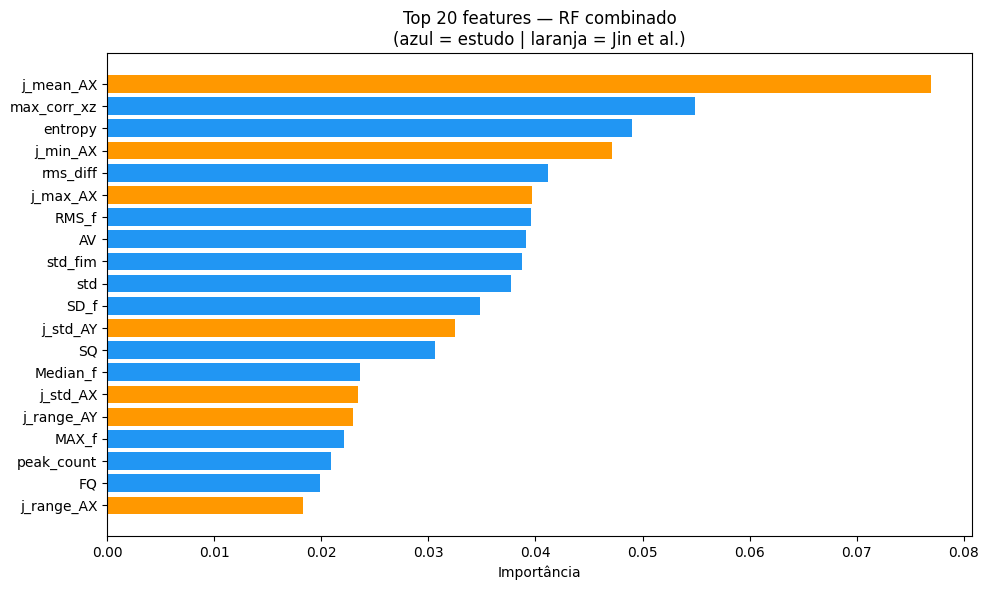

Figure saved: feature_importance_rf_combinado.png

Files saved:
  logits_rf_combinado_oof_4classes.csv
  logits_rf_combinado_validacao_4classes.csv
  RandomForest_combinado_4classes.joblib
  feature_importance_rf_combinado.png


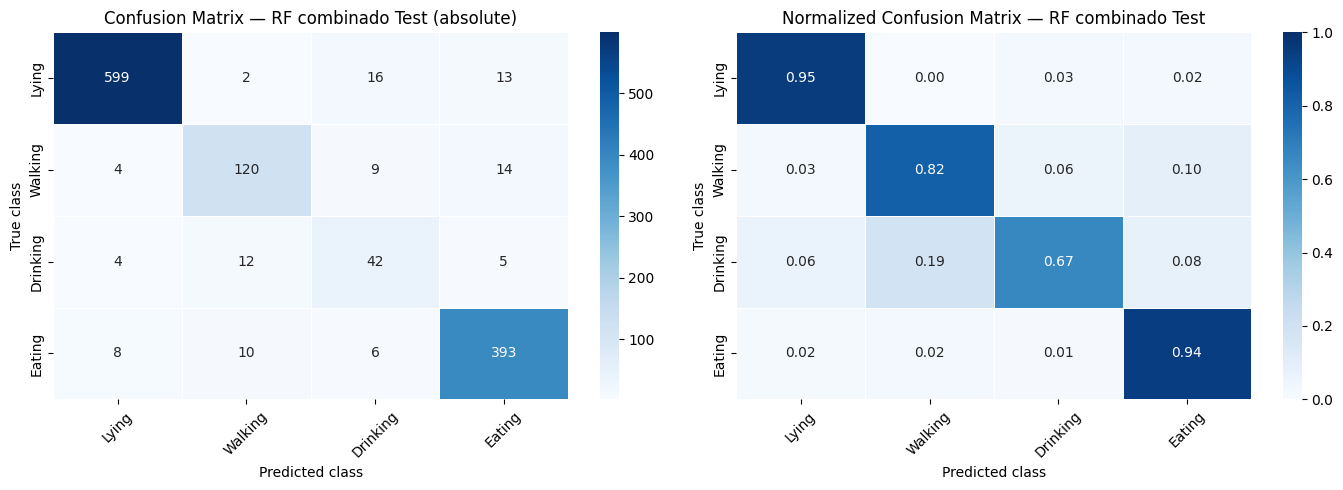

Figure saved: confusion_matrix_rf_combinado_test.png


In [51]:
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# ============================================================
# RF  +  features combinadas  +  AD-BL-SMOTE
#
# Study features (28): computed from the VM magnitude
#   → invariant to sensor orientation
# Jin et al. features (21): computed per axis (AX, AY, AZ)
#   → capture directional information
# Total: 49 non-overlapping features
# ============================================================

# ============================================================
# AD-BL-SMOTE  (identica as versoes anteriores)
# ============================================================

class ADBLSMOTE:
    def __init__(self, k=5, oversampling_rate=None,
                 minority_classes=None, random_state=42):
        self.k = k
        self.oversampling_rate = oversampling_rate
        self.minority_classes  = minority_classes
        self.random_state      = random_state

    def fit_resample(self, X, y):
        rng = np.random.RandomState(self.random_state)
        X = np.array(X, dtype=float)
        y = np.array(y)

        classes, counts = np.unique(y, return_counts=True)
        majority_count  = int(counts.max())
        majority_class  = classes[counts.argmax()]

        minority_classes = (
            [c for c in classes if c != majority_class]
            if self.minority_classes is None
            else list(self.minority_classes)
        )

        X_aug_list = [X.copy()]
        y_aug_list = [y.copy()]

        k_eff = min(self.k, len(X) - 1)
        knn_all = NearestNeighbors(n_neighbors=k_eff + 1, n_jobs=-1)
        knn_all.fit(X)
        dist_all, idx_all = knn_all.kneighbors(X)
        dist_all = dist_all[:, 1:]
        idx_all  = idx_all[:, 1:]

        for min_class in minority_classes:
            mask_min       = (y == min_class)
            X_min          = X[mask_min]
            idx_min_global = np.where(mask_min)[0]
            n = len(X_min)
            if n < 2:
                continue

            alpha = majority_count / n
            r = (alpha if self.oversampling_rate is None
                 else max(1.0, min(self.oversampling_rate, alpha)))
            S = int(n * (r - 1))
            if S <= 0:
                continue

            danger_local, weights = [], []
            for local_i, global_i in enumerate(idx_min_global):
                nb_labels = y[idx_all[global_i]]
                k2 = int(np.sum(nb_labels != min_class))
                k1 = k_eff
                if k2 == k1:
                    continue
                if k2 > k1 // 2:
                    min_nb_mask = (nb_labels == min_class)
                    d1 = dist_all[global_i][min_nb_mask].sum() or 1e-9
                    w  = k1 * (d1 / max(k1 - k2, 1))
                    danger_local.append(local_i)
                    weights.append(w)

            if not danger_local:
                danger_local = list(range(n))
                weights = [1.0] * n

            weights      = np.array(weights, dtype=float)
            if weights.sum() == 0:
                weights[:] = 1.0
            weights_norm = weights / weights.sum()

            n_per = np.round(weights_norm * S).astype(int)
            diff  = S - n_per.sum()
            order = np.argsort(-weights_norm)
            for i in range(abs(diff)):
                idx_adj = order[i % len(order)]
                n_per[idx_adj] += (1 if diff > 0 else -1)
                n_per[idx_adj]  = max(0, n_per[idx_adj])

            k_min = min(self.k, n - 1)
            knn_min = NearestNeighbors(n_neighbors=k_min + 1, n_jobs=-1)
            knn_min.fit(X_min)
            _, idx_min_nb = knn_min.kneighbors(X_min)
            idx_min_nb = idx_min_nb[:, 1:]

            X_new = []
            for pos, local_i in enumerate(danger_local):
                n_gen = n_per[pos]
                if n_gen == 0 or len(idx_min_nb[local_i]) == 0:
                    continue
                x_b = X_min[local_i]
                for _ in range(n_gen):
                    nn  = rng.choice(idx_min_nb[local_i])
                    lam = rng.uniform(0, 1)
                    X_new.append(x_b + lam * (X_min[nn] - x_b))

            if X_new:
                X_aug_list.append(np.array(X_new))
                y_aug_list.append(np.full(len(X_new), min_class))

        return np.vstack(X_aug_list), np.concatenate(y_aug_list)


# ============================================================
# Features combinadas
# ============================================================

def extrair_features_combinadas(grupo):
    """
    Combina:
      - Study features (28): sobre a magnitude VM — invariantes
        a collar orientation.
      - Jin et al. features (21): por eixo (AX, AY, AZ) — capturam
        directional information absent from the magnitude.
    Total: 49 non-overlapping features.
    """
    ax = grupo["AX"].values.astype(float)
    ay = grupo["AY"].values.astype(float)
    az = grupo["AZ"].values.astype(float)
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n  = len(vm)

    if n == 0:
        return pd.Series(dtype=float)

    # ----------------------------------------------------------
    # Bloco A — features do estudo (magnitude VM)
    # ----------------------------------------------------------
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    fft_vals  = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f  = np.sort(fft_vals)
    N_fft     = len(fft_vals)

    corr_xy = np.max(np.correlate(ax, ay, mode="full"))
    corr_xz = np.max(np.correlate(ax, az, mode="full"))
    corr_yz = np.max(np.correlate(ay, az, mode="full"))

    p3      = vm[70:] if n >= 100 else vm[int(0.7 * n):]
    diff_vm = np.diff(vm) if n > 1 else np.array([0.0])
    hist, _ = np.histogram(vm, bins=10, density=True)
    hist   += 1e-6
    entropy = -np.sum(hist * np.log(hist))
    zero_crossings = np.sum(np.diff(np.sign(diff_vm)) != 0)

    features_estudo = {
        # temporal
        "mean":           np.mean(vm),
        "std":            np.std(vm),
        "min":            np.min(vm),
        "max":            np.max(vm),
        "max_min_diff":   np.max(vm) - np.min(vm),
        "median":         np.median(vm),
        "peak_count":     len(peaks),
        "skewness":       skew(vm)     if n > 2 else 0,
        "kurtosis":       kurtosis(vm) if n > 3 else 0,
        "sma":            np.sum(np.abs(vm)) / n,
        # frequency
        "AV":             np.mean(fft_vals)  if N_fft > 0 else 0,
        "SD_f":           np.std(fft_vals)   if N_fft > 0 else 0,
        "MAX_f":          np.max(fft_vals)   if N_fft > 0 else 0,
        "RG_f":           (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        "FQ":             sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        "SQ":             sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        "RMS_f":          np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        "Median_f":       np.median(fft_vals) if N_fft > 0 else 0,
        # cross-correlation
        "max_corr_xy":    corr_xy,
        "max_corr_xz":    corr_xz,
        "max_corr_yz":    corr_yz,
        # dynamics
        "std_fim":        np.std(p3) if len(p3) > 0 else 0,
        "rms_diff":       np.sqrt(np.mean(diff_vm**2)),
        "tempo_pico":     np.argmax(vm) / n,
        "entropy":        entropy,
        "zero_crossings": zero_crossings,
    }

    # ----------------------------------------------------------
    # Bloco B — features de Jin et al. (por eixo)
    # Prefixo "j_" para evitar colisoes de nome
    # ----------------------------------------------------------
    features_jin = {}
    for nome_eixo, v in [("AX", ax), ("AY", ay), ("AZ", az)]:
        features_jin[f"j_mean_{nome_eixo}"]     = np.mean(v)
        features_jin[f"j_std_{nome_eixo}"]      = np.std(v)
        features_jin[f"j_min_{nome_eixo}"]      = np.min(v)
        features_jin[f"j_max_{nome_eixo}"]      = np.max(v)
        features_jin[f"j_range_{nome_eixo}"]    = np.max(v) - np.min(v)
        features_jin[f"j_mean_abs_{nome_eixo}"] = np.mean(np.abs(v))
        features_jin[f"j_rms_{nome_eixo}"]      = np.sqrt(np.mean(v**2))

    return pd.Series({**features_estudo, **features_jin})


def extrair_dataset_features(df_raw_in):
    df_feat = (
        df_raw_in
        .groupby("window")
        .apply(extrair_features_combinadas)
        .reset_index()
    )
    df_lbl = (
        df_raw_in.groupby("window")["atividade"]
        .first().reset_index()
    )
    df_final = pd.merge(df_feat, df_lbl, on="window")
    df_final = df_final.replace([np.inf, -np.inf], np.nan).dropna()
    return df_final


# ============================================================
# Settings
# ============================================================

caminho_arquivo           = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx"
arquivo_windows_validacao = "windows_validacao.txt"

classes_modelo         = ["deitado", "andando", "bebendo", "comendo"]
class_names_en         = ["Lying",   "Walking", "Drinking","Eating"]
class_to_idx           = {c: i for i, c in enumerate(classes_modelo)}
classes_minority_smote = ["andando", "bebendo"]

ADBL_K                 = 5
ADBL_OVERSAMPLING_RATE = None

# ============================================================
# Carregar e preparar dados
# ============================================================

df_raw = pd.read_excel(caminho_arquivo)
df_raw["atividade"] = df_raw["atividade"].astype(str).str.lower().str.strip()
df_raw["atividade"] = df_raw["atividade"].replace({
    "dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"
})
df_raw = df_raw[df_raw["atividade"].isin(classes_modelo)].copy()

def extrair_id_window_audio(nome):
    m = re.search(r"-j(\d+)", str(nome))
    return int(m.group(1)) if m else None

with open(arquivo_windows_validacao, "r", encoding="utf-8") as f:
    nomes_audio = [l.strip() for l in f if l.strip()]

ids_validacao = {
    extrair_id_window_audio(n): n
    for n in nomes_audio if extrair_id_window_audio(n) is not None
}

df_raw["id_numerico"] = df_raw["window"].astype(int)
df_raw_test  = df_raw[df_raw["id_numerico"].isin(ids_validacao)].copy()
df_raw_train = df_raw[~df_raw["id_numerico"].isin(ids_validacao)].copy()

# ============================================================
# Features e sets
# ============================================================

df_test_feat = extrair_dataset_features(df_raw_test)
feature_cols = [c for c in df_test_feat.columns
                if c not in ("window", "atividade")]

X_test = df_test_feat[feature_cols].values
y_test = df_test_feat["atividade"].map(class_to_idx).values.astype(int)

n_feat_estudo = 28
n_feat_jin    = 21
print(f"Study features : {n_feat_estudo}")
print(f"Features Jin et al.: {n_feat_jin}")
print(f"Features combinadas: {len(feature_cols)}")
print("\nTest set by class:")
print(df_test_feat["atividade"].value_counts())

# ============================================================
# OOF com AD-BL-SMOTE + RF
# ============================================================

df_train_windows = (
    df_raw_train.groupby("window")["atividade"]
    .first().reset_index()
)
df_train_windows["label"] = df_train_windows["atividade"].map(class_to_idx).astype(int)

skf       = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
n_classes = len(classes_modelo)

oof_probs   = np.zeros((len(df_train_windows), n_classes))
oof_y_true  = df_train_windows["label"].values.copy()
oof_windows = df_train_windows["window"].values.copy()

print("\nGerando OOF — RF + features combinadas + AD-BL-SMOTE...")

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(df_train_windows["window"], df_train_windows["label"]),
    start=1
):
    train_windows = set(df_train_windows.iloc[tr_idx]["window"].values)
    val_windows   = set(df_train_windows.iloc[val_idx]["window"].values)

    df_fold_tr  = extrair_dataset_features(
        df_raw_train[df_raw_train["window"].isin(train_windows)])
    df_fold_val = extrair_dataset_features(
        df_raw_train[df_raw_train["window"].isin(val_windows)])

    X_tr  = df_fold_tr[feature_cols].values
    y_tr  = df_fold_tr["atividade"].map(class_to_idx).values.astype(int)
    X_val = df_fold_val[feature_cols].values

    minority_idx = [class_to_idx[c] for c in classes_minority_smote]
    adbl = ADBLSMOTE(k=ADBL_K, oversampling_rate=ADBL_OVERSAMPLING_RATE,
                     minority_classes=minority_idx, random_state=42 + fold)
    X_tr_aug, y_tr_aug = adbl.fit_resample(X_tr, y_tr)

    rf_fold = RandomForestClassifier(
        n_estimators=500,
        max_depth=18,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42 + fold,
        n_jobs=-1
    )
    rf_fold.fit(X_tr_aug, y_tr_aug)

    probs_val_raw = rf_fold.predict_proba(X_val)
    probs_val     = np.zeros((len(X_val), n_classes))
    for j, cls_id in enumerate(rf_fold.classes_):
        probs_val[:, int(cls_id)] = probs_val_raw[:, j]

    val_pos_map = {
        window: pos
        for pos, window in zip(val_idx, df_train_windows.iloc[val_idx]["window"].values)
    }
    for local_i, window in enumerate(df_fold_val["window"].values):
        oof_probs[val_pos_map[window], :] = probs_val[local_i, :]

    print(f"  Fold {fold} — aug: {dict(zip(*np.unique(y_tr_aug, return_counts=True)))}")

y_pred_oof = oof_probs.argmax(axis=1)
print("\n=== RF + features combinadas — OOF ===")
print(classification_report(
    oof_y_true, y_pred_oof,
    target_names=classes_modelo, digits=4, zero_division=0
))

# ============================================================
# Modelo final
# ============================================================

df_train_full = extrair_dataset_features(df_raw_train)
X_train_full  = df_train_full[feature_cols].values
y_train_full  = df_train_full["atividade"].map(class_to_idx).values.astype(int)

adbl_final = ADBLSMOTE(
    k=ADBL_K, oversampling_rate=ADBL_OVERSAMPLING_RATE,
    minority_classes=[class_to_idx[c] for c in classes_minority_smote],
    random_state=42
)
X_train_aug, y_train_aug = adbl_final.fit_resample(X_train_full, y_train_full)

rf_final = RandomForestClassifier(
    n_estimators=500,
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
print("\nTreinando RF final com features combinadas...")
rf_final.fit(X_train_aug, y_train_aug)

probs_test_raw = rf_final.predict_proba(X_test)
probs_test = np.zeros((len(X_test), n_classes))
for j, cls_id in enumerate(rf_final.classes_):
    probs_test[:, int(cls_id)] = probs_test_raw[:, j]
y_pred_test = probs_test.argmax(axis=1)

print("\n=== RF + features combinadas — Test ===")
print(classification_report(
    y_test, y_pred_test,
    target_names=classes_modelo, digits=4, zero_division=0
))

# ============================================================
# Importancia das features — top 20
# ============================================================

importances = rf_final.feature_importances_
idx_sorted  = np.argsort(importances)[::-1][:20]

plt.figure(figsize=(10, 6))
plt.barh(
    [feature_cols[i] for i in idx_sorted][::-1],
    importances[idx_sorted][::-1],
    color=["#2196F3" if not feature_cols[i].startswith("j_")
           else "#FF9800" for i in idx_sorted][::-1]
)
plt.xlabel("Importancia")
plt.title("Top 20 features — RF combinado\n(azul = estudo | laranja = Jin et al.)")
plt.tight_layout()
plt.savefig("feature_importance_rf_combinado.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved: feature_importance_rf_combinado.png")

# ============================================================
# Save outputs
# ============================================================

df_oof_out = pd.DataFrame(oof_probs, columns=[f"prob_{c}" for c in classes_modelo])
df_oof_out["window"]     = oof_windows
df_oof_out["label_real"] = oof_y_true
df_oof_out.to_csv("logits_rf_combinado_oof_4classes.csv", index=False)

df_test_out = pd.DataFrame(probs_test, columns=[f"prob_{c}" for c in classes_modelo])
df_test_feat["id_numerico"] = df_test_feat["window"].astype(int)
df_test_out["window"]     = df_test_feat["id_numerico"].map(ids_validacao).values
df_test_out["label_real"] = y_test
df_test_out.to_csv("logits_rf_combinado_validacao_4classes.csv", index=False)

joblib.dump(rf_final, "RandomForest_combinado_4classes.joblib")

print("\nFiles saved:")
for fname in [
    "logits_rf_combinado_oof_4classes.csv",
    "logits_rf_combinado_validacao_4classes.csv",
    "RandomForest_combinado_4classes.joblib",
    "feature_importance_rf_combinado.png"
]:
    print(" ", fname)

# ============================================================
# Confusion matrix — Test
# ============================================================

cm   = confusion_matrix(y_test, y_pred_test, labels=np.arange(n_classes))
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_n = np.nan_to_num(cm_n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, fmt, title in zip(
    axes,
    [cm, cm_n],
    ["d", ".2f"],
    ["Confusion Matrix — RF combinado Test (absolute)",
     "Normalized Confusion Matrix — RF combinado Test"]
):
    sns.heatmap(
        data, annot=True, fmt=fmt, cmap="Blues",
        xticklabels=class_names_en, yticklabels=class_names_en,
        vmin=(0 if fmt == ".2f" else None),
        vmax=(1 if fmt == ".2f" else None),
        linewidths=0.5, linecolor="white", ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("confusion_matrix_rf_combinado_test.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved: confusion_matrix_rf_combinado_test.png")

## Lasso-Based Feature Selection for the Accelerometer Feature Set

This cell applies regularized feature selection to the expanded accelerometer feature set. By using a Lasso-style strategy, the experiment identifies features with stronger discriminative contribution and assesses whether a reduced feature subset can preserve or improve classification performance. The analysis also supports interpretability of the sensor-based model.


Candidate features: 49

Test set by class:
atividade
deitado    630
comendo    417
andando    147
bebendo     63
Name: count, dtype: int64

Gerando OOF — AD-BL-SMOTE → Lasso → RF...


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fold 1 — features selected: 35/49


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fold 2 — features selected: 36/49


...

  Fold 4 — features selected: 33/49


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fold 5 — features selected: 36/49

=== RF + Lasso — OOF ===
              precision    recall  f1-score   support

     deitado     0.9755    0.9525    0.9638      3344
     andando     0.7236    0.8522    0.7827       636
     bebendo     0.6538    0.7316    0.6906       395
     comendo     0.9403    0.9066    0.9232      2260

    accuracy                         0.9141      6635
   macro avg     0.8233    0.8607    0.8401      6635
weighted avg     0.9202    0.9141    0.9164      6635


=== Frequency de selecao por fold ===
  Sempre selected (5/5 folds): 28
  Parcialmente selected:        14
  Nunca selected:               7
  Removidas: ['MAX_f', 'AV', 'max_min_diff', 'mean', 'sma', 'RMS_f', 'j_range_AZ']

Mascara final (≥3/5 folds): 35 features
  ['min', 'max', 'median', 'peak_count', 'skewness', 'kurtosis', 'DC', 'SD_f', 'MIN_f', 'RG_f', 'max_corr_xy', 'max_corr_xz', 'max_corr_yz', 'std_fim', 'rms_diff', 'tempo_pico', 'entropy', 'zero_crossings', 'j_mean_AX', 'j_std_AX', 'j_mi

C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



Features selected (treino completo): 38
  ['min', 'max', 'median', 'peak_count', 'skewness', 'kurtosis', 'DC', 'SD_f', 'MIN_f', 'RG_f', 'FQ', 'max_corr_xy', 'max_corr_xz', 'max_corr_yz', 'std_fim', 'rms_diff', 'tempo_pico', 'entropy', 'zero_crossings', 'j_mean_AX', 'j_std_AX', 'j_min_AX', 'j_max_AX', 'j_mean_abs_AX', 'j_rms_AX', 'j_mean_AY', 'j_std_AY', 'j_min_AY', 'j_max_AY', 'j_mean_abs_AY', 'j_rms_AY', 'j_mean_AZ', 'j_std_AZ', 'j_min_AZ', 'j_max_AZ', 'j_range_AZ', 'j_mean_abs_AZ', 'j_rms_AZ']

Treinando RF final (Lasso + RF)...

=== RF + Lasso — Test ===
              precision    recall  f1-score   support

     deitado     0.9692    0.9476    0.9583       630
     andando     0.8255    0.8367    0.8311       147
     bebendo     0.5797    0.6349    0.6061        63
     comendo     0.9243    0.9376    0.9310       417

    accuracy                         0.9157      1257
   macro avg     0.8247    0.8392    0.8316      1257
weighted avg     0.9180    0.9157    0.9167      1257



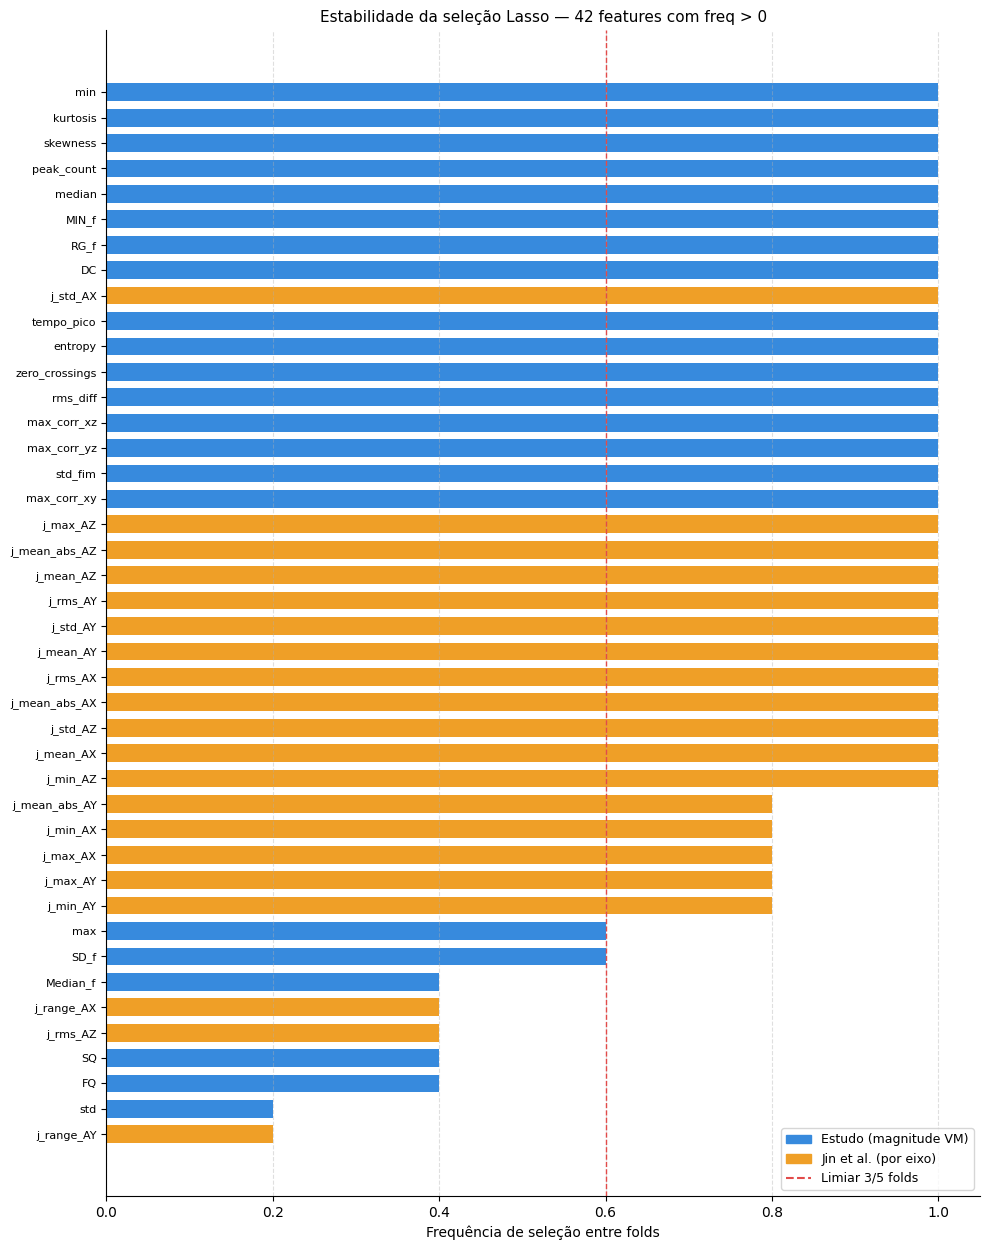

Figure saved: lasso_frequencia_selecao.png


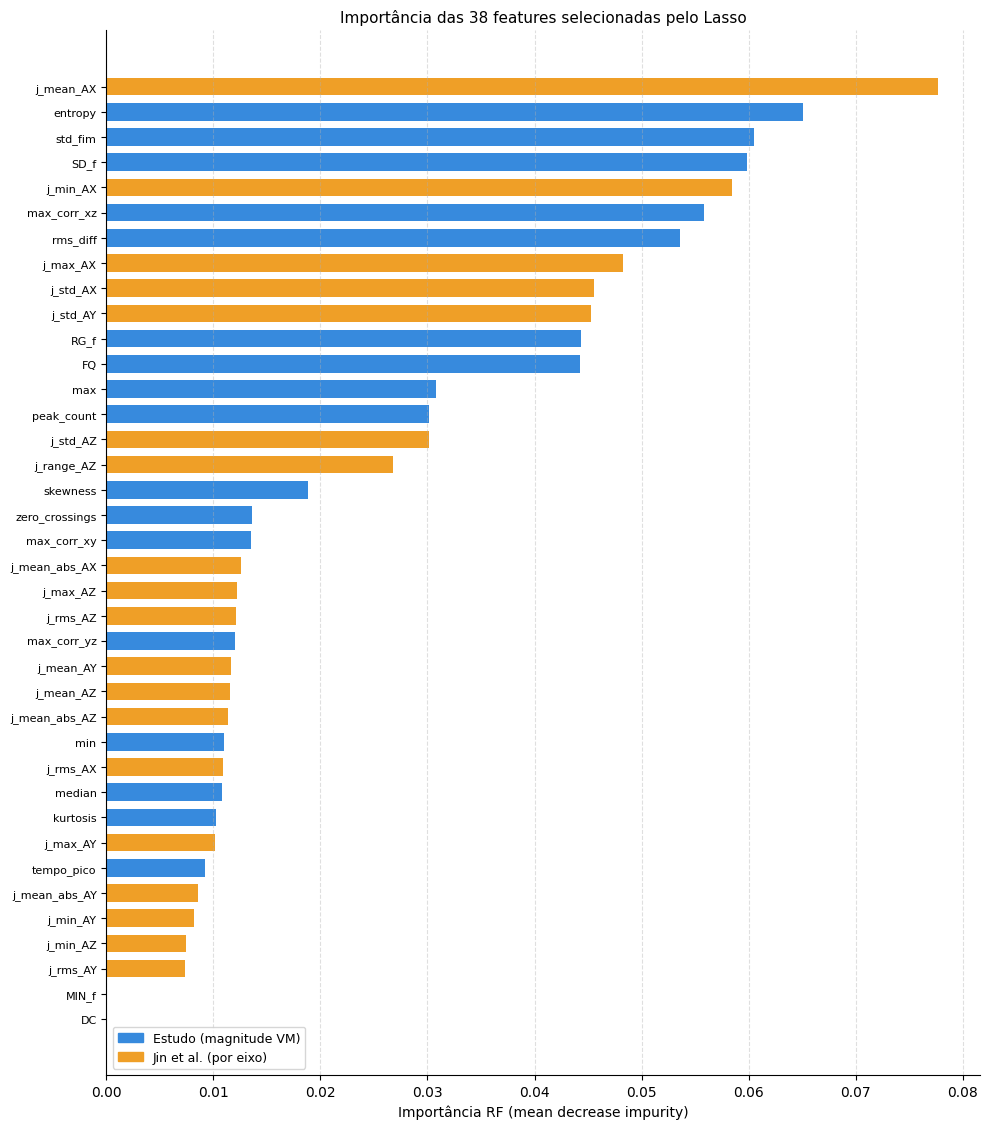

Figure saved: lasso_rf_importancia_selected.png


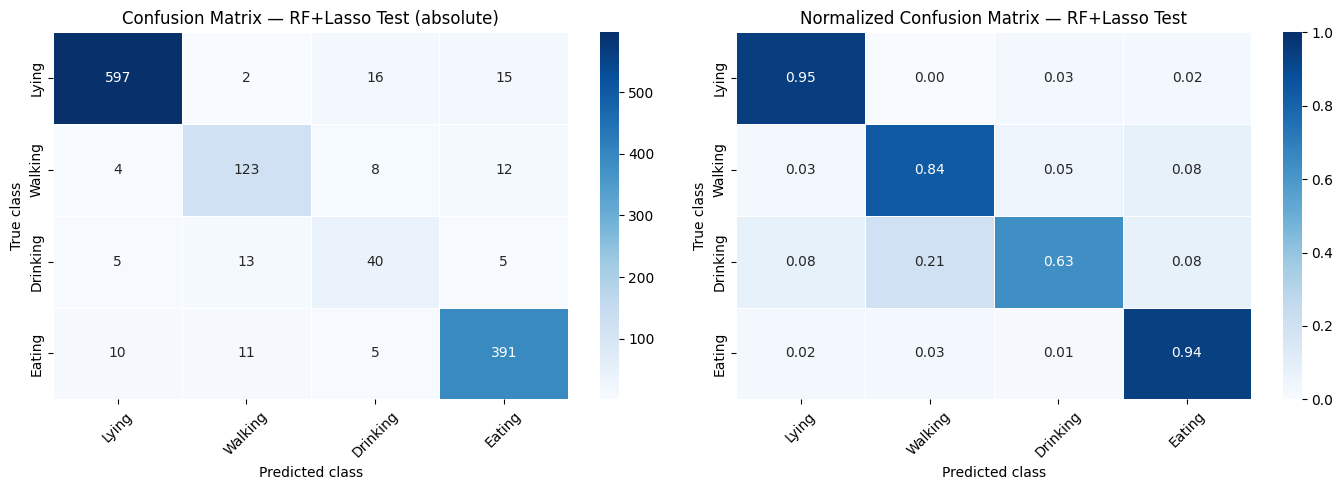

Figure saved: confusion_matrix_rf_lasso_test.png

Files saved:
  logits_rf_lasso_oof_4classes.csv
  logits_rf_lasso_validacao_4classes.csv
  lasso_frequencia_selecao.csv
  lasso_rf_importancia_selected.csv
  RandomForest_Lasso_4classes.joblib
  Lasso_selector_4classes.joblib


In [50]:
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# ============================================================
# RF + LASSO SELECTION + AD-BL-SMOTE
# Selection pipeline (within each fold):
#   1. Scale features (Lasso is scale-sensitive)
#   2. L1 Logistic Regression (Lasso) → select nonzero coefficients
#   3. Train RF using selected features (without scaling)
# Candidate features: 49 (28 estudo + 21 Jin et al.)
# ============================================================

# ============================================================
# AD-BL-SMOTE  (identica as versoes anteriores)
# ============================================================

class ADBLSMOTE:
    def __init__(self, k=5, oversampling_rate=None,
                 minority_classes=None, random_state=42):
        self.k = k
        self.oversampling_rate = oversampling_rate
        self.minority_classes  = minority_classes
        self.random_state      = random_state

    def fit_resample(self, X, y):
        rng = np.random.RandomState(self.random_state)
        X = np.array(X, dtype=float)
        y = np.array(y)
        classes, counts = np.unique(y, return_counts=True)
        majority_count  = int(counts.max())
        majority_class  = classes[counts.argmax()]
        minority_classes = (
            [c for c in classes if c != majority_class]
            if self.minority_classes is None else list(self.minority_classes)
        )
        X_aug_list = [X.copy()]
        y_aug_list = [y.copy()]
        k_eff = min(self.k, len(X) - 1)
        knn_all = NearestNeighbors(n_neighbors=k_eff + 1, n_jobs=-1)
        knn_all.fit(X)
        dist_all, idx_all = knn_all.kneighbors(X)
        dist_all = dist_all[:, 1:]
        idx_all  = idx_all[:, 1:]
        for min_class in minority_classes:
            mask_min       = (y == min_class)
            X_min          = X[mask_min]
            idx_min_global = np.where(mask_min)[0]
            n = len(X_min)
            if n < 2: continue
            alpha = majority_count / n
            r = (alpha if self.oversampling_rate is None
                 else max(1.0, min(self.oversampling_rate, alpha)))
            S = int(n * (r - 1))
            if S <= 0: continue
            danger_local, weights = [], []
            for local_i, global_i in enumerate(idx_min_global):
                nb_labels = y[idx_all[global_i]]
                k2 = int(np.sum(nb_labels != min_class))
                k1 = k_eff
                if k2 == k1: continue
                if k2 > k1 // 2:
                    min_nb_mask = (nb_labels == min_class)
                    d1 = dist_all[global_i][min_nb_mask].sum() or 1e-9
                    w  = k1 * (d1 / max(k1 - k2, 1))
                    danger_local.append(local_i)
                    weights.append(w)
            if not danger_local:
                danger_local = list(range(n))
                weights = [1.0] * n
            weights      = np.array(weights, dtype=float)
            if weights.sum() == 0: weights[:] = 1.0
            weights_norm = weights / weights.sum()
            n_per = np.round(weights_norm * S).astype(int)
            diff  = S - n_per.sum()
            order = np.argsort(-weights_norm)
            for i in range(abs(diff)):
                idx_adj = order[i % len(order)]
                n_per[idx_adj] += (1 if diff > 0 else -1)
                n_per[idx_adj]  = max(0, n_per[idx_adj])
            k_min = min(self.k, n - 1)
            knn_min = NearestNeighbors(n_neighbors=k_min + 1, n_jobs=-1)
            knn_min.fit(X_min)
            _, idx_min_nb = knn_min.kneighbors(X_min)
            idx_min_nb = idx_min_nb[:, 1:]
            X_new = []
            for pos, local_i in enumerate(danger_local):
                n_gen = n_per[pos]
                if n_gen == 0 or len(idx_min_nb[local_i]) == 0: continue
                x_b = X_min[local_i]
                for _ in range(n_gen):
                    nn  = rng.choice(idx_min_nb[local_i])
                    lam = rng.uniform(0, 1)
                    X_new.append(x_b + lam * (X_min[nn] - x_b))
            if X_new:
                X_aug_list.append(np.array(X_new))
                y_aug_list.append(np.full(len(X_new), min_class))
        return np.vstack(X_aug_list), np.concatenate(y_aug_list)


# ============================================================
# Features combinadas (49 = 28 estudo + 21 Jin)
# ============================================================

def extrair_features_combinadas(grupo):
    ax = grupo["AX"].values.astype(float)
    ay = grupo["AY"].values.astype(float)
    az = grupo["AZ"].values.astype(float)
    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n  = len(vm)
    if n == 0: return pd.Series(dtype=float)

    peaks, _ = find_peaks(vm, height=np.mean(vm))
    fft_vals  = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f  = np.sort(fft_vals)
    N_fft     = len(fft_vals)
    corr_xy = np.max(np.correlate(ax, ay, mode="full"))
    corr_xz = np.max(np.correlate(ax, az, mode="full"))
    corr_yz = np.max(np.correlate(ay, az, mode="full"))
    p3      = vm[70:] if n >= 100 else vm[int(0.7 * n):]
    diff_vm = np.diff(vm) if n > 1 else np.array([0.0])
    hist, _ = np.histogram(vm, bins=10, density=True)
    hist   += 1e-6
    entropy = -np.sum(hist * np.log(hist))
    zero_crossings = np.sum(np.diff(np.sign(diff_vm)) != 0)

    feat = {
        "mean": np.mean(vm), "std": np.std(vm), "min": np.min(vm),
        "max": np.max(vm), "max_min_diff": np.max(vm) - np.min(vm),
        "median": np.median(vm), "peak_count": len(peaks),
        "skewness": skew(vm) if n > 2 else 0,
        "kurtosis": kurtosis(vm) if n > 3 else 0,
        "sma": np.sum(np.abs(vm)) / n,
        "AV": np.mean(fft_vals) if N_fft > 0 else 0,
        "DC": fft_vals[0] if N_fft > 0 else 0,
        "SD_f": np.std(fft_vals) if N_fft > 0 else 0,
        "MIN_f": np.min(fft_vals) if N_fft > 0 else 0,
        "MAX_f": np.max(fft_vals) if N_fft > 0 else 0,
        "RG_f": (np.max(fft_vals) - np.mean(fft_vals)) if N_fft > 0 else 0,
        "FQ": sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        "SQ": sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        "RMS_f": np.sqrt(np.mean(fft_vals**2)) if N_fft > 0 else 0,
        "Median_f": np.median(fft_vals) if N_fft > 0 else 0,
        "max_corr_xy": corr_xy, "max_corr_xz": corr_xz,
        "max_corr_yz": corr_yz,
        "std_fim": np.std(p3) if len(p3) > 0 else 0,
        "rms_diff": np.sqrt(np.mean(diff_vm**2)),
        "tempo_pico": np.argmax(vm) / n,
        "entropy": entropy, "zero_crossings": zero_crossings,
    }
    for nome_eixo, v in [("AX", ax), ("AY", ay), ("AZ", az)]:
        feat[f"j_mean_{nome_eixo}"]     = np.mean(v)
        feat[f"j_std_{nome_eixo}"]      = np.std(v)
        feat[f"j_min_{nome_eixo}"]      = np.min(v)
        feat[f"j_max_{nome_eixo}"]      = np.max(v)
        feat[f"j_range_{nome_eixo}"]    = np.max(v) - np.min(v)
        feat[f"j_mean_abs_{nome_eixo}"] = np.mean(np.abs(v))
        feat[f"j_rms_{nome_eixo}"]      = np.sqrt(np.mean(v**2))
    return pd.Series(feat)


def extrair_dataset_features(df_raw_in):
    df_feat = (
        df_raw_in.groupby("window")
        .apply(extrair_features_combinadas).reset_index()
    )
    df_lbl = (
        df_raw_in.groupby("window")["atividade"]
        .first().reset_index()
    )
    df_final = pd.merge(df_feat, df_lbl, on="window")
    df_final = df_final.replace([np.inf, -np.inf], np.nan).dropna()
    return df_final


# ============================================================
# Selecao Lasso
# ============================================================

def selecionar_features_lasso(X_aug, y_aug, feature_cols, C=0.1, random_state=42):
    """
    Ajusta L1 Logistic Regression (Lasso) nos dados augmentados e
    retorna a mascara booleana das features com coeficiente ≠ 0
    em pelo menos uma classe.
    """
    scaler = StandardScaler()
    X_sc   = scaler.fit_transform(X_aug)

    lasso = LogisticRegression(
        penalty="l1",
        C=C,
        solver="saga",
        max_iter=2000,
        random_state=random_state,
        n_jobs=-1
    )
    lasso.fit(X_sc, y_aug)

    # Coeficiente nao-zero em qualquer classe
    mask = np.any(np.abs(lasso.coef_) > 1e-6, axis=0)
    selected = [f for f, m in zip(feature_cols, mask) if m]

    return mask, selected, lasso, scaler


# ============================================================
# Settings
# ============================================================

caminho_arquivo           = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.xlsx"
arquivo_windows_validacao = "windows_validacao.txt"

classes_modelo         = ["deitado", "andando", "bebendo", "comendo"]
class_names_en         = ["Lying",   "Walking", "Drinking", "Eating"]
class_to_idx           = {c: i for i, c in enumerate(classes_modelo)}
classes_minority_smote = ["andando", "bebendo"]

ADBL_K                 = 5
ADBL_OVERSAMPLING_RATE = None
LASSO_C                = 0.1   # regularizacao — reduzir para selecionar menos features

# ============================================================
# Carregar e preparar dados
# ============================================================

df_raw = pd.read_excel(caminho_arquivo)
df_raw["atividade"] = df_raw["atividade"].astype(str).str.lower().str.strip()
df_raw["atividade"] = df_raw["atividade"].replace({
    "dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"
})
df_raw = df_raw[df_raw["atividade"].isin(classes_modelo)].copy()

def extrair_id_window_audio(nome):
    m = re.search(r"-j(\d+)", str(nome))
    return int(m.group(1)) if m else None

with open(arquivo_windows_validacao, "r", encoding="utf-8") as f:
    nomes_audio = [l.strip() for l in f if l.strip()]

ids_validacao = {
    extrair_id_window_audio(n): n
    for n in nomes_audio if extrair_id_window_audio(n) is not None
}

df_raw["id_numerico"] = df_raw["window"].astype(int)
df_raw_test  = df_raw[df_raw["id_numerico"].isin(ids_validacao)].copy()
df_raw_train = df_raw[~df_raw["id_numerico"].isin(ids_validacao)].copy()

# ============================================================
# Features e sets
# ============================================================

df_test_feat = extrair_dataset_features(df_raw_test)
feature_cols = [c for c in df_test_feat.columns
                if c not in ("window", "atividade")]

X_test = df_test_feat[feature_cols].values
y_test = df_test_feat["atividade"].map(class_to_idx).values.astype(int)

print(f"Candidate features: {len(feature_cols)}")
print("\nTest set by class:")
print(df_test_feat["atividade"].value_counts())

# ============================================================
# OOF — AD-BL-SMOTE → Lasso → RF (pipeline completo por fold)
# ============================================================

df_train_windows = (
    df_raw_train.groupby("window")["atividade"]
    .first().reset_index()
)
df_train_windows["label"] = df_train_windows["atividade"].map(class_to_idx).astype(int)

skf       = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
n_classes = len(classes_modelo)

oof_probs   = np.zeros((len(df_train_windows), n_classes))
oof_y_true  = df_train_windows["label"].values.copy()
oof_windows = df_train_windows["window"].values.copy()

# Registrar features selected por fold
fold_masks = []

print("\nGerando OOF — AD-BL-SMOTE → Lasso → RF...")

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(df_train_windows["window"], df_train_windows["label"]),
    start=1
):
    train_windows = set(df_train_windows.iloc[tr_idx]["window"].values)
    val_windows   = set(df_train_windows.iloc[val_idx]["window"].values)

    df_fold_tr  = extrair_dataset_features(
        df_raw_train[df_raw_train["window"].isin(train_windows)])
    df_fold_val = extrair_dataset_features(
        df_raw_train[df_raw_train["window"].isin(val_windows)])

    X_tr  = df_fold_tr[feature_cols].values
    y_tr  = df_fold_tr["atividade"].map(class_to_idx).values.astype(int)
    X_val = df_fold_val[feature_cols].values

    # 1. AD-BL-SMOTE
    minority_idx = [class_to_idx[c] for c in classes_minority_smote]
    adbl = ADBLSMOTE(k=ADBL_K, oversampling_rate=ADBL_OVERSAMPLING_RATE,
                     minority_classes=minority_idx, random_state=42 + fold)
    X_tr_aug, y_tr_aug = adbl.fit_resample(X_tr, y_tr)

    # 2. Selecao Lasso (sobre dados augmentados)
    mask, selected, _, _ = selecionar_features_lasso(
        X_tr_aug, y_tr_aug, feature_cols,
        C=LASSO_C, random_state=42 + fold
    )
    fold_masks.append(mask)

    # 3. RF nas features selected (without scaling)
    X_tr_sel  = X_tr_aug[:, mask]
    X_val_sel = X_val[:, mask]

    rf_fold = RandomForestClassifier(
        n_estimators=500, max_depth=18,
        min_samples_split=4, min_samples_leaf=2,
        random_state=42 + fold, n_jobs=-1
    )
    rf_fold.fit(X_tr_sel, y_tr_aug)

    probs_val_raw = rf_fold.predict_proba(X_val_sel)
    probs_val     = np.zeros((len(X_val_sel), n_classes))
    for j, cls_id in enumerate(rf_fold.classes_):
        probs_val[:, int(cls_id)] = probs_val_raw[:, j]

    val_pos_map = {
        window: pos
        for pos, window in zip(val_idx, df_train_windows.iloc[val_idx]["window"].values)
    }
    for local_i, window in enumerate(df_fold_val["window"].values):
        oof_probs[val_pos_map[window], :] = probs_val[local_i, :]

    n_sel = int(mask.sum())
    print(f"  Fold {fold} — features selected: {n_sel}/{len(feature_cols)}")

y_pred_oof = oof_probs.argmax(axis=1)
print("\n=== RF + Lasso — OOF ===")
print(classification_report(
    oof_y_true, y_pred_oof,
    target_names=classes_modelo, digits=4, zero_division=0
))

# ============================================================
# Estabilidade da selecao entre folds
# ============================================================

mask_matrix  = np.array(fold_masks)          # shape (5, n_features)
freq_selecao = mask_matrix.mean(axis=0)      # frequency de selecao [0,1]

print("\n=== Frequency de selecao por fold ===")
df_freq = pd.DataFrame({
    "feature": feature_cols,
    "freq":    freq_selecao,
    "origem":  ["Jin" if f.startswith("j_") else "Estudo" for f in feature_cols]
})
df_freq = df_freq.sort_values("freq", ascending=False)

stable   = df_freq[df_freq["freq"] == 1.0]
unstable = df_freq[(df_freq["freq"] > 0) & (df_freq["freq"] < 1.0)]
removed  = df_freq[df_freq["freq"] == 0.0]

print(f"  Sempre selected (5/5 folds): {len(stable)}")
print(f"  Parcialmente selected:        {len(unstable)}")
print(f"  Nunca selected:               {len(removed)}")
print(f"  Removidas: {removed['feature'].tolist()}")

# Usar mascara final = features selected em pelo menos 3/5 folds
mask_final  = freq_selecao >= 0.6
selected_final = [f for f, m in zip(feature_cols, mask_final) if m]
print(f"\nMascara final (≥3/5 folds): {int(mask_final.sum())} features")
print(f"  {selected_final}")

# ============================================================
# Modelo final — AD-BL-SMOTE → Lasso (treino completo) → RF
# ============================================================

df_train_full = extrair_dataset_features(df_raw_train)
X_train_full  = df_train_full[feature_cols].values
y_train_full  = df_train_full["atividade"].map(class_to_idx).values.astype(int)

adbl_final = ADBLSMOTE(
    k=ADBL_K, oversampling_rate=ADBL_OVERSAMPLING_RATE,
    minority_classes=[class_to_idx[c] for c in classes_minority_smote],
    random_state=42
)
X_train_aug, y_train_aug = adbl_final.fit_resample(X_train_full, y_train_full)

mask_full, selected_full, lasso_final, scaler_final = selecionar_features_lasso(
    X_train_aug, y_train_aug, feature_cols, C=LASSO_C, random_state=42
)
print(f"\nFeatures selected (treino completo): {int(mask_full.sum())}")
print(f"  {selected_full}")

X_train_sel = X_train_aug[:, mask_full]
X_test_sel  = X_test[:, mask_full]

rf_final = RandomForestClassifier(
    n_estimators=500, max_depth=18,
    min_samples_split=4, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
print("\nTreinando RF final (Lasso + RF)...")
rf_final.fit(X_train_sel, y_train_aug)

probs_test_raw = rf_final.predict_proba(X_test_sel)
probs_test = np.zeros((len(X_test_sel), n_classes))
for j, cls_id in enumerate(rf_final.classes_):
    probs_test[:, int(cls_id)] = probs_test_raw[:, j]
y_pred_test = probs_test.argmax(axis=1)

print("\n=== RF + Lasso — Test ===")
print(classification_report(
    y_test, y_pred_test,
    target_names=classes_modelo, digits=4, zero_division=0
))

# ============================================================
# Importancia das features selected
# ============================================================

imp_final = rf_final.feature_importances_
df_imp = pd.DataFrame({
    "feature":    selected_full,
    "importance": imp_final,
    "origem":     ["Jin" if f.startswith("j_") else "Estudo" for f in selected_full]
}).sort_values("importance", ascending=False).reset_index(drop=True)

print("\n=== Importancia das features selected ===")
for _, row in df_imp.iterrows():
    bar = "█" * int(row["importance"] * 400)
    print(f"  {row['feature']:<22}  {row['importance']:.6f}  {row['origem']:<6}  {bar}")

# ============================================================
# Figura — frequency de selecao por fold
# ============================================================

CORES = {"Estudo": "#378ADD", "Jin": "#EF9F27"}
df_freq_plot = df_freq[df_freq["freq"] > 0].copy()
cores_barra  = df_freq_plot["origem"].map(CORES).tolist()
n_plot = len(df_freq_plot)

fig, ax = plt.subplots(figsize=(10, max(5, n_plot * 0.3)))
y_pos = np.arange(n_plot)[::-1]
ax.barh(y_pos, df_freq_plot["freq"], color=cores_barra, height=0.7)
ax.axvline(0.6, color="#E24B4A", linestyle="--", linewidth=1,
           label="Limiar de selecao (3/5 folds)")
ax.set_yticks(y_pos)
ax.set_yticklabels(df_freq_plot["feature"].tolist(), fontsize=8)
ax.set_xlabel("Frequency de selecao entre folds", fontsize=10)
ax.set_title(f"Estabilidade da selecao Lasso — {n_plot} features com freq > 0", fontsize=11)
ax.set_xlim(0, 1.05)
legend_patches = [
    mpatches.Patch(color="#378ADD", label="Estudo (magnitude VM)"),
    mpatches.Patch(color="#EF9F27", label="Jin et al. (por eixo)"),
]
ax.legend(handles=legend_patches + [
    plt.Line2D([0],[0], color="#E24B4A", linestyle="--", label="Limiar 3/5 folds")
], fontsize=9)
ax.spines[["top","right"]].set_visible(False)
ax.xaxis.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("lasso_frequencia_selecao.png", dpi=200, bbox_inches="tight")
plt.show()
print("Figure saved: lasso_frequencia_selecao.png")

# ============================================================
# Figura — importancia RF das features selected
# ============================================================

cores_imp = df_imp["origem"].map(CORES).tolist()
n_imp = len(df_imp)
fig2, ax2 = plt.subplots(figsize=(10, max(5, n_imp * 0.3)))
y2 = np.arange(n_imp)[::-1]
ax2.barh(y2, df_imp["importance"], color=cores_imp, height=0.7)
ax2.set_yticks(y2)
ax2.set_yticklabels(df_imp["feature"].tolist(), fontsize=8)
ax2.set_xlabel("Importancia RF (mean decrease impurity)", fontsize=10)
ax2.set_title(f"Importancia das {n_imp} features selected pelo Lasso", fontsize=11)
legend_patches2 = [
    mpatches.Patch(color="#378ADD", label="Estudo (magnitude VM)"),
    mpatches.Patch(color="#EF9F27", label="Jin et al. (por eixo)"),
]
ax2.legend(handles=legend_patches2, fontsize=9)
ax2.spines[["top","right"]].set_visible(False)
ax2.xaxis.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("lasso_rf_importancia_selected.png", dpi=200, bbox_inches="tight")
plt.show()
print("Figure saved: lasso_rf_importancia_selected.png")

# ============================================================
# Confusion matrix — Test
# ============================================================

cm   = confusion_matrix(y_test, y_pred_test, labels=np.arange(n_classes))
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_n = np.nan_to_num(cm_n)

fig3, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, fmt, title in zip(
    axes, [cm, cm_n], ["d", ".2f"],
    ["Confusion Matrix — RF+Lasso Test (absolute)",
     "Normalized Confusion Matrix — RF+Lasso Test"]
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues",
                xticklabels=class_names_en, yticklabels=class_names_en,
                vmin=(0 if fmt==".2f" else None),
                vmax=(1 if fmt==".2f" else None),
                linewidths=0.5, linecolor="white", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("confusion_matrix_rf_lasso_test.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved: confusion_matrix_rf_lasso_test.png")

# ============================================================
# Save outputs
# ============================================================

df_oof_out = pd.DataFrame(oof_probs, columns=[f"prob_{c}" for c in classes_modelo])
df_oof_out["window"]     = oof_windows
df_oof_out["label_real"] = oof_y_true
df_oof_out.to_csv("logits_rf_lasso_oof_4classes.csv", index=False)

df_test_out = pd.DataFrame(probs_test, columns=[f"prob_{c}" for c in classes_modelo])
df_test_feat["id_numerico"] = df_test_feat["window"].astype(int)
df_test_out["window"]     = df_test_feat["id_numerico"].map(ids_validacao).values
df_test_out["label_real"] = y_test
df_test_out.to_csv("logits_rf_lasso_validacao_4classes.csv", index=False)

df_freq.to_csv("lasso_frequencia_selecao.csv", index=False)
df_imp.to_csv("lasso_rf_importancia_selected.csv", index=False)
joblib.dump(rf_final, "RandomForest_Lasso_4classes.joblib")
joblib.dump({"mask": mask_full, "features": selected_full,
             "lasso": lasso_final, "scaler": scaler_final},
            "Lasso_selector_4classes.joblib")

print("\nFiles saved:")
for f in [
    "logits_rf_lasso_oof_4classes.csv",
    "logits_rf_lasso_validacao_4classes.csv",
    "lasso_frequencia_selecao.csv",
    "lasso_rf_importancia_selected.csv",
    "RandomForest_Lasso_4classes.joblib",
    "Lasso_selector_4classes.joblib",
]:
    print(" ", f)

## Log-Mel Audio Attention Network with Circular Shift Augmentation

This cell trains the Log-Mel Audio Attention Network for the four-class audio behavior classification problem. It uses spectrogram inputs, class weighting, stratified folds, and circular shift augmentation to address class imbalance and improve acoustic robustness. The resulting OOF predictions and trained weights are used for evaluation and multimodal fusion.


In [1]:
import os
import re
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# ============================================================
# LMAAN OOF - 4 classes
# Circular shift augmentation em 4 partes
# Classes: deitado, andando, bebendo, comendo
# ============================================================

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

base_path = r"C:\Users\franc\OneDrive\Desktop\logmel_512"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TARGET_WIDTH = 431
BATCH_SIZE = 16
EPOCHS = 60
N_FOLDS = 5

# Official order of the four classes
classes_4 = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying", "Walking", "Drinking", "Eating"]

# Mapping from original folders to the four classes
class_to_idx = {
    "deitado": 0,
    "deitadoac": 0,
    "dormindo": 0,
    "inativo": 0,
    "andando": 1,
    "bebendo": 2,
    "comendo": 3
}

idx_to_class = {
    0: "deitado",
    1: "andando",
    2: "bebendo",
    3: "comendo"
}

# Classes that receive augmentation
classes_aug = ["andando", "bebendo"]

# Circular shift em 4 partes:
# 1: [A,B,C,D] -> [B,C,D,A]
# 2: [A,B,C,D] -> [C,D,A,B]
# 3: [A,B,C,D] -> [D,A,B,C]
SHIFT_PARTS_LIST = [1, 2, 3]

print("Device:", device)
print("Classes:", classes_4)
print("Classes with augmentation:", classes_aug)
print("Shift parts:", SHIFT_PARTS_LIST)

# ------------------------------------------------------------
# 2. Modelo AttentionPigNet
# ------------------------------------------------------------

class SEBlock(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SEBlock, self).__init__()

        hidden = max(channel // reduction, 1)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Linear(channel, hidden, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channel, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()

        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)

        return x * y


class AttentionPigNet(nn.Module):
    def __init__(self, num_classes):
        super(AttentionPigNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            SEBlock(64),
            nn.MaxPool2d(2, 2)
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            SEBlock(128),
            nn.MaxPool2d(2, 2)
        )

        self.layer3 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            SEBlock(256),
            nn.MaxPool2d(2, 2)
        )

        self.layer4 = nn.Sequential(
            nn.Conv2d(256, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            SEBlock(512),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        return self.classifier(x)

# ------------------------------------------------------------
# 3. Construir lookup dos files .npy
# ------------------------------------------------------------

all_file_lookup = {}

for cls in os.listdir(base_path):
    cls_dir = os.path.join(base_path, cls)

    if not os.path.isdir(cls_dir):
        continue

    cls_low = cls.lower().strip()

    if cls_low not in class_to_idx:
        # Ignora correndo e outras pastas
        continue

    for f in os.listdir(cls_dir):
        if f.endswith(".npy"):
            full_path = os.path.join(cls_dir, f)
            all_file_lookup[f] = (full_path, cls_low)

print("\nTotal .npy files found for 4 classes:", len(all_file_lookup))

# ------------------------------------------------------------
# 4. Load 4-class training windows
# ------------------------------------------------------------

if os.path.exists("windows_treino_4classes.txt"):
    train_txt_base = "windows_treino_4classes.txt"
else:
    train_txt_base = "windows_treino.txt"

print("\nWindow file used:", train_txt_base)

with open(train_txt_base, "r", encoding="utf-8") as f:
    windows_treino = [line.strip() for line in f if line.strip()]

rows = []
missing_files = []

for window in windows_treino:
    if window not in all_file_lookup:
        missing_files.append(window)
        continue

    path, cls = all_file_lookup[window]

    if cls not in class_to_idx:
        continue

    label = class_to_idx[cls]

    # Garante remocao de correndo caso venha no txt
    if label not in [0, 1, 2, 3]:
        continue

    rows.append({
        "window": window,
        "path": path,
        "classe_original": cls,
        "label": label,
        "classe": idx_to_class[label]
    })

df_audio_train_4 = pd.DataFrame(rows)

print("\nTotal valid windows for 4-class OOF:", len(df_audio_train_4))
print("\nClass distribution:")
print(df_audio_train_4["classe"].value_counts())

if len(missing_files) > 0:
    print("\nArquivos listados no TXT, mas not founds no base_path:", len(missing_files))
    print("Examples:", missing_files[:10])

if len(df_audio_train_4) == 0:
    raise ValueError("No valid window was found for 4-class OOF training.")

# ------------------------------------------------------------
# 5. Criar folds estratificados
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=42
)

df_audio_train_4["fold"] = -1

for fold, (_, val_idx) in enumerate(
    skf.split(df_audio_train_4["window"], df_audio_train_4["label"])
):
    df_audio_train_4.loc[df_audio_train_4.index[val_idx], "fold"] = fold

print("\nFold distribution:")
display(pd.crosstab(df_audio_train_4["fold"], df_audio_train_4["classe"]))

df_audio_train_4.to_csv("audio_oof_4classes_manifest.csv", index=False)
print("\nManifest saved: audio_oof_4classes_manifest.csv")

# ------------------------------------------------------------
# 6. Funcoes de augmentation no espectrograma
# ------------------------------------------------------------

def circular_shift_4parts_spec(spec, shift_parts):
    """
    Aplica circular shift no eixo temporal do espectrograma.

    spec: array 2D [freq, time]
    shift_parts:
        1 -> [B,C,D,A]
        2 -> [C,D,A,B]
        3 -> [D,A,B,C]
    """

    if shift_parts == 0:
        return spec

    if shift_parts not in [1, 2, 3]:
        return spec

    if spec.ndim != 2:
        return spec

    n_time = spec.shape[1]

    if n_time < 8:
        return spec

    cut1 = n_time // 4
    cut2 = n_time // 2
    cut3 = (3 * n_time) // 4

    part_A = spec[:, :cut1]
    part_B = spec[:, cut1:cut2]
    part_C = spec[:, cut2:cut3]
    part_D = spec[:, cut3:]

    parts = [part_A, part_B, part_C, part_D]

    shifted = parts[shift_parts:] + parts[:shift_parts]

    return np.concatenate(shifted, axis=1)


def build_train_items_with_aug(df_train_fold):
    """
    Para cada window:
      - adiciona original
      - se classe for andando/bebendo, adiciona 3 versoes com circular shift 4 partes
    """

    items = []

    for _, row in df_train_fold.iterrows():
        path = row["path"]
        label = int(row["label"])
        classe = row["classe"]
        window = row["window"]

        # Original
        items.append({
            "path": path,
            "label": label,
            "classe": classe,
            "window": window,
            "shift_parts": 0
        })

        # Augmentation somente para classes raras
        if classe in classes_aug:
            for shift_parts in SHIFT_PARTS_LIST:
                items.append({
                    "path": path,
                    "label": label,
                    "classe": classe,
                    "window": f"{window}_cshift4p_{shift_parts}",
                    "shift_parts": shift_parts
                })

    return items


def build_val_items(df_val_fold):
    """
    OOF validation sem augmentation.
    """

    items = []

    for _, row in df_val_fold.iterrows():
        items.append({
            "path": row["path"],
            "label": int(row["label"]),
            "classe": row["classe"],
            "window": row["window"],
            "shift_parts": 0
        })

    return items

# ------------------------------------------------------------
# 7. Dataset
# ------------------------------------------------------------

class PigAudioDataset4(Dataset):
    def __init__(self, items, target_width=TARGET_WIDTH, augment_noise=False):
        self.items = items
        self.target_width = target_width
        self.augment_noise = augment_noise

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        item = self.items[idx]

        spec = np.load(item["path"]).astype(np.float32)

        # Circular shift estrutural
        spec = circular_shift_4parts_spec(
            spec,
            shift_parts=item.get("shift_parts", 0)
        )

        # Pequeno ruido apenas no treino, opcional
        if self.augment_noise:
            spec = spec + np.random.randn(*spec.shape).astype(np.float32) * 0.005

        # Normalizacao 0-1 por window
        spec = (spec - np.min(spec)) / (np.max(spec) - np.min(spec) + 1e-8)

        # Ajuste da largura temporal
        if spec.shape[1] < self.target_width:
            spec = np.pad(
                spec,
                ((0, 0), (0, self.target_width - spec.shape[1])),
                mode="constant"
            )
        else:
            spec = spec[:, :self.target_width]

        x = torch.from_numpy(spec).float().unsqueeze(0)

        y = int(item["label"])
        window = item["window"]

        return x, y, window

# ------------------------------------------------------------
# 8. Function for training one fold
# ------------------------------------------------------------

def train_one_fold_lmaan_4(fold, df_train_fold, df_val_fold):
    train_items = build_train_items_with_aug(df_train_fold)
    val_items = build_val_items(df_val_fold)

    print(f"\n================ Fold {fold} ================")
    print("Original training set:", len(df_train_fold))
    print("Training set with augmentation:", len(train_items))
    print("OOF validation:", len(val_items))

    print("\nOriginal training distribution:")
    print(df_train_fold["classe"].value_counts())

    print("\nTraining distribution after augmentation:")
    print(pd.Series([item["classe"] for item in train_items]).value_counts())

    train_dataset = PigAudioDataset4(
        train_items,
        target_width=TARGET_WIDTH,
        augment_noise=True
    )

    val_dataset = PigAudioDataset4(
        val_items,
        target_width=TARGET_WIDTH,
        augment_noise=False
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model = AttentionPigNet(num_classes=4).to(device)

    optimizer = optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=0.02
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=5
    )

    # Class weights computed after augmentation
    y_train_aug = np.array([item["label"] for item in train_items])

    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(4),
        y=y_train_aug
    )

    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    print("\nClass weights:", class_weights.detach().cpu().numpy())

    best_val_acc = -1
    best_state = None

    for epoch in range(EPOCHS):
        model.train()

        t_corr, t_total = 0, 0
        train_loss_sum = 0.0

        for inputs, labels, _ in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            out = model(inputs)
            loss = criterion(out, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)

            t_corr += (out.argmax(1) == labels).sum().item()
            t_total += labels.size(0)

        train_acc = 100.0 * t_corr / max(t_total, 1)
        train_loss = train_loss_sum / max(t_total, 1)

        model.eval()

        v_corr, v_total = 0, 0

        with torch.no_grad():
            for inputs, labels, _ in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                out = model(inputs)

                v_corr += (out.argmax(1) == labels).sum().item()
                v_total += labels.size(0)

        val_acc = 100.0 * v_corr / max(v_total, 1)

        scheduler.step(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Fold {fold} | Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Loss: {train_loss:.4f} | "
            f"Train: {train_acc:.1f}% | "
            f"Val: {val_acc:.1f}% | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

    # Carregar melhor estado
    model.load_state_dict(best_state)
    model.to(device)
    model.eval()

    model_file = f"AttentionPigNet_LMAAN_4classes_CShift4P_OOF_fold{fold}.pth"

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "classes": classes_4,
            "class_to_idx": class_to_idx,
            "target_width": TARGET_WIDTH,
            "fold": fold,
            "augmentation": "circular_shift_4parts",
            "shift_parts_list": SHIFT_PARTS_LIST
        },
        model_file
    )

    print(f"\nModel saved: {model_file}")

    # Predicao OOF no fold de validation
    softmax = nn.Softmax(dim=1)

    all_probs = []
    all_labels = []
    all_windows = []

    with torch.no_grad():
        for inputs, labels, windows in val_loader:
            inputs = inputs.to(device)

            logits = model(inputs)
            probs = softmax(logits).cpu().numpy()

            all_probs.append(probs)
            all_labels.extend(labels.numpy())
            all_windows.extend(list(windows))

    all_probs = np.vstack(all_probs)
    all_labels = np.asarray(all_labels, dtype=int)

    y_pred_val = all_probs.argmax(axis=1)

    print(f"\n=== Fold {fold} OOF report - LMAAN 4 classes ===")
    print(classification_report(
        all_labels,
        y_pred_val,
        labels=[0, 1, 2, 3],
        target_names=classes_4,
        digits=4,
        zero_division=0
    ))

    df_fold = pd.DataFrame(
        all_probs,
        columns=[f"prob_{c}" for c in classes_4]
    )

    df_fold["window"] = all_windows
    df_fold["label_real"] = all_labels
    df_fold["fold"] = fold

    df_fold = df_fold[
        ["window", "label_real",
         "prob_deitado", "prob_andando", "prob_bebendo", "prob_comendo",
         "fold"]
    ]

    out_csv = f"logits_audio_oof_4classes_cshift4p_fold{fold}.csv"

    df_fold.to_csv(out_csv, index=False)

    print(f"OOF CSV saved: {out_csv}")

    return df_fold

# ------------------------------------------------------------
# 9. Rodar os 5 folds
# ------------------------------------------------------------

all_oof_folds = []

for fold in range(N_FOLDS):
    df_train_fold = df_audio_train_4[df_audio_train_4["fold"] != fold].copy()
    df_val_fold = df_audio_train_4[df_audio_train_4["fold"] == fold].copy()

    df_fold = train_one_fold_lmaan_4(
        fold=fold,
        df_train_fold=df_train_fold,
        df_val_fold=df_val_fold
    )

    all_oof_folds.append(df_fold)

# ------------------------------------------------------------
# 10. Consolidar OOF
# ------------------------------------------------------------

df_audio_oof_4_cshift4p = pd.concat(
    all_oof_folds,
    ignore_index=True
)

df_audio_oof_4_cshift4p = df_audio_oof_4_cshift4p.drop_duplicates(
    subset=["window"],
    keep="first"
)

df_audio_oof_4_cshift4p = df_audio_oof_4_cshift4p[
    ["window", "label_real",
     "prob_deitado", "prob_andando", "prob_bebendo", "prob_comendo",
     "fold"]
]

df_audio_oof_4_cshift4p.to_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv",
    index=False
)

print("\n====================================")
print("Final file saved:")
print("logits_audio_oof_treino_4classes_cshift4p.csv")
print("Total OOF:", len(df_audio_oof_4_cshift4p))
print("====================================")

y_true_oof = df_audio_oof_4_cshift4p["label_real"].values
y_pred_oof = df_audio_oof_4_cshift4p[
    ["prob_deitado", "prob_andando", "prob_bebendo", "prob_comendo"]
].values.argmax(axis=1)

print("\n=== LMAAN OOF 4 classes + Circular Shift 4P consolidated report ===")
print(classification_report(
    y_true_oof,
    y_pred_oof,
    labels=[0, 1, 2, 3],
    target_names=classes_4,
    digits=4,
    zero_division=0
))

display(df_audio_oof_4_cshift4p.head())

Device: cuda
Classes: ['deitado', 'andando', 'bebendo', 'comendo']
Classes with augmentation: ['andando', 'bebendo']
Shift parts: [1, 2, 3]

Total .npy files found for 4 classes: 6288

Window file used: windows_treino_4classes.txt

Total valid windows for 4-class OOF: 5028

Class distribution:
classe
deitado    2541
comendo    1710
andando     482
bebendo     295
Name: count, dtype: int64

Arquivos listados no TXT, mas not founds no base_path: 50
Examples: ['am31-160135-j5468.npy', 'vd26-082816-j8327.npy', 'vd26-022617-j7168.npy', 'vd26-053954-j7741.npy', 'p29-093845-j621.npy', 'vd26-024556-j7179.npy', 'p29-093758-j613.npy', 'am31-160130-j5467.npy', 'am31-160009-j5458.npy', 'p29-093740-j611.npy']

Fold distribution:


classe,andando,bebendo,comendo,deitado
fold,,,,
0,96,59,342,509
1,97,59,342,508
2,97,59,342,508
3,96,59,342,508
4,96,59,342,508



Manifest saved: audio_oof_4classes_manifest.csv

================ Fold 0 ================
Original training set: 4022
Training set with augmentation: 5888
OOF validation: 1006

Original training distribution:
classe
deitado    2032
comendo    1368
andando     386
bebendo     236
Name: count, dtype: int64

Training distribution after augmentation:
deitado    2032
andando    1544
comendo    1368
bebendo     944
Name: count, dtype: int64

Class weights: [0.72440946 0.9533679  1.559322   1.0760233 ]
Fold 0 | Epoch 01/60 | Loss: 1.0989 | Train: 52.4% | Val: 65.8% | LR: 0.001000
Fold 0 | Epoch 02/60 | Loss: 0.8631 | Train: 66.3% | Val: 69.5% | LR: 0.001000
Fold 0 | Epoch 03/60 | Loss: 0.7917 | Train: 69.1% | Val: 70.9% | LR: 0.001000
Fold 0 | Epoch 04/60 | Loss: 0.7419 | Train: 70.8% | Val: 71.3% | LR: 0.001000
Fold 0 | Epoch 05/60 | Loss: 0.7117 | Train: 72.4% | Val: 78.6% | LR: 0.001000
Fold 0 | Epoch 06/60 | Loss: 0.6888 | Train: 72.7% | Val: 77.0% | LR: 0.001000
Fold 0 | Epoch 07/60 | L

,window,label_real,prob_deitado,prob_andando,prob_bebendo,prob_comendo,fold
0,p29-110531-j1102.npy,0,0.999999,6.629204e-07,1.465083e-10,1.253476e-08,0
1,p29-105145-j936.npy,0,0.999992,7.024354e-06,2.828827e-10,9.111570e-07,0
2,vd26-065633-j7906.npy,3,0.006933,2.794844e-03,3.593992e-05,9.902363e-01,0
3,am30-161459-j7028.npy,3,0.000019,5.831564e-06,1.139457e-06,9.999741e-01,0
4,p29-134451-j1253.npy,0,0.999994,2.225982e-06,3.602253e-10,3.595592e-06,0


## Verification of Saved LMAAN Model Weights

This cell searches the working directory for saved model weight files associated with the LMAAN experiment. It is a practical checkpoint confirming that training produced serialized `.pth` files that can be reused for inference or validation.


In [2]:
import os

[f for f in os.listdir() if "LMAAN_4classes_CShift4P" in f and f.endswith(".pth")]

['AttentionPigNet_LMAAN_4classes_CShift4P_OOF_fold0.pth',
 'AttentionPigNet_LMAAN_4classes_CShift4P_OOF_fold1.pth',
 'AttentionPigNet_LMAAN_4classes_CShift4P_OOF_fold2.pth',
 'AttentionPigNet_LMAAN_4classes_CShift4P_OOF_fold3.pth',
 'AttentionPigNet_LMAAN_4classes_CShift4P_OOF_fold4.pth']

## Consolidated Confusion Matrix for the LMAAN OOF Experiment

This cell loads the audio OOF prediction file and computes a consolidated confusion matrix and classification report. The goal is to summarize audio-only performance across folds and identify which behaviors are most frequently confused by the LMAAN model.


Colunas encontradas:
['window', 'label_real', 'prob_deitado', 'prob_andando', 'prob_bebendo', 'prob_comendo', 'fold']

=== LMAAN OOF 4 classes + Circular Shift 4P - Classification Report ===
              precision    recall  f1-score   support

     deitado     0.8957    0.9429    0.9187      2541
     andando     0.6497    0.5809    0.6134       482
     bebendo     0.6953    0.5492    0.6136       295
     comendo     0.9005    0.8895    0.8950      1710

    accuracy                         0.8669      5028
   macro avg     0.7853    0.7406    0.7602      5028
weighted avg     0.8620    0.8669    0.8635      5028


=== Absolute confusion matrix - LMAAN OOF 4 classes ===


,Lying,Walking,Drinking,Eating
Lying,2396,58,12,75
Walking,97,280,49,56
Drinking,32,64,162,37
Eating,150,29,10,1521



=== Normalized confusion matrix - LMAAN OOF 4 classes ===


,Lying,Walking,Drinking,Eating
Lying,0.942936,0.022826,0.004723,0.029516
Walking,0.201245,0.580913,0.101660,0.116183
Drinking,0.108475,0.216949,0.549153,0.125424
Eating,0.087719,0.016959,0.005848,0.889474


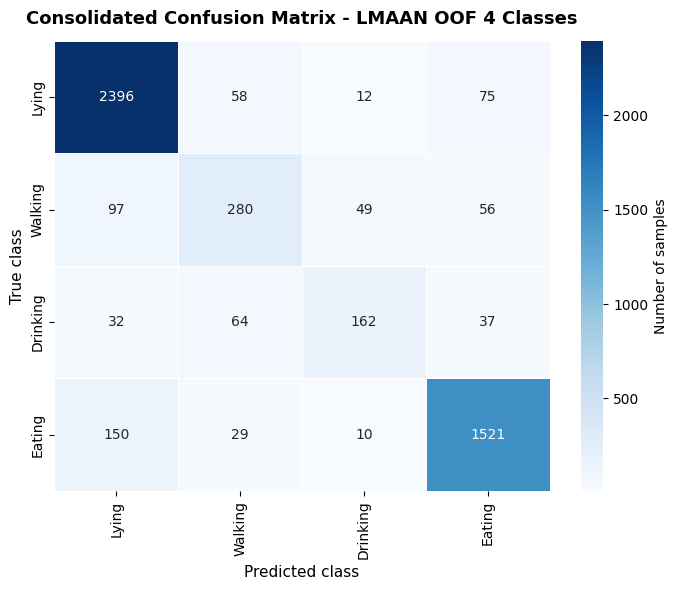

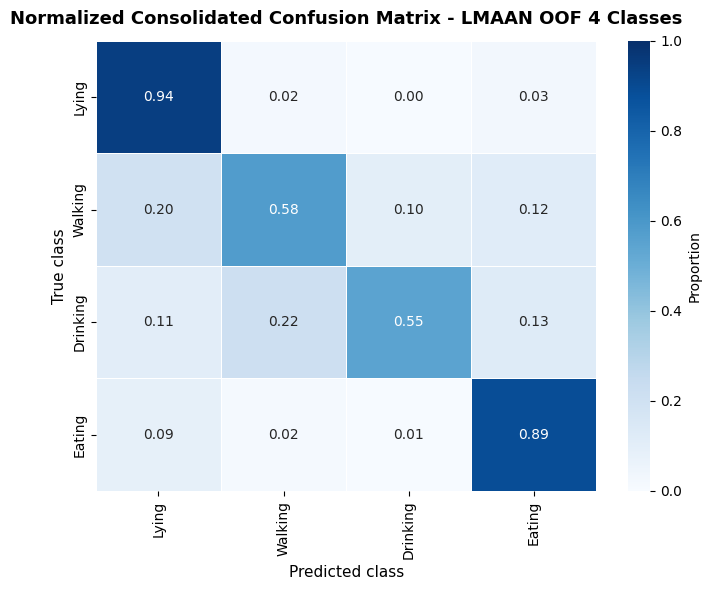


Files saved:
confusion_matrix_lmaan_oof_4classes_cshift4p_absolute.png
confusion_matrix_lmaan_oof_4classes_cshift4p_normalized.png


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# ============================================================
# MATRIZ DE CONFUSAO CONSOLIDADA
# LMAAN OOF 4 classes + Circular Shift 4 Parts
# ============================================================

csv_oof_audio = "logits_audio_oof_treino_4classes_cshift4p.csv"

if not os.path.exists(csv_oof_audio):
    raise FileNotFoundError(
        f"Arquivo not found: {csv_oof_audio}. "
        "Verifique se o treinamento OOF do LMAAN 4 classes terminou corretamente."
    )

df_audio_oof = pd.read_csv(csv_oof_audio)

print("Colunas encontradas:")
print(df_audio_oof.columns.tolist())

# ------------------------------------------------------------
# Ordem das classes
# ------------------------------------------------------------

classes_pt = ["deitado", "andando", "bebendo", "comendo"]
classes_en = ["Lying", "Walking", "Drinking", "Eating"]
labels_order = [0, 1, 2, 3]

prob_cols = [
    "prob_deitado",
    "prob_andando",
    "prob_bebendo",
    "prob_comendo"
]

missing = [c for c in prob_cols + ["label_real"] if c not in df_audio_oof.columns]

if missing:
    raise ValueError(f"Colunas ausentes no CSV OOF de audio: {missing}")

# ------------------------------------------------------------
# Verdadeiro e predito
# ------------------------------------------------------------

y_true_oof_audio = df_audio_oof["label_real"].values.astype(int)
y_pred_oof_audio = df_audio_oof[prob_cols].values.argmax(axis=1)

# ------------------------------------------------------------
# Report consolidado
# ------------------------------------------------------------

print("\n=== LMAAN OOF 4 classes + Circular Shift 4P - Classification Report ===")
print(classification_report(
    y_true_oof_audio,
    y_pred_oof_audio,
    labels=labels_order,
    target_names=classes_pt,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# Matriz absoluta
# ------------------------------------------------------------

cm_abs = confusion_matrix(
    y_true_oof_audio,
    y_pred_oof_audio,
    labels=labels_order
)

df_cm_abs = pd.DataFrame(
    cm_abs,
    index=classes_en,
    columns=classes_en
)

print("\n=== Absolute confusion matrix - LMAAN OOF 4 classes ===")
display(df_cm_abs)

# ------------------------------------------------------------
# Confusion matrix normalized by true class
# ------------------------------------------------------------

cm_norm = cm_abs.astype(float) / cm_abs.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

df_cm_norm = pd.DataFrame(
    cm_norm,
    index=classes_en,
    columns=classes_en
)

print("\n=== Normalized confusion matrix - LMAAN OOF 4 classes ===")
display(df_cm_norm)

# ------------------------------------------------------------
# Figure 1: absolute confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_abs,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes_en,
    yticklabels=classes_en,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Number of samples"}
)

plt.title(
    "Consolidated Confusion Matrix - LMAAN OOF 4 Classes",
    fontsize=13,
    fontweight="bold",
    pad=12
)

plt.xlabel("Predicted class", fontsize=11)
plt.ylabel("True class", fontsize=11)
plt.xticks(rotation=90)
plt.yticks(rotation=90)
plt.tight_layout()

plt.savefig(
    "confusion_matrix_lmaan_oof_4classes_cshift4p_absolute.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Figure 2: normalized confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=classes_en,
    yticklabels=classes_en,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Proportion"}
)

plt.title(
    "Normalized Consolidated Confusion Matrix - LMAAN OOF 4 Classes",
    fontsize=13,
    fontweight="bold",
    pad=12
)

plt.xlabel("Predicted class", fontsize=11)
plt.ylabel("True class", fontsize=11)
plt.xticks(rotation=90)
plt.yticks(rotation=90)
plt.tight_layout()

plt.savefig(
    "confusion_matrix_lmaan_oof_4classes_cshift4p_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFiles saved:")
print("confusion_matrix_lmaan_oof_4classes_cshift4p_absolute.png")
print("confusion_matrix_lmaan_oof_4classes_cshift4p_normalized.png")

## Audio CNN Baseline Without Attention

This cell trains an audio CNN baseline without the Squeeze-and-Excitation attention mechanism. Comparing this model with LMAAN helps quantify the contribution of attention to audio-based pig behavior recognition under the same log-Mel input representation.


In [10]:
import os
import re
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# ============================================================
# CNN BASELINE (without attention) - 4 classes
# Circular shift augmentation em 4 partes
# Classes: deitado, andando, bebendo, comendo
# ============================================================

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

base_path = r"C:\Users\franc\OneDrive\Desktop\logmel_512"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TARGET_WIDTH = 431
BATCH_SIZE = 32
EPOCHS = 60
N_FOLDS = 5

# Official order of the four classes
classes_4 = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying", "Walking", "Drinking", "Eating"]

# Mapping from original folders to the four classes
class_to_idx = {
    "deitado": 0,
    "deitadoac": 0,
    "dormindo": 0,
    "inativo": 0,
    "andando": 1,
    "bebendo": 2,
    "comendo": 3
}

idx_to_class = {
    0: "deitado",
    1: "andando",
    2: "bebendo",
    3: "comendo"
}

# Classes that receive augmentation
classes_aug = ["andando", "bebendo"]

# Circular shift em 4 partes:
# 1: [A,B,C,D] -> [B,C,D,A]
# 2: [A,B,C,D] -> [C,D,A,B]
# 3: [A,B,C,D] -> [D,A,B,C]
SHIFT_PARTS_LIST = [1, 2, 3]

# Synchronized test-set file
# ADJUST if your file name is different
TEST_TXT = "windows_validacao_4classes.txt"

print("Device:", device)
print("Classes:", classes_4)
print("Classes with augmentation:", classes_aug)
print("Shift parts:", SHIFT_PARTS_LIST)
print("Model: CNN baseline (WITHOUT attention)")

# ------------------------------------------------------------
# 2. BaselinePigNet model (without SE blocks)
# ------------------------------------------------------------

class BaselinePigNet(nn.Module):
    """
    CNN equivalente ao AttentionPigNet, porem sem os SEBlocks.
    Mantem exatamente a mesma capacidade convolucional e classificador,
    para isolar o efeito do mecanismo de atencao.
    """

    def __init__(self, num_classes):
        super(BaselinePigNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            # SEBlock removido
            nn.MaxPool2d(2, 2)
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            # SEBlock removido
            nn.MaxPool2d(2, 2)
        )

        self.layer3 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            # SEBlock removido
            nn.MaxPool2d(2, 2)
        )

        self.layer4 = nn.Sequential(
            nn.Conv2d(256, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            # SEBlock removido
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.classifier(x)

# ------------------------------------------------------------
# 3. Construir lookup dos files .npy
# ------------------------------------------------------------

all_file_lookup = {}

for cls in os.listdir(base_path):
    cls_dir = os.path.join(base_path, cls)

    if not os.path.isdir(cls_dir):
        continue

    cls_low = cls.lower().strip()

    if cls_low not in class_to_idx:
        continue

    for f in os.listdir(cls_dir):
        if f.endswith(".npy"):
            full_path = os.path.join(cls_dir, f)
            all_file_lookup[f] = (full_path, cls_low)

print("\nTotal .npy files found for 4 classes:", len(all_file_lookup))

# ------------------------------------------------------------
# 4. Load 4-class training windows
# ------------------------------------------------------------

if os.path.exists("windows_treino_4classes.txt"):
    train_txt_base = "windows_treino_4classes.txt"
else:
    train_txt_base = "windows_treino.txt"

print("\nWindow file used for training:", train_txt_base)

with open(train_txt_base, "r", encoding="utf-8") as f:
    windows_treino = [line.strip() for line in f if line.strip()]

rows = []
missing_files = []

for window in windows_treino:
    if window not in all_file_lookup:
        missing_files.append(window)
        continue

    path, cls = all_file_lookup[window]

    if cls not in class_to_idx:
        continue

    label = class_to_idx[cls]

    if label not in [0, 1, 2, 3]:
        continue

    rows.append({
        "window": window,
        "path": path,
        "classe_original": cls,
        "label": label,
        "classe": idx_to_class[label]
    })

df_audio_train_4 = pd.DataFrame(rows)

print("\nTotal valid windows for 4-class OOF:", len(df_audio_train_4))
print("\nClass distribution:")
print(df_audio_train_4["classe"].value_counts())

if len(missing_files) > 0:
    print("\nFiles listed in the TXT but missing from base_path:", len(missing_files))
    print("Examples:", missing_files[:10])

if len(df_audio_train_4) == 0:
    raise ValueError("No valid window was found for 4-class OOF training.")

# ------------------------------------------------------------
# 5. Criar folds estratificados
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=42
)

df_audio_train_4["fold"] = -1

for fold, (_, val_idx) in enumerate(
    skf.split(df_audio_train_4["window"], df_audio_train_4["label"])
):
    df_audio_train_4.loc[df_audio_train_4.index[val_idx], "fold"] = fold

print("\nFold distribution:")
display(pd.crosstab(df_audio_train_4["fold"], df_audio_train_4["classe"]))

df_audio_train_4.to_csv("audio_oof_4classes_manifest_no_attention.csv", index=False)
print("\nManifest saved: audio_oof_4classes_manifest_no_attention.csv")

# ------------------------------------------------------------
# 6. Funcoes de augmentation no espectrograma
# ------------------------------------------------------------

def circular_shift_4parts_spec(spec, shift_parts):
    if shift_parts == 0:
        return spec
    if shift_parts not in [1, 2, 3]:
        return spec
    if spec.ndim != 2:
        return spec

    n_time = spec.shape[1]
    if n_time < 8:
        return spec

    cut1 = n_time // 4
    cut2 = n_time // 2
    cut3 = (3 * n_time) // 4

    part_A = spec[:, :cut1]
    part_B = spec[:, cut1:cut2]
    part_C = spec[:, cut2:cut3]
    part_D = spec[:, cut3:]

    parts = [part_A, part_B, part_C, part_D]
    shifted = parts[shift_parts:] + parts[:shift_parts]

    return np.concatenate(shifted, axis=1)


def build_train_items_with_aug(df_train_fold):
    items = []

    for _, row in df_train_fold.iterrows():
        path = row["path"]
        label = int(row["label"])
        classe = row["classe"]
        window = row["window"]

        items.append({
            "path": path,
            "label": label,
            "classe": classe,
            "window": window,
            "shift_parts": 0
        })

        if classe in classes_aug:
            for shift_parts in SHIFT_PARTS_LIST:
                items.append({
                    "path": path,
                    "label": label,
                    "classe": classe,
                    "window": f"{window}_cshift4p_{shift_parts}",
                    "shift_parts": shift_parts
                })

    return items


def build_val_items(df_val_fold):
    items = []

    for _, row in df_val_fold.iterrows():
        items.append({
            "path": row["path"],
            "label": int(row["label"]),
            "classe": row["classe"],
            "window": row["window"],
            "shift_parts": 0
        })

    return items

# ------------------------------------------------------------
# 7. Dataset
# ------------------------------------------------------------

class PigAudioDataset4(Dataset):
    def __init__(self, items, target_width=TARGET_WIDTH, augment_noise=False):
        self.items = items
        self.target_width = target_width
        self.augment_noise = augment_noise

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        item = self.items[idx]

        spec = np.load(item["path"]).astype(np.float32)

        spec = circular_shift_4parts_spec(
            spec,
            shift_parts=item.get("shift_parts", 0)
        )

        if self.augment_noise:
            spec = spec + np.random.randn(*spec.shape).astype(np.float32) * 0.005

        spec = (spec - np.min(spec)) / (np.max(spec) - np.min(spec) + 1e-8)

        if spec.shape[1] < self.target_width:
            spec = np.pad(
                spec,
                ((0, 0), (0, self.target_width - spec.shape[1])),
                mode="constant"
            )
        else:
            spec = spec[:, :self.target_width]

        x = torch.from_numpy(spec).float().unsqueeze(0)
        y = int(item["label"])
        window = item["window"]

        return x, y, window

# ------------------------------------------------------------
# 8. Function for training one fold
# ------------------------------------------------------------

def train_one_fold_baseline_4(fold, df_train_fold, df_val_fold):
    train_items = build_train_items_with_aug(df_train_fold)
    val_items = build_val_items(df_val_fold)

    print(f"\n================ Fold {fold} (Without attention) ================")
    print("Original training set:", len(df_train_fold))
    print("Training set with augmentation:", len(train_items))
    print("OOF validation:", len(val_items))

    print("\nTraining distribution after augmentation:")
    print(pd.Series([item["classe"] for item in train_items]).value_counts())

    train_dataset = PigAudioDataset4(
        train_items, target_width=TARGET_WIDTH, augment_noise=True
    )
    val_dataset = PigAudioDataset4(
        val_items, target_width=TARGET_WIDTH, augment_noise=False
    )

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )

    # Model WITHOUT attention
    model = BaselinePigNet(num_classes=4).to(device)

    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.02)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5
    )

    y_train_aug = np.array([item["label"] for item in train_items])
    class_weights = compute_class_weight(
        class_weight="balanced", classes=np.arange(4), y=y_train_aug
    )
    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    print("\nClass weights:", class_weights.detach().cpu().numpy())

    best_val_acc = -1
    best_state = None

    for epoch in range(EPOCHS):
        model.train()

        t_corr, t_total = 0, 0
        train_loss_sum = 0.0

        for inputs, labels, _ in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            out = model(inputs)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            t_corr += (out.argmax(1) == labels).sum().item()
            t_total += labels.size(0)

        train_acc = 100.0 * t_corr / max(t_total, 1)
        train_loss = train_loss_sum / max(t_total, 1)

        model.eval()
        v_corr, v_total = 0, 0

        with torch.no_grad():
            for inputs, labels, _ in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                out = model(inputs)
                v_corr += (out.argmax(1) == labels).sum().item()
                v_total += labels.size(0)

        val_acc = 100.0 * v_corr / max(v_total, 1)
        scheduler.step(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Fold {fold} | Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Loss: {train_loss:.4f} | "
            f"Train: {train_acc:.1f}% | "
            f"Val: {val_acc:.1f}% | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

    model.load_state_dict(best_state)
    model.to(device)
    model.eval()

    model_file = f"BaselinePigNet_NoAtt_4classes_CShift4P_OOF_fold{fold}.pth"

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "classes": classes_4,
            "class_to_idx": class_to_idx,
            "target_width": TARGET_WIDTH,
            "fold": fold,
            "best_val_acc": best_val_acc,
            "augmentation": "circular_shift_4parts",
            "shift_parts_list": SHIFT_PARTS_LIST,
            "attention": False
        },
        model_file
    )

    print(f"\nModel saved: {model_file} (best val acc: {best_val_acc:.2f}%)")

    softmax = nn.Softmax(dim=1)

    all_probs = []
    all_labels = []
    all_windows = []

    with torch.no_grad():
        for inputs, labels, windows in val_loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = softmax(logits).cpu().numpy()
            all_probs.append(probs)
            all_labels.extend(labels.numpy())
            all_windows.extend(list(windows))

    all_probs = np.vstack(all_probs)
    all_labels = np.asarray(all_labels, dtype=int)
    y_pred_val = all_probs.argmax(axis=1)

    print(f"\n=== Fold {fold} OOF report - CNN Baseline (sem atencao) ===")
    print(classification_report(
        all_labels, y_pred_val,
        labels=[0, 1, 2, 3],
        target_names=classes_4,
        digits=4, zero_division=0
    ))

    df_fold = pd.DataFrame(all_probs, columns=[f"prob_{c}" for c in classes_4])
    df_fold["window"] = all_windows
    df_fold["label_real"] = all_labels
    df_fold["fold"] = fold

    df_fold = df_fold[
        ["window", "label_real",
         "prob_deitado", "prob_andando", "prob_bebendo", "prob_comendo",
         "fold"]
    ]

    out_csv = f"logits_audio_oof_4classes_no_attention_fold{fold}.csv"
    df_fold.to_csv(out_csv, index=False)
    print(f"OOF CSV saved: {out_csv}")

    return df_fold, best_val_acc, model_file

# ------------------------------------------------------------
# 9. Rodar os 5 folds
# ------------------------------------------------------------

all_oof_folds = []
fold_results = []  # (fold, best_val_acc, model_file)

for fold in range(N_FOLDS):
    df_train_fold = df_audio_train_4[df_audio_train_4["fold"] != fold].copy()
    df_val_fold = df_audio_train_4[df_audio_train_4["fold"] == fold].copy()

    df_fold, best_val_acc, model_file = train_one_fold_baseline_4(
        fold=fold,
        df_train_fold=df_train_fold,
        df_val_fold=df_val_fold
    )

    all_oof_folds.append(df_fold)
    fold_results.append((fold, best_val_acc, model_file))

# ------------------------------------------------------------
# 10. Consolidar OOF
# ------------------------------------------------------------

df_audio_oof_4_no_att = pd.concat(all_oof_folds, ignore_index=True)
df_audio_oof_4_no_att = df_audio_oof_4_no_att.drop_duplicates(
    subset=["window"], keep="first"
)
df_audio_oof_4_no_att = df_audio_oof_4_no_att[
    ["window", "label_real",
     "prob_deitado", "prob_andando", "prob_bebendo", "prob_comendo",
     "fold"]
]

df_audio_oof_4_no_att.to_csv(
    "logits_audio_oof_treino_4classes_no_attention.csv", index=False
)

print("\n====================================")
print("Consolidated OOF file:")
print("logits_audio_oof_treino_4classes_no_attention.csv")
print("Total OOF:", len(df_audio_oof_4_no_att))
print("====================================")

y_true_oof = df_audio_oof_4_no_att["label_real"].values
y_pred_oof = df_audio_oof_4_no_att[
    ["prob_deitado", "prob_andando", "prob_bebendo", "prob_comendo"]
].values.argmax(axis=1)

print("\n=== CNN Baseline (without attention) OOF 4-class consolidated report ===")
print(classification_report(
    y_true_oof, y_pred_oof,
    labels=[0, 1, 2, 3],
    target_names=classes_4,
    digits=4, zero_division=0
))

# ------------------------------------------------------------
# 11. Select the best fold and evaluate on the test set
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("BEST FOLD SELECTION AND TEST EVALUATION")
print("=" * 60)

print("\nResumo dos folds:")
for fold, acc, path in fold_results:
    print(f"  Fold {fold}: val_acc = {acc:.2f}% | {path}")

best_fold, best_val_acc, best_model_path = max(fold_results, key=lambda x: x[1])
print(f"\n>>> Best fold: {best_fold} (val_acc = {best_val_acc:.2f}%)")
print(f">>> Modelo: {best_model_path}")

# Load the best model
ckpt = torch.load(best_model_path, map_location=device, weights_only=False)
best_model = BaselinePigNet(num_classes=4).to(device)
best_model.load_state_dict(ckpt["model_state_dict"])
best_model.eval()

# Load the test set
if not os.path.exists(TEST_TXT):
    raise FileNotFoundError(
        f"Test file not found: {TEST_TXT}\n"
        f"Adjust the TEST_TXT variable at the beginning of the cell to your file."
    )

with open(TEST_TXT, "r", encoding="utf-8") as f:
    windows_test = [line.strip() for line in f if line.strip()]

print(f"\nWindows listed in the test set: {len(windows_test)}")

test_rows = []
missing_test = []

for j in windows_test:
    if j not in all_file_lookup:
        missing_test.append(j)
        continue

    path, cls = all_file_lookup[j]

    if cls not in class_to_idx:
        continue

    label = class_to_idx[cls]
    if label not in [0, 1, 2, 3]:
        continue

    test_rows.append({
        "path": path,
        "label": label,
        "classe": idx_to_class[label],
        "window": j,
        "shift_parts": 0
    })

print(f"Valid windows in the test set: {len(test_rows)}")
if missing_test:
    print(f"Windows in the TXT not found in base_path: {len(missing_test)}")
    print("Examples:", missing_test[:5])

# Test dataset/loader
test_dataset = PigAudioDataset4(
    test_rows, target_width=TARGET_WIDTH, augment_noise=False
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# Inferencia
softmax = nn.Softmax(dim=1)
test_probs = []
test_labels = []
test_windows = []

with torch.no_grad():
    for inputs, labels, windows in test_loader:
        inputs = inputs.to(device)
        logits = best_model(inputs)
        probs = softmax(logits).cpu().numpy()
        test_probs.append(probs)
        test_labels.extend(labels.numpy())
        test_windows.extend(list(windows))

test_probs = np.vstack(test_probs)
test_labels = np.asarray(test_labels, dtype=int)
y_pred_test = test_probs.argmax(axis=1)

print("\n" + "=" * 60)
print(f"=== TEST — Best fold ({best_fold}) — CNN Baseline (sem atencao) ===")
print("=" * 60)
print(classification_report(
    test_labels, y_pred_test,
    labels=[0, 1, 2, 3],
    target_names=classes_4,
    digits=4, zero_division=0
))

# Confusion matrix
print("\nConfusion matrix (absoluta):")
cm = confusion_matrix(test_labels, y_pred_test, labels=[0, 1, 2, 3])
print(pd.DataFrame(cm, index=classes_4, columns=classes_4))

# Save test-set logits
df_test_results = pd.DataFrame(
    test_probs, columns=[f"prob_{c}" for c in classes_4]
)
df_test_results["window"] = test_windows
df_test_results["label_real"] = test_labels
df_test_results["y_pred"] = y_pred_test
df_test_results["best_fold"] = best_fold

df_test_results = df_test_results[
    ["window", "label_real", "y_pred",
     "prob_deitado", "prob_andando", "prob_bebendo", "prob_comendo",
     "best_fold"]
]

out_test_csv = "logits_audio_no_attention_validacao_4classes_cshift4p.csv"
df_test_results.to_csv(out_test_csv, index=False)
print(f"\nTest logits saved: {out_test_csv}")

Device: cuda
Classes: ['deitado', 'andando', 'bebendo', 'comendo']
Classes with augmentation: ['andando', 'bebendo']
Shift parts: [1, 2, 3]
Model: CNN baseline (WITHOUT attention)

Total .npy files found for 4 classes: 6288

Window file used for training: windows_treino_4classes.txt

Total valid windows for 4-class OOF: 5028

Class distribution:
classe
deitado    2541
comendo    1710
andando     482
bebendo     295
Name: count, dtype: int64

Files listed in the TXT but missing from base_path: 50
Examples: ['am31-160135-j5468.npy', 'vd26-082816-j8327.npy', 'vd26-022617-j7168.npy', 'vd26-053954-j7741.npy', 'p29-093845-j621.npy', 'vd26-024556-j7179.npy', 'p29-093758-j613.npy', 'am31-160130-j5467.npy', 'am31-160009-j5458.npy', 'p29-093740-j611.npy']

Fold distribution:


classe,andando,bebendo,comendo,deitado
fold,,,,
0,96,59,342,509
1,97,59,342,508
2,97,59,342,508
3,96,59,342,508
4,96,59,342,508



Manifest saved: audio_oof_4classes_manifest_no_attention.csv

================ Fold 0 (Without attention) ================
Original training set: 4022
Training set with augmentation: 5888
OOF validation: 1006

Training distribution after augmentation:
deitado    2032
andando    1544
comendo    1368
bebendo     944
Name: count, dtype: int64

Class weights: [0.72440946 0.9533679  1.559322   1.0760233 ]
Fold 0 | Epoch 01/60 | Loss: 1.1264 | Train: 50.6% | Val: 61.7% | LR: 0.001000
Fold 0 | Epoch 02/60 | Loss: 0.8535 | Train: 65.4% | Val: 66.7% | LR: 0.001000
Fold 0 | Epoch 03/60 | Loss: 0.7675 | Train: 69.2% | Val: 68.5% | LR: 0.001000
Fold 0 | Epoch 04/60 | Loss: 0.7188 | Train: 71.3% | Val: 56.8% | LR: 0.001000
Fold 0 | Epoch 05/60 | Loss: 0.7159 | Train: 71.1% | Val: 35.7% | LR: 0.001000
Fold 0 | Epoch 06/60 | Loss: 0.6630 | Train: 73.8% | Val: 75.4% | LR: 0.001000
Fold 0 | Epoch 07/60 | Loss: 0.6671 | Train: 74.6% | Val: 68.6% | LR: 0.001000
Fold 0 | Epoch 08/60 | Loss: 0.6488 | Trai

## Diagnostic Verification of Baseline Test Inputs

This cell checks which test list and audio files were used by the baseline model. It verifies whether augmented files were accidentally included and counts the available samples per class. These diagnostics help prevent evaluation inconsistencies caused by mismatched test sets or unintended augmented inputs.


In [11]:
# 1. Confirm which TXT file was used in each test
print("TEST_TXT do baseline:", TEST_TXT)
# Compare against what was in the LMAAN notebook when it was run — open the history

# 2. Check whether files with the augmentation suffix exist in base_path
import glob
aug_files = glob.glob(os.path.join(base_path, "*", "*cshift4p*"))
print(f"Files with cshift4p suffix in base_path: {len(aug_files)}")
if aug_files:
    print("Examples:", aug_files[:5])

# 3. Count files per class in base_path
for cls in os.listdir(base_path):
    cls_dir = os.path.join(base_path, cls)
    if os.path.isdir(cls_dir):
        n = len([f for f in os.listdir(cls_dir) if f.endswith(".npy")])
        print(f"  {cls}: {n} files")

TEST_TXT do baseline: windows_validacao_4classes.txt
Files with cshift4p suffix in base_path: 0
  andando: 605 files
  bebendo: 369 files
  comendo: 2138 files
  correndo: 60 files
  deitadoac: 1004 files
  dormindo: 2172 files


## Selection of the Best LMAAN Fold and Evaluation on the Test Set

This cell selects an LMAAN fold based on out-of-fold performance and evaluates it on the synchronized test set. This strategy avoids relying on a potentially unstable final retrained model and instead uses the fold model that best represents validation performance. The exported probabilities are later combined with accelerometer probabilities in fusion experiments.


Device: cuda

=== Selecting best OOF fold ===
  Fold 0: Macro F1=0.7807 | Walking F1=0.6460 | Drinking F1=0.6606
  Fold 1: Macro F1=0.7800 | Walking F1=0.6364 | Drinking F1=0.6476
  Fold 2: Macro F1=0.7474 | Walking F1=0.5474 | Drinking F1=0.6372
  Fold 3: Macro F1=0.7368 | Walking F1=0.6393 | Drinking F1=0.4681
  Fold 4: Macro F1=0.7515 | Walking F1=0.5988 | Drinking F1=0.6355

Best fold selecionado: Fold 0 (Macro F1 = 0.7807)


C:\Users\franc\AppData\Local\Temp\ipykernel_33816\2233318222.py:164: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(model_path, map_location=device)



Modelo loaded: AttentionPigNet_LMAAN_4classes_CShift4P_OOF_fold0.pth

Test: 1257 windows (13 not found)
deitado    630
comendo    417
andando    147
bebendo     63

Exemplos not founds: ['am31-160035-j5463.npy', 'vd26-053954-j7741.npy', 'vd26-022844-j7175.npy', 'am31-085919-j2598.npy', 'am31-160130-j5467.npy']

=== LMAAN (fold 0) — synchronized test ===
              precision    recall  f1-score   support

     deitado     0.8860    0.9746    0.9282       630
     andando     0.9174    0.6803    0.7812       147
     bebendo     0.8167    0.7778    0.7967        63
     comendo     0.9418    0.8921    0.9163       417

    accuracy                         0.9029      1257
   macro avg     0.8905    0.8312    0.8556      1257
weighted avg     0.9047    0.9029    0.9005      1257



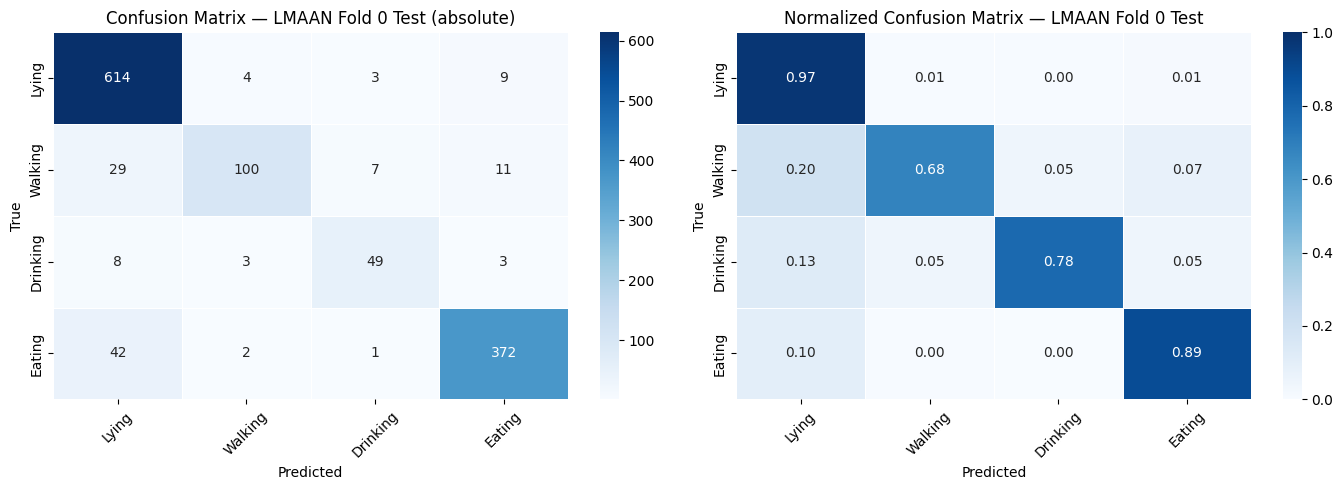

Figure saved: confusion_matrix_lmaan_fold0_test.png

Files saved:
  logits_audio_lmaan_validacao_4classes_cshift4p.csv
  oof_fold_comparison.csv
  confusion_matrix_lmaan_fold0_test.png

Fold selecionado: 0


In [6]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# ============================================================
# LMAAN — BEST OOF FOLD SELECTION + TEST EVALUATION
# Avoids the collapse issue of the final retrained model
# ============================================================

base_path    = r"C:\Users\franc\OneDrive\Desktop\logmel_512"
TARGET_WIDTH = 431
BATCH_SIZE   = 16

classes_4      = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying", "Walking", "Drinking", "Eating"]
class_to_idx   = {
    "deitado": 0, "deitadoac": 0, "dormindo": 0, "inativo": 0,
    "andando": 1, "bebendo": 2, "comendo": 3
}
idx_to_class = {0:"deitado", 1:"andando", 2:"bebendo", 3:"comendo"}
n_classes    = len(classes_4)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# Model (identical to the OOF setup)
# ============================================================

class SEBlock(nn.Module):
    def __init__(self, channel, reduction=16):
        super().__init__()
        hidden = max(channel // reduction, 1)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, hidden, bias=False), nn.ReLU(inplace=True),
            nn.Linear(hidden, channel, bias=False), nn.Sigmoid())
    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        return x * self.fc(y).view(b, c, 1, 1)

class AttentionPigNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(1,64,3,padding=1), nn.BatchNorm2d(64),
            nn.ReLU(), SEBlock(64), nn.MaxPool2d(2,2))
        self.layer2 = nn.Sequential(
            nn.Conv2d(64,128,3,padding=1), nn.BatchNorm2d(128),
            nn.ReLU(), SEBlock(128), nn.MaxPool2d(2,2))
        self.layer3 = nn.Sequential(
            nn.Conv2d(128,256,3,padding=1), nn.BatchNorm2d(256),
            nn.ReLU(), SEBlock(256), nn.MaxPool2d(2,2))
        self.layer4 = nn.Sequential(
            nn.Conv2d(256,512,3,padding=1), nn.BatchNorm2d(512),
            nn.ReLU(), SEBlock(512), nn.AdaptiveAvgPool2d((1,1)))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512,256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256,128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes))
    def forward(self, x):
        return self.classifier(self.layer4(
               self.layer3(self.layer2(self.layer1(x)))))

# ============================================================
# Dataset (identico ao OOF)
# ============================================================

def circular_shift_4parts_spec(spec, shift_parts):
    if shift_parts == 0 or shift_parts not in [1,2,3]: return spec
    if spec.ndim != 2 or spec.shape[1] < 8: return spec
    n = spec.shape[1]
    c1,c2,c3 = n//4, n//2, (3*n)//4
    parts = [spec[:,:c1], spec[:,c1:c2], spec[:,c2:c3], spec[:,c3:]]
    return np.concatenate(parts[shift_parts:] + parts[:shift_parts], axis=1)

class PigAudioDataset4(Dataset):
    def __init__(self, items, target_width=TARGET_WIDTH):
        self.items = items
        self.target_width = target_width
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        item = self.items[idx]
        spec = np.load(item["path"]).astype(np.float32)
        spec = circular_shift_4parts_spec(spec, item.get("shift_parts", 0))
        spec = (spec - np.min(spec)) / (np.max(spec) - np.min(spec) + 1e-8)
        if spec.shape[1] < self.target_width:
            spec = np.pad(spec, ((0,0),(0,self.target_width-spec.shape[1])),
                          mode="constant")
        else:
            spec = spec[:, :self.target_width]
        return (torch.from_numpy(spec).float().unsqueeze(0),
                int(item["label"]), item["window"])

# ============================================================
# 1. Identify the best fold using the consolidated OOF results
# ============================================================

print("\n=== Selecting best OOF fold ===")

df_oof_all = []
for fold in range(5):
    csv = f"logits_audio_oof_4classes_cshift4p_fold{fold}.csv"
    if not os.path.exists(csv):
        print(f"  Fold {fold}: arquivo not found — {csv}")
        continue
    df_f = pd.read_csv(csv)
    df_f["fold"] = fold
    df_oof_all.append(df_f)

if len(df_oof_all) == 0:
    raise FileNotFoundError(
        "Nenhum CSV OOF encontrado. Verifique os nomes dos files.")

prob_cols = [f"prob_{c}" for c in classes_4]

fold_metrics = []
for fold, df_f in enumerate(df_oof_all):
    y_true = df_f["label_real"].values
    y_pred = df_f[prob_cols].values.argmax(axis=1)

    macro_f1   = f1_score(y_true, y_pred, average="macro",     zero_division=0)
    walking_f1 = f1_score(y_true, y_pred, labels=[1],
                          average="macro", zero_division=0)
    drinking_f1= f1_score(y_true, y_pred, labels=[2],
                          average="macro", zero_division=0)

    fold_metrics.append({
        "fold": fold, "macro_f1": macro_f1,
        "walking_f1": walking_f1, "drinking_f1": drinking_f1
    })
    print(f"  Fold {fold}: Macro F1={macro_f1:.4f} | "
          f"Walking F1={walking_f1:.4f} | Drinking F1={drinking_f1:.4f}")

df_fold_metrics = pd.DataFrame(fold_metrics)

# Selection criterion: highest Macro F1
# (altere para "walking_f1" se quiser priorizar Walking)
best_fold = int(df_fold_metrics.loc[
    df_fold_metrics["macro_f1"].idxmax(), "fold"])

print(f"\nBest fold selecionado: Fold {best_fold} "
      f"(Macro F1 = {df_fold_metrics.loc[best_fold,'macro_f1']:.4f})")

# ============================================================
# 2. Load the model from the best fold
# ============================================================

model_path = (f"AttentionPigNet_LMAAN_4classes_CShift4P_OOF_fold"
              f"{best_fold}.pth")

if not os.path.exists(model_path):
    raise FileNotFoundError(f"Modelo not found: {model_path}")

checkpoint = torch.load(model_path, map_location=device)
model = AttentionPigNet(num_classes=n_classes).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"\nModelo loaded: {model_path}")

# ============================================================
# 3. Load the synchronized test set
# ============================================================

all_file_lookup = {}
for cls in os.listdir(base_path):
    cls_dir = os.path.join(base_path, cls)
    if not os.path.isdir(cls_dir): continue
    cls_low = cls.lower().strip()
    if cls_low not in class_to_idx: continue
    for f in os.listdir(cls_dir):
        if f.endswith(".npy"):
            all_file_lookup[f] = (os.path.join(cls_dir, f), cls_low)

with open("windows_validacao.txt", "r", encoding="utf-8") as f:
    windows_teste = [l.strip() for l in f if l.strip()]

test_items, missing = [], []
for j in windows_teste:
    if j not in all_file_lookup:
        missing.append(j)
        continue
    path, cls = all_file_lookup[j]
    if cls not in class_to_idx: continue
    test_items.append({
        "path": path, "label": class_to_idx[cls],
        "classe": idx_to_class[class_to_idx[cls]],
        "window": j, "shift_parts": 0
    })

print(f"\nTest: {len(test_items)} windows "
      f"({len(missing)} not found)")
print(pd.Series([i["classe"] for i in test_items]).value_counts().to_string())

if len(missing) > 0:
    print(f"\nExemplos not founds: {missing[:5]}")

# ============================================================
# 4. Test inference
# ============================================================

test_ds     = PigAudioDataset4(test_items)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=0)

softmax = nn.Softmax(dim=1)
all_probs, all_labels, all_windows = [], [], []

with torch.no_grad():
    for inputs, labels, windows in test_loader:
        probs = softmax(model(inputs.to(device))).cpu().numpy()
        all_probs.append(probs)
        all_labels.extend(labels.numpy())
        all_windows.extend(list(windows))

all_probs  = np.vstack(all_probs)
all_labels = np.asarray(all_labels, dtype=int)
y_pred     = all_probs.argmax(axis=1)

# ============================================================
# 5. Report
# ============================================================

print(f"\n=== LMAAN (fold {best_fold}) — synchronized test ===")
print(classification_report(
    all_labels, y_pred,
    labels=list(range(n_classes)),
    target_names=classes_4,
    digits=4, zero_division=0))

# ============================================================
# 6. Matrizes de confusao
# ============================================================

cm   = confusion_matrix(all_labels, y_pred, labels=np.arange(n_classes))
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_n = np.nan_to_num(cm_n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, fmt, title in zip(
    axes, [cm, cm_n], ["d", ".2f"],
    [f"Confusion Matrix — LMAAN Fold {best_fold} Test (absolute)",
     f"Normalized Confusion Matrix — LMAAN Fold {best_fold} Test"]
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues",
                xticklabels=class_names_en, yticklabels=class_names_en,
                vmin=(0 if fmt==".2f" else None),
                vmax=(1 if fmt==".2f" else None),
                linewidths=0.5, linecolor="white", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
fig_path = f"confusion_matrix_lmaan_fold{best_fold}_test.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path}")

# ============================================================
# 7. Save test logits
# ============================================================

df_out = pd.DataFrame(all_probs,
                      columns=[f"prob_{c}" for c in classes_4])
df_out["window"]     = all_windows
df_out["label_real"] = all_labels
df_out = df_out[["window","label_real"] + [f"prob_{c}" for c in classes_4]]
df_out.to_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv", index=False)

df_fold_metrics.to_csv("oof_fold_comparison.csv", index=False)

print("\nFiles saved:")
print(f"  logits_audio_lmaan_validacao_4classes_cshift4p.csv")
print(f"  oof_fold_comparison.csv")
print(f"  {fig_path}")
print(f"\nFold selecionado: {best_fold}")

## Consolidated Text Summary of Unimodal and Fusion Test Results

This cell stores a textual summary of the main classification reports and numerical results obtained across the accelerometer, audio, and fusion experiments. Although it is formatted as a code cell in the notebook, it functions as an experimental record of the reported metrics and supports comparison with the final tables used in the manuscript.


In [ ]:

=== Random Forest + Raw Signal Augmentation - OOF ===
              precision    recall  f1-score   support

     deitado     0.9745    0.9255    0.9494      3344
     andando     0.7000    0.8255    0.7576       636
     bebendo     0.6210    0.6886    0.6531       395
     comendo     0.8934    0.8978    0.8956      2260

    accuracy                         0.8924      6635
   macro avg     0.7972    0.8344    0.8139      6635
weighted avg     0.8995    0.8924    0.8950      6635


Total windows selected for augmentation: 1031

Full original training set by windows:
atividade
deitado    3344
comendo    2260
andando     636
bebendo     395
Name: count, dtype: int64

Full training set after window-level augmentation:
atividade
deitado    3344
comendo    2260
andando    1272
bebendo     790
Name: count, dtype: int64

Training final RF with raw signal augmentation...

=== Random Forest + Raw Signal Augmentation - synchronized test ===
              precision    recall  f1-score   support

     deitado     0.9700    0.9254    0.9472       630
     andando     0.8182    0.7959    0.8069       147
     bebendo     0.4935    0.6032    0.5429        63
     comendo     0.8830    0.9233    0.9027       417

    accuracy                         0.8934      1257
   macro avg     0.7912    0.8119    0.7999      1257
weighted avg     0.8995    0.8934    0.8958      1257


Training final model with AD-BL-SMOTE...

=== AD-BL-SMOTE RF — synchronized test ===
              precision    recall  f1-score   support

     deitado     0.9669    0.9270    0.9465       630
     andando     0.8095    0.8095    0.8095       147
     bebendo     0.4684    0.5873    0.5211        63
     comendo     0.8946    0.9161    0.9052       417

    accuracy                         0.8926      1257
   macro avg     0.7848    0.8100    0.7956      1257
weighted avg     0.8995    0.8926    0.8955      1257


=== Resumo ===
                Model  Accuracy  Macro_F1  Weighted_F1
 AD-BL-SMOTE RF — OOF  0.889525  0.808079     0.893531
AD-BL-SMOTE RF — Test  0.892601  0.795595     0.895473



     === RF + Circular Shift 4 Parts + Combined Features - synchronized test ===
              precision    recall  f1-score   support

     deitado     0.9769    0.9413    0.9588       630
     andando     0.8403    0.8231    0.8316       147
     bebendo     0.5625    0.7143    0.6294        63
     comendo     0.9249    0.9448    0.9348       417

    accuracy                         0.9173      1257
   macro avg     0.8261    0.8559    0.8386      1257
weighted avg     0.9229    0.9173    0.9194      1257

    === Random Forest + Moderate SMOTE - OOF ===
              precision    recall  f1-score   support

     deitado     0.9685    0.9363    0.9521      3344
     andando     0.7372    0.7940    0.7646       636
     bebendo     0.6216    0.6987    0.6579       395
     comendo     0.9001    0.9053    0.9027      2260

    accuracy                         0.8980      6635
   macro avg     0.8069    0.8336    0.8193      6635
weighted avg     0.9024    0.8980    0.8998      6635


=== Random Forest + Moderate SMOTE - synchronized test ===
              precision    recall  f1-score   support

     deitado     0.9671    0.9333    0.9499       630
     andando     0.8188    0.7687    0.7930       147
     bebendo     0.4930    0.5556    0.5224        63
     comendo     0.8773    0.9257    0.9008       417

    accuracy                         0.8926      1257
   macro avg     0.7890    0.7958    0.7915      1257
weighted avg     0.8962    0.8926    0.8938      1257


=== Random Forest + Stronger SMOTE - OOF ===
              precision    recall  f1-score   support

     deitado     0.9719    0.9312    0.9511      3344
     andando     0.7115    0.8066    0.7561       636
     bebendo     0.5845    0.7266    0.6479       395
     comendo     0.9072    0.8907    0.8989      2260

    accuracy                         0.8933      6635
   macro avg     0.7938    0.8388    0.8135      6635
weighted avg     0.9018    0.8933    0.8966      6635

=== Random Forest + SMOTE + Under - OOF ===
              precision    recall  f1-score   support

     deitado     0.9767    0.9166    0.9457      3344
     andando     0.6807    0.8145    0.7416       636
     bebendo     0.5480    0.7367    0.6285       395
     comendo     0.8993    0.8774    0.8882      2260

    accuracy                         0.8827      6635
   macro avg     0.7762    0.8363    0.8010      6635
weighted avg     0.8965    0.8827    0.8877      6635


== Balanced Random Forest 700/classe - OOF ===
              precision    recall  f1-score   support

     deitado     0.9798    0.9007    0.9386      3344
     andando     0.6654    0.8223    0.7356       636
     bebendo     0.5060    0.7418    0.6016       395
     comendo     0.8994    0.8739    0.8864      2260

    accuracy                         0.8746      6635
   macro avg     0.7627    0.8347    0.7906      6635
weighted avg     0.8941    0.8746    0.8813      6635


Balancing the full training set to 700 samples/class...
Class 0 (deitado): 3344 -> 700 (without replacement)
Class 1 (andando): 636 -> 700 (with replacement)
Class 2 (bebendo): 395 -> 700 (with replacement)
Class 3 (comendo): 2260 -> 700 (without replacement)

Final distribution of the balanced training set:
Counter({np.int64(0): 700, np.int64(2): 700, np.int64(1): 700, np.int64(3): 700})

Training final RF with balanced training set 700/classe...


    === Random Forest synchronized test - 4 classes without running ===
              precision    recall  f1-score   support

     deitado     0.9702    0.9317    0.9506       630
     andando     0.8214    0.7823    0.8014       147
     bebendo     0.4928    0.5397    0.5152        63
     comendo     0.8736    0.9281    0.9000       417

    accuracy                         0.8934      1257
   macro avg     0.7895    0.7954    0.7918      1257
weighted avg     0.8968    0.8934    0.8945      1257



=== Balanced Random Forest 700/classe - synchronized test ===
              precision    recall  f1-score   support

     deitado     0.9726    0.9032    0.9366       630
     andando     0.7667    0.7823    0.7744       147
     bebendo     0.3868    0.6508    0.4852        63
     comendo     0.8894    0.8873    0.8884       417

    accuracy                         0.8711      1257
   macro avg     0.7539    0.8059    0.7711      1257
weighted avg     0.8916    0.8711    0.8790      1257



=== Random Forest + Raw Signal Augmentation - OOF ===
              precision    recall  f1-score   support

     deitado     0.9745    0.9255    0.9494      3344
     andando     0.7000    0.8255    0.7576       636
     bebendo     0.6210    0.6886    0.6531       395
     comendo     0.8934    0.8978    0.8956      2260

    accuracy                         0.8924      6635
   macro avg     0.7972    0.8344    0.8139      6635
weighted avg     0.8995    0.8924    0.8950      6635


Total windows selected for augmentation: 1031

Full original training set by windows:
atividade
deitado    3344
comendo    2260
andando     636
bebendo     395
Name: count, dtype: int64

Full training set after window-level augmentation:
atividade
deitado    3344
comendo    2260
andando    1272
bebendo     790
Name: count, dtype: int64

Training final RF with raw signal augmentation...

=== Random Forest + Raw Signal Augmentation (2 partes)- synchronized test ===
              precision    recall  f1-score   support

     deitado     0.9700    0.9254    0.9472       630
     andando     0.8182    0.7959    0.8069       147
     bebendo     0.4935    0.6032    0.5429        63
     comendo     0.8830    0.9233    0.9027       417

    accuracy                         0.8934      1257
   macro avg     0.7912    0.8119    0.7999      1257
weighted avg     0.8995    0.8934    0.8958      1257


=== Random Forest + Circular Shift 4 Parts - OOF ===
              precision    recall  f1-score   support

     deitado     0.9748    0.9264    0.9500      3344
     andando     0.6897    0.8318    0.7541       636
     bebendo     0.6154    0.7089    0.6588       395
     comendo     0.9002    0.8903    0.8952      2260

    accuracy                         0.8921      6635
   macro avg     0.7950    0.8393    0.8145      6635
weighted avg     0.9007    0.8921    0.8952      6635

                 Final results-    LMAAN

            precision    recall  f1-score   support

     deitado     0.8860    0.9746    0.9282       630
     andando     0.9174    0.6803    0.7812       147
     bebendo     0.8167    0.7778    0.7967        63
     comendo     0.9418    0.8921    0.9163       417

    accuracy                         0.9029      1257
   macro avg     0.8905    0.8312    0.8556      1257
weighted avg     0.9047    0.9029    0.9005      1257








=== Random Forest + Moderate SMOTE - synchronized test ===
              precision    recall  f1-score   support

     deitado     0.9671    0.9333    0.9499       630
     andando     0.8188    0.7687    0.7930       147
     bebendo     0.4930    0.5556    0.5224        63
     comendo     0.8773    0.9257    0.9008       417

    accuracy                         0.8926      1257
   macro avg     0.7890    0.7958    0.7915      1257
weighted avg     0.8962    0.8926    0.8938      1257

Treinando RF final com circular shift augmentation...

=== Random Forest + Circular Shift Augmentation - synchronized test ===
              precision    recall  f1-score   support

     deitado     0.9717    0.9270    0.9488       630
     andando     0.8182    0.7959    0.8069       147
     bebendo     0.4938    0.6349    0.5556        63
     comendo     0.8935    0.9257    0.9093       417

    accuracy                         0.8966      1257
   macro avg     0.7943    0.8209    0.8051      1257
weighted avg     0.9039    0.8966    0.8994      1257


Treinando MLP final (Jin et al.)...
C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(

=== Jin et al. MLP + AD-BL-SMOTE — Test ===
              precision    recall  f1-score   support

     deitado     0.9800    0.9333    0.9561       630
     andando     0.7262    0.8299    0.7746       147
     bebendo     0.5000    0.8413    0.6272        63
     comendo     0.9556    0.8777    0.9150       417

    accuracy                         0.8982      1257
   macro avg     0.7905    0.8706    0.8182      1257
weighted avg     0.9182    0.8982    0.9048      1257


Deitado  & 96.70 & 93.02 & 94.82 & 630 \\
Andando  & 78.47 & 76.87 & 77.66 & 147 \\
Bebendo  & 50.70 & 57.14 & 53.73 &  63 \\
Comendo  & 87.50 & 92.33 & 89.85 & 417 \\

\textbf{Accuracy}     & \multicolumn{3}{c}{88.74} & 1270 \\
\textbf{Macro avg}    & 78.23 & 74.64 & 75.94 & 1270 \\
\textbf{Weighted avg} & 89.09 & 88.74 & 88.85 & 1270 \\

=== MLP (Jin) + features do estudo — Test ===
              precision    recall  f1-score   support

     deitado     0.9663    0.9111    0.9379       630
     andando     0.7108    0.8027    0.7540       147
     bebendo     0.3953    0.5397    0.4564        63
     comendo     0.9100    0.8969    0.9034       417

    accuracy                         0.8751      1257
   macro avg     0.7456    0.7876    0.7629      1257
weighted avg     0.8891    0.8751    0.8808      1257



=== RF + features combinadas + AD-BL-SMOTE ===
              precision    recall  f1-score   support

     deitado     0.9709    0.9524    0.9615       630
     andando     0.8356    0.8299    0.8328       147
     bebendo     0.5857    0.6508    0.6165        63
     comendo     0.9243    0.9376    0.9310       417

    accuracy                         0.9181      1257
   macro avg     0.8291    0.8427    0.8354      1257
weighted avg     0.9203    0.9181    0.9190      1257

=== RF + Circular Shift 4 Parts + Combined Features - synchronized test ===++++++++++++++++++++++++++++
              precision    recall  f1-score   support

     deitado     0.9769    0.9413    0.9588       630
     andando     0.8403    0.8231    0.8316       147
     bebendo     0.5625    0.7143    0.6294        63
     comendo     0.9249    0.9448    0.9348       417

    accuracy                         0.9173      1257
   macro avg     0.8261    0.8559    0.8386      1257
weighted avg     0.9229    0.9173    0.9194      1257


--- LMAAN 4 CLASSES --- (Running + walking)
              precision    recall  f1-score   support

     deitado     0.8900    0.9685    0.9276       635
  loastion     0.7049    0.6466    0.6745       133
     bebendo     0.6406    0.5541    0.5942        74
     comendo     0.9542    0.8762    0.9135       428

    accuracy                         0.8795      1270
   macro avg     0.7974    0.7613    0.7775      1270
weighted avg     0.8777    0.8795    0.8769      1270









## Bootstrap Comparison of F1-Weighted Fusion Against Unimodal Models

This cell performs a bootstrap-based statistical comparison between the weighted multimodal fusion strategy and the unimodal accelerometer/audio models. It computes performance gains over resampled test sets and generates publication-style boxplots. The analysis assesses whether fusion improves performance beyond the individual modalities.


Aligned test set: 1257 windows

Computing bootstrap: Simple fusion vs RF...

Metric           Mean gain                 IC 95%        p
------------------------------------------------------------
Lying                  +1.44pp  [  +0.38,   +2.52]  0.0040*
Walking                +1.69pp  [  -2.84,   +6.07]  0.2190
Drinking              +17.91pp  [ +10.07,  +25.59]  0.0000*
Eating                 +2.28pp  [  +0.57,   +4.02]  0.0040*
Macro F1               +5.83pp  [  +3.03,   +8.57]  0.0000*
Weighted F1           +2.57pp  [  +1.18,   +3.91]  0.0000*
Accuracy               +2.87pp  [  +1.43,   +4.30]  0.0000*


C:\Users\franc\AppData\Local\Temp\ipykernel_33816\3527828530.py:113: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


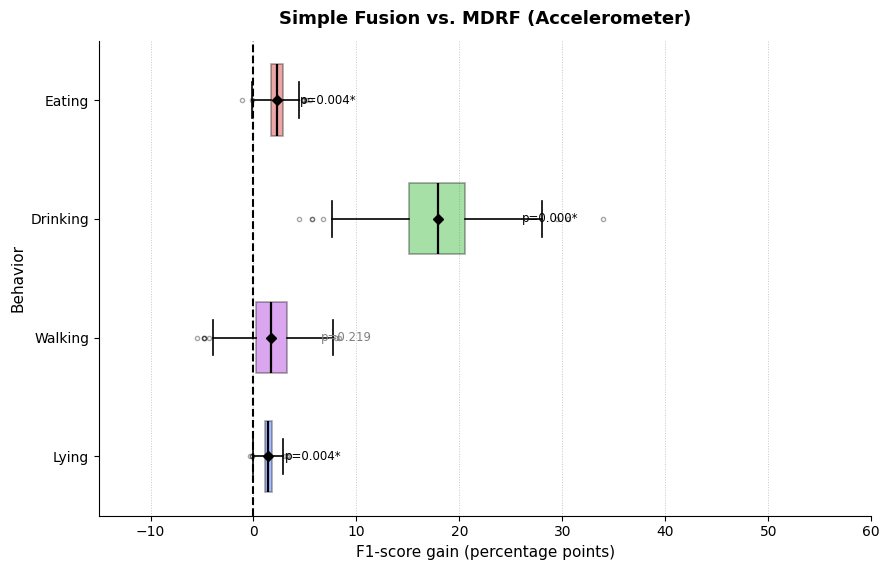

Figure saved: boxplot_fusion_vs_rf.png

Computing bootstrap: Simple fusion vs LMAAN...

Metric           Mean gain                 IC 95%        p
------------------------------------------------------------
Lying                  +4.47pp  [  +3.28,   +5.69]  0.0000*
Walking                +6.81pp  [  +2.25,  +11.94]  0.0010*
Drinking               +1.27pp  [  -5.76,   +8.85]  0.3590
Eating                 +4.16pp  [  +2.38,   +6.12]  0.0000*
Macro F1               +4.18pp  [  +1.55,   +6.85]  0.0010*
Weighted F1           +4.48pp  [  +2.99,   +5.94]  0.0000*
Accuracy               +4.30pp  [  +2.86,   +5.73]  0.0000*


C:\Users\franc\AppData\Local\Temp\ipykernel_33816\3527828530.py:113: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


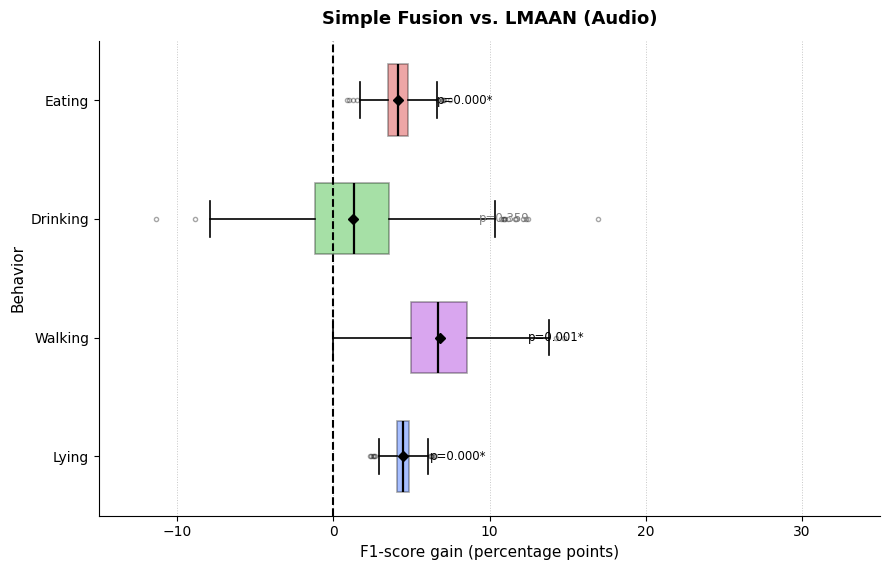

Figure saved: boxplot_fusion_vs_lmaan.png


In [17]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score, accuracy_score
from sklearn.utils import resample

# ============================================================
# GAIN BOXPLOT —  WEIGHTED  FUSION  vs UNIMODAIS
# Manuscript style — high resolution
# 4 classes: lying, walking, drinking, eating
# ============================================================

classes_modelo  = ["deitado", "andando", "bebendo", "comendo"]
class_names_en  = ["Lying",   "Walking", "Drinking", "Eating"]
labels_order    = [0, 1, 2, 3]
n_classes       = len(classes_modelo)
N_ITERATIONS    = 1000
RANDOM_STATE    = 42
prob_cols       = [f"prob_{c}" for c in classes_modelo]

# ============================================================
# 1. Load logits
# ============================================================

df_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv")
df_aud = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv")

df_sen["window"] = df_sen["window"].astype(str)
df_aud["window"] = df_aud["window"].astype(str)

df = pd.merge(
    df_sen[["window","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_aud[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window", how="inner"
)

print(f"Aligned test set: {len(df)} windows")

y_true     = df["label_real"].values.astype(int)
P_sen      = df[[f"s_{c}" for c in prob_cols]].values
P_aud      = df[[f"a_{c}" for c in prob_cols]].values
P_fus      = (P_sen + P_aud) / 2.0

y_pred_sen = P_sen.argmax(axis=1)
y_pred_aud = P_aud.argmax(axis=1)
y_pred_fus = P_fus.argmax(axis=1)

# ============================================================
# 2. Class-wise bootstrap and global metrics
# ============================================================

def bootstrap_gains(y_true, y_ref, y_multi,
                    n_iter=N_ITERATIONS, random_state=RANDOM_STATE):
    """
    Returns gain distributions (F1 per class, Macro F1,
    F1 ponderado e Accuracy) em pontos percentuais.
    """
    rng     = np.random.RandomState(random_state)
    indices = np.arange(len(y_true))

    gains_class    = {i: [] for i in range(n_classes)}
    gains_macro    = []
    gains_weighted = []
    gains_acc      = []

    for _ in range(n_iter):
        idx = resample(indices, replace=True,
                       n_samples=len(indices), stratify=y_true,
                       random_state=rng.randint(0, 2**31))
        yb = y_true[idx]
        yr = y_ref[idx]
        ym = y_multi[idx]

        f1r = f1_score(yb, yr, average=None,
                       labels=labels_order, zero_division=0)
        f1m = f1_score(yb, ym, average=None,
                       labels=labels_order, zero_division=0)

        for i in range(n_classes):
            gains_class[i].append((f1m[i] - f1r[i]) * 100)

        gains_macro.append((
            f1_score(yb, ym, average="macro",    zero_division=0) -
            f1_score(yb, yr, average="macro",    zero_division=0)) * 100)
        gains_weighted.append((
            f1_score(yb, ym, average="weighted", zero_division=0) -
            f1_score(yb, yr, average="weighted", zero_division=0)) * 100)
        gains_acc.append((
            accuracy_score(yb, ym) - accuracy_score(yb, yr)) * 100)

    return gains_class, gains_macro, gains_weighted, gains_acc

# ============================================================
# 3. Funcao de plot (estilo do usuario)
# ============================================================

# Paleta per class (ordem: Lying, Walking, Drinking, Eating)
COLORS = ['#0047FF', '#9400D3', '#00A800', '#CC0000']

def plot_gain_boxplot(gains_class, title, save_path, xlim=(-15, 60)):

    labels_plot = class_names_en
    data_plot   = [np.array(gains_class[i]) for i in range(n_classes)]

    fig, ax = plt.subplots(figsize=(9, 5.8))

    bp = ax.boxplot(
        data_plot,
        vert=False,
        patch_artist=True,
        labels=labels_plot,
        showmeans=True,
        meanline=False,
        widths=0.6,
        flierprops=dict(marker='o', markersize=3, alpha=0.35),
        medianprops=dict(color='black', linewidth=1.6),
        meanprops=dict(marker='D', markerfacecolor='black',
                       markeredgecolor='black', markersize=5),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
        boxprops=dict(linewidth=1.2)
    )

    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.35)
        patch.set_edgecolor('black')
        patch.set_linewidth(1.2)

    ax.axvline(0, color='black', linestyle='--', linewidth=1.5)

    # p-valor anotado a direita de cada box
    for i, data in enumerate(data_plot):
        g   = np.array(data)
        p   = np.mean(g <= 0)
        sig = "*" if p < 0.05 else ""
        x_pos = np.percentile(g, 97.5) + 0.5
        ax.text(x_pos, i + 1, f"p={p:.3f}{sig}",
                va='center', ha='left', fontsize=8.5,
                color='black' if p < 0.05 else 'gray')

    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('F1-score gain (percentage points)', fontsize=11)
    ax.set_ylabel('Behavior', fontsize=11)
    ax.tick_params(axis='both', labelsize=10)
    ax.set_xlim(xlim)
    ax.grid(axis='x', linestyle=':', linewidth=0.7, alpha=0.7)
    ax.grid(axis='y', visible=False)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Figure saved: {save_path}")

# ============================================================
# 4. Simple fusion vs RF
# ============================================================

print("\nComputing bootstrap: Simple fusion vs RF...")
gc_rf, gm_rf, gw_rf, ga_rf = bootstrap_gains(
    y_true, y_pred_sen, y_pred_fus)

# Numerical summary
print(f"\n{'Metric':<16} {'Mean gain':>12} {'IC 95%':>22} {'p':>8}")
print("-"*60)
for i, name in enumerate(class_names_en):
    g  = np.array(gc_rf[i])
    p  = np.mean(g <= 0)
    print(f"{name:<16} {np.mean(g):>+11.2f}pp  "
          f"[{np.percentile(g,2.5):>+7.2f}, "
          f"{np.percentile(g,97.5):>+7.2f}]  {p:.4f}"
          f"{'*' if p<0.05 else ''}")
for nome, g in [("Macro F1",     gm_rf),
                ("Weighted F1", gw_rf),
                ("Accuracy",     ga_rf)]:
    g  = np.array(g)
    p  = np.mean(g <= 0)
    print(f"{nome:<16} {np.mean(g):>+11.2f}pp  "
          f"[{np.percentile(g,2.5):>+7.2f}, "
          f"{np.percentile(g,97.5):>+7.2f}]  {p:.4f}"
          f"{'*' if p<0.05 else ''}")

plot_gain_boxplot(
    gc_rf,
    title="Simple Fusion vs. MDRF (Accelerometer)",
    save_path="boxplot_fusion_vs_rf.png",
    xlim=(-15, 60)
)

# ============================================================
# 5. Simple fusion vs LMAAN
# ============================================================

print("\nComputing bootstrap: Simple fusion vs LMAAN...")
gc_lm, gm_lm, gw_lm, ga_lm = bootstrap_gains(
    y_true, y_pred_aud, y_pred_fus)

print(f"\n{'Metric':<16} {'Mean gain':>12} {'IC 95%':>22} {'p':>8}")
print("-"*60)
for i, name in enumerate(class_names_en):
    g  = np.array(gc_lm[i])
    p  = np.mean(g <= 0)
    print(f"{name:<16} {np.mean(g):>+11.2f}pp  "
          f"[{np.percentile(g,2.5):>+7.2f}, "
          f"{np.percentile(g,97.5):>+7.2f}]  {p:.4f}"
          f"{'*' if p<0.05 else ''}")
for nome, g in [("Macro F1",     gm_lm),
                ("Weighted F1", gw_lm),
                ("Accuracy",     ga_lm)]:
    g  = np.array(g)
    p  = np.mean(g <= 0)
    print(f"{nome:<16} {np.mean(g):>+11.2f}pp  "
          f"[{np.percentile(g,2.5):>+7.2f}, "
          f"{np.percentile(g,97.5):>+7.2f}]  {p:.4f}"
          f"{'*' if p<0.05 else ''}")

plot_gain_boxplot(
    gc_lm,
    title="Simple Fusion vs. LMAAN (Audio)",
    save_path="boxplot_fusion_vs_lmaan.png",
    xlim=(-15, 35)
)

## Confidence-Weighted Dynamic Fusion Following Kuncheva-Style Principles

This cell implements a dynamic fusion baseline in which each modality contributes according to its prediction confidence. Inspired by confidence-based combination principles, it combines audio and accelerometer probability distributions at the sample level and evaluates whether adaptive weighting improves over static or unimodal strategies.


Aligned test set: 1257 windows

Static OOF weights by class:
  deitado: W_sensor=0.5103  W_audio=0.4897
  andando: W_sensor=0.5611  W_audio=0.4389
  bebendo: W_sensor=0.5323  W_audio=0.4677
  comendo: W_sensor=0.5077  W_audio=0.4923

Mean confidence margin — sensor: 0.6350 | audio: 0.6649

DCS-MAX: sensor selected in 47.6% of samples

RF (sensor)          Acc=91.73%  MacroF1=83.86%  | deitado=95.88 andando=83.16 bebendo=62.94 comendo=93.48
LMAAN (audio)        Acc=90.29%  MacroF1=85.56%  | deitado=92.82 andando=78.12 bebendo=79.67 comendo=91.63
Simple fusion        Acc=94.59%  MacroF1=89.73%  | deitado=97.3 andando=84.89 bebendo=80.95 comendo=95.76
DCS-MAX              Acc=94.35%  MacroF1=89.49%  | deitado=96.69 andando=84.48 bebendo=80.62 comendo=96.19
CWF-Equal            Acc=94.43%  MacroF1=89.60%  | deitado=97.0 andando=83.94 bebendo=81.6 comendo=95.88
CWF-OOF              Acc=94.35%  MacroF1=89.38%  | deitado=97.07 andando=83.75 bebendo=80.95 comendo=95.75

CWF-Equal vs RF (sensor

C:\Users\franc\AppData\Local\Temp\ipykernel_33816\1102404437.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


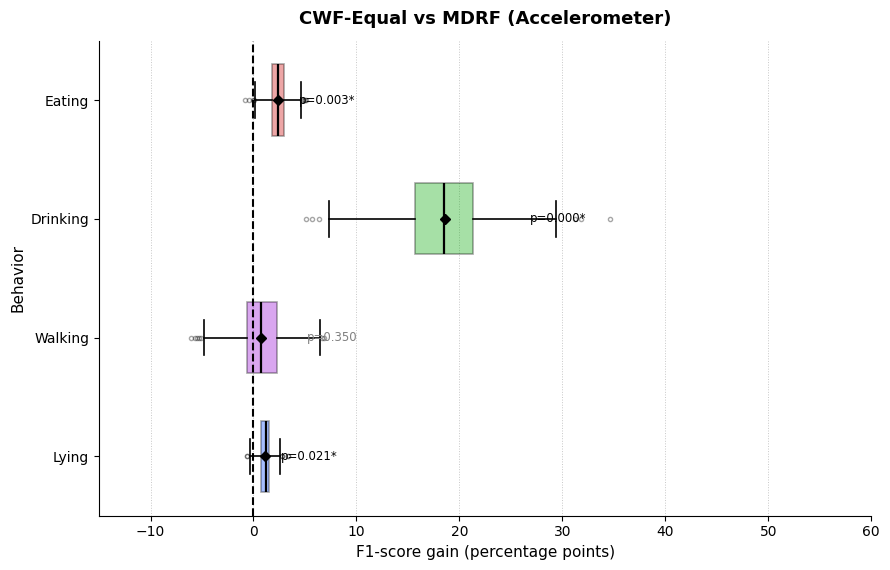

Figure saved: boxplot_cwf_vs_rf.png


C:\Users\franc\AppData\Local\Temp\ipykernel_33816\1102404437.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


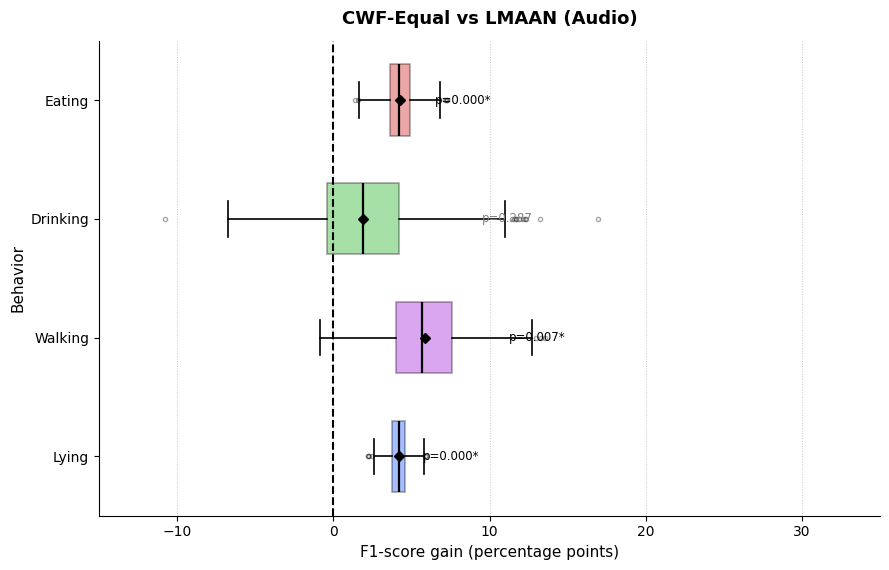

Figure saved: boxplot_cwf_vs_lmaan.png


C:\Users\franc\AppData\Local\Temp\ipykernel_33816\1102404437.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


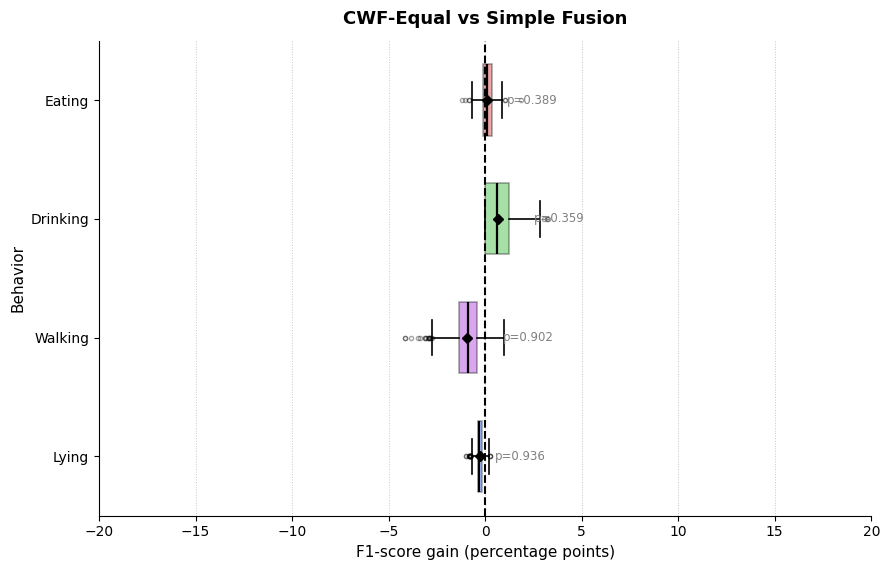

Figure saved: boxplot_cwf_vs_simplefusion.png

=== Comparison table ===
       Modelo  deitado  andando  bebendo  comendo  Accuracy  Macro_F1  Weighted_F1
  RF (sensor)    95.88    83.16    62.94    93.48     91.73     83.86        91.94
LMAAN (audio)    92.82    78.12    79.67    91.63     90.29     85.56        90.05
Simple fusion    97.30    84.89    80.95    95.76     94.59     89.73        94.52
      DCS-MAX    96.69    84.48    80.62    96.19     94.35     89.49        94.29
    CWF-Equal    97.00    83.94    81.60    95.88     94.43     89.60        94.33
      CWF-OOF    97.07    83.75    80.95    95.75     94.35     89.38        94.27

CSV saved: summary_cwf_fusion.csv
CWF-Equal logits saved: logits_cwf_equal_validacao_4classes.csv


In [18]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, confusion_matrix
)
from sklearn.utils import resample
import seaborn as sns

# ============================================================
# CONFIDENCE-WEIGHTED DYNAMIC FUSION — Kuncheva (2002)
#
# For each sample i and modality m:
#   Δ_m(i) = max_c p^(m)(i,c) - 1/C   (confidence margin)
#
# Dynamic weight per sample and class:
#   W̃_m(c,i) = W_m(c) × Δ_m(i)
#   W*_m(c,i) = W̃_m(c,i) / Σ_m' W̃_m'(c,i)
#
# Final probability:
#   p_fus(i,c) = Σ_m W*_m(c,i) × p^(m)(i,c)
#
# Three compared variants:
#   1. DCS-MAX   : selects the modality with the highest Δ (hard selection)
#   2. CWF-Equal : equal static weights × confidence (soft, without leakage)
#   3. CWF-OOF   : static weights OOF × confidence (soft, with OOF)
# ============================================================

classes_modelo  = ["deitado", "andando", "bebendo", "comendo"]
class_names_en  = ["Lying",   "Walking", "Drinking", "Eating"]
labels_order    = [0, 1, 2, 3]
n_classes       = len(classes_modelo)
N_BOOTSTRAP     = 1000
RANDOM_STATE    = 42
prob_cols       = [f"prob_{c}" for c in classes_modelo]
EPS             = 1e-8

# ============================================================
# 1. Load test and OOF logits
# ============================================================

df_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv")
df_aud = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv")

df_sen["window"] = df_sen["window"].astype(str)
df_aud["window"] = df_aud["window"].astype(str)

df_test = pd.merge(
    df_sen[["window","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_aud[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window", how="inner"
)
print(f"Aligned test set: {len(df_test)} windows")

y_test    = df_test["label_real"].values.astype(int)
P_sen     = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud     = df_test[[f"a_{c}" for c in prob_cols]].values

# Previously computed references
y_pred_sen = P_sen.argmax(axis=1)
y_pred_aud = P_aud.argmax(axis=1)
y_pred_sim = ((P_sen + P_aud) / 2).argmax(axis=1)

# ============================================================
# 2. Pesos estaticos OOF (Bootstrap F1 Evidence — ja calculados)
# ============================================================

df_oof_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv")
df_oof_aud = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv")

def extrair_id(nome):
    import re
    m = re.search(r"-j(\d+)", str(nome))
    return int(m.group(1)) if m else None

df_oof_aud["window_id"] = df_oof_aud["window"].apply(extrair_id)
df_oof_sen["window_id"] = df_oof_sen["window"].astype(int)

df_oof = pd.merge(
    df_oof_sen[["window_id","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_oof_aud[["window_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window_id", how="inner"
)

y_oof      = df_oof["label_real"].values.astype(int)
P_oof_sen  = df_oof[[f"s_{c}" for c in prob_cols]].values
P_oof_aud  = df_oof[[f"a_{c}" for c in prob_cols]].values
yp_oof_sen = P_oof_sen.argmax(axis=1)
yp_oof_aud = P_oof_aud.argmax(axis=1)

# OOF class-wise F1
f1_oof_sen = np.array([f1_score(y_oof, yp_oof_sen, labels=[c],
    average="macro", zero_division=0) for c in range(n_classes)])
f1_oof_aud = np.array([f1_score(y_oof, yp_oof_aud, labels=[c],
    average="macro", zero_division=0) for c in range(n_classes)])

# Pesos OOF normalizados per class
W_oof_sen = f1_oof_sen / (f1_oof_sen + f1_oof_aud + EPS)
W_oof_aud = f1_oof_aud / (f1_oof_sen + f1_oof_aud + EPS)

print("\nStatic OOF weights by class:")
for c, nm in enumerate(classes_modelo):
    print(f"  {nm}: W_sensor={W_oof_sen[c]:.4f}  W_audio={W_oof_aud[c]:.4f}")

# ============================================================
# 3. Margem de instantaneous confidence
# Δ_m(i) = max_c p^(m)(i,c) - 1/C
# ============================================================

baseline = 1.0 / n_classes

delta_sen = P_sen.max(axis=1) - baseline   # shape (N,)
delta_aud = P_aud.max(axis=1) - baseline

# Clamp: margem nunca negativa (classificador no minimo na baseline)
delta_sen = np.clip(delta_sen, 0, None)
delta_aud = np.clip(delta_aud, 0, None)

print(f"\nMean confidence margin — sensor: {delta_sen.mean():.4f} "
      f"| audio: {delta_aud.mean():.4f}")

# ============================================================
# 4. Variante 1 — DCS-MAX (hard selection)
# Seleciona a modality com maior Δ por amostra
# ============================================================

mask_sen = (delta_sen >= delta_aud)   # True → usar sensor
P_dcs = np.where(mask_sen[:, None], P_sen, P_aud)
y_pred_dcs = P_dcs.argmax(axis=1)

print(f"\nDCS-MAX: sensor selected in "
      f"{mask_sen.mean()*100:.1f}% of samples")

# ============================================================
# 5. Variante 2 — CWF-Equal (equal static weights × confidence)
# W̃_m(i) = 0.5 × Δ_m(i)   → simplifica para Δ_m(i)
# W*_sen(i) = Δ_sen / (Δ_sen + Δ_aud)
# ============================================================

denom_eq = delta_sen + delta_aud + EPS
w_sen_eq = delta_sen / denom_eq          # shape (N,)
w_aud_eq = delta_aud / denom_eq

P_cwf_eq = (w_sen_eq[:, None] * P_sen +
             w_aud_eq[:, None] * P_aud)
y_pred_cwf_eq = P_cwf_eq.argmax(axis=1)

# ============================================================
# 6. Variante 3 — CWF-OOF (static weights OOF × confidence)
# W̃_m(c,i) = W_oof_m(c) × Δ_m(i)
# Pesos variam por amostra E per class
# ============================================================

# W̃ por amostra e per class
Wt_sen = np.outer(delta_sen, W_oof_sen)   # (N, C)
Wt_aud = np.outer(delta_aud, W_oof_aud)   # (N, C)

denom_oof = Wt_sen + Wt_aud + EPS
Wn_sen = Wt_sen / denom_oof               # (N, C) normalizado
Wn_aud = Wt_aud / denom_oof

P_cwf_oof = Wn_sen * P_sen + Wn_aud * P_aud
y_pred_cwf_oof = P_cwf_oof.argmax(axis=1)

# ============================================================
# 7. Reports
# ============================================================

models = {
    "RF (sensor)":    y_pred_sen,
    "LMAAN (audio)":  y_pred_aud,
    "Simple fusion":  y_pred_sim,
    "DCS-MAX":        y_pred_dcs,
    "CWF-Equal":      y_pred_cwf_eq,
    "CWF-OOF":        y_pred_cwf_oof,
}

print("\n" + "="*60)
for name, yp in models.items():
    rep = classification_report(y_test, yp, labels=labels_order,
          target_names=classes_modelo, output_dict=True, zero_division=0)
    macro = rep["macro avg"]["f1-score"]
    acc   = rep["accuracy"]
    f1s   = [round(rep[c]["f1-score"]*100,2) for c in classes_modelo]
    print(f"{name:<20} Acc={acc*100:.2f}%  MacroF1={macro*100:.2f}%  "
          f"| {' '.join([f'{c}={v}' for c,v in zip(classes_modelo,f1s)])}")

# ============================================================
# 8. Bootstrap significancia — CWF-Equal vs referencias
# ============================================================

def bootstrap_gains_all(y_true, y_pred_a, y_pred_b,
                         n_iter=N_BOOTSTRAP, rs=RANDOM_STATE):
    rng = np.random.RandomState(rs)
    idx_all = np.arange(len(y_true))
    gc = {i: [] for i in range(n_classes)}
    gm, gw, ga = [], [], []
    for _ in range(n_iter):
        idx = resample(idx_all, replace=True, n_samples=len(idx_all),
                       stratify=y_true,
                       random_state=rng.randint(0, 2**31))
        yb, ya, yb2 = y_true[idx], y_pred_a[idx], y_pred_b[idx]
        f1a = f1_score(yb, ya, average=None, labels=labels_order, zero_division=0)
        f1b = f1_score(yb, yb2, average=None, labels=labels_order, zero_division=0)
        for i in range(n_classes): gc[i].append((f1a[i]-f1b[i])*100)
        gm.append((f1_score(yb,ya,average="macro",zero_division=0) -
                   f1_score(yb,yb2,average="macro",zero_division=0))*100)
        gw.append((f1_score(yb,ya,average="weighted",zero_division=0) -
                   f1_score(yb,yb2,average="weighted",zero_division=0))*100)
        ga.append((accuracy_score(yb,ya) - accuracy_score(yb,yb2))*100)
    return gc, gm, gw, ga

def print_bootstrap(gc, gm, gw, ga, label):
    print(f"\n{'='*64}\n{label}\n{'='*64}")
    print(f"{'Metric':<16} {'Ganho':>10} {'IC95%':>22} {'p':>8}")
    print("-"*64)
    for i, nm in enumerate(classes_modelo):
        g = np.array(gc[i])
        p = np.mean(g <= 0)
        print(f"{nm:<16} {np.mean(g):>+9.2f}pp  "
              f"[{np.percentile(g,2.5):>+7.2f}, {np.percentile(g,97.5):>+7.2f}]"
              f"  {p:.4f} {'✓' if p<0.05 else ''}")
    print("-"*64)
    for nome, g in [("Macro F1",gm),("Weighted F1",gw),("Accuracy",ga)]:
        g = np.array(g)
        p = np.mean(g <= 0)
        print(f"{nome:<16} {np.mean(g):>+9.2f}pp  "
              f"[{np.percentile(g,2.5):>+7.2f}, {np.percentile(g,97.5):>+7.2f}]"
              f"  {p:.4f} {'✓' if p<0.05 else ''}")

# CWF-Equal vs RF
gc1,gm1,gw1,ga1 = bootstrap_gains_all(y_test, y_pred_cwf_eq, y_pred_sen)
print_bootstrap(gc1,gm1,gw1,ga1, "CWF-Equal vs RF (sensor)")

# CWF-Equal vs LMAAN
gc2,gm2,gw2,ga2 = bootstrap_gains_all(y_test, y_pred_cwf_eq, y_pred_aud)
print_bootstrap(gc2,gm2,gw2,ga2, "CWF-Equal vs LMAAN (audio)")

# CWF-Equal vs Simple fusion
gc3,gm3,gw3,ga3 = bootstrap_gains_all(y_test, y_pred_cwf_eq, y_pred_sim)
print_bootstrap(gc3,gm3,gw3,ga3, "CWF-Equal vs Simple fusion")

# CWF-OOF vs Simple fusion
gc4,gm4,gw4,ga4 = bootstrap_gains_all(y_test, y_pred_cwf_oof, y_pred_sim)
print_bootstrap(gc4,gm4,gw4,ga4, "CWF-OOF vs Simple fusion")

# ============================================================
# 9. Boxplot — CWF-Equal vs RF e vs LMAAN
# ============================================================

COLORS = ['#0047FF', '#9400D3', '#00A800', '#CC0000']

def plot_cwf_boxplot(gains_class, title, save_path, xlim=(-20, 40)):
    data_plot = [np.array(gains_class[i]) for i in range(n_classes)]
    fig, ax   = plt.subplots(figsize=(9, 5.8))
    bp = ax.boxplot(
        data_plot, vert=False, patch_artist=True,
        labels=class_names_en, showmeans=True, meanline=False, widths=0.6,
        flierprops=dict(marker='o', markersize=3, alpha=0.35),
        medianprops=dict(color='black', linewidth=1.6),
        meanprops=dict(marker='D', markerfacecolor='black',
                       markeredgecolor='black', markersize=5),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
        boxprops=dict(linewidth=1.2)
    )
    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color); patch.set_alpha(0.35)
        patch.set_edgecolor('black'); patch.set_linewidth(1.2)
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5)
    for i, data in enumerate(data_plot):
        g = np.array(data); p = np.mean(g <= 0)
        ax.text(np.percentile(g, 97.5) + 0.4, i + 1,
                f"p={p:.3f}{'*' if p<0.05 else ''}",
                va='center', ha='left', fontsize=8.5,
                color='black' if p < 0.05 else 'gray')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('F1-score gain (percentage points)', fontsize=11)
    ax.set_ylabel('Behavior', fontsize=11)
    ax.tick_params(axis='both', labelsize=10)
    ax.set_xlim(xlim)
    ax.grid(axis='x', linestyle=':', linewidth=0.7, alpha=0.7)
    ax.grid(axis='y', visible=False)
    ax.spines[['top','right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Figure saved: {save_path}")

plot_cwf_boxplot(gc1, "CWF-Equal vs MDRF (Accelerometer)",
                 "boxplot_cwf_vs_rf.png", xlim=(-15, 60))

plot_cwf_boxplot(gc2, "CWF-Equal vs LMAAN (Audio)",
                 "boxplot_cwf_vs_lmaan.png", xlim=(-15, 35))

plot_cwf_boxplot(gc3, "CWF-Equal vs Simple Fusion",
                 "boxplot_cwf_vs_simplefusion.png", xlim=(-20, 20))

# ============================================================
# 10. Complete comparison table
# ============================================================

def metrics_row(name, y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=labels_order,
          target_names=classes_modelo, output_dict=True, zero_division=0)
    row = {"Modelo": name}
    for c in classes_modelo:
        row[c] = round(rep[c]["f1-score"] * 100, 2)
    row["Accuracy"]    = round(rep["accuracy"] * 100, 2)
    row["Macro_F1"]    = round(rep["macro avg"]["f1-score"] * 100, 2)
    row["Weighted_F1"] = round(rep["weighted avg"]["f1-score"] * 100, 2)
    return row

df_comp = pd.DataFrame([
    metrics_row("RF (sensor)",   y_test, y_pred_sen),
    metrics_row("LMAAN (audio)", y_test, y_pred_aud),
    metrics_row("Simple fusion", y_test, y_pred_sim),
    metrics_row("DCS-MAX",       y_test, y_pred_dcs),
    metrics_row("CWF-Equal",     y_test, y_pred_cwf_eq),
    metrics_row("CWF-OOF",       y_test, y_pred_cwf_oof),
])

print("\n=== Comparison table ===")
print(df_comp.to_string(index=False))
df_comp.to_csv("summary_cwf_fusion.csv", index=False)
print("\nCSV saved: summary_cwf_fusion.csv")

# ============================================================
# 11. Salvar logits CWF-Equal (para uso na fusao final)
# ============================================================

df_out = pd.DataFrame(P_cwf_eq, columns=[f"prob_{c}" for c in classes_modelo])
df_out["window"]     = df_test["window"].values
df_out["label_real"] = y_test
df_out["y_pred"]     = y_pred_cwf_eq
df_out.to_csv("logits_cwf_equal_validacao_4classes.csv", index=False)
print("CWF-Equal logits saved: logits_cwf_equal_validacao_4classes.csv")

## Confidence × Predicted-Class F1 Dynamic Fusion

This cell implements a dynamic fusion variant that combines each modality's confidence with the historical F1-score of the predicted class. The method gives more influence to a modality when it is both confident and known to perform well for the predicted behavior. This approach tests whether class-specific reliability can improve multimodal decision making.


Aligned test set: 1257 windows

F1 OOF per class:
  deitado: sensor=0.9611  audio=0.9222
  andando: sensor=0.7968  audio=0.6232
  bebendo: sensor=0.7123  audio=0.6259
  comendo: sensor=0.9263  audio=0.8983

CWF-F1Pred: mean sensor weight=0.4998 | audio=0.5002
CWF-ExpF1: mean sensor weight=0.4997 | audio=0.5003

=== Comparison table ===
       Modelo  deitado  andando  bebendo  comendo  Accuracy  Macro_F1  W_F1
  RF (sensor)    95.88    83.16    62.94    93.48     91.73     83.86 91.94
LMAAN (audio)    92.82    78.12    79.67    91.63     90.29     85.56 90.05
Simple fusion    97.30    84.89    80.95    95.76     94.59     89.73 94.52
   CWF-F1Pred    97.00    83.64    80.65    95.88     94.35     89.29 94.24
    CWF-ExpF1    97.00    83.64    80.65    95.88     94.35     89.29 94.24

CWF-F1Pred vs Simple fusion
Metric             Ganho                  IC95%        p
--------------------------------------------------------------
deitado            -0.29pp  [  -0.68,  +0.09]  0.9360 
an

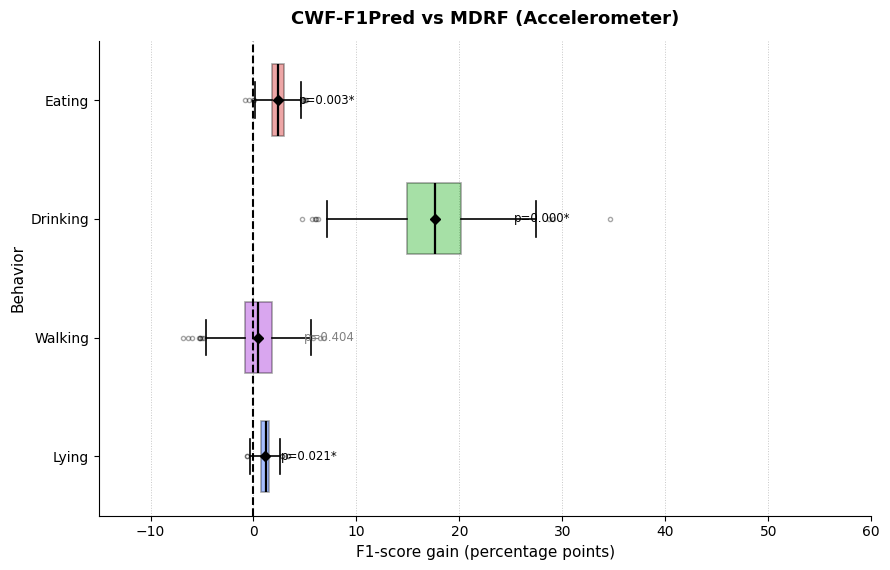

Figure saved: boxplot_cwf_f1pred_vs_rf.png


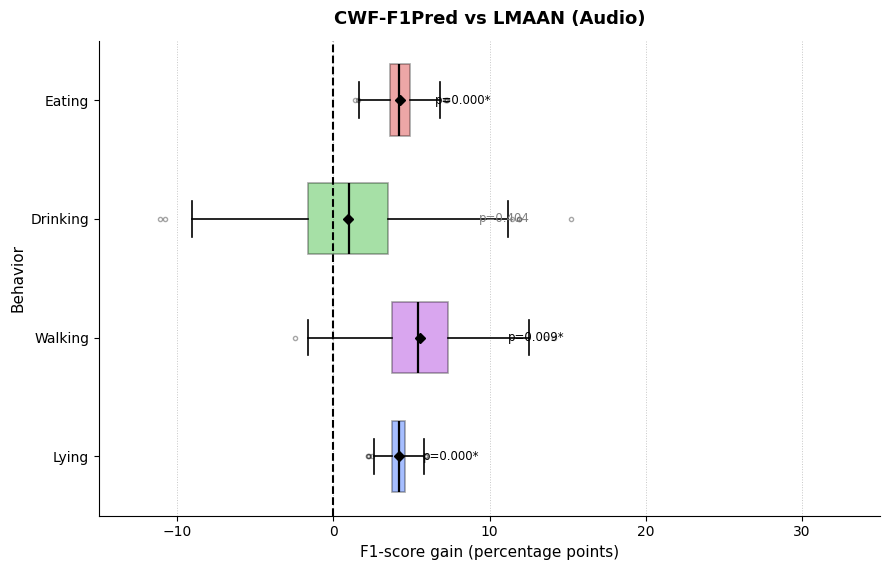

Figure saved: boxplot_cwf_f1pred_vs_lmaan.png


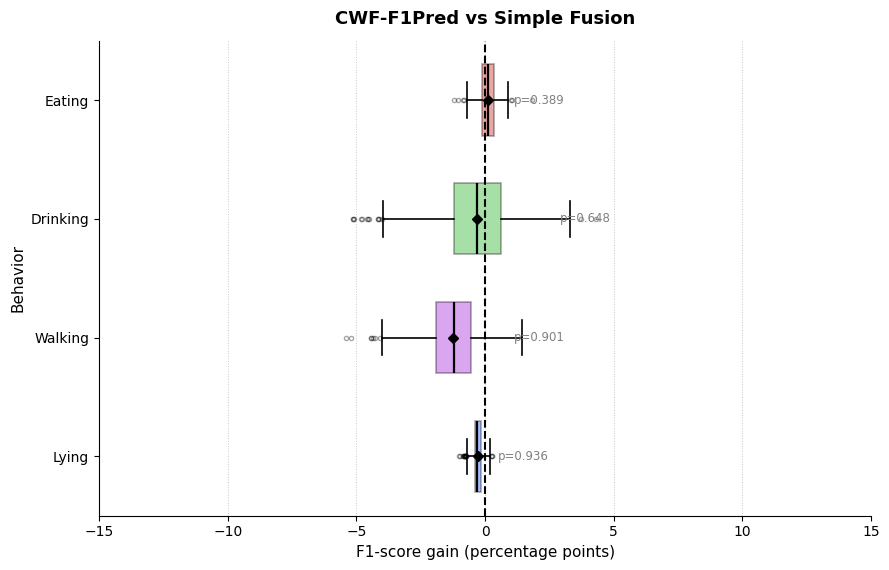

Figure saved: boxplot_cwf_f1pred_vs_simple.png


In [19]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score, accuracy_score, classification_report
)
from sklearn.utils import resample

# ============================================================
# CWF-F1Conf — Confidence × F1 of Predicted Class
#
# For each sample i and modality m:
#   ĉ_m(i)     = argmax_c p^(m)(i,c)       predicted class
#   Δ_m(i)     = max_c p^(m)(i,c) - 1/C    instantaneous confidence
#   Score_m(i) = F1_m(ĉ_m) × Δ_m(i)        credibility
#   W_m(i)     = Score_m(i) / ΣScore        dynamic weight
#   p_fus(i,c) = W_sen(i)×P_sen + W_aud(i)×P_aud
#
# Soft variant (ExpF1):
#   E[F1_m(i)] = Σ_c F1_m(c) × p^(m)(i,c)   expected F1
#   W_m(i)     = E[F1_m(i)] / Σ E[F1_m(i)]
# ============================================================

classes_modelo = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying",   "Walking", "Drinking", "Eating"]
labels_order   = [0, 1, 2, 3]
n_classes      = len(classes_modelo)
N_BOOTSTRAP    = 1000
RANDOM_STATE   = 42
prob_cols      = [f"prob_{c}" for c in classes_modelo]
EPS            = 1e-8
baseline       = 1.0 / n_classes

# ============================================================
# 1. Load test logits
# ============================================================

df_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv")
df_aud = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv")

df_sen["window"] = df_sen["window"].astype(str)
df_aud["window"] = df_aud["window"].astype(str)

df_test = pd.merge(
    df_sen[["window","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_aud[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window", how="inner"
)
print(f"Aligned test set: {len(df_test)} windows")

y_test = df_test["label_real"].values.astype(int)
P_sen  = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud  = df_test[[f"a_{c}" for c in prob_cols]].values

y_pred_sen = P_sen.argmax(axis=1)
y_pred_aud = P_aud.argmax(axis=1)
y_pred_sim = ((P_sen + P_aud) / 2).argmax(axis=1)

# ============================================================
# 2. OOF class-wise F1 (historical static weights)
# ============================================================

df_oof_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv")
df_oof_aud = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv")

def extrair_id(nome):
    m = re.search(r"-j(\d+)", str(nome))
    return int(m.group(1)) if m else None

df_oof_aud["window_id"] = df_oof_aud["window"].apply(extrair_id)
df_oof_sen["window_id"] = df_oof_sen["window"].astype(int)

df_oof = pd.merge(
    df_oof_sen[["window_id","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_oof_aud[["window_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window_id", how="inner"
)

y_oof     = df_oof["label_real"].values.astype(int)
P_oof_sen = df_oof[[f"s_{c}" for c in prob_cols]].values
P_oof_aud = df_oof[[f"a_{c}" for c in prob_cols]].values
yp_os     = P_oof_sen.argmax(axis=1)
yp_oa     = P_oof_aud.argmax(axis=1)

# F1 per class (vetor de tamanho n_classes)
f1_sen = np.array([f1_score(y_oof, yp_os, labels=[c],
    average="macro", zero_division=0) for c in range(n_classes)])
f1_aud = np.array([f1_score(y_oof, yp_oa, labels=[c],
    average="macro", zero_division=0) for c in range(n_classes)])

print("\nF1 OOF per class:")
for c, nm in enumerate(classes_modelo):
    print(f"  {nm}: sensor={f1_sen[c]:.4f}  audio={f1_aud[c]:.4f}")

# ============================================================
# 3. Instantaneous confidence per sample
# ============================================================

delta_sen = np.clip(P_sen.max(axis=1) - baseline, 0, None)
delta_aud = np.clip(P_aud.max(axis=1) - baseline, 0, None)

# ============================================================
# 4. CWF-F1Pred: F1(predicted class) × confidence
# ============================================================

# Predicted class from each modality
c_hat_sen = P_sen.argmax(axis=1)   # shape (N,)
c_hat_aud = P_aud.argmax(axis=1)

# Historical F1 of the class predicted by each model
f1_pred_sen = f1_sen[c_hat_sen]    # shape (N,)
f1_pred_aud = f1_aud[c_hat_aud]

# Score de credibility
score_sen_pred = f1_pred_sen * delta_sen
score_aud_pred = f1_pred_aud * delta_aud
denom_pred     = score_sen_pred + score_aud_pred + EPS

w_sen_pred = score_sen_pred / denom_pred   # (N,)
w_aud_pred = score_aud_pred / denom_pred

P_cwf_f1pred  = w_sen_pred[:, None] * P_sen + w_aud_pred[:, None] * P_aud
y_pred_f1pred = P_cwf_f1pred.argmax(axis=1)

print(f"\nCWF-F1Pred: mean sensor weight={w_sen_pred.mean():.4f} "
      f"| audio={w_aud_pred.mean():.4f}")

# ============================================================
# 5. CWF-ExpF1: expected F1 × confidence
# E[F1_m(i)] = Σ_c F1_m(c) × p^(m)(i,c)
# ============================================================

ef1_sen = P_sen @ f1_sen   # (N,) — produto escalar por amostra
ef1_aud = P_aud @ f1_aud

# Modular pelo delta para incluir instantaneous confidence
score_sen_exp = ef1_sen * delta_sen
score_aud_exp = ef1_aud * delta_aud
denom_exp     = score_sen_exp + score_aud_exp + EPS

w_sen_exp = score_sen_exp / denom_exp
w_aud_exp = score_aud_exp / denom_exp

P_cwf_expf1  = w_sen_exp[:, None] * P_sen + w_aud_exp[:, None] * P_aud
y_pred_expf1 = P_cwf_expf1.argmax(axis=1)

print(f"CWF-ExpF1: mean sensor weight={w_sen_exp.mean():.4f} "
      f"| audio={w_aud_exp.mean():.4f}")

# ============================================================
# 6. Comparison table
# ============================================================

def metrics_row(name, y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=labels_order,
          target_names=classes_modelo, output_dict=True, zero_division=0)
    row = {"Modelo": name}
    for c in classes_modelo:
        row[c] = round(rep[c]["f1-score"]*100, 2)
    row["Accuracy"]  = round(rep["accuracy"]*100, 2)
    row["Macro_F1"]  = round(rep["macro avg"]["f1-score"]*100, 2)
    row["W_F1"]      = round(rep["weighted avg"]["f1-score"]*100, 2)
    return row

df_comp = pd.DataFrame([
    metrics_row("RF (sensor)",    y_test, y_pred_sen),
    metrics_row("LMAAN (audio)",  y_test, y_pred_aud),
    metrics_row("Simple fusion",  y_test, y_pred_sim),
    metrics_row("CWF-F1Pred",     y_test, y_pred_f1pred),
    metrics_row("CWF-ExpF1",      y_test, y_pred_expf1),
])

print("\n=== Comparison table ===")
print(df_comp.to_string(index=False))
df_comp.to_csv("summary_cwf_f1conf.csv", index=False)

# ============================================================
# 7. Bootstrap: CWF-F1Pred vs Simple fusion e vs unimodais
# ============================================================

def bootstrap_gains(y_true, y_pred_a, y_pred_b,
                    n_iter=N_BOOTSTRAP, rs=RANDOM_STATE):
    rng = np.random.RandomState(rs)
    idx_all = np.arange(len(y_true))
    gc = {i: [] for i in range(n_classes)}
    gm, ga = [], []
    for _ in range(n_iter):
        idx = resample(idx_all, replace=True, n_samples=len(idx_all),
                       stratify=y_true,
                       random_state=rng.randint(0, 2**31))
        yb = y_true[idx]
        f1a = f1_score(yb, y_pred_a[idx], average=None,
                       labels=labels_order, zero_division=0)
        f1b = f1_score(yb, y_pred_b[idx], average=None,
                       labels=labels_order, zero_division=0)
        for i in range(n_classes): gc[i].append((f1a[i]-f1b[i])*100)
        gm.append((f1_score(yb,y_pred_a[idx],average="macro",zero_division=0) -
                   f1_score(yb,y_pred_b[idx],average="macro",zero_division=0))*100)
        ga.append((accuracy_score(yb,y_pred_a[idx]) -
                   accuracy_score(yb,y_pred_b[idx]))*100)
    return gc, gm, ga

def print_sig(gc, gm, ga, label):
    print(f"\n{'='*62}\n{label}\n{'='*62}")
    print(f"{'Metric':<14} {'Ganho':>10} {'IC95%':>22} {'p':>8}")
    print("-"*62)
    for i, nm in enumerate(classes_modelo):
        g = np.array(gc[i]); p = np.mean(g<=0)
        print(f"{nm:<14} {np.mean(g):>+9.2f}pp  "
              f"[{np.percentile(g,2.5):>+7.2f},{np.percentile(g,97.5):>+7.2f}]"
              f"  {p:.4f} {'✓' if p<0.05 else ''}")
    print("-"*62)
    for nome, g in [("Macro F1",gm),("Accuracy",ga)]:
        g = np.array(g); p = np.mean(g<=0)
        print(f"{nome:<14} {np.mean(g):>+9.2f}pp  "
              f"[{np.percentile(g,2.5):>+7.2f},{np.percentile(g,97.5):>+7.2f}]"
              f"  {p:.4f} {'✓' if p<0.05 else ''}")

gc1,gm1,ga1 = bootstrap_gains(y_test, y_pred_f1pred, y_pred_sim)
print_sig(gc1,gm1,ga1, "CWF-F1Pred vs Simple fusion")

gc2,gm2,ga2 = bootstrap_gains(y_test, y_pred_f1pred, y_pred_sen)
print_sig(gc2,gm2,ga2, "CWF-F1Pred vs RF (sensor)")

gc3,gm3,ga3 = bootstrap_gains(y_test, y_pred_f1pred, y_pred_aud)
print_sig(gc3,gm3,ga3, "CWF-F1Pred vs LMAAN (audio)")

gc4,gm4,ga4 = bootstrap_gains(y_test, y_pred_expf1, y_pred_sim)
print_sig(gc4,gm4,ga4, "CWF-ExpF1 vs Simple fusion")

# ============================================================
# 8. Boxplot — CWF-F1Pred vs RF e vs LMAAN
# ============================================================

COLORS = ['#0047FF', '#9400D3', '#00A800', '#CC0000']

def plot_boxplot(gains_class, title, save_path, xlim=(-15, 60)):
    data   = [np.array(gains_class[i]) for i in range(n_classes)]
    fig,ax = plt.subplots(figsize=(9, 5.8))
    bp = ax.boxplot(
        data, vert=False, patch_artist=True,
        tick_labels=class_names_en,
        showmeans=True, widths=0.6,
        flierprops=dict(marker='o', markersize=3, alpha=0.35),
        medianprops=dict(color='black', linewidth=1.6),
        meanprops=dict(marker='D', markerfacecolor='black',
                       markeredgecolor='black', markersize=5),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
        boxprops=dict(linewidth=1.2)
    )
    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color); patch.set_alpha(0.35)
        patch.set_edgecolor('black'); patch.set_linewidth(1.2)
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5)
    for i, d in enumerate(data):
        g = np.array(d); p = np.mean(g<=0)
        ax.text(np.percentile(g,97.5)+0.4, i+1,
                f"p={p:.3f}{'*' if p<0.05 else ''}",
                va='center', ha='left', fontsize=8.5,
                color='black' if p<0.05 else 'gray')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('F1-score gain (percentage points)', fontsize=11)
    ax.set_ylabel('Behavior', fontsize=11)
    ax.tick_params(axis='both', labelsize=10)
    ax.set_xlim(xlim)
    ax.grid(axis='x', linestyle=':', linewidth=0.7, alpha=0.7)
    ax.grid(axis='y', visible=False)
    ax.spines[['top','right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Figure saved: {save_path}")

plot_boxplot(gc2, "CWF-F1Pred vs MDRF (Accelerometer)",
             "boxplot_cwf_f1pred_vs_rf.png",    xlim=(-15, 60))
plot_boxplot(gc3, "CWF-F1Pred vs LMAAN (Audio)",
             "boxplot_cwf_f1pred_vs_lmaan.png", xlim=(-15, 35))
plot_boxplot(gc1, "CWF-F1Pred vs Simple Fusion",
             "boxplot_cwf_f1pred_vs_simple.png",xlim=(-15, 15))

## Self-Contained F1-Weighted Multimodal Fusion

This cell implements the F1-weighted fusion strategy using out-of-fold performance to compute class-specific modality weights. The method avoids data leakage by deriving weights only from validation predictions, then applying them to the test set. A simple average is included as a reference baseline.


Test set aligned: 1257 windows
OOF aligned: 4003 windows

F1-based weights computed from OOF:
Class         F1_sensor   F1_audio   W_sensor    W_audio
------------------------------------------------------
deitado          0.9611     0.9222     0.5103     0.4897
andando          0.7968     0.6232     0.5611     0.4389
bebendo          0.7123     0.6259     0.5323     0.4677
comendo          0.9263     0.8983     0.5077     0.4923


RF (sensor)
  Accuracy : 91.73%
  Macro F1 : 83.86%
  deitado   : 95.88%
  andando   : 83.16%
  bebendo   : 62.94%
  comendo   : 93.48%

LMAAN (audio)
  Accuracy : 90.29%
  Macro F1 : 85.56%
  deitado   : 92.82%
  andando   : 78.12%
  bebendo   : 79.67%
  comendo   : 91.63%

Simple fusion
  Accuracy : 94.59%
  Macro F1 : 89.73%
  deitado   : 97.30%
  andando   : 84.89%
  bebendo   : 80.95%
  comendo   : 95.76%

F1-weighted fusion
  Accuracy : 94.67%
  Macro F1 : 89.58%
  deitado   : 97.54%
  andando   : 85.00%
  bebendo   : 80.00%
  comendo   : 95.76%

=== F

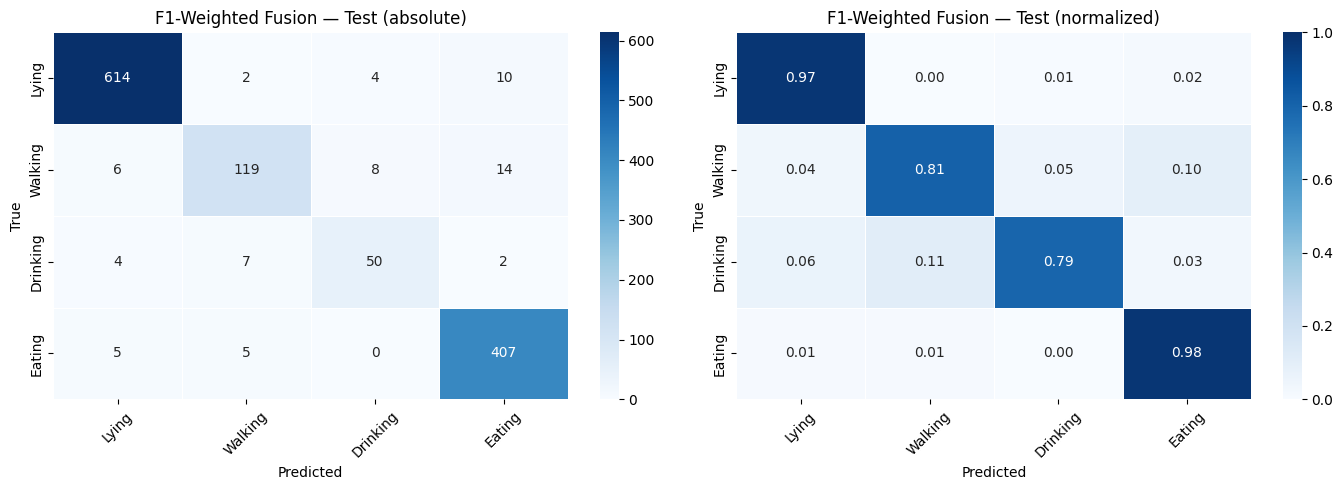


Saved: logits_f1weighted_fusion_validacao_4classes.csv


In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, confusion_matrix
)

# ============================================================
# F1-WEIGHTED MULTIMODAL FUSION — self-contained cell
# Weights computed from OOF predictions (no data leakage)
# Simple average included as reference
# ============================================================

classes_modelo  = ["deitado", "andando", "bebendo", "comendo"]
class_names_en  = ["Lying",   "Walking", "Drinking", "Eating"]
labels_order    = [0, 1, 2, 3]
n_classes       = len(classes_modelo)
prob_cols       = [f"prob_{c}" for c in classes_modelo]
EPS             = 1e-8

# ============================================================
# 1. Load test logits
# ============================================================

df_sen_test = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv")
df_aud_test = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv")

df_sen_test["window"] = df_sen_test["window"].astype(str)
df_aud_test["window"] = df_aud_test["window"].astype(str)

df_test = pd.merge(
    df_sen_test[["window","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_aud_test[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window", how="inner"
)

print(f"Test set aligned: {len(df_test)} windows")

y_test     = df_test["label_real"].values.astype(int)
P_sen_test = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud_test = df_test[[f"a_{c}" for c in prob_cols]].values

# ============================================================
# 2. Load OOF logits (used to compute weights — no leakage)
# ============================================================

df_sen_oof = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv")
df_aud_oof = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv")

def extract_id(name):
    m = re.search(r"-j(\d+)", str(name))
    return int(m.group(1)) if m else None

df_aud_oof["window_id"] = df_aud_oof["window"].apply(extract_id)
df_sen_oof["window_id"] = df_sen_oof["window"].astype(int)

df_oof = pd.merge(
    df_sen_oof[["window_id","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_aud_oof[["window_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window_id", how="inner"
)

print(f"OOF aligned: {len(df_oof)} windows")

y_oof     = df_oof["label_real"].values.astype(int)
P_sen_oof = df_oof[[f"s_{c}" for c in prob_cols]].values
P_aud_oof = df_oof[[f"a_{c}" for c in prob_cols]].values

yp_oof_sen = P_sen_oof.argmax(axis=1)
yp_oof_aud = P_aud_oof.argmax(axis=1)

# ============================================================
# 3. Compute F1-based weights per class from OOF
# W_m(c) = F1_m(c) / (F1_sen(c) + F1_aud(c))
# ============================================================

f1_oof_sen = np.array([
    f1_score(y_oof, yp_oof_sen, labels=[c],
             average="macro", zero_division=0)
    for c in range(n_classes)
])
f1_oof_aud = np.array([
    f1_score(y_oof, yp_oof_aud, labels=[c],
             average="macro", zero_division=0)
    for c in range(n_classes)
])

W_sen = f1_oof_sen / (f1_oof_sen + f1_oof_aud + EPS)
W_aud = f1_oof_aud / (f1_oof_sen + f1_oof_aud + EPS)

print("\nF1-based weights computed from OOF:")
print(f"{'Class':<12} {'F1_sensor':>10} {'F1_audio':>10} "
      f"{'W_sensor':>10} {'W_audio':>10}")
print("-"*54)
for c, nm in enumerate(classes_modelo):
    print(f"{nm:<12} {f1_oof_sen[c]:>10.4f} {f1_oof_aud[c]:>10.4f} "
          f"{W_sen[c]:>10.4f} {W_aud[c]:>10.4f}")

# ============================================================
# 4. Apply F1-weighted fusion on test set
# p_fus(i,c) = W_sen(c) × P_sen(i,c) + W_aud(c) × P_aud(i,c)
# ============================================================

P_fus_f1w = np.zeros_like(P_sen_test)
for c in range(n_classes):
    P_fus_f1w[:, c] = (W_sen[c] * P_sen_test[:, c] +
                        W_aud[c] * P_aud_test[:, c])

y_pred_f1w = P_fus_f1w.argmax(axis=1)

# Simple average reference
P_fus_avg  = (P_sen_test + P_aud_test) / 2.0
y_pred_avg = P_fus_avg.argmax(axis=1)

y_pred_sen = P_sen_test.argmax(axis=1)
y_pred_aud = P_aud_test.argmax(axis=1)

# ============================================================
# 5. Results
# ============================================================

print("\n" + "="*60)
for name, yp in [
    ("RF (sensor)",        y_pred_sen),
    ("LMAAN (audio)",      y_pred_aud),
    ("Simple fusion",      y_pred_avg),
    ("F1-weighted fusion", y_pred_f1w),
]:
    rep = classification_report(
        y_test, yp, labels=labels_order,
        target_names=classes_modelo, output_dict=True, zero_division=0)
    f1s = [round(rep[c]["f1-score"]*100, 2) for c in classes_modelo]
    print(f"\n{name}")
    print(f"  Accuracy : {rep['accuracy']*100:.2f}%")
    print(f"  Macro F1 : {rep['macro avg']['f1-score']*100:.2f}%")
    for c, v in zip(classes_modelo, f1s):
        print(f"  {c:<10}: {v:.2f}%")

# ============================================================
# 6. Detailed report — F1-weighted fusion
# ============================================================

print("\n=== F1-Weighted Fusion — Full Report ===")
print(classification_report(
    y_test, y_pred_f1w,
    labels=labels_order,
    target_names=classes_modelo,
    digits=4, zero_division=0))

# ============================================================
# 7. Confusion matrices — F1-weighted fusion
# ============================================================

cm   = confusion_matrix(y_test, y_pred_f1w, labels=np.arange(n_classes))
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_n = np.nan_to_num(cm_n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, fmt, title in zip(
    axes, [cm, cm_n], ["d", ".2f"],
    ["F1-Weighted Fusion — Test (absolute)",
     "F1-Weighted Fusion — Test (normalized)"]
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues",
                xticklabels=class_names_en,
                yticklabels=class_names_en,
                vmin=(0 if fmt==".2f" else None),
                vmax=(1 if fmt==".2f" else None),
                linewidths=0.5, linecolor="white", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("confusion_matrix_f1weighted_fusion.png",
            dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 8. Save fusion probabilities
# ============================================================

df_out = pd.DataFrame(P_fus_f1w,
                      columns=[f"prob_{c}" for c in classes_modelo])
df_out["window"]     = df_test["window"].values
df_out["label_real"] = y_test
df_out["y_pred"]     = y_pred_f1w
df_out.to_csv("logits_f1weighted_fusion_validacao_4classes.csv", index=False)
print("\nSaved: logits_f1weighted_fusion_validacao_4classes.csv")

## Comparative Evaluation of F1-Weighted Fusion and Dynamic Fusion Variants

This cell compares the selected F1-weighted fusion method against several dynamic fusion alternatives, including confidence-based approaches. It computes classification metrics, confusion matrices, and bootstrap summaries to determine whether the simpler OOF-derived F1 weighting is competitive with more adaptive schemes.


Test set aligned: 1257 windows

F1-based static weights (OOF):
  deitado: W_sensor=0.5103  W_audio=0.4897
  andando: W_sensor=0.5611  W_audio=0.4389
  bebendo: W_sensor=0.5323  W_audio=0.4677
  comendo: W_sensor=0.5077  W_audio=0.4923

Mean confidence margin — sensor: 0.6350 | audio: 0.6649
DCS-MAX: sensor selected in 47.6% of samples

RF (sensor)            Acc=91.73%  MacroF1=83.86%  | deitado=95.88 andando=83.16 bebendo=62.94 comendo=93.48
LMAAN (audio)          Acc=90.29%  MacroF1=85.56%  | deitado=92.82 andando=78.12 bebendo=79.67 comendo=91.63
Simple fusion          Acc=94.59%  MacroF1=89.73%  | deitado=97.3 andando=84.89 bebendo=80.95 comendo=95.76
F1-Weighted fusion     Acc=94.67%  MacroF1=89.58%  | deitado=97.54 andando=85.0 bebendo=80.0 comendo=95.76
DCS-MAX                Acc=94.35%  MacroF1=89.49%  | deitado=96.69 andando=84.48 bebendo=80.62 comendo=96.19
CWF-Equal              Acc=94.43%  MacroF1=89.60%  | deitado=97.0 andando=83.94 bebendo=81.6 comendo=95.88
CWF-OOF      

C:\Users\franc\AppData\Local\Temp\ipykernel_15544\657451599.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


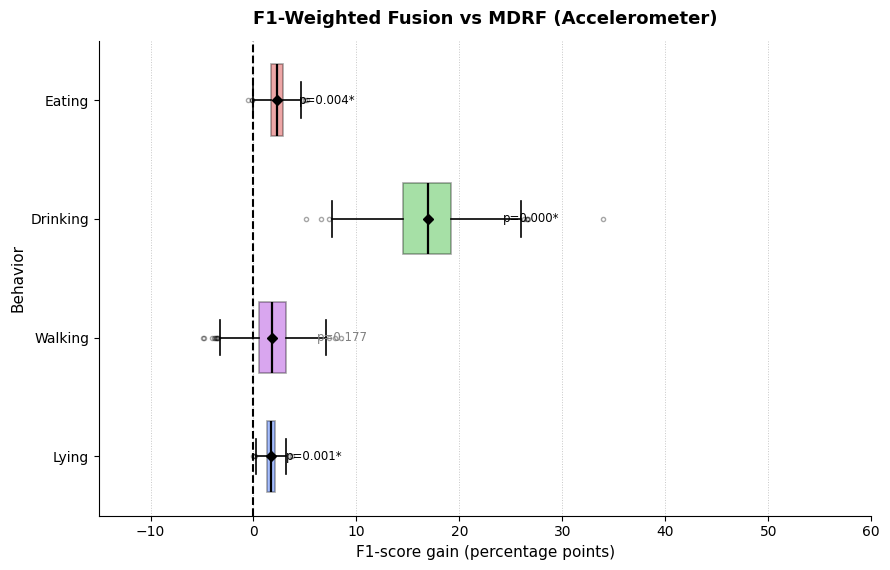

Figure saved: boxplot_f1w_vs_rf.png


C:\Users\franc\AppData\Local\Temp\ipykernel_15544\657451599.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


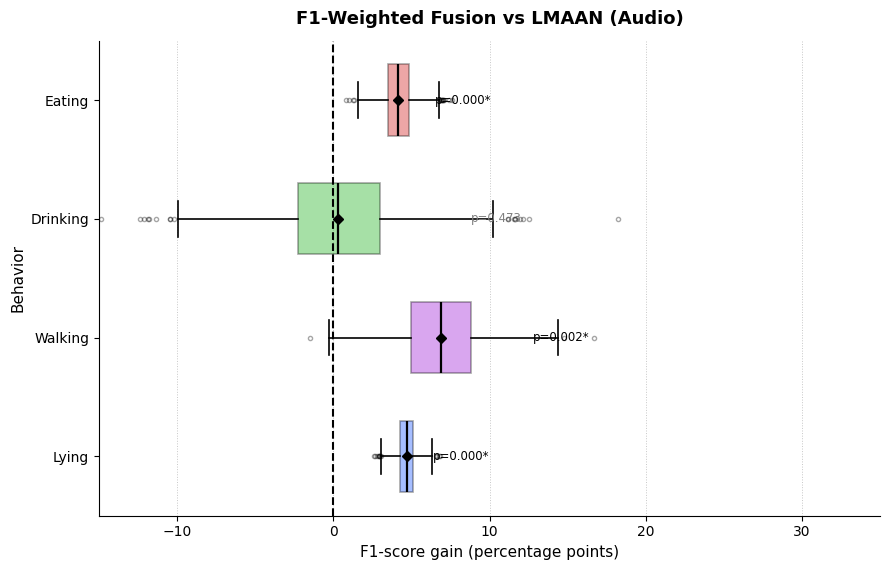

Figure saved: boxplot_f1w_vs_lmaan.png


C:\Users\franc\AppData\Local\Temp\ipykernel_15544\657451599.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


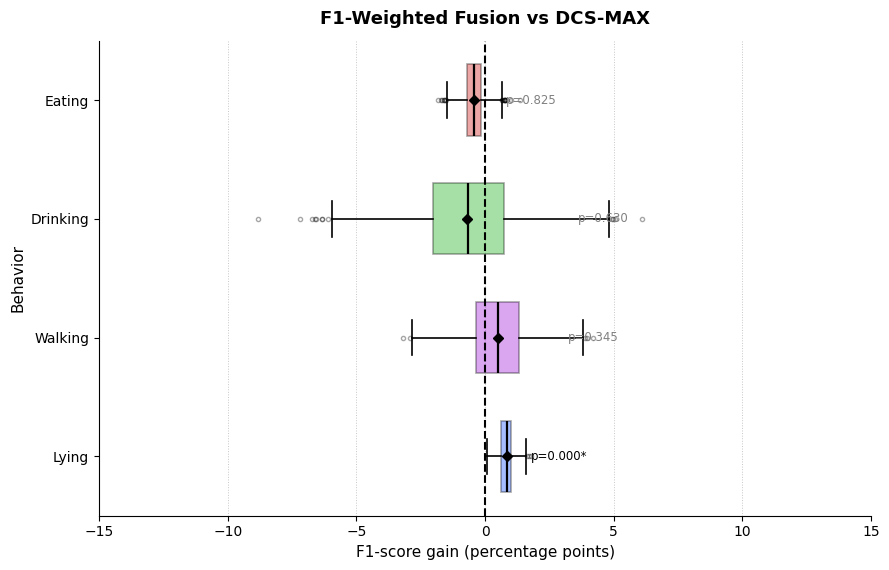

Figure saved: boxplot_f1w_vs_dcsmax.png


C:\Users\franc\AppData\Local\Temp\ipykernel_15544\657451599.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


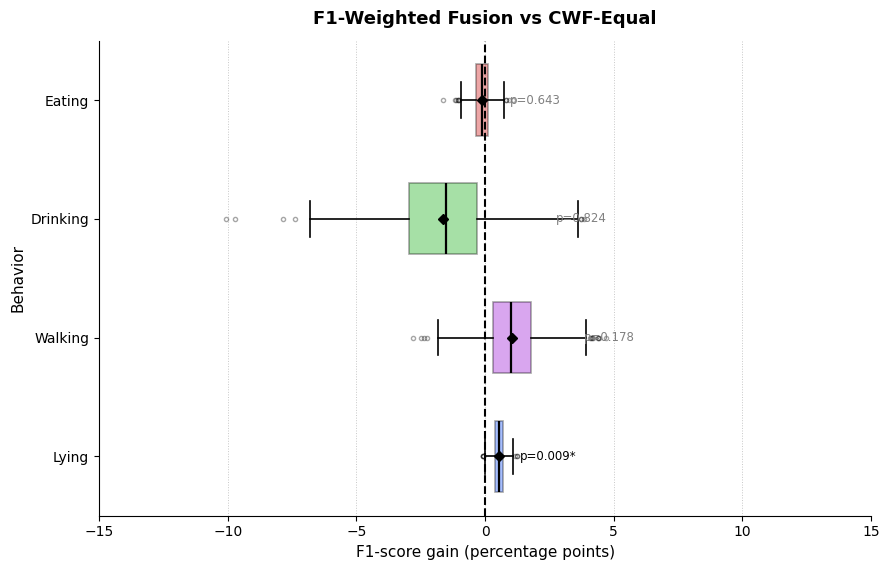

Figure saved: boxplot_f1w_vs_cwfeq.png


C:\Users\franc\AppData\Local\Temp\ipykernel_15544\657451599.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


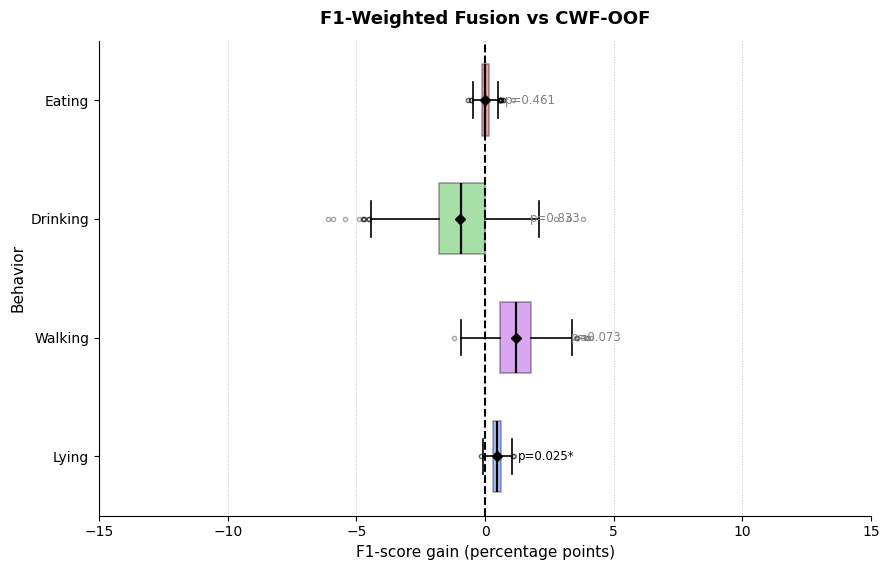

Figure saved: boxplot_f1w_vs_cwfoof.png


C:\Users\franc\AppData\Local\Temp\ipykernel_15544\657451599.py:242: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


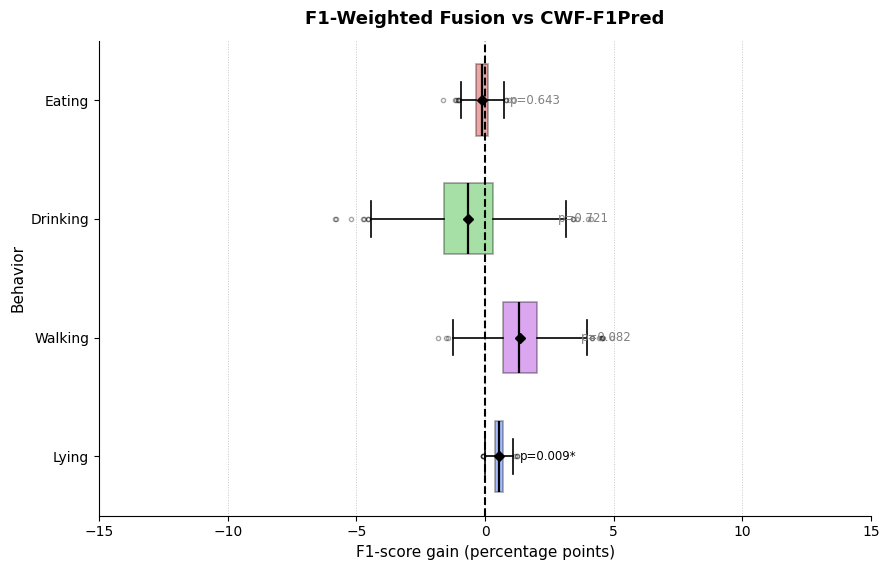

Figure saved: boxplot_f1w_vs_cwffp.png

=== Full comparison table ===
            Modelo  deitado  andando  bebendo  comendo  Accuracy  Macro_F1  Weighted_F1
       RF (sensor)    95.88    83.16    62.94    93.48     91.73     83.86        91.94
     LMAAN (audio)    92.82    78.12    79.67    91.63     90.29     85.56        90.05
     Simple fusion    97.30    84.89    80.95    95.76     94.59     89.73        94.52
F1-Weighted fusion    97.54    85.00    80.00    95.76     94.67     89.58        94.60
           DCS-MAX    96.69    84.48    80.62    96.19     94.35     89.49        94.29
         CWF-Equal    97.00    83.94    81.60    95.88     94.43     89.60        94.33
           CWF-OOF    97.07    83.75    80.95    95.75     94.35     89.38        94.27
        CWF-F1Pred    97.00    83.64    80.65    95.88     94.35     89.29        94.24

CSV saved: summary_all_fusion_methods.csv
Saved: logits_f1weighted_fusion_validacao_4classes.csv


In [12]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, confusion_matrix
)
from sklearn.utils import resample

# ============================================================
# F1-WEIGHTED MULTIMODAL FUSION
# Weights: W_m(c) = F1_m(c) / (F1_sen(c) + F1_aud(c))  — OOF only
# Compared against Kuncheva (2002) dynamic variants:
#   DCS-MAX, CWF-Equal, CWF-OOF, CWF-F1Pred
# ============================================================

classes_modelo  = ["deitado", "andando", "bebendo", "comendo"]
class_names_en  = ["Lying",   "Walking", "Drinking", "Eating"]
labels_order    = [0, 1, 2, 3]
n_classes       = len(classes_modelo)
N_BOOTSTRAP     = 1000
RANDOM_STATE    = 42
prob_cols       = [f"prob_{c}" for c in classes_modelo]
EPS             = 1e-8

# ============================================================
# 1. Load test logits
# ============================================================

df_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv")
df_aud = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv")

df_sen["window"] = df_sen["window"].astype(str)
df_aud["window"] = df_aud["window"].astype(str)

df_test = pd.merge(
    df_sen[["window","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_aud[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window", how="inner"
)
print(f"Test set aligned: {len(df_test)} windows")

y_test    = df_test["label_real"].values.astype(int)
P_sen     = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud     = df_test[[f"a_{c}" for c in prob_cols]].values

y_pred_sen = P_sen.argmax(axis=1)
y_pred_aud = P_aud.argmax(axis=1)
y_pred_sim = ((P_sen + P_aud) / 2).argmax(axis=1)

# ============================================================
# 2. Load OOF logits — compute F1-based static weights
# ============================================================

df_oof_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv")
df_oof_aud = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv")

def extrair_id(nome):
    m = re.search(r"-j(\d+)", str(nome))
    return int(m.group(1)) if m else None

df_oof_aud["window_id"] = df_oof_aud["window"].apply(extrair_id)
df_oof_sen["window_id"] = df_oof_sen["window"].astype(int)

df_oof = pd.merge(
    df_oof_sen[["window_id","label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}),
    df_oof_aud[["window_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}),
    on="window_id", how="inner"
)

y_oof      = df_oof["label_real"].values.astype(int)
P_oof_sen  = df_oof[[f"s_{c}" for c in prob_cols]].values
P_oof_aud  = df_oof[[f"a_{c}" for c in prob_cols]].values
yp_oof_sen = P_oof_sen.argmax(axis=1)
yp_oof_aud = P_oof_aud.argmax(axis=1)

f1_oof_sen = np.array([f1_score(y_oof, yp_oof_sen, labels=[c],
    average="macro", zero_division=0) for c in range(n_classes)])
f1_oof_aud = np.array([f1_score(y_oof, yp_oof_aud, labels=[c],
    average="macro", zero_division=0) for c in range(n_classes)])

W_oof_sen = f1_oof_sen / (f1_oof_sen + f1_oof_aud + EPS)
W_oof_aud = f1_oof_aud / (f1_oof_sen + f1_oof_aud + EPS)

print("\nF1-based static weights (OOF):")
for c, nm in enumerate(classes_modelo):
    print(f"  {nm}: W_sensor={W_oof_sen[c]:.4f}  W_audio={W_oof_aud[c]:.4f}")

# ============================================================
# 3. F1-Weighted Fusion
# p_fus(i,c) = W_sen(c) * P_sen(i,c) + W_aud(c) * P_aud(i,c)
# ============================================================

P_f1w = np.zeros_like(P_sen)
for c in range(n_classes):
    P_f1w[:, c] = W_oof_sen[c] * P_sen[:, c] + W_oof_aud[c] * P_aud[:, c]
y_pred_f1w = P_f1w.argmax(axis=1)

# ============================================================
# 4. Kuncheva (2002) dynamic variants
# ============================================================

baseline  = 1.0 / n_classes
delta_sen = np.clip(P_sen.max(axis=1) - baseline, 0, None)
delta_aud = np.clip(P_aud.max(axis=1) - baseline, 0, None)

print(f"\nMean confidence margin — sensor: {delta_sen.mean():.4f} "
      f"| audio: {delta_aud.mean():.4f}")

# DCS-MAX
mask_sen       = (delta_sen >= delta_aud)
P_dcs          = np.where(mask_sen[:, None], P_sen, P_aud)
y_pred_dcs     = P_dcs.argmax(axis=1)
print(f"DCS-MAX: sensor selected in {mask_sen.mean()*100:.1f}% of samples")

# CWF-Equal
denom_eq       = delta_sen + delta_aud + EPS
P_cwf_eq       = (delta_sen / denom_eq)[:, None] * P_sen + \
                 (delta_aud / denom_eq)[:, None] * P_aud
y_pred_cwf_eq  = P_cwf_eq.argmax(axis=1)

# CWF-OOF
Wt_sen         = np.outer(delta_sen, W_oof_sen)
Wt_aud         = np.outer(delta_aud, W_oof_aud)
denom_oof      = Wt_sen + Wt_aud + EPS
P_cwf_oof      = (Wt_sen / denom_oof) * P_sen + (Wt_aud / denom_oof) * P_aud
y_pred_cwf_oof = P_cwf_oof.argmax(axis=1)

# CWF-F1Pred
c_hat_sen      = P_sen.argmax(axis=1)
c_hat_aud      = P_aud.argmax(axis=1)
score_sp       = f1_oof_sen[c_hat_sen] * delta_sen
score_ap       = f1_oof_aud[c_hat_aud] * delta_aud
denom_fp       = score_sp + score_ap + EPS
P_cwf_fp       = (score_sp / denom_fp)[:, None] * P_sen + \
                 (score_ap / denom_fp)[:, None] * P_aud
y_pred_cwf_fp  = P_cwf_fp.argmax(axis=1)

# ============================================================
# 5. Results summary
# ============================================================

models = {
    "RF (sensor)":        y_pred_sen,
    "LMAAN (audio)":      y_pred_aud,
    "Simple fusion":      y_pred_sim,
    "F1-Weighted fusion": y_pred_f1w,
    "DCS-MAX":            y_pred_dcs,
    "CWF-Equal":          y_pred_cwf_eq,
    "CWF-OOF":            y_pred_cwf_oof,
    "CWF-F1Pred":         y_pred_cwf_fp,
}

print("\n" + "="*70)
for name, yp in models.items():
    rep = classification_report(y_test, yp, labels=labels_order,
          target_names=classes_modelo, output_dict=True, zero_division=0)
    f1s = [round(rep[c]["f1-score"]*100, 2) for c in classes_modelo]
    print(f"{name:<22} Acc={rep['accuracy']*100:.2f}%  "
          f"MacroF1={rep['macro avg']['f1-score']*100:.2f}%  "
          f"| {' '.join([f'{c}={v}' for c,v in zip(classes_modelo,f1s)])}")

# ============================================================
# 6. Bootstrap significance — F1-Weighted vs all variants
# ============================================================

def bootstrap_gains_all(y_true, y_pred_a, y_pred_b,
                        n_iter=N_BOOTSTRAP, rs=RANDOM_STATE):
    rng     = np.random.RandomState(rs)
    idx_all = np.arange(len(y_true))
    gc      = {i: [] for i in range(n_classes)}
    gm, gw, ga = [], [], []
    for _ in range(n_iter):
        idx = resample(idx_all, replace=True, n_samples=len(idx_all),
                       stratify=y_true,
                       random_state=rng.randint(0, 2**31))
        yb, ya, yb2 = y_true[idx], y_pred_a[idx], y_pred_b[idx]
        f1a = f1_score(yb, ya,  average=None, labels=labels_order, zero_division=0)
        f1b = f1_score(yb, yb2, average=None, labels=labels_order, zero_division=0)
        for i in range(n_classes):
            gc[i].append((f1a[i] - f1b[i]) * 100)
        gm.append((f1_score(yb,ya, average="macro",    zero_division=0) -
                   f1_score(yb,yb2,average="macro",    zero_division=0)) * 100)
        gw.append((f1_score(yb,ya, average="weighted", zero_division=0) -
                   f1_score(yb,yb2,average="weighted", zero_division=0)) * 100)
        ga.append((accuracy_score(yb,ya) - accuracy_score(yb,yb2)) * 100)
    return gc, gm, gw, ga

def print_bootstrap(gc, gm, gw, ga, label):
    print(f"\n{'='*64}\n{label}\n{'='*64}")
    print(f"{'Metric':<16} {'Gain':>10} {'IC95%':>22} {'p':>8}")
    print("-"*64)
    for i, nm in enumerate(classes_modelo):
        g = np.array(gc[i]); p = np.mean(g <= 0)
        print(f"{nm:<16} {np.mean(g):>+9.2f}pp  "
              f"[{np.percentile(g,2.5):>+7.2f}, {np.percentile(g,97.5):>+7.2f}]"
              f"  {p:.4f} {'✓' if p<0.05 else ''}")
    print("-"*64)
    for nome, g in [("Macro F1",gm),("Weighted F1",gw),("Accuracy",ga)]:
        g = np.array(g); p = np.mean(g <= 0)
        print(f"{nome:<16} {np.mean(g):>+9.2f}pp  "
              f"[{np.percentile(g,2.5):>+7.2f}, {np.percentile(g,97.5):>+7.2f}]"
              f"  {p:.4f} {'✓' if p<0.05 else ''}")

gc1,gm1,gw1,ga1 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_dcs)
print_bootstrap(gc1,gm1,gw1,ga1, "F1-Weighted Fusion vs DCS-MAX")

gc2,gm2,gw2,ga2 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_cwf_eq)
print_bootstrap(gc2,gm2,gw2,ga2, "F1-Weighted Fusion vs CWF-Equal")

gc3,gm3,gw3,ga3 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_cwf_oof)
print_bootstrap(gc3,gm3,gw3,ga3, "F1-Weighted Fusion vs CWF-OOF")

gc4,gm4,gw4,ga4 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_cwf_fp)
print_bootstrap(gc4,gm4,gw4,ga4, "F1-Weighted Fusion vs CWF-F1Pred")

gc5,gm5,gw5,ga5 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_sen)
print_bootstrap(gc5,gm5,gw5,ga5, "F1-Weighted Fusion vs RF (sensor)")

gc6,gm6,gw6,ga6 = bootstrap_gains_all(y_test, y_pred_f1w, y_pred_aud)
print_bootstrap(gc6,gm6,gw6,ga6, "F1-Weighted Fusion vs LMAAN (audio)")

# ============================================================
# 7. Boxplots — article style
# ============================================================

COLORS = ['#0047FF', '#9400D3', '#00A800', '#CC0000']

def plot_cwf_boxplot(gains_class, title, save_path, xlim=(-20, 40)):
    data_plot = [np.array(gains_class[i]) for i in range(n_classes)]
    fig, ax   = plt.subplots(figsize=(9, 5.8))
    bp = ax.boxplot(
        data_plot, vert=False, patch_artist=True,
        labels=class_names_en, showmeans=True, meanline=False, widths=0.6,
        flierprops=dict(marker='o', markersize=3, alpha=0.35),
        medianprops=dict(color='black', linewidth=1.6),
        meanprops=dict(marker='D', markerfacecolor='black',
                       markeredgecolor='black', markersize=5),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
        boxprops=dict(linewidth=1.2)
    )
    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color); patch.set_alpha(0.35)
        patch.set_edgecolor('black'); patch.set_linewidth(1.2)
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5)
    for i, data in enumerate(data_plot):
        g = np.array(data); p = np.mean(g <= 0)
        ax.text(np.percentile(g, 97.5) + 0.4, i + 1,
                f"p={p:.3f}{'*' if p<0.05 else ''}",
                va='center', ha='left', fontsize=8.5,
                color='black' if p < 0.05 else 'gray')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('F1-score gain (percentage points)', fontsize=11)
    ax.set_ylabel('Behavior', fontsize=11)
    ax.tick_params(axis='both', labelsize=10)
    ax.set_xlim(xlim)
    ax.grid(axis='x', linestyle=':', linewidth=0.7, alpha=0.7)
    ax.grid(axis='y', visible=False)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Figure saved: {save_path}")

plot_cwf_boxplot(gc5, "F1-Weighted Fusion vs MDRF (Accelerometer)",
                 "boxplot_f1w_vs_rf.png",     xlim=(-15, 60))
plot_cwf_boxplot(gc6, "F1-Weighted Fusion vs LMAAN (Audio)",
                 "boxplot_f1w_vs_lmaan.png",  xlim=(-15, 35))
plot_cwf_boxplot(gc1, "F1-Weighted Fusion vs DCS-MAX",
                 "boxplot_f1w_vs_dcsmax.png", xlim=(-15, 15))
plot_cwf_boxplot(gc2, "F1-Weighted Fusion vs CWF-Equal",
                 "boxplot_f1w_vs_cwfeq.png",  xlim=(-15, 15))
plot_cwf_boxplot(gc3, "F1-Weighted Fusion vs CWF-OOF",
                 "boxplot_f1w_vs_cwfoof.png", xlim=(-15, 15))
plot_cwf_boxplot(gc4, "F1-Weighted Fusion vs CWF-F1Pred",
                 "boxplot_f1w_vs_cwffp.png",  xlim=(-15, 15))

# ============================================================
# 8. Full comparison table
# ============================================================

def metrics_row(name, y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=labels_order,
          target_names=classes_modelo, output_dict=True, zero_division=0)
    row = {"Modelo": name}
    for c in classes_modelo:
        row[c] = round(rep[c]["f1-score"] * 100, 2)
    row["Accuracy"]    = round(rep["accuracy"] * 100, 2)
    row["Macro_F1"]    = round(rep["macro avg"]["f1-score"] * 100, 2)
    row["Weighted_F1"] = round(rep["weighted avg"]["f1-score"] * 100, 2)
    return row

df_comp = pd.DataFrame([
    metrics_row("RF (sensor)",        y_test, y_pred_sen),
    metrics_row("LMAAN (audio)",      y_test, y_pred_aud),
    metrics_row("Simple fusion",      y_test, y_pred_sim),
    metrics_row("F1-Weighted fusion", y_test, y_pred_f1w),
    metrics_row("DCS-MAX",            y_test, y_pred_dcs),
    metrics_row("CWF-Equal",          y_test, y_pred_cwf_eq),
    metrics_row("CWF-OOF",            y_test, y_pred_cwf_oof),
    metrics_row("CWF-F1Pred",         y_test, y_pred_cwf_fp),
])

print("\n=== Full comparison table ===")
print(df_comp.to_string(index=False))
df_comp.to_csv("summary_all_fusion_methods.csv", index=False)
print("\nCSV saved: summary_all_fusion_methods.csv")

# ============================================================
# 9. Save F1-Weighted fusion probabilities
# ============================================================

df_out = pd.DataFrame(P_f1w, columns=[f"prob_{c}" for c in classes_modelo])
df_out["window"]     = df_test["window"].values
df_out["label_real"] = y_test
df_out["y_pred"]     = y_pred_f1w
df_out.to_csv("logits_f1weighted_fusion_validacao_4classes.csv", index=False)
print("Saved: logits_f1weighted_fusion_validacao_4classes.csv")

## Verification of Synchronized Test-Set Intersection

This cell loads the accelerometer and audio probability files used in fusion and counts the overlap between their window identifiers. This check confirms the number of samples that can be evaluated jointly and ensures that multimodal fusion is performed only on synchronized windows present in both modalities.


In [15]:
df_sen = pd.read_csv("logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv")
df_aud = pd.read_csv("logits_audio_lmaan_validacao_4classes_cshift4p.csv")

print(f"MDRF-CS test:  {len(df_sen)} windows")
print(f"LMAAN test:    {len(df_aud)} windows")
print(f"Intersection:    {len(set(df_sen['window']) & set(df_aud['window'].astype(str)))} windows")

MDRF-CS test:  1257 windows
LMAAN test:    1257 windows
Intersection:    1257 windows


## Random Forest Meta-Classifier for Multimodal Fusion

This cell implements a meta-classifier fusion approach adapted from multimodal activity recognition strategies. It uses modality-level predictions or probabilities as input features to a Random Forest classifier. The goal is to test whether a learned fusion layer can outperform rule-based probability fusion.


Test set aligned: 1257 windows
OOF aligned: 4003 windows

Meta-feature matrices:
X_meta_train: (4003, 6)
X_meta_test : (1257, 6)

Meta-feature order:
['pred_sensor', 'pred_audio', 'Pmean_deitado', 'Pmean_andando', 'Pmean_bebendo', 'Pmean_comendo']

=== Garcia-Ceja Style Multi-view Stacking — Test ===
              precision    recall  f1-score   support

     deitado     0.9685    0.9762    0.9723       630
     andando     0.8633    0.8163    0.8392       147
     bebendo     0.6970    0.7302    0.7132        63
     comendo     0.9640    0.9640    0.9640       417

    accuracy                         0.9411      1257
   macro avg     0.8732    0.8717    0.8722      1257
weighted avg     0.9411    0.9411    0.9410      1257

Accuracy    : 0.9411
Macro-F1    : 0.8722
Weighted-F1 : 0.9410

=== Global comparison ===
                Model  Accuracy  Macro-F1  Weighted-F1
       MDRF-CS sensor  0.917263  0.838628     0.919425
          LMAAN audio  0.902944  0.855612     0.900461
Simple a

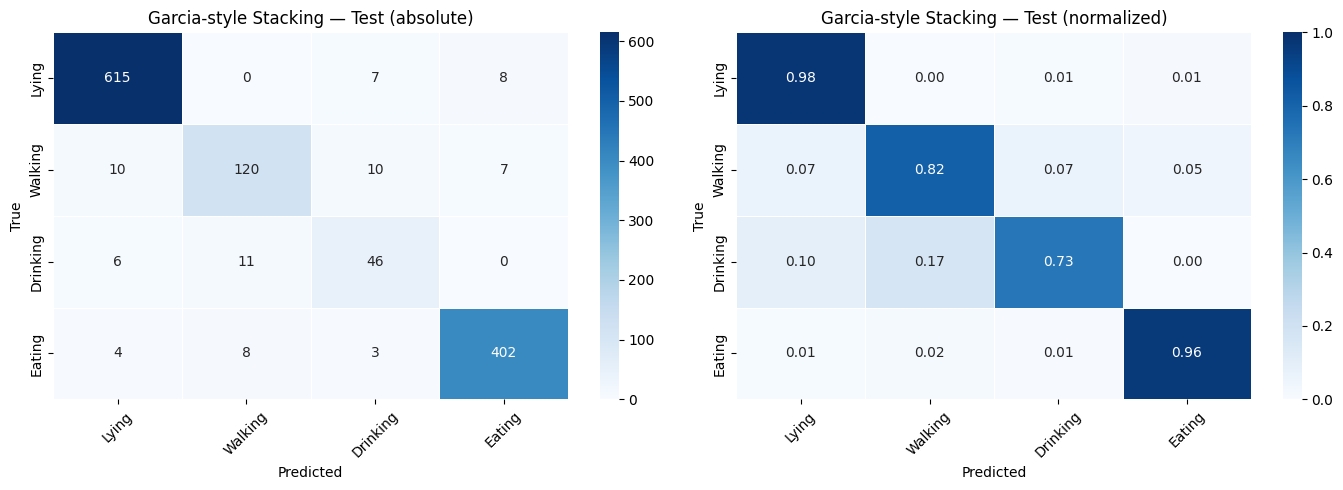


Saved files:
logits_garcia_style_stacking_validacao_4classes.csv
comparison_garcia_style_stacking.csv
confusion_matrix_garcia_style_stacking.png
confusion_matrix_garcia_style_stacking.pdf


In [16]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# GARCIA-CEJA STYLE MULTI-VIEW STACKING
# Adapted to your trained models:
#   View 1: Accelerometer model = MDRF-CS
#   View 2: Audio model         = LMAAN
#
# Meta-features:
#   pred_sensor
#   pred_audio
#   mean probability for each class
#
# Total: 2 predicted labels + 4 averaged probabilities = 6 features
# ============================================================

classes_modelo = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying", "Walking", "Drinking", "Eating"]
labels_order = [0, 1, 2, 3]
prob_cols = [f"prob_{c}" for c in classes_modelo]

# ============================================================
# 1. LOAD TEST PROBABILITIES
# ============================================================

df_sen_test = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv"
)

df_aud_test = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv"
)

df_sen_test["window"] = df_sen_test["window"].astype(str)
df_aud_test["window"] = df_aud_test["window"].astype(str)

df_test = pd.merge(
    df_sen_test[["window", "label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}
    ),
    df_aud_test[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}
    ),
    on="window",
    how="inner"
)

print(f"Test set aligned: {len(df_test)} windows")

y_test = df_test["label_real"].values.astype(int)

P_sen_test = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud_test = df_test[[f"a_{c}" for c in prob_cols]].values

# ============================================================
# 2. LOAD OOF PROBABILITIES
# These are used to train the meta-learner without leakage.
# ============================================================

df_sen_oof = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv"
)

df_aud_oof = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv"
)

def extract_id(name):
    """
    Extracts numeric window id from audio OOF window name.
    Example: something-j123 -> 123
    """
    m = re.search(r"-j(\d+)", str(name))
    return int(m.group(1)) if m else None

df_aud_oof["window_id"] = df_aud_oof["window"].apply(extract_id)
df_sen_oof["window_id"] = df_sen_oof["window"].astype(int)

df_oof = pd.merge(
    df_sen_oof[["window_id", "label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}
    ),
    df_aud_oof[["window_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}
    ),
    on="window_id",
    how="inner"
)

print(f"OOF aligned: {len(df_oof)} windows")

y_oof = df_oof["label_real"].values.astype(int)

P_sen_oof = df_oof[[f"s_{c}" for c in prob_cols]].values
P_aud_oof = df_oof[[f"a_{c}" for c in prob_cols]].values

# ============================================================
# 3. BUILD GARCIA-CEJA STYLE META-FEATURES
# ============================================================

def build_garcia_meta_features(P_sensor, P_audio):
    """
    Garcia-Ceja style features:
    - predicted label from each first-level learner
    - averaged probabilities across the two views
    """

    pred_sensor = P_sensor.argmax(axis=1).reshape(-1, 1)
    pred_audio = P_audio.argmax(axis=1).reshape(-1, 1)

    P_mean = (P_sensor + P_audio) / 2.0

    X_meta = np.hstack([
        pred_sensor,
        pred_audio,
        P_mean
    ])

    return X_meta

X_meta_train = build_garcia_meta_features(P_sen_oof, P_aud_oof)
X_meta_test = build_garcia_meta_features(P_sen_test, P_aud_test)

print("\nMeta-feature matrices:")
print("X_meta_train:", X_meta_train.shape)
print("X_meta_test :", X_meta_test.shape)

print("\nMeta-feature order:")
print(["pred_sensor", "pred_audio"] + [f"Pmean_{c}" for c in classes_modelo])

# ============================================================
# 4. TRAIN META-LEARNER RANDOM FOREST
# Following Garcia-Ceja style: Random Forest as meta-classifier
# ============================================================

meta_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

meta_rf.fit(X_meta_train, y_oof)

# ============================================================
# 5. EVALUATE GARCIA-STYLE STACKING ON TEST SET
# ============================================================

y_pred_stacking = meta_rf.predict(X_meta_test)
P_stacking = meta_rf.predict_proba(X_meta_test)

print("\n=== Garcia-Ceja Style Multi-view Stacking — Test ===")
print(classification_report(
    y_test,
    y_pred_stacking,
    labels=labels_order,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

acc = accuracy_score(y_test, y_pred_stacking)
macro_f1 = f1_score(y_test, y_pred_stacking, average="macro")
weighted_f1 = f1_score(y_test, y_pred_stacking, average="weighted")

print(f"Accuracy    : {acc:.4f}")
print(f"Macro-F1    : {macro_f1:.4f}")
print(f"Weighted-F1 : {weighted_f1:.4f}")

# ============================================================
# 6. COMPARE AGAINST UNIMODAL AND SIMPLE AVERAGE
# ============================================================

y_pred_sen = P_sen_test.argmax(axis=1)
y_pred_aud = P_aud_test.argmax(axis=1)

P_avg = (P_sen_test + P_aud_test) / 2.0
y_pred_avg = P_avg.argmax(axis=1)

comparison = []

for name, yp in [
    ("MDRF-CS sensor", y_pred_sen),
    ("LMAAN audio", y_pred_aud),
    ("Simple average fusion", y_pred_avg),
    ("Garcia-style stacking", y_pred_stacking),
]:
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, yp),
        "Macro-F1": f1_score(y_test, yp, average="macro"),
        "Weighted-F1": f1_score(y_test, yp, average="weighted")
    })

df_comparison = pd.DataFrame(comparison)

print("\n=== Global comparison ===")
print(df_comparison.to_string(index=False))

# ============================================================
# 7. CONFUSION MATRICES
# ============================================================

cm = confusion_matrix(y_test, y_pred_stacking, labels=labels_order)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    linewidths=0.5,
    linecolor="white",
    ax=axes[0]
)

axes[0].set_title("Garcia-style Stacking — Test (absolute)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    ax=axes[1]
)

axes[1].set_title("Garcia-style Stacking — Test (normalized)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(
    "confusion_matrix_garcia_style_stacking.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "confusion_matrix_garcia_style_stacking.pdf",
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 8. SAVE STACKING PROBABILITIES AND COMPARISON TABLE
# ============================================================

df_out = pd.DataFrame(
    P_stacking,
    columns=[f"prob_{c}" for c in classes_modelo]
)

df_out["window"] = df_test["window"].values
df_out["label_real"] = y_test
df_out["y_pred"] = y_pred_stacking

df_out.to_csv(
    "logits_garcia_style_stacking_validacao_4classes.csv",
    index=False
)

df_comparison.to_csv(
    "comparison_garcia_style_stacking.csv",
    index=False
)

print("\nSaved files:")
print("logits_garcia_style_stacking_validacao_4classes.csv")
print("comparison_garcia_style_stacking.csv")
print("confusion_matrix_garcia_style_stacking.png")
print("confusion_matrix_garcia_style_stacking.pdf")

## Additional Meta-Classifier Fusion Experiment

This cell evaluates an additional meta-classifier configuration for combining audio and accelerometer outputs. It follows the same general objective as the previous fusion experiment but may alter the input representation, validation strategy, or training configuration. This provides a robustness check for learned fusion approaches.


Test set aligned: 1257 windows
OOF aligned: 4003 windows

Meta-feature matrices:
Garcia-style train: (4003, 6)
Garcia-style test : (1257, 6)
Confidence-aware train: (4003, 18)
Confidence-aware test : (1257, 18)

Confidence-aware feature order:
00: Psen_deitado
01: Psen_andando
02: Psen_bebendo
03: Psen_comendo
04: Paud_deitado
05: Paud_andando
06: Paud_bebendo
07: Paud_comendo
08: Pmean_deitado
09: Pmean_andando
10: Pmean_bebendo
11: Pmean_comendo
12: pred_sensor
13: pred_audio
14: conf_sensor
15: conf_audio
16: entropy_sensor
17: entropy_audio

GLOBAL COMPARISON
                    Model  Accuracy  Macro-F1  Weighted-F1
           MDRF-CS sensor  0.917263  0.838628     0.919425
              LMAAN audio  0.902944  0.855612     0.900461
    Simple average fusion  0.945903  0.897277     0.945211
    Garcia-style stacking  0.941130  0.872175     0.941015
Confidence-aware stacking  0.934765  0.865597     0.938285

CONFIDENCE-AWARE STACKING — FULL REPORT
              precision    recall  

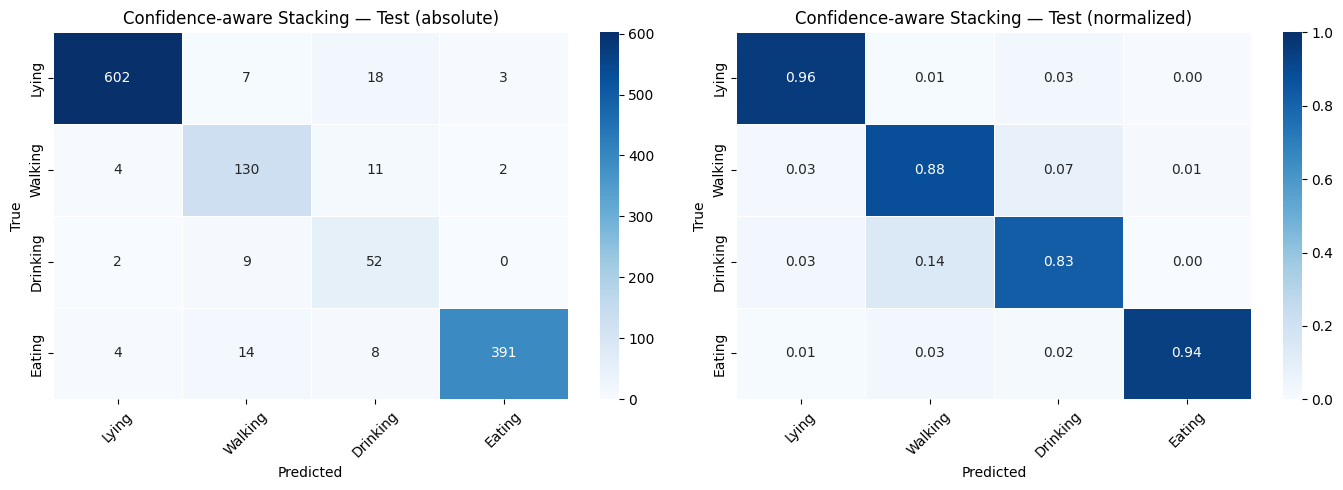


CONFIDENCE-AWARE META-LEARNER FEATURE IMPORTANCE
       feature  importance
 Pmean_deitado    0.136867
   pred_sensor    0.127690
 Pmean_comendo    0.124289
  Psen_deitado    0.120501
  Psen_comendo    0.093088
  Psen_bebendo    0.084362
  Psen_andando    0.076696
 Pmean_bebendo    0.069462
 Pmean_andando    0.039205
  Paud_comendo    0.038109
  Paud_deitado    0.036543
    pred_audio    0.021152
  Paud_bebendo    0.011622
  Paud_andando    0.010778
entropy_sensor    0.005226
    conf_audio    0.001953
   conf_sensor    0.001651
 entropy_audio    0.000807


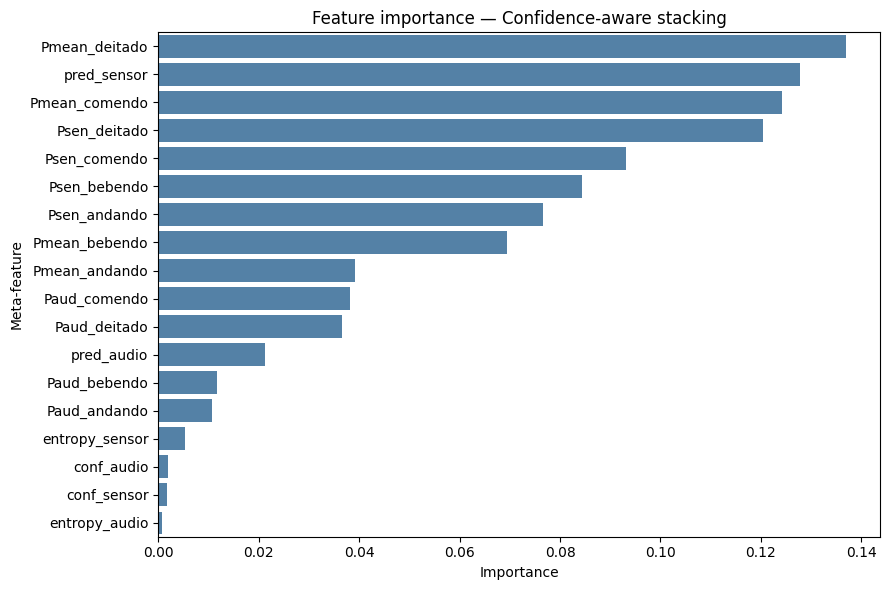


Saved files:
logits_confidence_aware_stacking_validacao_4classes.csv
logits_garcia_style_stacking_validacao_4classes.csv
comparison_late_fusion_models.csv
comparison_late_fusion_per_class_f1.csv
feature_importance_confidence_aware_stacking.csv
confusion_matrix_confidence_aware_stacking.png
confusion_matrix_confidence_aware_stacking.pdf
feature_importance_confidence_aware_stacking.png
feature_importance_confidence_aware_stacking.pdf


In [17]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# CONFIDENCE-AWARE MULTI-VIEW STACKING
# Extended late-fusion meta-model using:
# P_sensor, P_audio, P_mean, predicted labels,
# confidence and probability entropy from each modality.
# ============================================================

classes_modelo = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying", "Walking", "Drinking", "Eating"]
labels_order = [0, 1, 2, 3]
prob_cols = [f"prob_{c}" for c in classes_modelo]

EPS = 1e-8

# ============================================================
# 1. LOAD TEST PROBABILITIES
# ============================================================

df_sen_test = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv"
)

df_aud_test = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv"
)

df_sen_test["window"] = df_sen_test["window"].astype(str)
df_aud_test["window"] = df_aud_test["window"].astype(str)

df_test = pd.merge(
    df_sen_test[["window", "label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}
    ),
    df_aud_test[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}
    ),
    on="window",
    how="inner"
)

print(f"Test set aligned: {len(df_test)} windows")

y_test = df_test["label_real"].values.astype(int)

P_sen_test = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud_test = df_test[[f"a_{c}" for c in prob_cols]].values

# ============================================================
# 2. LOAD OOF PROBABILITIES
# ============================================================

df_sen_oof = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv"
)

df_aud_oof = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv"
)

def extract_id(name):
    """
    Extract numeric window id from audio OOF window name.
    Example: something-j123 -> 123
    """
    m = re.search(r"-j(\d+)", str(name))
    return int(m.group(1)) if m else None

df_aud_oof["window_id"] = df_aud_oof["window"].apply(extract_id)
df_sen_oof["window_id"] = df_sen_oof["window"].astype(int)

df_oof = pd.merge(
    df_sen_oof[["window_id", "label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}
    ),
    df_aud_oof[["window_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}
    ),
    on="window_id",
    how="inner"
)

print(f"OOF aligned: {len(df_oof)} windows")

y_oof = df_oof["label_real"].values.astype(int)

P_sen_oof = df_oof[[f"s_{c}" for c in prob_cols]].values
P_aud_oof = df_oof[[f"a_{c}" for c in prob_cols]].values

# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

def entropy_probs(P, eps=1e-8):
    """
    Entropy of class probability distribution for each sample.
    Higher entropy = higher uncertainty.
    """
    P = np.clip(P, eps, 1.0)
    return -np.sum(P * np.log(P), axis=1)


def build_garcia_meta_features(P_sensor, P_audio):
    """
    Garcia-Ceja style features:
    2 predicted labels + 4 averaged probabilities = 6 features.
    """

    pred_sensor = P_sensor.argmax(axis=1).reshape(-1, 1)
    pred_audio = P_audio.argmax(axis=1).reshape(-1, 1)

    P_mean = (P_sensor + P_audio) / 2.0

    X_meta = np.hstack([
        pred_sensor,
        pred_audio,
        P_mean
    ])

    return X_meta


def build_confidence_aware_meta_features(P_sensor, P_audio):
    """
    Extended confidence-aware multi-view stacking features.

    Features:
    - P_sensor: 4 columns
    - P_audio: 4 columns
    - P_mean: 4 columns
    - pred_sensor: 1 column
    - pred_audio: 1 column
    - conf_sensor: 1 column
    - conf_audio: 1 column
    - entropy_sensor: 1 column
    - entropy_audio: 1 column

    Total: 18 meta-features.
    """

    pred_sensor = P_sensor.argmax(axis=1).reshape(-1, 1)
    pred_audio = P_audio.argmax(axis=1).reshape(-1, 1)

    P_mean = (P_sensor + P_audio) / 2.0

    conf_sensor = P_sensor.max(axis=1).reshape(-1, 1)
    conf_audio = P_audio.max(axis=1).reshape(-1, 1)

    ent_sensor = entropy_probs(P_sensor).reshape(-1, 1)
    ent_audio = entropy_probs(P_audio).reshape(-1, 1)

    X_meta = np.hstack([
        P_sensor,
        P_audio,
        P_mean,
        pred_sensor,
        pred_audio,
        conf_sensor,
        conf_audio,
        ent_sensor,
        ent_audio
    ])

    return X_meta


# ============================================================
# 4. BUILD META-FEATURE MATRICES
# ============================================================

X_garcia_train = build_garcia_meta_features(P_sen_oof, P_aud_oof)
X_garcia_test = build_garcia_meta_features(P_sen_test, P_aud_test)

X_conf_train = build_confidence_aware_meta_features(P_sen_oof, P_aud_oof)
X_conf_test = build_confidence_aware_meta_features(P_sen_test, P_aud_test)

print("\nMeta-feature matrices:")
print("Garcia-style train:", X_garcia_train.shape)
print("Garcia-style test :", X_garcia_test.shape)
print("Confidence-aware train:", X_conf_train.shape)
print("Confidence-aware test :", X_conf_test.shape)

feature_names_conf = (
    [f"Psen_{c}" for c in classes_modelo] +
    [f"Paud_{c}" for c in classes_modelo] +
    [f"Pmean_{c}" for c in classes_modelo] +
    ["pred_sensor", "pred_audio",
     "conf_sensor", "conf_audio",
     "entropy_sensor", "entropy_audio"]
)

print("\nConfidence-aware feature order:")
for i, name in enumerate(feature_names_conf):
    print(f"{i:02d}: {name}")

# ============================================================
# 5. TRAIN META-LEARNERS
# ============================================================

# Garcia-style RF meta-learner
meta_garcia = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

meta_garcia.fit(X_garcia_train, y_oof)

# Confidence-aware RF meta-learner
# More regularized to reduce overfitting.
meta_conf = RandomForestClassifier(
    n_estimators=300,
    max_depth=3,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

meta_conf.fit(X_conf_train, y_oof)

# ============================================================
# 6. PREDICTIONS
# ============================================================

# Unimodal
y_pred_sen = P_sen_test.argmax(axis=1)
y_pred_aud = P_aud_test.argmax(axis=1)

# Simple average
P_avg = (P_sen_test + P_aud_test) / 2.0
y_pred_avg = P_avg.argmax(axis=1)

# Garcia-style stacking
y_pred_garcia = meta_garcia.predict(X_garcia_test)
P_garcia = meta_garcia.predict_proba(X_garcia_test)

# Confidence-aware stacking
y_pred_conf = meta_conf.predict(X_conf_test)
P_conf = meta_conf.predict_proba(X_conf_test)

# ============================================================
# 7. REPORTS
# ============================================================

models = [
    ("MDRF-CS sensor", y_pred_sen),
    ("LMAAN audio", y_pred_aud),
    ("Simple average fusion", y_pred_avg),
    ("Garcia-style stacking", y_pred_garcia),
    ("Confidence-aware stacking", y_pred_conf),
]

comparison = []

print("\n" + "=" * 70)
print("GLOBAL COMPARISON")
print("=" * 70)

for name, yp in models:
    acc = accuracy_score(y_test, yp)
    macro_f1 = f1_score(y_test, yp, average="macro")
    weighted_f1 = f1_score(y_test, yp, average="weighted")

    comparison.append({
        "Model": name,
        "Accuracy": acc,
        "Macro-F1": macro_f1,
        "Weighted-F1": weighted_f1
    })

df_comparison = pd.DataFrame(comparison)
print(df_comparison.to_string(index=False))

print("\n" + "=" * 70)
print("CONFIDENCE-AWARE STACKING — FULL REPORT")
print("=" * 70)

print(classification_report(
    y_test,
    y_pred_conf,
    labels=labels_order,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

print("\n" + "=" * 70)
print("GARCIA-STYLE STACKING — FULL REPORT")
print("=" * 70)

print(classification_report(
    y_test,
    y_pred_garcia,
    labels=labels_order,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

# ============================================================
# 8. PER-CLASS F1 COMPARISON
# ============================================================

per_class_rows = []

for name, yp in models:
    rep = classification_report(
        y_test,
        yp,
        labels=labels_order,
        target_names=classes_modelo,
        output_dict=True,
        zero_division=0
    )

    row = {"Model": name}
    for c in classes_modelo:
        row[f"F1_{c}"] = rep[c]["f1-score"]

    per_class_rows.append(row)

df_per_class = pd.DataFrame(per_class_rows)

print("\n" + "=" * 70)
print("PER-CLASS F1 COMPARISON")
print("=" * 70)
print(df_per_class.to_string(index=False))

# ============================================================
# 9. CONFUSION MATRIX — CONFIDENCE-AWARE STACKING
# ============================================================

cm = confusion_matrix(y_test, y_pred_conf, labels=labels_order)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    linewidths=0.5,
    linecolor="white",
    ax=axes[0]
)

axes[0].set_title("Confidence-aware Stacking — Test (absolute)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    ax=axes[1]
)

axes[1].set_title("Confidence-aware Stacking — Test (normalized)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    "confusion_matrix_confidence_aware_stacking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "confusion_matrix_confidence_aware_stacking.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. FEATURE IMPORTANCE OF CONFIDENCE-AWARE META-LEARNER
# ============================================================

importances = meta_conf.feature_importances_

df_imp = pd.DataFrame({
    "feature": feature_names_conf,
    "importance": importances
}).sort_values("importance", ascending=False)

print("\n" + "=" * 70)
print("CONFIDENCE-AWARE META-LEARNER FEATURE IMPORTANCE")
print("=" * 70)
print(df_imp.to_string(index=False))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=df_imp,
    x="importance",
    y="feature",
    color="steelblue"
)

plt.title("Feature importance — Confidence-aware stacking")
plt.xlabel("Importance")
plt.ylabel("Meta-feature")
plt.tight_layout()

plt.savefig(
    "feature_importance_confidence_aware_stacking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "feature_importance_confidence_aware_stacking.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. SAVE OUTPUT FILES
# ============================================================

df_out_conf = pd.DataFrame(
    P_conf,
    columns=[f"prob_{c}" for c in classes_modelo]
)

df_out_conf["window"] = df_test["window"].values
df_out_conf["label_real"] = y_test
df_out_conf["y_pred"] = y_pred_conf

df_out_conf.to_csv(
    "logits_confidence_aware_stacking_validacao_4classes.csv",
    index=False
)

df_out_garcia = pd.DataFrame(
    P_garcia,
    columns=[f"prob_{c}" for c in classes_modelo]
)

df_out_garcia["window"] = df_test["window"].values
df_out_garcia["label_real"] = y_test
df_out_garcia["y_pred"] = y_pred_garcia

df_out_garcia.to_csv(
    "logits_garcia_style_stacking_validacao_4classes.csv",
    index=False
)

df_comparison.to_csv(
    "comparison_late_fusion_models.csv",
    index=False
)

df_per_class.to_csv(
    "comparison_late_fusion_per_class_f1.csv",
    index=False
)

df_imp.to_csv(
    "feature_importance_confidence_aware_stacking.csv",
    index=False
)

print("\nSaved files:")
print("logits_confidence_aware_stacking_validacao_4classes.csv")
print("logits_garcia_style_stacking_validacao_4classes.csv")
print("comparison_late_fusion_models.csv")
print("comparison_late_fusion_per_class_f1.csv")
print("feature_importance_confidence_aware_stacking.csv")
print("confusion_matrix_confidence_aware_stacking.png")
print("confusion_matrix_confidence_aware_stacking.pdf")
print("feature_importance_confidence_aware_stacking.png")
print("feature_importance_confidence_aware_stacking.pdf")

## Neural Multimodal Fusion Baseline Inspired by Buddi et al. (2023)

This cell implements a neural fusion baseline using a standardized probability-feature representation and an MLP classifier. The experiment tests whether a trainable neural combiner can exploit cross-modal relationships more effectively than static F1 weighting or Random Forest meta-classification.


Test set aligned: 1257 windows
OOF aligned: 4003 windows

Feature matrices:
Softmax fusion train: (4003, 8)
Softmax fusion test : (1257, 8)
Log-prob fusion train: (4003, 8)
Log-prob fusion test : (1257, 8)

GLOBAL COMPARISON
                       Model  Accuracy  Macro-F1  Weighted-F1
              MDRF-CS sensor  0.917263  0.838628     0.919425
                 LMAAN audio  0.902944  0.855612     0.900461
       Simple average fusion  0.945903  0.897277     0.945211
 Buddi softmax neural fusion  0.936356  0.871811     0.939289
Buddi log-prob neural fusion  0.948290  0.891605     0.949309

BUDDI SOFTMAX NEURAL FUSION — FULL REPORT
              precision    recall  f1-score   support

     deitado     0.9918    0.9571    0.9742       630
     andando     0.7927    0.8844    0.8360       147
     bebendo     0.6310    0.8413    0.7211        63
     comendo     0.9751    0.9376    0.9560       417

    accuracy                         0.9364      1257
   macro avg     0.8476    0.9051 

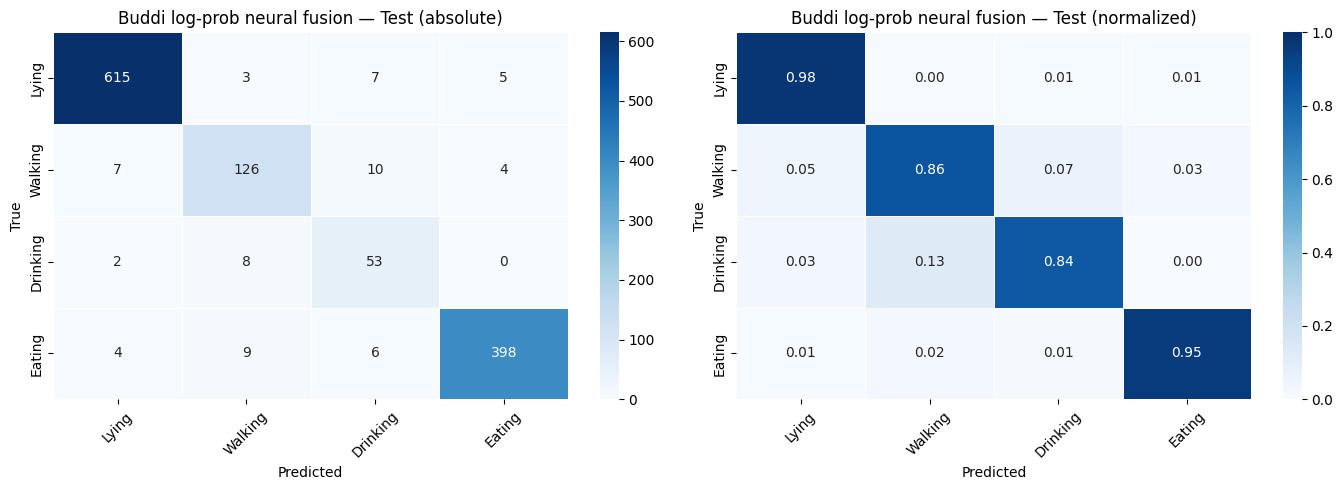


Saved files:
logits_buddi_softmax_neural_fusion_validacao_4classes.csv
logits_buddi_logprob_neural_fusion_validacao_4classes.csv
comparison_buddi_neural_fusion_models.csv
comparison_buddi_neural_fusion_per_class_f1.csv
confusion_matrix_buddi_logprob_neural_fusion.png
confusion_matrix_buddi_logprob_neural_fusion.pdf


In [18]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_sample_weight

# ============================================================
# BUDDI-INSPIRED NEURAL LATE FUSION
# Adapted from Buddi et al. (2023):
#   1) Softmax neural fusion: probabilities as input
#   2) Log-probability neural fusion: log(prob + eps) as input
#
# Your setting:
#   Sensor model = MDRF-CS
#   Audio model  = LMAAN
#   Task         = 4-class behavior classification per synchronized window
# ============================================================

classes_modelo = ["deitado", "andando", "bebendo", "comendo"]
class_names_en = ["Lying", "Walking", "Drinking", "Eating"]
labels_order = [0, 1, 2, 3]
prob_cols = [f"prob_{c}" for c in classes_modelo]

EPS = 1e-8

# ============================================================
# 1. LOAD TEST PROBABILITIES
# ============================================================

df_sen_test = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv"
)

df_aud_test = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv"
)

df_sen_test["window"] = df_sen_test["window"].astype(str)
df_aud_test["window"] = df_aud_test["window"].astype(str)

df_test = pd.merge(
    df_sen_test[["window", "label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}
    ),
    df_aud_test[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}
    ),
    on="window",
    how="inner"
)

print(f"Test set aligned: {len(df_test)} windows")

y_test = df_test["label_real"].values.astype(int)

P_sen_test = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud_test = df_test[[f"a_{c}" for c in prob_cols]].values

# ============================================================
# 2. LOAD OOF PROBABILITIES
# OOF is used to train the neural fusion model without leakage.
# ============================================================

df_sen_oof = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv"
)

df_aud_oof = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv"
)

def extract_id(name):
    """
    Extract numeric window id from audio OOF window name.
    Example: something-j123 -> 123
    """
    m = re.search(r"-j(\d+)", str(name))
    return int(m.group(1)) if m else None

df_aud_oof["window_id"] = df_aud_oof["window"].apply(extract_id)
df_sen_oof["window_id"] = df_sen_oof["window"].astype(int)

df_oof = pd.merge(
    df_sen_oof[["window_id", "label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}
    ),
    df_aud_oof[["window_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}
    ),
    on="window_id",
    how="inner"
)

print(f"OOF aligned: {len(df_oof)} windows")

y_oof = df_oof["label_real"].values.astype(int)

P_sen_oof = df_oof[[f"s_{c}" for c in prob_cols]].values
P_aud_oof = df_oof[[f"a_{c}" for c in prob_cols]].values

# ============================================================
# 3. BUILD BUDDI-STYLE INPUTS
# ============================================================

def build_softmax_fusion_features(P_sensor, P_audio):
    """
    Buddi-inspired softmax neural fusion:
    use output probabilities from both unimodal models.
    Total: 4 sensor probabilities + 4 audio probabilities = 8 features.
    """
    return np.hstack([P_sensor, P_audio])


def build_logprob_fusion_features(P_sensor, P_audio, eps=1e-8):
    """
    Buddi-inspired logit-style neural fusion:
    use log(probability + eps) as a practical proxy for logits.

    Note:
    If real pre-softmax logits from LMAAN are available, use them instead.
    For Random Forest, true logits are not naturally available.
    """
    return np.hstack([
        np.log(np.clip(P_sensor, eps, 1.0)),
        np.log(np.clip(P_audio, eps, 1.0))
    ])


X_soft_train = build_softmax_fusion_features(P_sen_oof, P_aud_oof)
X_soft_test  = build_softmax_fusion_features(P_sen_test, P_aud_test)

X_log_train = build_logprob_fusion_features(P_sen_oof, P_aud_oof)
X_log_test  = build_logprob_fusion_features(P_sen_test, P_aud_test)

print("\nFeature matrices:")
print("Softmax fusion train:", X_soft_train.shape)
print("Softmax fusion test :", X_soft_test.shape)
print("Log-prob fusion train:", X_log_train.shape)
print("Log-prob fusion test :", X_log_test.shape)

feature_names_soft = (
    [f"Psen_{c}" for c in classes_modelo] +
    [f"Paud_{c}" for c in classes_modelo]
)

feature_names_log = (
    [f"logPsen_{c}" for c in classes_modelo] +
    [f"logPaud_{c}" for c in classes_modelo]
)

# ============================================================
# 4. NEURAL FUSION MODEL
# ============================================================

def make_neural_fusion_model(random_state=42):
    """
    Small MLP used as neural late-fusion policy.
    This is the window-level adaptation of Buddi et al.'s neural policy.
    """
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(16,),
            activation="relu",
            solver="adam",
            alpha=1e-3,
            learning_rate_init=1e-3,
            max_iter=1000,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=30,
            random_state=random_state
        ))
    ])


sample_weight = compute_sample_weight(
    class_weight="balanced",
    y=y_oof
)

# ============================================================
# 5. TRAIN SOFTMAX NEURAL FUSION
# ============================================================

soft_model = make_neural_fusion_model(random_state=42)

try:
    soft_model.fit(
        X_soft_train,
        y_oof,
        mlp__sample_weight=sample_weight
    )
except TypeError:
    # Older scikit-learn versions may not support sample_weight in MLPClassifier
    print("Warning: MLPClassifier does not support sample_weight in this sklearn version.")
    soft_model.fit(X_soft_train, y_oof)

y_pred_soft = soft_model.predict(X_soft_test)
P_soft = soft_model.predict_proba(X_soft_test)

# ============================================================
# 6. TRAIN LOG-PROBABILITY NEURAL FUSION
# ============================================================

log_model = make_neural_fusion_model(random_state=42)

try:
    log_model.fit(
        X_log_train,
        y_oof,
        mlp__sample_weight=sample_weight
    )
except TypeError:
    print("Warning: MLPClassifier does not support sample_weight in this sklearn version.")
    log_model.fit(X_log_train, y_oof)

y_pred_log = log_model.predict(X_log_test)
P_log = log_model.predict_proba(X_log_test)

# ============================================================
# 7. BASELINES FOR COMPARISON
# ============================================================

y_pred_sen = P_sen_test.argmax(axis=1)
y_pred_aud = P_aud_test.argmax(axis=1)

P_avg = (P_sen_test + P_aud_test) / 2.0
y_pred_avg = P_avg.argmax(axis=1)

# ============================================================
# 8. GLOBAL COMPARISON
# ============================================================

models = [
    ("MDRF-CS sensor", y_pred_sen),
    ("LMAAN audio", y_pred_aud),
    ("Simple average fusion", y_pred_avg),
    ("Buddi softmax neural fusion", y_pred_soft),
    ("Buddi log-prob neural fusion", y_pred_log),
]

comparison = []

print("\n" + "=" * 70)
print("GLOBAL COMPARISON")
print("=" * 70)

for name, yp in models:
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, yp),
        "Macro-F1": f1_score(y_test, yp, average="macro"),
        "Weighted-F1": f1_score(y_test, yp, average="weighted")
    })

df_comparison = pd.DataFrame(comparison)
print(df_comparison.to_string(index=False))

# ============================================================
# 9. DETAILED REPORTS
# ============================================================

print("\n" + "=" * 70)
print("BUDDI SOFTMAX NEURAL FUSION — FULL REPORT")
print("=" * 70)

print(classification_report(
    y_test,
    y_pred_soft,
    labels=labels_order,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

print("\n" + "=" * 70)
print("BUDDI LOG-PROBABILITY NEURAL FUSION — FULL REPORT")
print("=" * 70)

print(classification_report(
    y_test,
    y_pred_log,
    labels=labels_order,
    target_names=classes_modelo,
    digits=4,
    zero_division=0
))

# ============================================================
# 10. PER-CLASS F1 COMPARISON
# ============================================================

per_class_rows = []

for name, yp in models:
    rep = classification_report(
        y_test,
        yp,
        labels=labels_order,
        target_names=classes_modelo,
        output_dict=True,
        zero_division=0
    )

    row = {"Model": name}
    for c in classes_modelo:
        row[f"F1_{c}"] = rep[c]["f1-score"]

    per_class_rows.append(row)

df_per_class = pd.DataFrame(per_class_rows)

print("\n" + "=" * 70)
print("PER-CLASS F1 COMPARISON")
print("=" * 70)
print(df_per_class.to_string(index=False))

# ============================================================
# 11. SELECT BEST BUDDI-INSPIRED MODEL
# ============================================================

macro_soft = f1_score(y_test, y_pred_soft, average="macro")
macro_log = f1_score(y_test, y_pred_log, average="macro")

if macro_log >= macro_soft:
    best_name = "Buddi log-prob neural fusion"
    best_pred = y_pred_log
    best_prob = P_log
    best_suffix = "buddi_logprob_neural_fusion"
else:
    best_name = "Buddi softmax neural fusion"
    best_pred = y_pred_soft
    best_prob = P_soft
    best_suffix = "buddi_softmax_neural_fusion"

print(f"\nBest Buddi-inspired model by Macro-F1: {best_name}")

# ============================================================
# 12. CONFUSION MATRIX — BEST BUDDI-INSPIRED MODEL
# ============================================================

cm = confusion_matrix(y_test, best_pred, labels=labels_order)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    linewidths=0.5,
    linecolor="white",
    ax=axes[0]
)

axes[0].set_title(f"{best_name} — Test (absolute)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names_en,
    yticklabels=class_names_en,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    ax=axes[1]
)

axes[1].set_title(f"{best_name} — Test (normalized)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    f"confusion_matrix_{best_suffix}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    f"confusion_matrix_{best_suffix}.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. SAVE OUTPUTS
# ============================================================

df_soft_out = pd.DataFrame(
    P_soft,
    columns=[f"prob_{c}" for c in classes_modelo]
)
df_soft_out["window"] = df_test["window"].values
df_soft_out["label_real"] = y_test
df_soft_out["y_pred"] = y_pred_soft

df_soft_out.to_csv(
    "logits_buddi_softmax_neural_fusion_validacao_4classes.csv",
    index=False
)

df_log_out = pd.DataFrame(
    P_log,
    columns=[f"prob_{c}" for c in classes_modelo]
)
df_log_out["window"] = df_test["window"].values
df_log_out["label_real"] = y_test
df_log_out["y_pred"] = y_pred_log

df_log_out.to_csv(
    "logits_buddi_logprob_neural_fusion_validacao_4classes.csv",
    index=False
)

df_comparison.to_csv(
    "comparison_buddi_neural_fusion_models.csv",
    index=False
)

df_per_class.to_csv(
    "comparison_buddi_neural_fusion_per_class_f1.csv",
    index=False
)

print("\nSaved files:")
print("logits_buddi_softmax_neural_fusion_validacao_4classes.csv")
print("logits_buddi_logprob_neural_fusion_validacao_4classes.csv")
print("comparison_buddi_neural_fusion_models.csv")
print("comparison_buddi_neural_fusion_per_class_f1.csv")
print(f"confusion_matrix_{best_suffix}.png")
print(f"confusion_matrix_{best_suffix}.pdf")

## Bootstrap Boxplots for Final Fusion Gains

This cell generates final bootstrap boxplots comparing the selected weighted fusion strategy against the MDRF-CS accelerometer model and the LMAAN audio model. The figures are formatted for manuscript use and focus on visualizing the magnitude and stability of performance gains without embedding p-values inside the plots.


Aligned test set: 1257 windows
Aligned OOF set: 4003 windows

Static weights based on OOF F1:
deitado  | accelerometer weight = 0.5103 | audio weight = 0.4897
andando  | accelerometer weight = 0.5611 | audio weight = 0.4389
bebendo  | accelerometer weight = 0.5323 | audio weight = 0.4677
comendo  | accelerometer weight = 0.5077 | audio weight = 0.4923


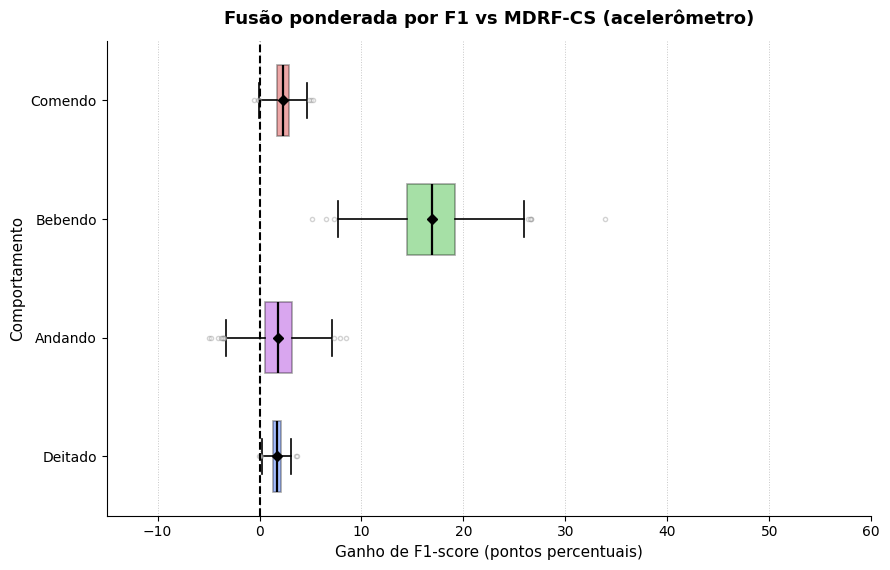

Figure saved em PNG: boxplot_f1w_vs_mdrf_pt.png
Figure saved em PDF: boxplot_f1w_vs_mdrf_pt.pdf


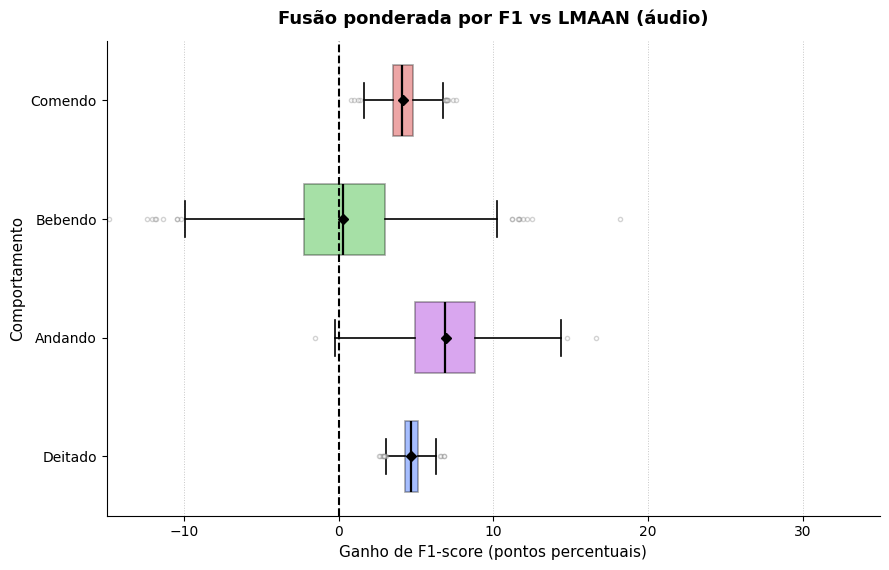

Figure saved em PNG: boxplot_f1w_vs_lmaan_pt.png
Figure saved em PDF: boxplot_f1w_vs_lmaan_pt.pdf


In [2]:
# ============================================================
# COMPLETE CELL
# Boxplots with manuscript-style labels:
# F1-weighted fusion vs MDRF-CS and vs LMAAN
# Without p-value inside the plot
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score
from sklearn.utils import resample

# ============================================================
# 1. General settings
# ============================================================

classes_modelo = ["deitado", "andando", "bebendo", "comendo"]
class_names_pt = ["Lying", "Walking", "Drinking", "Eating"]

labels_order = [0, 1, 2, 3]
n_classes = len(classes_modelo)

N_BOOTSTRAP = 1000
RANDOM_STATE = 42
EPS = 1e-8

prob_cols = [f"prob_{c}" for c in classes_modelo]

# ============================================================
# 2. Load test-set logits
# ============================================================

df_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_validacao_4classes_sem_correndo.csv"
)

df_aud = pd.read_csv(
    "logits_audio_lmaan_validacao_4classes_cshift4p.csv"
)

df_sen["window"] = df_sen["window"].astype(str)
df_aud["window"] = df_aud["window"].astype(str)

df_test = pd.merge(
    df_sen[["window", "label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}
    ),
    df_aud[["window"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}
    ),
    on="window",
    how="inner"
)

print(f"Aligned test set: {len(df_test)} windows")

y_test = df_test["label_real"].values.astype(int)

P_sen = df_test[[f"s_{c}" for c in prob_cols]].values
P_aud = df_test[[f"a_{c}" for c in prob_cols]].values

y_pred_sen = P_sen.argmax(axis=1)
y_pred_aud = P_aud.argmax(axis=1)

# ============================================================
# 3. Load OOF logits to compute F1-based weights
# ============================================================

df_oof_sen = pd.read_csv(
    "logits_sensor_rf_cshift4p_combfeat_oof_treino_4classes_sem_correndo.csv"
)

df_oof_aud = pd.read_csv(
    "logits_audio_oof_treino_4classes_cshift4p.csv"
)

def extrair_id(nome):
    m = re.search(r"-j(\d+)", str(nome))
    return int(m.group(1)) if m else None

df_oof_aud["window_id"] = df_oof_aud["window"].apply(extrair_id)
df_oof_sen["window_id"] = df_oof_sen["window"].astype(int)

df_oof = pd.merge(
    df_oof_sen[["window_id", "label_real"] + prob_cols].rename(
        columns={c: f"s_{c}" for c in prob_cols}
    ),
    df_oof_aud[["window_id"] + prob_cols].rename(
        columns={c: f"a_{c}" for c in prob_cols}
    ),
    on="window_id",
    how="inner"
)

print(f"Aligned OOF set: {len(df_oof)} windows")

y_oof = df_oof["label_real"].values.astype(int)

P_oof_sen = df_oof[[f"s_{c}" for c in prob_cols]].values
P_oof_aud = df_oof[[f"a_{c}" for c in prob_cols]].values

yp_oof_sen = P_oof_sen.argmax(axis=1)
yp_oof_aud = P_oof_aud.argmax(axis=1)

# OOF class-wise F1
f1_oof_sen = np.array([
    f1_score(
        y_oof,
        yp_oof_sen,
        labels=[c],
        average="macro",
        zero_division=0
    )
    for c in range(n_classes)
])

f1_oof_aud = np.array([
    f1_score(
        y_oof,
        yp_oof_aud,
        labels=[c],
        average="macro",
        zero_division=0
    )
    for c in range(n_classes)
])

# Pesos per class
W_oof_sen = f1_oof_sen / (f1_oof_sen + f1_oof_aud + EPS)
W_oof_aud = f1_oof_aud / (f1_oof_sen + f1_oof_aud + EPS)

print("\nStatic weights based on OOF F1:")
for c, nome in enumerate(classes_modelo):
    print(
        f"{nome:<8} | accelerometer weight = {W_oof_sen[c]:.4f} | "
        f"audio weight = {W_oof_aud[c]:.4f}"
    )

# ============================================================
# 4. F1-weighted fusion
# ============================================================

P_f1w = np.zeros_like(P_sen)

for c in range(n_classes):
    P_f1w[:, c] = (
        W_oof_sen[c] * P_sen[:, c] +
        W_oof_aud[c] * P_aud[:, c]
    )

y_pred_f1w = P_f1w.argmax(axis=1)

# ============================================================
# 5. Bootstrap dos ganhos per class
# ============================================================

def bootstrap_gains_classes(
    y_true,
    y_pred_a,
    y_pred_b,
    n_iter=N_BOOTSTRAP,
    random_state=RANDOM_STATE
):
    """
    Computes the F1-score gain per class:
    gain = F1(model A) - F1(model B)

    Returns dictionary:
    {classe: list of gains in percentage points}
    """

    rng = np.random.RandomState(random_state)
    idx_all = np.arange(len(y_true))

    ganhos_por_classe = {i: [] for i in range(n_classes)}

    for _ in range(n_iter):
        idx = resample(
            idx_all,
            replace=True,
            n_samples=len(idx_all),
            stratify=y_true,
            random_state=rng.randint(0, 2**31)
        )

        yb = y_true[idx]
        ya = y_pred_a[idx]
        yb2 = y_pred_b[idx]

        f1_a = f1_score(
            yb,
            ya,
            average=None,
            labels=labels_order,
            zero_division=0
        )

        f1_b = f1_score(
            yb,
            yb2,
            average=None,
            labels=labels_order,
            zero_division=0
        )

        for i in range(n_classes):
            ganhos_por_classe[i].append((f1_a[i] - f1_b[i]) * 100)

    return ganhos_por_classe

# F1-weighted fusion gains relative to MDRF-CS
gc_mdrf = bootstrap_gains_classes(
    y_true=y_test,
    y_pred_a=y_pred_f1w,
    y_pred_b=y_pred_sen
)

# F1-weighted fusion gains relative to LMAAN
gc_lmaan = bootstrap_gains_classes(
    y_true=y_test,
    y_pred_a=y_pred_f1w,
    y_pred_b=y_pred_aud
)

# ============================================================
# 6. Funcao para gerar boxplots em portugues
# ============================================================

COLORS = ['#0047FF', '#9400D3', '#00A800', '#CC0000']

def plot_boxplot_ganho_f1_pt(
    gains_class,
    title,
    save_path,
    xlim=(-20, 40)
):
    data_plot = [
        np.array(gains_class[i])
        for i in range(n_classes)
    ]

    fig, ax = plt.subplots(figsize=(9, 5.8))

    bp = ax.boxplot(
        data_plot,
        vert=False,
        patch_artist=True,
        tick_labels=class_names_pt,
        showmeans=True,
        meanline=False,
        widths=0.6,
        flierprops=dict(
            marker='o',
            markersize=3,
            alpha=0.35,
            markerfacecolor='white',
            markeredgecolor='gray'
        ),
        medianprops=dict(
            color='black',
            linewidth=1.6
        ),
        meanprops=dict(
            marker='D',
            markerfacecolor='black',
            markeredgecolor='black',
            markersize=5
        ),
        whiskerprops=dict(
            linewidth=1.2,
            color='black'
        ),
        capprops=dict(
            linewidth=1.2,
            color='black'
        ),
        boxprops=dict(
            linewidth=1.2,
            color='black'
        )
    )

    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.35)
        patch.set_edgecolor('black')
        patch.set_linewidth(1.2)

    # Linha vertical de referencia: ganho zero
    ax.axvline(
        0,
        color='black',
        linestyle='--',
        linewidth=1.5
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight='bold',
        pad=12
    )

    ax.set_xlabel(
        'Ganho de F1-score (pontos percentuais)',
        fontsize=11
    )

    ax.set_ylabel(
        'Comportamento',
        fontsize=11
    )

    ax.tick_params(axis='both', labelsize=10)

    ax.set_xlim(xlim)

    ax.grid(
        axis='x',
        linestyle=':',
        linewidth=0.7,
        alpha=0.7
    )

    ax.grid(axis='y', visible=False)

    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()

    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.replace(".png", ".pdf"), bbox_inches='tight')

    plt.show()

    print(f"Figure saved em PNG: {save_path}")
    print(f"Figure saved em PDF: {save_path.replace('.png', '.pdf')}")

# ============================================================
# 7. Gerar os dois graficos
# ============================================================

plot_boxplot_ganho_f1_pt(
    gains_class=gc_mdrf,
    title='F1-weighted fusion vs MDRF-CS (acelerometro)',
    save_path='boxplot_f1w_vs_mdrf_pt.png',
    xlim=(-15, 60)
)

plot_boxplot_ganho_f1_pt(
    gains_class=gc_lmaan,
    title='F1-weighted fusion vs LMAAN (audio)',
    save_path='boxplot_f1w_vs_lmaan_pt.png',
    xlim=(-15, 35)
)